In [ ]:
#1. GPU 4
import torch

print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))

GPU tersedia: True
Nama GPU: Tesla T4


In [ ]:
#2. Sambungan Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive

drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
!nvidia-smi

Fri Oct 16 03:18:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   32C    P0             49W /  600W |       3MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:

from pathlib import Path

base = Path("/content/drive/MyDrive")

print("MyDrive ditemukan:", base.exists())

# Cari item TCGA-LUAD-WSI
for p in base.iterdir():
    if "TCGA-LUAD-WSI" in p.name:
        print("Nama:", p.name)
        print("Lokasi:", p)
        print("Apakah folder:", p.is_dir())

        if p.is_dir():
            for item in p.iterdir():
                print(
                    " -", item.name,
                    "| Folder:", item.is_dir()
                )


# hasil fitur ResNet-50 untuk 200 slide yang diproses dari dataset patch Macenko.

In [ ]:
from pathlib import Path

out = Path("/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50")

print("Folder ada:", out.exists())

for p in out.rglob("*"):
    if p.is_file():
        print(p, f"{p.stat().st_size / 1e6:.2f} MB")

Folder ada: True
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (121).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (120).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (119).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (118).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (117).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (116).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (115).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (114).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (113).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (112).csv 0.00 MB
/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (111).csv 0.00 MB
/con

In [ ]:
import numpy as np
from pathlib import Path

out = Path("/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50")

# Cari file fitur hasil ekstraksi pertama
files = list((out / "test/Mutant").glob("*.npz"))

if not files:
    print("GAGAL: File .npz tidak ditemukan.")
else:
    npz_path = files[0]
    print("File:", npz_path.name)
    print(f"Ukuran: {npz_path.stat().st_size / (1024**2):.2f} MB")

    with np.load(npz_path, allow_pickle=False) as data:
        print("Bentuk fitur:", data["features"].shape)
        print("Tipe data:", data["features"].dtype)
        print("Jumlah patch:", len(data["patch"]))
        print("Patient ID:", data["patient_id"].item())
        print("Label:", data["label"].item())
        print("Split:", data["split"].item())

    print("\nPengecekan selesai.")


File: TCGA-38-4627-01Z-00-DX1.fe406eb9-b38b-410d-aa1a-84ab8ac091c7.npz
Ukuran: 377.33 MB
Bentuk fitur: (46417, 2048)
Tipe data: float32
Jumlah patch: 46417
Patient ID: TCGA-38-4627
Label: Mutant
Split: test

Pengecekan selesai.


In [ ]:
#cek hasil percobaan dengan 1 data

from pathlib import Path

root = Path("/content/drive/MyDrive/TCGA-LUAD-WSI/Patches_Macenko")
out = Path("/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50")
mdir = out / "manifests"

zips = sorted(root.glob("*/*/*.zip"))

sudah_lengkap = []
csv_tanpa_npz = []
npz_tanpa_csv = []
belum_diproses = []

for zp in zips:
    stem = zp.stem

    # Output berdasarkan struktur folder input
    parts = zp.parts
    split, label = parts[-3], parts[-2]

    csv_file = mdir / f"{stem}.csv"
    npz_file = out / split / label / f"{stem}.npz"

    if csv_file.exists() and npz_file.exists():
        sudah_lengkap.append(stem)
    elif csv_file.exists() and not npz_file.exists():
        csv_tanpa_npz.append(stem)
    elif npz_file.exists() and not csv_file.exists():
        npz_tanpa_csv.append(stem)
    else:
        belum_diproses.append(stem)

print("Total ZIP:", len(zips))
print("CSV dan NPZ sama-sama ada:", len(sudah_lengkap))
print("CSV ada, NPZ tidak ada:", len(csv_tanpa_npz))
print("NPZ ada, CSV tidak ada:", len(npz_tanpa_csv))
print("Belum ada output:", len(belum_diproses))

if csv_tanpa_npz:
    print("\nContoh CSV tanpa NPZ:", csv_tanpa_npz[:3])
if npz_tanpa_csv:
    print("\nContoh NPZ tanpa CSV:", npz_tanpa_csv[:3])


Total ZIP: 200
CSV dan NPZ sama-sama ada: 200
CSV ada, NPZ tidak ada: 0
NPZ ada, CSV tidak ada: 0
Belum ada output: 0


In [ ]:
!python /content/feature_extraction_luad.py \
  --input "/content/drive/MyDrive/TCGA-LUAD-WSI/Patches_Macenko" \
  --output "/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50" \
  --stage-dir /content/stage \
  --batch-size 32 \
  --workers 2 \
  --dtype float32

Zip Macenko ditemukan: 200 di /content/drive/MyDrive/TCGA-LUAD-WSI/Patches_Macenko
  test/Mutant: 10 slide
  test/Wildtype: 30 slide
  train/Mutant: 40 slide
  train/Wildtype: 120 slide
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100% 97.8M/97.8M [00:00<00:00, 194MB/s]
Model: ResNet-50 ResNet50_Weights.IMAGENET1K_V1 | beku | eval | device cuda | AMP True
FEATURE EXTRACTION | batch 32 | worker 2 | simpan float32 | staging ya
Sudah selesai: 2 | akan diproses: 198 | ruang kosong output 197 GB
[1/198] OK TCGA-38-6178-01Z-00-DX1.5932337D-BA2B-455D-9E34-22961EFA2170 | TCGA-38-6178 | test/Mutant | 57611 patch (491 MB) | 47.7s
[2/198] OK TCGA-50-5066-01Z-00-DX1.e161df31-84a4-40a4-a6a2-748b60820f77 | TCGA-50-5066 | test/Mutant | 76423 patch (651 MB) | 60.4s
[3/198] OK TCGA-55-6980-01Z-00-DX1.2f1d1858-42b9-4e3b-966d-2f3f429570a6 | TCGA-55-6980 | test/Mutant | 50756 patch (432 MB) | 34.9s
[4/198] OK TCGA-55-6

In [ ]:
from pathlib import Path

out = Path(
    "/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50"
)

print("Folder output ditemukan:", out.exists())

if out.exists():
    npz_files = list(out.glob("*/*/*.npz"))
    csv_files = list((out / "manifests").glob("*.csv"))

    print("Jumlah file NPZ:", len(npz_files))
    print("Jumlah manifest CSV:", len(csv_files))

    print("\nContoh 5 file NPZ:")
    for f in npz_files[:5]:
        print(f"{f.relative_to(out)} — {f.stat().st_size / 1024**2:.2f} MB")

Folder output ditemukan: True
Jumlah file NPZ: 200
Jumlah manifest CSV: 200

Contoh 5 file NPZ:
test/Mutant/TCGA-38-4627-01Z-00-DX1.fe406eb9-b38b-410d-aa1a-84ab8ac091c7.npz — 377.33 MB
test/Mutant/TCGA-38-4628-01Z-00-DX1.eee4f100-142f-4d9c-8e38-b16aab123413.npz — 115.55 MB
test/Mutant/TCGA-38-6178-01Z-00-DX1.5932337D-BA2B-455D-9E34-22961EFA2170.npz — 468.33 MB
test/Mutant/TCGA-50-5066-01Z-00-DX1.e161df31-84a4-40a4-a6a2-748b60820f77.npz — 621.25 MB
test/Mutant/TCGA-55-6980-01Z-00-DX1.2f1d1858-42b9-4e3b-966d-2f3f429570a6.npz — 412.41 MB


In [ ]:
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/TCGA-LUAD-WSI")
patch_dir = base / "Patches_Macenko"
out_dir = base / "Features_ResNet50"
manifest_dir = out_dir / "manifests"

# Daftar 200 ZIP sumber
zip_files = list(patch_dir.glob("*/*/*.zip"))

# Daftar hasil fitur berdasarkan split dan label
npz_files = list(out_dir.glob("*/*/*.npz"))
csv_files = list(manifest_dir.glob("*.csv"))

npz_map = {f.stem: f for f in npz_files}
csv_map = {f.stem: f for f in csv_files}

rows = []

for z in zip_files:
    split = z.parent.parent.name
    label = z.parent.name
    stem = z.stem

    npz = out_dir / split / label / f"{stem}.npz"
    csv = manifest_dir / f"{stem}.csv"

    rows.append({
        "zip": z.name,
        "split": split,
        "label": label,
        "npz_ada": npz.is_file(),
        "csv_ada": csv.is_file(),
        "npz_MB": round(npz.stat().st_size / 1024**2, 2)
                   if npz.is_file() else 0,
        "status": (
            "LENGKAP" if npz.is_file() and csv.is_file()
            else "BELUM LENGKAP"
        )
    })

df = pd.DataFrame(rows)

print("Jumlah ZIP:", len(zip_files))
print("Jumlah NPZ:", len(npz_files))
print("Jumlah manifest CSV:", len(csv_files))
print("ZIP dengan pasangan NPZ + CSV:",
      (df["status"] == "LENGKAP").sum())
print("ZIP belum lengkap:",
      (df["status"] != "LENGKAP").sum())

print("\nZIP yang belum lengkap:")
display(df[df["status"] != "LENGKAP"][
    ["zip", "split", "label", "npz_ada", "csv_ada"]
])

# Simpan laporan audit, tanpa mengubah file hasil fitur
report = out_dir / "audit_kelangkapan.csv"
df.to_csv(report, index=False)
print("\nLaporan audit:", report)

Jumlah ZIP: 200
Jumlah NPZ: 200
Jumlah manifest CSV: 200
ZIP dengan pasangan NPZ + CSV: 200
ZIP belum lengkap: 0

ZIP yang belum lengkap:


,zip,split,label,npz_ada,csv_ada



Laporan audit: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/audit_kelangkapan.csv


# ekstraksi fitur

In [ ]:
"""Tahap 7: Ekstraksi fitur ResNet-50 (pretrained ImageNet, bobot beku) dari patch hasil Macenko.
Versi Google Drive / Colab (juga jalan di RunPod atau server biasa: cukup beri path folder).

Input : folder hasil color normalization (Macenko) dengan susunan  <split>/<label>/<slide>.zip
        contoh dari Drive:  test/Mutant/TCGA-38-4628-01Z-00-DX1.<uuid>.zip
        Isi tiap zip: patch PNG (+ manifest.csv bila ada). Nama folder split & label dibaca dari path,
        jadi nama folder apa pun (train/test, Mutant/WildType, dst.) tidak perlu diubah di kode.
Alur  : patch 224x224x3 -> ResNet-50 sampai conv5_x (feature map 7x7x2048, SEBELUM avgpool)
        -> Global Average Pooling (rata-rata 49 posisi per kanal) -> embedding 2048 dimensi.
        (avgpool dan fc 1000 kelas bawaan TIDAK dipakai; bobot ImageNet dibekukan, mode eval.)
Output: <output>/<split>/<label>/<slide>.npz  berisi:
            features (N, 2048) float32 (atau float16 dgn --dtype float16),
            patch, x, y  (N,)  -> urutan baris sama dengan features,
            patient_id, label, split, slide  (skalar string)
        <output>/manifests/<slide>.csv   metadata per patch (urutan baris = features); ditulis TERAKHIR
                                         = penanda slide selesai (resume otomatis)
        <output>/feature_summary.csv     ringkasan per slide

Contoh (Colab):
    from google.colab import drive; drive.mount('/content/drive')
    !python feature_extraction_luad.py --input "/content/drive/MyDrive/<folder Macenko>" \\
        --output "/content/drive/MyDrive/Features" --stage-dir /content/stage --benchmark
    (hapus --benchmark untuk menjalankan penuh; --limit 1 untuk mencoba 1 slide dulu)
"""
import argparse
import gc
import os
import re
import shutil
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

cv2.setNumThreads(1)

# ---------------- PARAMETER TETAP ----------------
PATCH_SIZE = 224
FEAT_DIM = 2048
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_EXT = (".png", ".jpg", ".jpeg")
XY_RE = re.compile(r"_x(\d+)_y(\d+)")
SKIP_DIRS = {"reference", "manifests", "validation", "qc", "__MACOSX"}   # subfolder bukan split

# diisi dari argumen di main()
CFG = {"batch_size": 256, "workers": 2, "amp": True, "dtype": "float32", "min_free_gb": 30.0}


# ---------------- MODEL ----------------
class ResNet50Embedder(nn.Module):
    """ResNet-50 sampai conv5_x -> feature map (B, 2048, 7, 7) -> GAP -> (B, 2048)."""

    def __init__(self, backbone):
        super().__init__()
        self.body = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
                                  backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4)

    def forward(self, x, return_map=False):
        fmap = self.body(x)                                   # (B, 2048, 7, 7)
        emb = fmap.float().mean(dim=(2, 3))                   # Global Average Pooling (float32)
        return (emb, fmap) if return_map else emb


def build_backbone():
    import torchvision
    try:
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V1   # bobot ResNet-50 ImageNet asli (He et al., 2015)
        return torchvision.models.resnet50(weights=w), "ResNet50_Weights.IMAGENET1K_V1"
    except AttributeError:                                       # torchvision lama
        return torchvision.models.resnet50(pretrained=True), "pretrained=True (torchvision lama)"


def build_model(device):
    backbone, wname = build_backbone()
    model = ResNet50Embedder(backbone).to(device).eval()
    for p in model.parameters():
        p.requires_grad_(False)                                  # bobot dibekukan
    if device.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    return model, wname


# ---------------- DATA ----------------
class ZipPatches(Dataset):
    """Membaca patch dari satu zip. Handle zip dibuka malas per worker."""

    def __init__(self, zip_path, members):
        self.zip_path, self.members = str(zip_path), list(members)
        self.zf = None

    def __len__(self):
        return len(self.members)

    def __getitem__(self, i):
        if self.zf is None:
            self.zf = zipfile.ZipFile(self.zip_path)
        data = self.zf.read(self.members[i])
        bgr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
        if bgr is None:
            raise IOError(f"gagal decode {self.members[i]}")
        if bgr.shape[:2] != (PATCH_SIZE, PATCH_SIZE):
            raise ValueError(f"ukuran patch {self.members[i]} = {bgr.shape[:2]}, harusnya {(PATCH_SIZE, PATCH_SIZE)}")
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        return torch.from_numpy(np.ascontiguousarray(rgb.transpose(2, 0, 1)))   # uint8, CHW


def _worker_init(_):
    cv2.setNumThreads(1)


def make_loader(zip_path, members, device):
    w = CFG["workers"]
    return DataLoader(ZipPatches(zip_path, members), batch_size=CFG["batch_size"], shuffle=False,
                      num_workers=w, pin_memory=(device.type == "cuda"), worker_init_fn=_worker_init,
                      persistent_workers=False, prefetch_factor=4 if w > 0 else None)


# ---------------- DAFTAR ZIP ----------------
def list_zips(root, splits=None):
    """Cari semua zip di bawah root. split/label dibaca dari nama folder: <split>/<label>/<slide>.zip."""
    out = []
    for z in sorted(root.rglob("*.zip")):
        rel = z.relative_to(root).parts
        if any(p in SKIP_DIRS for p in rel[:-1]):
            continue
        if len(rel) >= 3:
            split, label = rel[-3], rel[-2]
        elif len(rel) == 2:
            split, label = "all", rel[0]
        else:
            split, label = "all", "unknown"
        if splits and split not in splits:
            continue
        out.append((z, split, label))
    return out


# ---------------- ISI ZIP ----------------
def index_zip(zpath, stem):
    """Kembalikan (tabel patch, daftar nama anggota zip searah tabel, info). Tahan terhadap:
    prefix folder di dalam zip yang berbeda, manifest.csv yang tidak ada, dan berkas gambar tambahan."""
    imgs, manifest_member = {}, None
    with zipfile.ZipFile(zpath) as zf:
        for info in zf.infolist():
            if info.is_dir() or "__MACOSX" in info.filename:
                continue
            base = Path(info.filename).name
            if base.lower() == "manifest.csv":
                manifest_member = info.filename
            elif base.lower().endswith(IMG_EXT):
                if base in imgs:
                    raise ValueError(f"nama patch ganda di dalam zip: {base}")
                imgs[base] = info.filename
        man = pd.read_csv(zf.open(manifest_member)) if manifest_member else None

    info = {"manifest": man is not None, "n_extra": 0}
    if man is not None and "patch" in man.columns:
        man["patch"] = man["patch"].astype(str)
        if man["patch"].duplicated().any():
            raise ValueError("ada nama patch ganda di manifest")
        missing = [p for p in man["patch"] if p not in imgs]
        if missing:
            raise ValueError(f"{len(missing)} patch ada di manifest tapi tidak ada di zip (contoh: {missing[0]})")
        info["n_extra"] = len(imgs) - len(man)
    else:                                                        # tanpa manifest: pakai semua gambar di zip
        names = sorted(imgs)
        man = pd.DataFrame({"patch": names})
        info["manifest"] = False
    if "x" not in man.columns or "y" not in man.columns:         # koordinat dari nama berkas (..._x123_y456.png)
        xy = man["patch"].map(lambda n: XY_RE.search(n).groups() if XY_RE.search(n) else (-1, -1))
        man["x"] = [int(a) for a, _ in xy]
        man["y"] = [int(b) for _, b in xy]
    members = [imgs[p] for p in man["patch"]]
    return man, members, info


def resolve_patient_id(man, stem):
    pid = man["patient_id"].dropna().astype(str).unique() if "patient_id" in man.columns else []
    pid = [p for p in pid if p.strip() and p.lower() != "nan"]
    if len(pid) == 1:
        return pid[0], False
    if len(pid) > 1:
        raise ValueError(f"satu slide punya lebih dari satu patient_id: {pid[:3]}")
    return stem[:12], True        # fallback: barcode TCGA 12 karakter pertama (TCGA-XX-XXXX)


# ---------------- EKSTRAKSI ----------------
@torch.inference_mode()
def embed_members(model, device, zpath, members, mean, std, on_first_batch=None):
    n = len(members)
    dtype = np.float16 if CFG["dtype"] == "float16" else np.float32
    feats = np.empty((n, FEAT_DIM), dtype=dtype)
    pos, first = 0, True
    use_amp = CFG["amp"] and device.type == "cuda"
    for xb in make_loader(zpath, members, device):
        xb = xb.to(device, non_blocking=True).float().div_(255.0)
        xb = (xb - mean) / std
        if device.type == "cuda":
            xb = xb.contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            emb, fmap = model(xb, return_map=True)
        if first:
            assert tuple(fmap.shape[1:]) == (FEAT_DIM, 7, 7), f"feature map {tuple(fmap.shape)} != (B, 2048, 7, 7)"
            assert tuple(emb.shape[1:]) == (FEAT_DIM,)
            if on_first_batch:
                on_first_batch(fmap, emb)
            first = False
        feats[pos:pos + len(emb)] = emb.cpu().numpy().astype(dtype, copy=False)
        pos += len(emb)
    if pos != n:
        raise RuntimeError(f"jumlah embedding {pos} != jumlah patch {n}")
    if not np.all(np.isfinite(feats)):
        raise ValueError("embedding mengandung NaN/Inf")
    return feats


def extract_slide(zpath, split, label, out_dir, model, device, mean, std, local_zip=None):
    """zpath = zip asli (untuk nama slide); local_zip = salinan lokal yang dibaca (bila staging dipakai)."""
    stem, t0 = zpath.name[:-4], time.time()
    src = local_zip or zpath
    dest_dir = out_dir / split / label
    dest, tmp = dest_dir / f"{stem}.npz", dest_dir / f"{stem}.npz.tmp"
    mdir = out_dir / "manifests"
    try:
        mdir.mkdir(parents=True, exist_ok=True)
        if shutil.disk_usage(out_dir).free < CFG["min_free_gb"] * 1e9:
            return {"slide": stem, "status": "DISKFULL"}
        dest_dir.mkdir(parents=True, exist_ok=True)

        man, members, zinfo = index_zip(src, stem)
        if len(man) == 0:
            raise ValueError("zip tidak berisi patch")
        patient_id, pid_fallback = resolve_patient_id(man, stem)

        feats = embed_members(model, device, src, members, mean, std)

        names = man["patch"].tolist()
        x, y = man["x"].to_numpy(np.int64), man["y"].to_numpy(np.int64)
        with open(tmp, "wb") as f:
            np.savez(f, features=feats, patch=np.array(names), x=x, y=y,
                     patient_id=np.array(patient_id), label=np.array(label),
                     split=np.array(split), slide=np.array(stem))
        size = tmp.stat().st_size
        os.replace(tmp, dest)

        meta = man.copy()
        for col in ("label", "split"):                           # simpan nilai asli manifest bila ada
            if col in meta.columns:
                meta[f"{col}_manifest"] = meta[col]
        meta["slide"], meta["patient_id"], meta["label"], meta["split"] = stem, patient_id, label, split
        meta.insert(0, "feat_idx", np.arange(len(meta)))
        mtmp = mdir / f"{stem}.csv.tmp"
        meta.to_csv(mtmp, index=False)
        os.replace(mtmp, mdir / f"{stem}.csv")                   # penanda selesai (terakhir)

        return {"slide": stem, "status": "OK", "patient_id": patient_id, "label": label, "split": split,
                "n_patches": len(names), "pid_fallback": pid_fallback, "has_manifest": zinfo["manifest"],
                "n_extra_images": zinfo["n_extra"], "dtype": CFG["dtype"],
                "size_mb": round(size / 1e6, 1), "time_sec": round(time.time() - t0, 1)}
    except Exception as e:
        Path(tmp).unlink(missing_ok=True)
        return {"slide": stem, "status": "GAGAL", "error": repr(e)[:300]}
    finally:
        gc.collect()


def save_summary(out_dir, row):
    path = out_dir / "feature_summary.csv"
    new = pd.DataFrame([row])
    if path.exists():
        try:
            new = pd.concat([pd.read_csv(path), new], ignore_index=True)
        except Exception:
            pass
    new = new.drop_duplicates("slide", keep="last")
    tmp = path.with_suffix(".csv.tmp")
    new.to_csv(tmp, index=False)
    os.replace(tmp, path)


# ---------------- STAGING (salin zip dari Drive ke disk lokal) ----------------
def stage_copy(zpath, stage_dir):
    """Salin satu zip secara berurutan ke disk lokal (jauh lebih cepat daripada membaca acak lewat Drive)."""
    dst = stage_dir / zpath.name
    part = stage_dir / (zpath.name + ".part")
    shutil.copyfile(zpath, part)
    os.replace(part, dst)
    return dst


# ---------------- BENCHMARK ----------------
def benchmark(zips, model, device, mean, std, stage_dir, n=2048):
    zpath, split, label = zips[0]
    src = stage_copy(zpath, stage_dir) if stage_dir else zpath
    try:
        man, members, zinfo = index_zip(src, zpath.name[:-4])
        members = members[:n]
        print(f"Benchmark pada {zpath.name[:-4]} ({split}/{label}): {len(members)} patch (tidak menyimpan apa pun)")
        print(f"  manifest di dalam zip: {'ada' if zinfo['manifest'] else 'TIDAK ADA (metadata dari nama berkas)'}")

        def show(fmap, emb):
            print(f"  feature map sebelum GAP : {tuple(fmap.shape)}  (harus (B, 2048, 7, 7))")
            print(f"  embedding setelah GAP   : {tuple(emb.shape)}  (harus (B, 2048))")
            ref = fmap.float().mean(dim=(2, 3))
            print(f"  cek GAP manual          : maks selisih {float((ref - emb).abs().max()):.2e}")

        t0 = time.time()
        feats = embed_members(model, device, src, members, mean, std, on_first_batch=show)
        dt = time.time() - t0
        print(f"  kecepatan : {len(members) / dt:.0f} patch/detik (termasuk warm-up) -> "
              f"57.000 patch/pasien ~ {57000 / (len(members) / dt) / 60:.1f} menit/pasien")
        print(f"  embedding : mean {feats.mean():.4f} | std {feats.std():.4f} | min {feats.min():.4f} | max {feats.max():.4f}")
        print(f"  ukuran fitur 1 pasien (57.000 patch, {CFG['dtype']}) ~ "
              f"{57000 * FEAT_DIM * feats.dtype.itemsize / 1e6:.0f} MB")
    finally:
        if stage_dir and src != zpath:
            Path(src).unlink(missing_ok=True)


# ---------------- MAIN ----------------
def main(argv=None):
    ap = argparse.ArgumentParser(description="Ekstraksi fitur ResNet-50 dari patch Macenko (zip).")
    ap.add_argument("--input", default=os.environ.get("MACENKO_DIR"),
                    help="folder berisi <split>/<label>/<slide>.zip (hasil Macenko), mis. path di Drive")
    ap.add_argument("--output", default=os.environ.get("FEATURES_DIR", "Features"), help="folder keluaran fitur")
    ap.add_argument("--splits", nargs="*", default=None, help="proses split tertentu saja, mis. --splits test")
    ap.add_argument("--stage-dir", default=None,
                    help="folder lokal sementara; zip disalin ke sini sebelum dibaca (disarankan jika input di Drive)")
    ap.add_argument("--dtype", choices=["float32", "float16"], default="float32")
    ap.add_argument("--batch-size", type=int, default=256)
    ap.add_argument("--workers", type=int, default=min(os.cpu_count() or 2, 8))
    ap.add_argument("--no-amp", action="store_true", help="matikan fp16 autocast di GPU")
    ap.add_argument("--min-free-gb", type=float, default=5.0, help="berhenti rapi jika ruang output di bawah ini")
    ap.add_argument("--limit", type=int, default=None, help="hanya proses N slide pertama yang belum selesai")
    ap.add_argument("--benchmark", action="store_true", help="uji kecepatan & shape pada 1 slide, tanpa menyimpan")
    a = ap.parse_args(argv)
    if not a.input:
        raise SystemExit("Isi --input (folder Macenko) atau set env MACENKO_DIR.")
    CFG.update(batch_size=a.batch_size, workers=a.workers, amp=not a.no_amp, dtype=a.dtype, min_free_gb=a.min_free_gb)

    root, out_dir = Path(a.input), Path(a.output)
    if not root.exists():
        raise SystemExit(f"Folder input tidak ditemukan: {root}\n"
                         "Jika folder ada di 'Dibagikan kepada saya', tambahkan pintasan ke Drive Anda terlebih dahulu "
                         "lalu pakai path pintasan itu di /content/drive/MyDrive/.")
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "manifests").mkdir(parents=True, exist_ok=True)
    stage_dir = Path(a.stage_dir) if a.stage_dir else None
    if stage_dir:
        stage_dir.mkdir(parents=True, exist_ok=True)
        for p in stage_dir.glob("*.part"):
            p.unlink()
    for p in out_dir.rglob("*.npz.tmp"):
        p.unlink()
    for p in (out_dir / "manifests").glob("*.csv.tmp"):
        p.unlink()

    zips = list_zips(root, a.splits)
    print(f"Zip Macenko ditemukan: {len(zips)} di {root}")
    if not zips:
        raise SystemExit("Tidak ada zip. Periksa --input (harus folder di atas <split>/<label>/) dan --splits.")
    by = pd.Series([f"{s}/{l}" for _, s, l in zips]).value_counts().sort_index()
    for k, v in by.items():
        print(f"  {k}: {v} slide")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cpu":
        print("PERINGATAN: GPU tidak terdeteksi, ekstraksi di CPU akan sangat lambat (di Colab: Runtime > Change runtime type > GPU).")
    torch.backends.cudnn.benchmark = True
    model, wname = build_model(device)
    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    print(f"Model: ResNet-50 {wname} | beku | eval | device {device} | AMP {CFG['amp'] and device.type == 'cuda'}")

    if a.benchmark:
        benchmark(zips, model, device, mean, std, stage_dir)
        return

    mdir = out_dir / "manifests"

    def is_complete(z):
        zp, split, label = z
        stem = zp.stem
        csv_file = mdir / f"{stem}.csv"
        npz_file = out_dir / split / label / f"{stem}.npz"
        return csv_file.is_file() and npz_file.is_file()

    todo = [z for z in zips if not is_complete(z)]
    if a.limit:
        todo = todo[:a.limit]
    print("=" * 70)
    print(f"FEATURE EXTRACTION | batch {CFG['batch_size']} | worker {CFG['workers']} | simpan {CFG['dtype']} | "
          f"staging {'ya' if stage_dir else 'tidak'}")
    print(f"Sudah selesai: {len(zips) - len([1 for z in zips if not (mdir / f'{z[0].name[:-4]}.csv').exists()])} | "
          f"akan diproses: {len(todo)} | ruang kosong output {shutil.disk_usage(out_dir).free / 1e9:.0f} GB")
    print("=" * 70, flush=True)

    ok = fail = 0
    pool = ThreadPoolExecutor(1) if stage_dir else None
    fut = pool.submit(stage_copy, todo[0][0], stage_dir) if (pool and todo) else None
    try:
        for n, (zp, split, label) in enumerate(todo, start=1):
            local = None
            if pool:
                try:
                    local = fut.result()
                except Exception as e:
                    fail += 1
                    print(f"[{n}/{len(todo)}] GAGAL {zp.name[:-4]}: salin ke lokal gagal: {e!r}", flush=True)
                    fut = pool.submit(stage_copy, todo[n][0], stage_dir) if n < len(todo) else None
                    continue
                fut = pool.submit(stage_copy, todo[n][0], stage_dir) if n < len(todo) else None   # prefetch berikutnya
            s = extract_slide(zp, split, label, out_dir, model, device, mean, std, local_zip=local)
            if local:
                Path(local).unlink(missing_ok=True)
            if s["status"] == "DISKFULL":
                print("\nBERHENTI: ruang output hampir habis. Kosongkan/perbesar penyimpanan, lalu jalankan ulang.")
                break
            if s["status"] == "OK":
                ok += 1
                save_summary(out_dir, s)
                notes = []
                if s["pid_fallback"]:
                    notes.append("patient_id dari barcode slide")
                if not s["has_manifest"]:
                    notes.append("tanpa manifest")
                if s["n_extra_images"]:
                    notes.append(f"{s['n_extra_images']} gambar tidak ada di manifest (diabaikan)")
                print(f"[{n}/{len(todo)}] OK {s['slide']} | {s['patient_id']} | {split}/{label} | {s['n_patches']} patch "
                      f"({s['size_mb']:.0f} MB) | {s['time_sec']}s" + (f" | {'; '.join(notes)}" if notes else ""),
                      flush=True)
            else:
                fail += 1
                print(f"[{n}/{len(todo)}] GAGAL {s['slide']}: {s.get('error')}", flush=True)
    except KeyboardInterrupt:
        print("\nDihentikan manual. Jalankan ulang untuk melanjutkan.")
    finally:
        if pool:
            pool.shutdown(wait=False, cancel_futures=True)
        if stage_dir:
            for p in list(stage_dir.glob("*.zip")) + list(stage_dir.glob("*.part")):
                p.unlink(missing_ok=True)

    print("\n" + "=" * 70)
    print(f"SELESAI | berhasil {ok} | gagal {fail} | Fitur: {out_dir}")
    print("=" * 70)


if __name__ == "__main__":
    main()

# Bag Formulation

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

# Folder fitur ResNet-50
FEATURE_DIR = Path(
    "/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50"
)

npz_files = sorted(FEATURE_DIR.rglob("*.npz"))

def read_meta(data, key):
    value = data[key]
    if value.ndim == 0:
        value = value.item()
    else:
        value = value[0]
        if hasattr(value, "item"):
            value = value.item()
    return str(value).strip()

rows = []

# Baca metadata setiap bag
for path in npz_files:
    with np.load(path, allow_pickle=True) as data:
        patient_id = read_meta(data, "patient_id")
        slide = read_meta(data, "slide")
        split = read_meta(data, "split")
        label = read_meta(data, "label")
        features = data["features"]

    split_normalized = split.lower()
    label_normalized = (
        label.lower().replace("_", "").replace(" ", "")
    )

    if split_normalized not in ("train", "training"):
        continue

    if label_normalized in ("mutation", "mutant", "mutasi"):
        kelas = "Mutation"
        label_num = 1
    elif label_normalized in ("wildtype", "wt"):
        kelas = "Wildtype"
        label_num = 0
    else:
        continue

    rows.append({
        "patient_id": patient_id,
        "slide": slide,
        "kelas": kelas,
        "label": label_num,
        "jumlah_patch": features.shape[0],
        "dimensi_fitur": features.shape[1],
        "file_npz": path.name
    })

df = pd.DataFrame(rows)

if df.empty:
    raise ValueError(
        "Data train tidak ditemukan. Periksa metadata split dan label NPZ."
    )

# Tampilkan contoh dari kedua kelas
print("CONTOH BAG TRAIN — MUTATION")
display(
    df[df["kelas"] == "Mutation"].head(5).reset_index(drop=True)
)

print("CONTOH BAG TRAIN — WILDTYPE")
display(
    df[df["kelas"] == "Wildtype"].head(5).reset_index(drop=True)
)

print("RINGKASAN DATA TRAIN")
display(
    df.groupby(["kelas", "label"])
      .agg(
          jumlah_bag=("patient_id", "size"),
          jumlah_pasien_unik=("patient_id", "nunique"),
          jumlah_slide_unik=("slide", "nunique"),
          rata_rata_patch=("jumlah_patch", "mean")
      )
      .reset_index()
)

CONTOH BAG TRAIN — MUTATION


,patient_id,slide,kelas,label,jumlah_patch,dimensi_fitur,file_npz
0,TCGA-44-5645,TCGA-44-5645-01Z-00-DX1.8b0d89d7-7849-49a6-a2f...,Mutation,1,21218,2048,TCGA-44-5645-01Z-00-DX1.8b0d89d7-7849-49a6-a2f...
1,TCGA-44-A4SU,TCGA-44-A4SU-01Z-00-DX1.AE2607C1-B208-4557-ADB...,Mutation,1,25574,2048,TCGA-44-A4SU-01Z-00-DX1.AE2607C1-B208-4557-ADB...
2,TCGA-49-4490,TCGA-49-4490-01Z-00-DX6.0a04ad8e-7f33-4496-bd9...,Mutation,1,71404,2048,TCGA-49-4490-01Z-00-DX6.0a04ad8e-7f33-4496-bd9...
3,TCGA-49-4494,TCGA-49-4494-01Z-00-DX1.2bf10e85-465a-4b17-abd...,Mutation,1,115183,2048,TCGA-49-4494-01Z-00-DX1.2bf10e85-465a-4b17-abd...
4,TCGA-49-4501,TCGA-49-4501-01Z-00-DX2.07b7723d-136b-490c-9dd...,Mutation,1,98645,2048,TCGA-49-4501-01Z-00-DX2.07b7723d-136b-490c-9dd...


CONTOH BAG TRAIN — WILDTYPE


,patient_id,slide,kelas,label,jumlah_patch,dimensi_fitur,file_npz
0,TCGA-38-A44F,TCGA-38-A44F-01Z-00-DX1.B9958072-D8BB-40DD-B28...,Wildtype,0,43942,2048,TCGA-38-A44F-01Z-00-DX1.B9958072-D8BB-40DD-B28...
1,TCGA-49-4487,TCGA-49-4487-01Z-00-DX1.3a3a0720-463c-430e-849...,Wildtype,0,6243,2048,TCGA-49-4487-01Z-00-DX1.3a3a0720-463c-430e-849...
2,TCGA-49-4505,TCGA-49-4505-01Z-00-DX3.d3f8d0c4-e4bc-4201-9b2...,Wildtype,0,77932,2048,TCGA-49-4505-01Z-00-DX3.d3f8d0c4-e4bc-4201-9b2...
3,TCGA-49-4506,TCGA-49-4506-01Z-00-DX2.81e180ae-bd9f-49cc-9a0...,Wildtype,0,67039,2048,TCGA-49-4506-01Z-00-DX2.81e180ae-bd9f-49cc-9a0...
4,TCGA-49-4510,TCGA-49-4510-01Z-00-DX2.e0552b15-6bd7-4660-8a6...,Wildtype,0,51869,2048,TCGA-49-4510-01Z-00-DX2.e0552b15-6bd7-4660-8a6...


RINGKASAN DATA TRAIN


,kelas,label,jumlah_bag,jumlah_pasien_unik,jumlah_slide_unik,rata_rata_patch
0,Mutation,1,40,40,40,44977.350000
1,Wildtype,0,120,120,120,62398.366667


# ABMIL

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam

# ============================================================
# TAHAP 1 — KONFIGURASI
# ============================================================

FEATURE_DIR = (
    "/content/drive/MyDrive/TCGA-LUAD-WSI/"
    "Features_ResNet50"
)

OUTPUT_PATH = os.path.join(
    FEATURE_DIR, "abmil_initial_ce.pth"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EPOCHS = 5
LEARNING_RATE = 1e-4

# ============================================================
# TAHAP 2 — MODEL ABMIL
# ============================================================

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()

        # Attention Scoring
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )

        # Classifier
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, bag):
        # Menghitung skor dan bobot attention
        scores = self.attention(bag).squeeze(-1)
        attention_weights = torch.softmax(scores, dim=0)

        # Bag Aggregation: menghasilkan representasi slide
        bag_representation = torch.sum(
            attention_weights.unsqueeze(-1) * bag,
            dim=0
        )

        # Menghasilkan logit prediksi slide
        logit = self.classifier(
            bag_representation
        ).squeeze(-1)

        return logit, attention_weights


# ============================================================
# TAHAP 3 — MEMUAT DATA TRAIN
# ============================================================
# Pencarian rekursif karena file berada di dalam subfolder.
# Label: Mutant = 1, Wildtype = 0.

npz_files = glob.glob(
    os.path.join(FEATURE_DIR, "**", "*.npz"),
    recursive=True
)

records = []

for path in npz_files:
    with np.load(path, allow_pickle=True) as data:
        split = str(data["split"].item()).strip().lower()

        if split != "train":
            continue

        raw_label = str(data["label"].item()).strip().lower()

        if raw_label in ("mutant", "mutation", "1"):
            label = 1
        elif raw_label in ("wildtype", "wild_type", "wild type", "0"):
            label = 0
        else:
            raise ValueError(
                f"Label tidak dikenali: {raw_label} pada {path}"
            )

    records.append((path, label))

if not records:
    raise RuntimeError(
        "Data train tidak ditemukan. Periksa folder dan metadata."
    )

print("Jumlah slide train:", len(records))
print("Jumlah Mutation:", sum(y == 1 for _, y in records))
print("Jumlah Wildtype:", sum(y == 0 for _, y in records))
print("Device:", DEVICE)

# ============================================================
# TAHAP 4 — INISIALISASI MODEL DAN LOSS
# ============================================================

model = ABMIL().to(DEVICE)

# Binary Cross-Entropy untuk klasifikasi dua kelas
criterion = nn.BCEWithLogitsLoss()

# Optimizer ADAM
optimizer = Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = []

# ============================================================
# TAHAP 5 — TRAINING ABMIL
# ============================================================

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    # Mengacak urutan slide setiap epoch
    np.random.shuffle(records)

    for path, label in records:

        # Memanggil hasil ekstraksi fitur yang sudah tersedia
        with np.load(path, allow_pickle=True) as data:
            features = data["features"].astype(
                np.float32, copy=False
            )

        # ===== PENGATURAN PEMROSESAN DATA =====
        # Batch size = 1 bag (1 slide per iterasi)
        bag = torch.from_numpy(features).to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        # Attention Scoring -> Bag Aggregation -> Classifier
        logit, attention_weights = model(bag)

        target = torch.tensor(
            float(label),
            dtype=torch.float32,
            device=DEVICE
        )

        loss = criterion(logit, target)

        # Backpropagation: memperbarui bobot model ABMIL
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        del bag, logit, attention_weights, target, loss

    mean_loss = total_loss / len(records)
    history.append(mean_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {mean_loss:.4f}"
    )

# ============================================================
# TAHAP 6 — MENYIMPAN CHECKPOINT
# ============================================================

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE
    },
    OUTPUT_PATH
)

print("\nTraining awal ABMIL selesai.")
print("Checkpoint:", OUTPUT_PATH)

Jumlah slide train: 160
Jumlah Mutation: 40
Jumlah Wildtype: 120
Device: cuda
Epoch [1/5] Train Loss: 0.5615
Epoch [2/5] Train Loss: 0.5572
Epoch [3/5] Train Loss: 0.5677
Epoch [4/5] Train Loss: 0.5564
Epoch [5/5] Train Loss: 0.5497

Training awal ABMIL selesai.
Checkpoint: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/abmil_initial_ce.pth


In [ ]:
import torch

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/TCGA-LUAD-WSI/"
    "Features_ResNet50/abmil_initial_ce.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Komponen checkpoint:")
print(checkpoint.keys())

print("\nJumlah epoch:", checkpoint["epochs"])
print("Learning rate:", checkpoint["learning_rate"])
print("Riwayat training loss:", checkpoint["history"])

print("\nNama parameter model:")
for name, parameter in checkpoint["model_state_dict"].items():
    print(name, parameter.shape)

Komponen checkpoint:
dict_keys(['model_state_dict', 'optimizer_state_dict', 'history', 'epochs', 'learning_rate'])

Jumlah epoch: 5
Learning rate: 0.0001
Riwayat training loss: [0.5614991199225188, 0.5572282142937184, 0.5676851768046618, 0.5563929736614227, 0.5496952936053277]

Nama parameter model:
attention.0.weight torch.Size([256, 2048])
attention.0.bias torch.Size([256])
attention.2.weight torch.Size([1, 256])
attention.2.bias torch.Size([1])
classifier.weight torch.Size([1, 2048])
classifier.bias torch.Size([1])


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# 1. LOKASI DATA DAN CHECKPOINT
# ============================================================
FEATURE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50"
CHECKPOINT_PATH = os.path.join(
    FEATURE_DIR, "abmil_initial_ce.pth"
)

OUTPUT_DIR = os.path.join(
    FEATURE_DIR, "abmil_initial_ce_check"
)
ATTENTION_DIR = os.path.join(OUTPUT_DIR, "attention")
os.makedirs(ATTENTION_DIR, exist_ok=True)

assert os.path.exists(CHECKPOINT_PATH), (
    f"Checkpoint tidak ditemukan: {CHECKPOINT_PATH}"
)

# ============================================================
# 2. DEVICE
# ============================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# ============================================================
# 3. DEFINISI MODEL HARUS SAMA DENGAN MODEL SAAT TRAINING
# ============================================================
class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )

        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, bag):
        scores = self.attention(bag).squeeze(-1)

        # Bobot attention untuk seluruh patch dalam satu slide
        attention_weights = torch.softmax(scores, dim=0)

        # Representasi satu slide dari seluruh patch
        bag_representation = torch.sum(
            attention_weights.unsqueeze(-1) * bag,
            dim=0
        )

        # Satu logit untuk satu slide
        logit = self.classifier(
            bag_representation
        ).squeeze(-1)

        return logit, attention_weights


# ============================================================
# 4. MUAT CHECKPOINT YANG SUDAH ADA
# ============================================================
model = ABMIL(feat_dim=2048, att_dim=256).to(DEVICE)

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    # Kompatibilitas untuk versi PyTorch yang lebih lama
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE
    )

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint berhasil dimuat.")
print("Epoch training sebelumnya:", checkpoint.get("epochs", "tidak tersedia"))
print("Learning rate sebelumnya:", checkpoint.get("learning_rate", "tidak tersedia"))


# ============================================================
# 5. CARI FILE NPZ TRAIN SAJA
# ============================================================
all_npz = glob.glob(
    os.path.join(FEATURE_DIR, "**", "*.npz"),
    recursive=True
)

train_files = sorted([
    f for f in all_npz
    if Path(f).parent.name.lower() == "mutant"
    or Path(f).parent.name.lower() == "wildtype"
])

# Filter tambahan berdasarkan folder train:
# hanya file yang memiliki folder "train" pada jalurnya.
train_files = [
    f for f in train_files
    if "train" in [part.lower() for part in Path(f).parts]
]

print("\nJumlah file fitur train ditemukan:", len(train_files))

assert len(train_files) == 160, (
    f"Seharusnya ditemukan 160 slide train, tetapi ditemukan "
    f"{len(train_files)}. Periksa struktur folder fitur."
)


# ============================================================
# 6. FUNGSI MEMBACA LABEL DAN METADATA
# ============================================================
def scalar_from_npz(data, key, default=None):
    if key not in data.files:
        return default

    value = np.asarray(data[key])
    if value.size == 0:
        return default

    value = value.reshape(-1)[0]

    if isinstance(value, bytes):
        value = value.decode("utf-8")

    if isinstance(value, np.generic):
        value = value.item()

    return value


def decode_text(value):
    if isinstance(value, bytes):
        return value.decode("utf-8")
    if isinstance(value, np.generic):
        return value.item()
    return value


def label_from_value(value, folder_name):
    # Label numerik, jika tersedia
    if value is not None:
        try:
            numeric = float(value)
            if numeric in (0.0, 1.0):
                return int(numeric)
        except (ValueError, TypeError):
            pass

        text = str(decode_text(value)).strip().lower()
    else:
        text = ""

    if text in ("mutant", "mutation", "mutasi"):
        return 1
    if text in ("wildtype", "wild_type", "wild type", "wt"):
        return 0

    # Fallback dari nama folder
    folder = folder_name.strip().lower()
    if folder in ("mutant", "mutation", "mutasi"):
        return 1
    if folder in ("wildtype", "wild_type", "wt"):
        return 0

    raise ValueError(
        f"Label tidak dikenali: value={value}, folder={folder_name}"
    )


# ============================================================
# 7. PREDIKSI SETIAP SLIDE + SIMPAN ATTENTION SATU SLIDE CONTOH
# ============================================================
prediction_rows = []
attention_check_rows = []

with torch.inference_mode():
    for npz_path in tqdm(train_files, desc="Inferensi ABMIL train"):

        with np.load(npz_path, allow_pickle=True) as data:
            features = np.asarray(data["features"], dtype=np.float32)

            if features.ndim != 2 or features.shape[1] != 2048:
                raise ValueError(
                    f"Bentuk fitur tidak sesuai pada {npz_path}: "
                    f"{features.shape}"
                )

            folder_label = Path(npz_path).parent.name
            raw_label = scalar_from_npz(data, "label", None)
            true_label = label_from_value(raw_label, folder_label)

            slide_id = scalar_from_npz(
                data, "slide", Path(npz_path).stem
            )
            patient_id = scalar_from_npz(
                data, "patient_id", "unknown"
            )

            # Koordinat patch, jika tersedia
            x_coords = (
                np.asarray(data["x"]).reshape(-1).copy()
                if "x" in data.files else None
            )
            y_coords = (
                np.asarray(data["y"]).reshape(-1).copy()
                if "y" in data.files else None
            )

        # Satu slide = satu bag; tidak menggabungkan slide
        bag = torch.from_numpy(features).to(DEVICE)

        logit, attention_weights = model(bag)

        # Probabilitas Mutation
        probability_mutation = torch.sigmoid(logit).item()

        # Ambang prediksi 0.5
        predicted_label = int(probability_mutation >= 0.5)
        predicted_class = (
            "Mutation" if predicted_label == 1 else "Wildtype"
        )

        # Pemeriksaan jumlah attention
        attention_np = attention_weights.cpu().numpy()
        attention_sum = float(attention_np.sum())
        attention_min = float(attention_np.min())
        attention_max = float(attention_np.max())

        # Hasil prediksi per slide
        prediction_rows.append({
            "slide_id": str(decode_text(slide_id)),
            "patient_id": str(decode_text(patient_id)),
            "true_label": true_label,
            "true_class": "Mutation" if true_label == 1 else "Wildtype",
            "logit": float(logit.item()),
            "probability_mutation": probability_mutation,
            "probability_wildtype": 1.0 - probability_mutation,
            "predicted_label": predicted_label,
            "predicted_class": predicted_class,
            "num_patches": int(features.shape[0]),
            "attention_sum": attention_sum,
            "attention_min": attention_min,
            "attention_max": attention_max
        })

        # Simpan attention detail untuk SATU slide contoh saja,
        # agar tidak menghasilkan banyak file berukuran besar.
        if len(attention_check_rows) == 0:
            attention_file = os.path.join(
                ATTENTION_DIR,
                f"attention_{Path(npz_path).stem}.npz"
            )

            save_data = {
                "attention_weights": attention_np.astype(np.float32),
                "slide_id": np.asarray(str(decode_text(slide_id))),
                "patient_id": np.asarray(str(decode_text(patient_id))),
                "attention_sum": np.asarray(attention_sum),
                "num_patches": np.asarray(len(attention_np))
            }

            if x_coords is not None and len(x_coords) == len(attention_np):
                save_data["x"] = x_coords

            if y_coords is not None and len(y_coords) == len(attention_np):
                save_data["y"] = y_coords

            np.savez_compressed(attention_file, **save_data)

            attention_check_rows.append({
                "slide_id": str(decode_text(slide_id)),
                "attention_file": attention_file,
                "num_patches": len(attention_np),
                "attention_sum": attention_sum,
                "attention_min": attention_min,
                "attention_max": attention_max
            })


# ============================================================
# 8. SIMPAN HASIL KE CSV
# ============================================================
predictions_df = pd.DataFrame(prediction_rows)

prediction_csv = os.path.join(
    OUTPUT_DIR, "abmil_initial_ce_predictions_train.csv"
)
predictions_df.to_csv(prediction_csv, index=False)

attention_check_df = pd.DataFrame(attention_check_rows)
attention_check_csv = os.path.join(
    OUTPUT_DIR, "abmil_initial_ce_attention_check.csv"
)
attention_check_df.to_csv(attention_check_csv, index=False)


# ============================================================
# 9. VERIFIKASI HASIL
# ============================================================
print("\n========== HASIL PEMERIKSAAN ABMIL ==========")
print("Jumlah slide yang diprediksi:", len(predictions_df))
print("Jumlah prediksi Mutation:",
      int((predictions_df["predicted_label"] == 1).sum()))
print("Jumlah prediksi Wildtype:",
      int((predictions_df["predicted_label"] == 0).sum()))

print("\nContoh hasil prediksi:")
print(predictions_df.head(10).to_string(index=False))

print("\nPemeriksaan jumlah attention untuk semua slide:")
print("Nilai minimum attention_sum:",
      predictions_df["attention_sum"].min())
print("Nilai maksimum attention_sum:",
      predictions_df["attention_sum"].max())

attention_ok = np.allclose(
    predictions_df["attention_sum"].to_numpy(),
    1.0,
    atol=1e-4
)
print("Semua attention sum mendekati 1:", attention_ok)

print("\nFile hasil:")
print("Prediksi CSV:", prediction_csv)
print("Pemeriksaan attention CSV:", attention_check_csv)
print("Folder attention:", ATTENTION_DIR)

assert len(predictions_df) == 160
assert predictions_df["probability_mutation"].between(0, 1).all()
assert attention_ok, "Ada attention sum yang tidak mendekati 1."

print("\nPemeriksaan selesai.")

Device: cpu
Checkpoint berhasil dimuat.
Epoch training sebelumnya: 5
Learning rate sebelumnya: 0.0001

Jumlah file fitur train ditemukan: 160


Inferensi ABMIL train:   0%|          | 0/160 [00:00<?, ?it/s]


========== HASIL PEMERIKSAAN ABMIL ==========
Jumlah slide yang diprediksi: 160
Jumlah prediksi Mutation: 1
Jumlah prediksi Wildtype: 159

Contoh hasil prediksi:
                                                    slide_id   patient_id  true_label true_class     logit  probability_mutation  probability_wildtype  predicted_label predicted_class  num_patches  attention_sum  attention_min  attention_max
TCGA-44-5645-01Z-00-DX1.8b0d89d7-7849-49a6-a2f5-a8faf2c5aab4 TCGA-44-5645           1   Mutation -0.664279              0.339779              0.660221                0        Wildtype        21218       1.000000   2.121260e-07       0.037003
TCGA-44-A4SU-01Z-00-DX1.AE2607C1-B208-4557-ADB4-6AAF03C6D3A9 TCGA-44-A4SU           1   Mutation -0.612203              0.351557              0.648443                0        Wildtype        25574       1.000000   6.111811e-08       0.044041
TCGA-49-4490-01Z-00-DX6.0a04ad8e-7f33-4496-bd9e-0110ec33f887 TCGA-49-4490           1   Mutation -0.504436     

In [ ]:

import pandas as pd
import os

CSV_PATH = (
    "/content/drive/MyDrive/TCGA-LUAD-WSI/"
    "Features_ResNet50/abmil_initial_ce_check/"
    "abmil_initial_ce_predictions_train.csv"
)

df = pd.read_csv(CSV_PATH)

print("=== 1. DISTRIBUSI LABEL AKTUAL ===")
print(df["true_class"].value_counts(dropna=False))

print("\n=== 2. DISTRIBUSI HASIL PREDIKSI ===")
print(df["predicted_class"].value_counts(dropna=False))

print("\n=== 3. RINGKASAN PROBABILITAS PER LABEL AKTUAL ===")
print(
    df.groupby("true_class")["probability_mutation"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(4)
)

print("\n=== 4. LABEL AKTUAL VS PREDIKSI ===")
print(pd.crosstab(
    df["true_class"],
    df["predicted_class"],
    rownames=["Label aktual"],
    colnames=["Prediksi"],
    dropna=False
))

print("\n=== 5. CEK NILAI LABEL NUMERIK ===")
print(pd.crosstab(df["true_label"], df["true_class"]))

assert len(df) == 160, "Jumlah baris bukan 160."
assert df["true_label"].isin([0, 1]).all(), (
    "Ada label aktual selain 0 dan 1."
)

print("\nPemeriksaan CSV selesai.")


=== 1. DISTRIBUSI LABEL AKTUAL ===
true_class
Wildtype    120
Mutation     40
Name: count, dtype: int64

=== 2. DISTRIBUSI HASIL PREDIKSI ===
predicted_class
Wildtype    159
Mutation      1
Name: count, dtype: int64

=== 3. RINGKASAN PROBABILITAS PER LABEL AKTUAL ===
            count    mean  median     min     max
true_class                                       
Mutation       40  0.3470  0.3362  0.2577  0.5269
Wildtype      120  0.3105  0.3080  0.2454  0.4006

=== 4. LABEL AKTUAL VS PREDIKSI ===
Prediksi      Mutation  Wildtype
Label aktual                    
Mutation             1        39
Wildtype             0       120

=== 5. CEK NILAI LABEL NUMERIK ===
true_class  Mutation  Wildtype
true_label                    
0                  0       120
1                 40         0

Pemeriksaan CSV selesai.


In [ ]:

import pandas as pd
from pathlib import Path

CSV_PATH = (
    "/content/drive/MyDrive/TCGA-LUAD-WSI/"
    "Features_ResNet50/abmil_initial_ce_check/"
    "abmil_initial_ce_predictions_train.csv"
)

df = pd.read_csv(CSV_PATH)

# Pastikan kolom probabilitas dan label tersedia
required = ["true_label", "probability_mutation"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Kolom tidak ditemukan: {missing}")

df["true_label"] = pd.to_numeric(
    df["true_label"], errors="raise"
).astype(int)

df["probability_mutation"] = pd.to_numeric(
    df["probability_mutation"], errors="raise"
)

# Bandingkan beberapa threshold
thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
results = []

for threshold in thresholds:
    true = df["true_label"]
    pred = (df["probability_mutation"] >= threshold).astype(int)

    TP = int(((true == 1) & (pred == 1)).sum())
    FN = int(((true == 1) & (pred == 0)).sum())
    TN = int(((true == 0) & (pred == 0)).sum())
    FP = int(((true == 0) & (pred == 1)).sum())

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    specificity = TN / (TN + FP) if TN + FP else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )
    accuracy = (TP + TN) / len(df)
    balanced_accuracy = (recall + specificity) / 2

    results.append({
        "Threshold": threshold,
        "TP_Mutation": TP,
        "FN_Mutation_Terlewat": FN,
        "TN_Wildtype": TN,
        "FP_Wildtype_Salah": FP,
        "Precision_%": round(precision * 100, 2),
        "Recall_Mutation_%": round(recall * 100, 2),
        "Specificity_%": round(specificity * 100, 2),
        "F1_%": round(f1 * 100, 2),
        "Accuracy_%": round(accuracy * 100, 2),
        "Balanced_Accuracy_%": round(balanced_accuracy * 100, 2)
    })

hasil = pd.DataFrame(results)

print("Jumlah data:", len(df))
print("\nPerbandingan threshold:")
display(hasil)

# Simpan hasil perbandingan
output_path = str(
    Path(CSV_PATH).parent / "perbandingan_threshold.csv"
)
hasil.to_csv(output_path, index=False)

print("\nHasil disimpan di:", output_path)

Jumlah data: 160

Perbandingan threshold:


,Threshold,TP_Mutation,FN_Mutation_Terlewat,TN_Wildtype,FP_Wildtype_Salah,Precision_%,Recall_Mutation_%,Specificity_%,F1_%,Accuracy_%,Balanced_Accuracy_%
0,0.25,40,0,2,118,25.32,100.0,1.67,40.40,26.25,50.83
1,0.30,33,7,49,71,31.73,82.5,40.83,45.83,51.25,61.67
2,0.35,15,25,104,16,48.39,37.5,86.67,42.25,74.38,62.08
3,0.40,5,35,119,1,83.33,12.5,99.17,21.74,77.50,55.83
4,0.45,3,37,120,0,100.00,7.5,100.00,13.95,76.88,53.75
5,0.50,1,39,120,0,100.00,2.5,100.00,4.88,75.62,51.25



Hasil disimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/abmil_initial_ce_check/perbandingan_threshold.csv


Jumlah data: 160
Jumlah Mutation: 40
Jumlah Wildtype: 120
ROC-AUC: 0.7058
Average Precision (AP): 0.5289


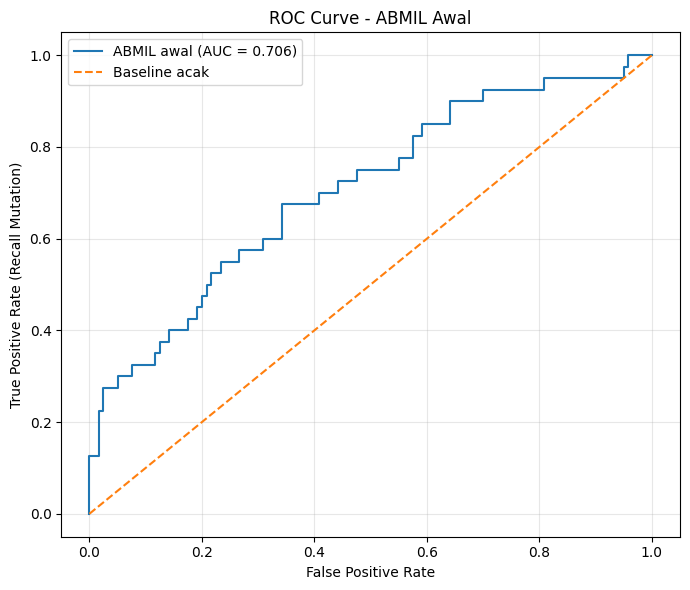

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    average_precision_score
)

# Lokasi CSV prediksi ABMIL awal
CSV_PATH = (
    "/content/drive/MyDrive/TCGA-LUAD-WSI/"
    "Features_ResNet50/abmil_initial_ce_check/"
    "abmil_initial_ce_predictions_train.csv"
)

# Baca data
df = pd.read_csv(CSV_PATH)

# Kolom label aktual dan probabilitas Mutation
y_true = pd.to_numeric(df["true_label"], errors="raise").astype(int)
y_score = pd.to_numeric(
    df["probability_mutation"], errors="raise"
)

# Pastikan data lengkap dan label biner
if y_true.isna().any() or y_score.isna().any():
    raise ValueError("Terdapat nilai kosong pada label atau probabilitas.")

if set(y_true.unique()) != {0, 1}:
    raise ValueError("Label harus memuat 0=Wildtype dan 1=Mutation.")

# Hitung ROC-AUC
auc = roc_auc_score(y_true, y_score)

# Kurva ROC
fpr, tpr, thresholds = roc_curve(y_true, y_score)

# Average Precision sebagai metrik tambahan
ap = average_precision_score(y_true, y_score)

print("Jumlah data:", len(df))
print("Jumlah Mutation:", int((y_true == 1).sum()))
print("Jumlah Wildtype:", int((y_true == 0).sum()))
print(f"ROC-AUC: {auc:.4f}")
print(f"Average Precision (AP): {ap:.4f}")

# Plot ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ABMIL awal (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Baseline acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall Mutation)")
plt.title("ROC Curve - ABMIL Awal")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5 Fold CV

In [ ]:

# ============================================================
# MEMBUAT DAN MEMVERIFIKASI 5-FOLD CROSS-VALIDATION
# Patient-level stratified split, tanpa data test
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

# 1. PATH
FEATURE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50"
TRAIN_DIR = os.path.join(FEATURE_DIR, "train")
OUTPUT_DIR = os.path.join(FEATURE_DIR, "cv5_splits")

os.makedirs(OUTPUT_DIR, exist_ok=True)

N_SPLITS = 5
SEED = 42

# 2. AMBIL NPZ DARI FOLDER TRAIN SAJA
npz_paths = sorted(
    glob.glob(os.path.join(TRAIN_DIR, "**", "*.npz"), recursive=True)
)

if not npz_paths:
    raise FileNotFoundError(
        f"Tidak ditemukan file .npz di folder: {TRAIN_DIR}"
    )

print("Jumlah file NPZ development:", len(npz_paths))
print("Folder test tidak digunakan untuk membuat fold.")

# 3. FUNGSI MEMBACA NILAI DARI NPZ
def scalar_value(value):
    """Mengubah metadata NumPy menjadi nilai Python sederhana."""
    value = np.asarray(value)

    if value.size == 0:
        return None

    value = value.reshape(-1)[0]

    if isinstance(value, bytes):
        value = value.decode("utf-8")

    if isinstance(value, np.generic):
        value = value.item()

    if isinstance(value, bytes):
        value = value.decode("utf-8")

    return value


def normalize_label(value):
    """Mutation/Mutant = 1; Wildtype = 0."""
    if value is None:
        return None

    if isinstance(value, (int, float, np.integer, np.floating)):
        if value in (0, 1):
            return int(value)

    label = str(value).strip().lower().replace("_", "").replace(" ", "")

    if label in ["mutant", "mutation", "mutated", "1"]:
        return 1

    if label in ["wildtype", "wt", "wild", "0"]:
        return 0

    return None


# 4. BACA METADATA SETIAP SLIDE
records = []
errors = []

for path in npz_paths:
    try:
        # Membaca metadata yang diperlukan saja, bukan seluruh fitur.
        with np.load(path, allow_pickle=True) as data:
            keys = set(data.files)

            if "patient_id" not in keys:
                raise ValueError("Key patient_id tidak ditemukan")

            patient_id = scalar_value(data["patient_id"])

            if patient_id is None or str(patient_id).strip() == "":
                raise ValueError("patient_id kosong")

            patient_id = str(patient_id).strip()

            if "label" in keys:
                raw_label = scalar_value(data["label"])
                label = normalize_label(raw_label)
            else:
                label = None

            # Fallback label dari nama folder jika metadata label
            # tidak tersedia atau tidak dikenali.
            if label is None:
                parent = os.path.basename(os.path.dirname(path)).lower()
                parent = parent.replace("_", "").replace(" ", "")

                if parent in ["mutant", "mutation"]:
                    label = 1
                elif parent in ["wildtype", "wt"]:
                    label = 0

            if label not in [0, 1]:
                raise ValueError(
                    f"Label tidak dikenali: "
                    f"{raw_label if 'raw_label' in locals() else None}"
                )

            records.append({
                "slide_id": os.path.splitext(os.path.basename(path))[0],
                "patient_id": patient_id,
                "label": int(label),
                "npz_path": path
            })

    except Exception as e:
        errors.append((path, str(e)))

if errors:
    print("\nFile yang gagal dibaca:", len(errors))
    for path, error in errors[:10]:
        print("-", path, "|", error)

    raise RuntimeError(
        "Ada metadata yang belum valid. Perbaiki dulu sebelum membuat fold."
    )

slides_df = pd.DataFrame(records)

# 5. VERIFIKASI LABEL ANTAR-SLIDE MILIK PASIEN YANG SAMA
labels_per_patient = slides_df.groupby("patient_id")["label"].nunique()
inconsistent = labels_per_patient[labels_per_patient > 1]

if len(inconsistent) > 0:
    print("Pasien dengan label yang tidak konsisten:")
    print(inconsistent)
    raise ValueError(
        "Label pasien tidak konsisten. Fold belum dibuat."
    )

# Satu baris per pasien agar pasien menjadi unit pembagian.
patients_df = (
    slides_df[["patient_id", "label"]]
    .drop_duplicates()
    .sort_values("patient_id")
    .reset_index(drop=True)
)

print("\n========== DATA DEVELOPMENT ==========")
print("Jumlah file slide:", len(slides_df))
print("Jumlah pasien unik:", len(patients_df))
print("Jumlah pasien Mutation:", int((patients_df["label"] == 1).sum()))
print("Jumlah pasien Wildtype:", int((patients_df["label"] == 0).sum()))

# Pastikan setiap kelas cukup untuk 5 fold.
class_counts = patients_df["label"].value_counts()

if len(class_counts) != 2 or class_counts.min() < N_SPLITS:
    raise ValueError(
        "Jumlah pasien pada salah satu kelas kurang dari 5. "
        "Stratified 5-fold tidak dapat dibuat dengan aman."
    )

# 6. BUAT STRATIFIED 5-FOLD PADA LEVEL PASIEN
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

patients_df["fold"] = -1

for fold_idx, (_, val_idx) in enumerate(
    skf.split(patients_df["patient_id"], patients_df["label"]),
    start=1
):
    patients_df.loc[val_idx, "fold"] = fold_idx

patients_df["fold"] = patients_df["fold"].astype(int)

# 7. TEMPEL FOLD PASIEN KE SEMUA SLIDE MILIKNYA
slide_folds_df = slides_df.merge(
    patients_df[["patient_id", "fold"]],
    on="patient_id",
    how="left",
    validate="many_to_one"
)

if slide_folds_df["fold"].isna().any():
    raise ValueError("Ada slide yang belum mendapatkan fold.")

# 8. VERIFIKASI TIDAK ADA PASIEN YANG BOCOR ANTAR-FOLD
assert slide_folds_df.groupby("patient_id")["fold"].nunique().max() == 1
assert patients_df["fold"].between(1, N_SPLITS).all()

print("\n========== RINGKASAN SETIAP FOLD ==========")

summary = []

for fold in range(1, N_SPLITS + 1):
    val_patients = patients_df[patients_df["fold"] == fold]
    train_patients = patients_df[patients_df["fold"] != fold]

    train_ids = set(train_patients["patient_id"])
    val_ids = set(val_patients["patient_id"])

    overlap = train_ids.intersection(val_ids)

    assert len(overlap) == 0, (
        f"Data leakage pada fold {fold}: {overlap}"
    )

    train_mut = int((train_patients["label"] == 1).sum())
    train_wt = int((train_patients["label"] == 0).sum())
    val_mut = int((val_patients["label"] == 1).sum())
    val_wt = int((val_patients["label"] == 0).sum())

    summary.append({
        "fold": fold,
        "train_patients": len(train_patients),
        "train_mutation": train_mut,
        "train_wildtype": train_wt,
        "val_patients": len(val_patients),
        "val_mutation": val_mut,
        "val_wildtype": val_wt,
        "patient_overlap": len(overlap)
    })

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

# 9. SIMPAN PEMBAGIAN AGAR DIPAKAI BERSAMA OLEH BCE/CWCE/FOCAL
patient_csv = os.path.join(
    OUTPUT_DIR, "cv5_patient_fold_assignments.csv"
)
slide_csv = os.path.join(
    OUTPUT_DIR, "cv5_slide_fold_assignments.csv"
)
summary_csv = os.path.join(
    OUTPUT_DIR, "cv5_fold_summary.csv"
)

patients_df.to_csv(patient_csv, index=False)
slide_folds_df.to_csv(slide_csv, index=False)
summary_df.to_csv(summary_csv, index=False)

print("\n========== SELESAI ==========")
print("Verifikasi patient-level: LULUS")
print("Pasien tidak tumpang tindih antara train dan validasi.")
print("Checkpoint model tidak diubah.")
print("\nFile tersimpan:")
print(patient_csv)
print(slide_csv)
print(summary_csv)


Jumlah file NPZ development: 160
Folder test tidak digunakan untuk membuat fold.

========== DATA DEVELOPMENT ==========
Jumlah file slide: 160
Jumlah pasien unik: 160
Jumlah pasien Mutation: 40
Jumlah pasien Wildtype: 120

========== RINGKASAN SETIAP FOLD ==========
 fold  train_patients  train_mutation  train_wildtype  val_patients  val_mutation  val_wildtype  patient_overlap
    1             128              32              96            32             8            24                0
    2             128              32              96            32             8            24                0
    3             128              32              96            32             8            24                0
    4             128              32              96            32             8            24                0
    5             128              32              96            32             8            24                0

========== SELESAI ==========
Verifikasi patient-leve

# BCE fix


In [ ]:

# ============================================================
# ABMIL + BCE LOSS — RESUMABLE 5-FOLD CROSS-VALIDATION
# FINAL FIX: kompatibilitas RNG checkpoint lama
#
# Dataset : 160 pasien (40 Mutation + 120 Wild Type)
# Features: ResNet-50, 2048 dimensi
# MAX_EPOCHS = 50 | PATIENCE = 10 | SEED = 42
#
# Output:
# Skenario Uji/ABMIL_BCE_Final50_v1
#
# Tidak menghapus checkpoint/hasil eksperimen lama.
# ============================================================

import os
import json
import random
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 1. KONFIGURASI
# ============================================================

ROOT = Path("/content/drive/MyDrive/TCGA-LUAD-WSI")
SPLIT_DIR = ROOT / "Skenario Uji" / "cv5_splits"

PATIENT_CSV = SPLIT_DIR / "cv5_patient_fold_assignments.csv"
SLIDE_CSV = SPLIT_DIR / "cv5_slide_fold_assignments.csv"

OUTPUT_DIR = ROOT / "Skenario Uji" / "ABMIL_BCE_Final50_v1"

SEED = 42
N_FOLDS = 5
MAX_EPOCHS = 50
PATIENCE = 10
LEARNING_RATE = 0.0001

FEATURE_DIM = 2048
ATTENTION_DIM = 256

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ============================================================
# 2. SEED
# ============================================================

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print("=" * 75)
print("ABMIL + BCE LOSS — RESUMABLE TRAINING (FINAL FIX)")
print("=" * 75)
print("Device       :", DEVICE)
print("Output       :", OUTPUT_DIR)
print("Max epochs   :", MAX_EPOCHS)
print("Patience     :", PATIENCE)
print("Learning rate:", LEARNING_RATE)
print("Seed         :", SEED)

if DEVICE.type == "cuda":
    print("GPU          :", torch.cuda.get_device_name(0))


# ============================================================
# 3. VALIDASI FILE DAN FOLDER
# ============================================================

if not ROOT.exists():
    raise FileNotFoundError(f"Folder ROOT tidak ditemukan: {ROOT}")

if not PATIENT_CSV.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {PATIENT_CSV}")

if not SLIDE_CSV.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {SLIDE_CSV}")

# Pertahankan folder dan seluruh checkpoint lama.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 4. MEMBACA DAN MEMVALIDASI SPLIT
# ============================================================

patients = pd.read_csv(PATIENT_CSV)
slides = pd.read_csv(SLIDE_CSV)

required_patient_cols = {"patient_id", "label", "fold"}
required_slide_cols = {
    "slide_id", "patient_id", "label", "npz_path", "fold"
}

if not required_patient_cols.issubset(patients.columns):
    raise ValueError(
        f"Kolom patient CSV tidak sesuai: {list(patients.columns)}"
    )

if not required_slide_cols.issubset(slides.columns):
    raise ValueError(
        f"Kolom slide CSV tidak sesuai: {list(slides.columns)}"
    )

for df in (patients, slides):
    df["patient_id"] = df["patient_id"].astype(str).str.strip()
    df["label"] = pd.to_numeric(
        df["label"], errors="raise"
    ).astype(int)
    df["fold"] = pd.to_numeric(
        df["fold"], errors="raise"
    ).astype(int)

slides["slide_id"] = slides["slide_id"].astype(str).str.strip()
slides["npz_path"] = slides["npz_path"].astype(str).str.strip()

if patients["patient_id"].duplicated().any():
    raise ValueError("patient_id duplikat ditemukan di patient CSV.")

if slides["patient_id"].duplicated().any():
    raise ValueError("Ditemukan lebih dari satu slide per pasien.")

if len(patients) != 160 or len(slides) != 160:
    raise ValueError(
        f"Diharapkan 160 pasien dan 160 slide. "
        f"Ditemukan {len(patients)} pasien dan {len(slides)} slide."
    )

if set(patients["label"].unique()) != {0, 1}:
    raise ValueError("Label harus 0=WT dan 1=Mutation.")

if set(patients["fold"].unique()) != set(range(1, 6)):
    raise ValueError("Fold harus bernomor 1 sampai 5.")

check = patients.merge(
    slides[["patient_id", "label", "fold"]],
    on="patient_id",
    how="outer",
    suffixes=("_patient", "_slide"),
    indicator=True
)

if not (check["_merge"] == "both").all():
    raise ValueError("Daftar pasien pada kedua CSV tidak cocok.")

if not (check["label_patient"] == check["label_slide"]).all():
    raise ValueError("Label pasien dan slide tidak konsisten.")

if not (check["fold_patient"] == check["fold_slide"]).all():
    raise ValueError("Pembagian fold pasien dan slide tidak konsisten.")


def resolve_npz_path(path_string):
    path = Path(path_string)
    return path if path.is_absolute() else ROOT / path


slides["resolved_npz_path"] = slides["npz_path"].apply(
    resolve_npz_path
)

missing_files = [
    str(path)
    for path in slides["resolved_npz_path"]
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files)} file fitur tidak ditemukan.\n"
        f"Contoh: {missing_files[:5]}"
    )

print("\nDataset tervalidasi:")
print("Pasien    :", len(patients))
print("Slide     :", len(slides))
print("Mutation  :", int((patients["label"] == 1).sum()))
print("Wild Type :", int((patients["label"] == 0).sum()))

for fold in range(1, N_FOLDS + 1):
    val_p = patients[patients["fold"] == fold]
    n_mut = int((val_p["label"] == 1).sum())
    n_wt = int((val_p["label"] == 0).sum())

    print(
        f"Fold {fold}: total={len(val_p)}, "
        f"Mutation={n_mut}, WT={n_wt}"
    )

    if len(val_p) != 32 or n_mut != 8 or n_wt != 24:
        raise ValueError(
            f"Distribusi validasi Fold {fold} tidak sesuai."
        )


# ============================================================
# 5. MODEL ABMIL
# ============================================================

class ABMIL(nn.Module):
    def __init__(self, feature_dim=2048, attention_dim=256):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(feature_dim, attention_dim),
            nn.Tanh(),
            nn.Linear(attention_dim, 1)
        )

        self.classifier = nn.Linear(feature_dim, 1)

    def forward(self, features):
        attention_scores = self.attention(features).squeeze(-1)

        attention_weights = torch.softmax(
            attention_scores, dim=0
        )

        bag_embedding = torch.sum(
            attention_weights.unsqueeze(-1) * features,
            dim=0
        )

        logit = self.classifier(bag_embedding).squeeze(-1)

        return logit, attention_weights


# ============================================================
# 6. MEMUAT FITUR
# ============================================================

def load_bag(row):
    npz_path = row["resolved_npz_path"]

    with np.load(npz_path, allow_pickle=False) as data:
        if "features" not in data:
            raise KeyError(
                f"Key 'features' tidak ditemukan: {npz_path}"
            )

        features = np.asarray(
            data["features"], dtype=np.float32
        )

    if features.ndim != 2 or features.shape[1] != FEATURE_DIM:
        raise ValueError(
            f"Shape fitur tidak sesuai di {npz_path}: {features.shape}"
        )

    if features.shape[0] == 0:
        raise ValueError(f"Tidak ada patch pada {npz_path}")

    if not np.isfinite(features).all():
        raise ValueError(f"NaN/Inf ditemukan pada {npz_path}")

    return torch.from_numpy(features).to(DEVICE)


# ============================================================
# 7. METRIK
# ============================================================

def calculate_metrics(y_true, probabilities):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    y_pred = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    auc = (
        roc_auc_score(y_true, probabilities)
        if len(np.unique(y_true)) == 2
        else float("nan")
    )

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_mutation": float(
            precision_score(y_true, y_pred, zero_division=0)
        ),
        "recall_mutation": float(
            recall_score(y_true, y_pred, zero_division=0)
        ),
        "specificity": float(specificity),
        "f1_mutation": float(
            f1_score(y_true, y_pred, zero_division=0)
        ),
        "roc_auc": float(auc),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


# ============================================================
# 8. EVALUASI
# ============================================================

@torch.no_grad()
def evaluate_model(model, validation_df):
    model.eval()

    y_true = []
    probabilities = []
    prediction_rows = []

    for _, row in validation_df.iterrows():
        features = load_bag(row)
        logit, _ = model(features)

        probability = float(torch.sigmoid(logit).item())
        true_label = int(row["label"])

        y_true.append(true_label)
        probabilities.append(probability)

        prediction_rows.append({
            "fold": int(row["fold"]),
            "slide_id": row["slide_id"],
            "patient_id": row["patient_id"],
            "true_label": true_label,
            "probability_mutation": probability,
            "predicted_label": int(probability >= 0.5)
        })

        del features, logit

    return (
        calculate_metrics(y_true, probabilities),
        prediction_rows
    )


# ============================================================
# 9. PENYIMPANAN CHECKPOINT DAN RNG
# ============================================================

def save_checkpoint(path, checkpoint):
    temp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temp_path)
    os.replace(temp_path, path)


def save_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state().cpu()
    }

    if torch.cuda.is_available():
        state["cuda"] = [
            item.cpu() for item in torch.cuda.get_rng_state_all()
        ]

    return state


def restore_rng_state(state, fallback_seed):
    """
    Mencoba memulihkan RNG checkpoint lama.
    Jika format tidak cocok, seluruh RNG diinisialisasi ulang
    dengan seed fold agar tidak meninggalkan RNG parsial.
    """
    try:
        if not isinstance(state, dict):
            raise TypeError("RNG state tidak tersedia atau bukan dict.")

        # Validasi dan normalisasi Torch RNG sebelum memulihkan
        torch_state = state.get("torch")

        if torch_state is not None:
            if isinstance(torch_state, np.ndarray):
                torch_state = torch.from_numpy(torch_state)
            elif isinstance(torch_state, (list, tuple)):
                torch_state = torch.tensor(
                    torch_state, dtype=torch.uint8
                )

            if not isinstance(torch_state, torch.Tensor):
                raise TypeError(
                    "Format Torch RNG bukan tensor yang valid."
                )

            torch_state = torch_state.detach().to(
                device="cpu", dtype=torch.uint8
            )

            # Uji panjang state dengan API PyTorch.
            # Jika tidak valid, masuk ke fallback seed.
            torch.set_rng_state(torch_state)

        if "python" in state:
            random.setstate(state["python"])

        if "numpy" in state:
            np.random.set_state(state["numpy"])

        if torch.cuda.is_available() and "cuda" in state:
            cuda_states = state["cuda"]

            normalized_cuda_states = []
            for item in cuda_states:
                if isinstance(item, np.ndarray):
                    item = torch.from_numpy(item)
                elif isinstance(item, (list, tuple)):
                    item = torch.tensor(item, dtype=torch.uint8)

                if not isinstance(item, torch.Tensor):
                    raise TypeError("Format CUDA RNG tidak valid.")

                normalized_cuda_states.append(
                    item.detach().to(
                        device="cpu", dtype=torch.uint8
                    )
                )

            if normalized_cuda_states:
                torch.cuda.set_rng_state_all(normalized_cuda_states)

        print("RNG state berhasil dipulihkan.")
        return True

    except Exception as exc:
        print(
            "Peringatan: RNG checkpoint lama tidak dapat dipulihkan:",
            repr(exc)
        )
        print(
            f"RNG diinisialisasi ulang menggunakan seed fold "
            f"{fallback_seed}."
        )
        set_seed(fallback_seed)
        return False


def save_history(history, fold_dir):
    pd.DataFrame(history).to_csv(
        fold_dir / "epoch_history.csv",
        index=False
    )


# ============================================================
# 10. TRAINING 5-FOLD YANG DAPAT DILANJUTKAN
# ============================================================

for fold in range(1, N_FOLDS + 1):

    print("\n" + "=" * 75)
    print(f"FOLD {fold}/{N_FOLDS}")
    print("=" * 75)

    fold_dir = OUTPUT_DIR / f"fold_{fold}"
    fold_dir.mkdir(parents=True, exist_ok=True)

    best_checkpoint_path = fold_dir / "best_checkpoint.pth"
    last_checkpoint_path = fold_dir / "last_checkpoint.pth"
    history_path = fold_dir / "epoch_history.csv"
    predictions_path = fold_dir / "validation_predictions.csv"
    fold_summary_path = fold_dir / "fold_summary.csv"

    train_patients = patients[patients["fold"] != fold].copy()
    val_patients = patients[patients["fold"] == fold].copy()

    train_df = slides[slides["fold"] != fold].copy()
    val_df = slides[slides["fold"] == fold].copy()

    train_ids = set(train_patients["patient_id"])
    val_ids = set(val_patients["patient_id"])

    if train_ids.intersection(val_ids):
        raise ValueError(f"Data leakage terdeteksi pada Fold {fold}.")

    if len(train_df) != 128 or len(val_df) != 32:
        raise ValueError(f"Jumlah train/validasi salah pada Fold {fold}.")

    train_df = train_df.sort_values(
        "patient_id"
    ).reset_index(drop=True)

    val_df = val_df.sort_values(
        "patient_id"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # A. LEWATI FOLD YANG SUDAH LENGKAP DAN VALID
    # --------------------------------------------------------

    if (
        predictions_path.exists()
        and fold_summary_path.exists()
        and best_checkpoint_path.exists()
    ):
        try:
            saved_predictions = pd.read_csv(predictions_path)
            saved_summary = pd.read_csv(fold_summary_path)

            if (
                len(saved_predictions) == 32
                and saved_predictions["patient_id"].nunique() == 32
                and len(saved_summary) == 1
            ):
                print("Fold sudah lengkap. Training dilewati.")
                continue

        except Exception as exc:
            print(
                "Hasil fold belum valid, akan mencoba checkpoint:",
                repr(exc)
            )

    # --------------------------------------------------------
    # B. INISIALISASI MODEL DAN OPTIMIZER
    # --------------------------------------------------------

    fold_seed = SEED + fold
    set_seed(fold_seed)

    model = ABMIL(
        feature_dim=FEATURE_DIM,
        attention_dim=ATTENTION_DIM
    ).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    start_epoch = 1
    best_auc = -float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    if history_path.exists():
        try:
            history = pd.read_csv(history_path).to_dict(
                orient="records"
            )
        except Exception as exc:
            print("Riwayat CSV tidak dapat dibaca:", repr(exc))
            history = []

    # --------------------------------------------------------
    # C. RESTORE CHECKPOINT
    # --------------------------------------------------------

    if last_checkpoint_path.exists():
        print("Checkpoint terakhir ditemukan. Memulihkan training...")

        last_ckpt = torch.load(
            last_checkpoint_path,
            map_location=DEVICE,
            weights_only=False
        )

        model.load_state_dict(last_ckpt["model_state_dict"])
        optimizer.load_state_dict(last_ckpt["optimizer_state_dict"])

        last_epoch = int(last_ckpt["epoch"])
        start_epoch = last_epoch + 1

        if last_ckpt.get("history"):
            history = last_ckpt["history"]

        if best_checkpoint_path.exists():
            best_ckpt = torch.load(
                best_checkpoint_path,
                map_location=DEVICE,
                weights_only=False
            )

            best_auc = float(
                best_ckpt.get(
                    "best_val_auc",
                    best_ckpt.get("val_metrics", {}).get(
                        "roc_auc", -float("inf")
                    )
                )
            )

            best_epoch = int(
                best_ckpt.get(
                    "best_epoch",
                    best_ckpt.get("epoch", 0)
                )
            )
        else:
            best_auc = float(
                last_ckpt.get("best_val_auc", -float("inf"))
            )
            best_epoch = int(
                last_ckpt.get("best_epoch", 0)
            )

        if "epochs_without_improvement" in last_ckpt:
            epochs_without_improvement = int(
                last_ckpt["epochs_without_improvement"]
            )
        else:
            epochs_without_improvement = max(
                0, last_epoch - best_epoch
            )

        restore_rng_state(
            last_ckpt.get("rng_state"),
            fallback_seed=fold_seed
        )

        print("Epoch terakhir :", last_epoch)
        print("Mulai epoch    :", start_epoch)
        print("Best epoch     :", best_epoch)
        print("Best AUC       :", best_auc)
        print("Patience count :", epochs_without_improvement)

    else:
        print("Checkpoint belum ada; mulai dari epoch 1.")

    # --------------------------------------------------------
    # D. LANJUTKAN TRAINING
    # --------------------------------------------------------

    for epoch in range(start_epoch, MAX_EPOCHS + 1):

        epoch_start = time.time()
        model.train()

        shuffled_indices = np.random.permutation(len(train_df))

        total_train_loss = 0.0
        train_true = []
        train_probabilities = []

        for index in shuffled_indices:
            row = train_df.iloc[index]
            features = load_bag(row)

            target = torch.tensor(
                float(row["label"]),
                dtype=torch.float32,
                device=DEVICE
            )

            optimizer.zero_grad(set_to_none=True)

            logit, _ = model(features)
            loss = criterion(logit, target)

            loss.backward()
            optimizer.step()

            total_train_loss += float(loss.item())
            train_true.append(int(row["label"]))
            train_probabilities.append(
                float(torch.sigmoid(logit.detach()).item())
            )

            del features, target, logit, loss

        train_loss = total_train_loss / len(train_df)

        train_metrics = calculate_metrics(
            train_true, train_probabilities
        )

        val_metrics, _ = evaluate_model(model, val_df)

        epoch_time = time.time() - epoch_start
        current_auc = float(val_metrics["roc_auc"])

        row_history = {
            "fold": fold,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_metrics["accuracy"],
            "train_precision_mutation": train_metrics["precision_mutation"],
            "train_recall_mutation": train_metrics["recall_mutation"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision_mutation": val_metrics["precision_mutation"],
            "val_recall_mutation": val_metrics["recall_mutation"],
            "val_specificity": val_metrics["specificity"],
            "val_f1_mutation": val_metrics["f1_mutation"],
            "val_roc_auc": val_metrics["roc_auc"],
            "val_tn": val_metrics["tn"],
            "val_fp": val_metrics["fp"],
            "val_fn": val_metrics["fn"],
            "val_tp": val_metrics["tp"],
            "epoch_time_sec": epoch_time
        }

        # Cegah duplikasi epoch pada riwayat jika file lama ada.
        history = [
            item for item in history
            if not (
                int(item.get("fold", fold)) == fold
                and int(item.get("epoch", -1)) == epoch
            )
        ]
        history.append(row_history)

        improved = (
            np.isfinite(current_auc) and current_auc > best_auc
        )

        if improved:
            best_auc = current_auc
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        save_history(history, fold_dir)

        checkpoint_common = {
            "fold": fold,
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_metrics": val_metrics,
            "best_epoch": best_epoch,
            "best_val_auc": best_auc,
            "epochs_without_improvement": epochs_without_improvement,
            "history": history,
            "rng_state": save_rng_state(),
            "seed": fold_seed,
            "config": {
                "loss": "BCEWithLogitsLoss",
                "feature_dim": FEATURE_DIM,
                "attention_dim": ATTENTION_DIM,
                "learning_rate": LEARNING_RATE,
                "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE
            }
        }

        if improved:
            save_checkpoint(
                best_checkpoint_path,
                copy.deepcopy(checkpoint_common)
            )

        save_checkpoint(
            last_checkpoint_path,
            checkpoint_common
        )

        print(
            f"Fold {fold} | Epoch {epoch:02d}/{MAX_EPOCHS} "
            f"| Loss={train_loss:.4f} "
            f"| Val AUC={current_auc:.4f} "
            f"| Precision={val_metrics['precision_mutation']:.4f} "
            f"| Recall={val_metrics['recall_mutation']:.4f} "
            f"| Best epoch={best_epoch} "
            f"| Patience={epochs_without_improvement}/{PATIENCE} "
            f"| {epoch_time:.1f}s"
        )

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping Fold {fold} pada epoch {epoch}. "
                f"Best epoch={best_epoch}, best AUC={best_auc:.4f}"
            )
            break

    # --------------------------------------------------------
    # E. EVALUASI CHECKPOINT TERBAIK
    # --------------------------------------------------------

    if not best_checkpoint_path.exists():
        raise RuntimeError(
            f"Checkpoint terbaik tidak ditemukan pada Fold {fold}."
        )

    best_ckpt = torch.load(
        best_checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    best_epoch = int(
        best_ckpt.get("best_epoch", best_ckpt["epoch"])
    )
    best_auc = float(
        best_ckpt.get(
            "best_val_auc",
            best_ckpt["val_metrics"]["roc_auc"]
        )
    )

    final_metrics, final_predictions = evaluate_model(model, val_df)

    for prediction in final_predictions:
        prediction["fold"] = fold
        prediction["selected_epoch"] = best_epoch

    prediction_df = pd.DataFrame(final_predictions)[
        [
            "fold",
            "selected_epoch",
            "slide_id",
            "patient_id",
            "true_label",
            "probability_mutation",
            "predicted_label"
        ]
    ]

    prediction_df.to_csv(predictions_path, index=False)

    fold_summary = {
        "fold": fold,
        "n_train": len(train_df),
        "n_validation": len(val_df),
        "best_epoch": best_epoch,
        "best_val_auc_during_training": best_auc,
        **final_metrics
    }

    pd.DataFrame([fold_summary]).to_csv(
        fold_summary_path, index=False
    )

    print(f"\nHASIL FOLD {fold}")
    print("Best epoch     :", best_epoch)
    print("Accuracy       :", round(final_metrics["accuracy"], 4))
    print("Precision Mut. :", round(final_metrics["precision_mutation"], 4))
    print("Recall Mut.    :", round(final_metrics["recall_mutation"], 4))
    print("Specificity    :", round(final_metrics["specificity"], 4))
    print("F1 Mutation    :", round(final_metrics["f1_mutation"], 4))
    print("ROC-AUC        :", round(final_metrics["roc_auc"], 4))
    print(
        f"TN={final_metrics['tn']} | FP={final_metrics['fp']} | "
        f"FN={final_metrics['fn']} | TP={final_metrics['tp']}"
    )

    del model, optimizer, criterion

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# ============================================================
# 11. BACA HASIL DARI SEMUA FOLD
# ============================================================

fold_summaries = []
all_oof_predictions = []

for fold in range(1, N_FOLDS + 1):
    fold_dir = OUTPUT_DIR / f"fold_{fold}"
    summary_path = fold_dir / "fold_summary.csv"
    predictions_path = fold_dir / "validation_predictions.csv"

    if not summary_path.exists() or not predictions_path.exists():
        raise RuntimeError(
            f"Fold {fold} belum memiliki hasil akhir. "
            "Periksa error di atas sebelum menjalankan ulang."
        )

    saved_summary = pd.read_csv(summary_path)
    saved_predictions = pd.read_csv(predictions_path)

    if len(saved_summary) != 1:
        raise ValueError(f"Ringkasan Fold {fold} tidak valid.")

    if (
        len(saved_predictions) != 32
        or saved_predictions["patient_id"].nunique() != 32
    ):
        raise ValueError(
            f"Prediksi Fold {fold} tidak berisi 32 pasien unik."
        )

    fold_summaries.append(saved_summary.iloc[0].to_dict())
    all_oof_predictions.extend(
        saved_predictions.to_dict(orient="records")
    )


# ============================================================
# 12. RINGKASAN 5 FOLD
# ============================================================

summary_df = pd.DataFrame(fold_summaries).sort_values("fold")

summary_path = OUTPUT_DIR / "bce_cv_fold_summary.csv"
summary_df.to_csv(summary_path, index=False)

metric_columns = [
    "accuracy",
    "precision_mutation",
    "recall_mutation",
    "specificity",
    "f1_mutation",
    "roc_auc"
]

mean_std_rows = []

for metric in metric_columns:
    mean_std_rows.append({
        "metric": metric,
        "mean": float(summary_df[metric].mean()),
        "std": float(summary_df[metric].std(ddof=1))
    })

mean_std_df = pd.DataFrame(mean_std_rows)

mean_std_path = OUTPUT_DIR / "bce_cv_mean_std.csv"
mean_std_df.to_csv(mean_std_path, index=False)


# ============================================================
# 13. PREDIKSI OUT-OF-FOLD
# ============================================================

oof_df = pd.DataFrame(all_oof_predictions)

expected_columns = [
    "fold",
    "selected_epoch",
    "slide_id",
    "patient_id",
    "true_label",
    "probability_mutation",
    "predicted_label"
]

oof_df = oof_df[expected_columns]

if len(oof_df) != 160:
    raise ValueError(
        f"Prediksi OOF harus berjumlah 160, ditemukan {len(oof_df)}."
    )

if oof_df["patient_id"].nunique() != 160:
    raise ValueError("Prediksi OOF tidak berisi 160 pasien unik.")

oof_path = OUTPUT_DIR / "bce_cv_oof_predictions.csv"
oof_df.to_csv(oof_path, index=False)

oof_metrics = calculate_metrics(
    oof_df["true_label"].to_numpy(),
    oof_df["probability_mutation"].to_numpy()
)

oof_metrics_path = OUTPUT_DIR / "bce_cv_oof_metrics.json"

with open(oof_metrics_path, "w", encoding="utf-8") as f:
    json.dump(oof_metrics, f, indent=4, allow_nan=False)


# ============================================================
# 14. HASIL AKHIR
# ============================================================

print("\n" + "=" * 75)
print("SELESAI — ABMIL + BCE LOSS, 5-FOLD CROSS-VALIDATION")
print("=" * 75)

print("\nRINGKASAN PER FOLD")
print(
    summary_df[
        [
            "fold",
            "best_epoch",
            "accuracy",
            "precision_mutation",
            "recall_mutation",
            "specificity",
            "f1_mutation",
            "roc_auc"
        ]
    ].to_string(index=False)
)

print("\nRATA-RATA ± STANDAR DEVIASI")
print(mean_std_df.to_string(index=False))

print("\nMETRIK GABUNGAN OOF — 160 PASIEN")
for metric, value in oof_metrics.items():
    print(f"{metric:24s}: {value}")

print("\nLOKASI HASIL")
print("Folder hasil   :", OUTPUT_DIR)
print("Ringkasan fold :", summary_path)
print("Mean/std       :", mean_std_path)
print("Prediksi OOF   :", oof_path)
print("Metrik OOF     :", oof_metrics_path)

print("\nSetiap folder fold menyimpan:")
print("- best_checkpoint.pth")
print("- last_checkpoint.pth")
print("- epoch_history.csv")
print("- validation_predictions.csv")
print("- fold_summary.csv")


In [ ]:

# ================================================================
# SKENARIO 1 — ABMIL + BCE
# 5-Fold CV | Maks. 50 epoch | Early stopping patience 10
# Optimasi: cache fitur lokal + cache RAM jika memori mencukupi
# Tetap menggunakan SELURUH patch dan fitur ResNet-50 yang tersedia
# ================================================================

import os, json, time, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
SPLIT_CSV = (
    f"{BASE_DIR}/Skenario Uji/cv5_splits/"
    "cv5_patient_fold_assignments.csv"
)

SCENARIO = "BCE"
FEAT_DIM = 2048
ATT_DIM = 256
LR = 1e-4
MAX_EPOCHS = 50
PATIENCE = 10
THRESHOLD = 0.5
FOLDS_TO_RUN = [1, 2, 3, 4, 5]
SEED = 42

# Jangan ubah menjadi True jika metodologi mewajibkan semua patch.
USE_PATCH_LIMIT = False

CACHE_DIR = "/content/abmil_resnet50_cache_fp16"
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_ROOT = f"{BASE_DIR}/Skenario Uji/ABMIL_BCE_50ep_{RUN_ID}"

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_ROOT, exist_ok=False)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("SKENARIO:", SCENARIO)
print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("FEATURE_DIR:", FEATURE_DIR)
print("OUTPUT:", OUT_ROOT)
print("=" * 60)

assert os.path.isdir(FEATURE_DIR), f"Folder tidak ditemukan: {FEATURE_DIR}"
assert os.path.isfile(SPLIT_CSV), f"CSV tidak ditemukan: {SPLIT_CSV}"

# -------------------- 2. BACA DATA SPLIT -------------------------

df = pd.read_csv(SPLIT_CSV)

required = {"patient_id", "label", "fold"}
if not required.issubset(df.columns):
    raise ValueError(f"Kolom CSV harus mencakup: {required}")

df = df[["patient_id", "label", "fold"]].copy()
df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)
df["fold"] = pd.to_numeric(df["fold"], errors="raise").astype(int)

if df["patient_id"].duplicated().any():
    raise ValueError("Ada patient_id duplikat dalam CSV.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError("Label harus 0=Wild-Type, 1=Mutation.")

if set(df["fold"].unique()) != {1, 2, 3, 4, 5}:
    raise ValueError(f"Distribusi fold tidak sesuai: {sorted(df['fold'].unique())}")

print("\nJumlah pasien development:", len(df))
print("Distribusi label:")
print(df["label"].value_counts().sort_index())
print("\nDistribusi fold:")
print(pd.crosstab(df["fold"], df["label"]))

# -------------------- 3. CARI FITUR DEVELOPMENT -----------------

npz_files = sorted(str(p) for p in Path(FEATURE_DIR).rglob("*.npz"))

if not npz_files:
    raise FileNotFoundError(f"Tidak ada file NPZ di {FEATURE_DIR}")

def patient_id_from_filename(path):
    # TCGA-44-5645-01Z-00-DX1.UUID.npz -> TCGA-44-5645
    return "-".join(Path(path).name.split("-")[:3])

files_by_pid = {}
for fp in npz_files:
    pid = patient_id_from_filename(fp)
    files_by_pid.setdefault(pid, []).append(fp)

duplicates = {p: v for p, v in files_by_pid.items() if len(v) != 1}
if duplicates:
    raise ValueError(
        "Ditemukan pasien dengan lebih dari satu file fitur. "
        "Pastikan pemetaan slide-pasien terlebih dahulu. "
        f"Contoh: {list(duplicates.items())[:5]}"
    )

patient_ids = set(df["patient_id"])
missing = sorted(patient_ids - set(files_by_pid))
extra = sorted(set(files_by_pid) - patient_ids)

if missing:
    raise ValueError(f"Pasien CV tanpa fitur: {missing[:10]}")

if extra:
    print("Peringatan: file tambahan di folder train:", extra[:10])

feature_paths = {p: files_by_pid[p][0] for p in patient_ids}

print("\nFile NPZ ditemukan:", len(npz_files))
print("Pasien CV cocok:", len(feature_paths))

if len(feature_paths) != len(df):
    raise ValueError("Jumlah file fitur tidak sama dengan jumlah pasien CV.")

# -------------------- 4. BUAT CACHE SATU KALI --------------------

# Cache disimpan sebagai float16 di disk lokal.
# Metadata sumber diperiksa agar cache yang sudah usang dibuat ulang.
cache_paths = {}
start_cache = time.time()

print("\nMemeriksa cache fitur lokal...")

for i, (pid, source_path) in enumerate(feature_paths.items(), start=1):
    src = Path(source_path)
    cache_path = Path(CACHE_DIR) / f"{pid}.pt"
    meta_path = Path(CACHE_DIR) / f"{pid}.json"

    source_meta = {
        "path": str(src.resolve()),
        "size": src.stat().st_size,
        "mtime": src.stat().st_mtime,
    }

    valid_cache = False
    if cache_path.exists() and meta_path.exists():
        try:
            with open(meta_path, "r") as f:
                valid_cache = json.load(f) == source_meta
        except Exception:
            valid_cache = False

    if not valid_cache:
        with np.load(source_path, allow_pickle=False) as z:
            if "features" not in z.files:
                raise KeyError(f"Array features tidak ditemukan: {source_path}")

            arr = z["features"]
            if arr.ndim != 2 or arr.shape[1] != FEAT_DIM:
                raise ValueError(
                    f"Dimensi fitur tidak sesuai: {source_path}: {arr.shape}"
                )
            if not np.isfinite(arr).all():
                raise ValueError(f"Fitur mengandung NaN/Inf: {source_path}")

            feat = torch.from_numpy(arr.copy()).to(torch.float16).contiguous()

        torch.save(feat, cache_path)
        with open(meta_path, "w") as f:
            json.dump(source_meta, f)

    cache_paths[pid] = str(cache_path)

    if i % 20 == 0 or i == len(feature_paths):
        print(f"Cache: {i}/{len(feature_paths)} pasien")

print(f"Cache siap dalam {(time.time() - start_cache) / 60:.1f} menit.")

# -------------------- 5. OPTIMASI PEMUATAN FITUR -----------------

# Muat semua cache ke RAM hanya jika ukuran totalnya cukup kecil.
# Jika tidak, gunakan file cache lokal dengan mmap.
try:
    import psutil
    available_ram = psutil.virtual_memory().available
except Exception:
    available_ram = 0

total_cache_bytes = sum(os.path.getsize(p) for p in cache_paths.values())
ram_budget = min(6 * 1024**3, int(available_ram * 0.35)) if available_ram else 0

FEATURE_RAM = {}

if total_cache_bytes > 0 and total_cache_bytes <= ram_budget:
    print(
        f"Cache dimuat ke RAM ({total_cache_bytes / 1024**3:.2f} GB) "
        "karena kapasitas memori mencukupi."
    )
    for pid, path in cache_paths.items():
        try:
            FEATURE_RAM[pid] = torch.load(
                path, map_location="cpu", weights_only=True
            )
        except TypeError:
            FEATURE_RAM[pid] = torch.load(path, map_location="cpu")
else:
    print(
        "Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan."
    )

def load_bag(pid):
    if pid in FEATURE_RAM:
        feat = FEATURE_RAM[pid]
    else:
        # mmap menghindari pemuatan seluruh cache ke RAM.
        try:
            feat = torch.load(
                cache_paths[pid],
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
        except TypeError:
            feat = torch.load(cache_paths[pid], map_location="cpu")

    if feat.ndim != 2 or feat.shape[1] != FEAT_DIM:
        raise ValueError(f"Cache tidak valid: {pid}, {tuple(feat.shape)}")

    # Seluruh patch dipakai; tidak melakukan sampling.
    return feat.to(device=DEVICE, dtype=torch.float32)

# -------------------- 6. MODEL ABMIL -----------------------------

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, x):
        scores = self.attention(x)
        weights = torch.softmax(scores, dim=0)
        bag_embedding = torch.sum(weights * x, dim=0)
        return self.classifier(bag_embedding).view(1)

def calculate_metrics(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    preds = (probs >= THRESHOLD).astype(int)

    result = {
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "auc": (
            roc_auc_score(y_true, probs)
            if len(np.unique(y_true)) == 2 else np.nan
        )
    }

    tn, fp, fn, tp = confusion_matrix(
        y_true, preds, labels=[0, 1]
    ).ravel()

    result.update({
        "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp)
    })
    return result

# -------------------- 7. TRAINING 5-FOLD CV ----------------------

all_fold_metrics = []
all_predictions = []

for fold in FOLDS_TO_RUN:
    print("\n" + "=" * 60)
    print(f"FOLD {fold}/5 — ABMIL + BCE")
    print("=" * 60)

    train_df = df[df["fold"] != fold].reset_index(drop=True)
    val_df = df[df["fold"] == fold].reset_index(drop=True)

    if train_df["label"].nunique() < 2 or val_df["label"].nunique() < 2:
        raise ValueError(f"Kelas tidak lengkap pada fold {fold}.")

    model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.BCEWithLogitsLoss()

    fold_dir = os.path.join(OUT_ROOT, f"fold_{fold}")
    os.makedirs(fold_dir, exist_ok=False)

    best_path = os.path.join(fold_dir, "best_model.pt")
    pred_path = os.path.join(fold_dir, "validation_predictions.csv")

    best_val_loss = float("inf")
    best_epoch = 0
    patience_count = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        model.train()
        train_losses = []

        shuffled = train_df.sample(frac=1, random_state=SEED + epoch)

        for row in shuffled.itertuples(index=False):
            pid = str(row.patient_id)
            label = float(row.label)

            x = load_bag(pid)
            y = torch.tensor([label], device=DEVICE, dtype=torch.float32)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())
            del x, y, logits, loss

        model.eval()
        val_losses, val_probs, val_labels, val_pids = [], [], [], []

        with torch.no_grad():
            for row in val_df.itertuples(index=False):
                pid = str(row.patient_id)
                label = int(row.label)

                x = load_bag(pid)
                y = torch.tensor([float(label)], device=DEVICE)

                logits = model(x)
                loss = criterion(logits, y)

                val_losses.append(loss.item())
                val_probs.append(torch.sigmoid(logits).item())
                val_labels.append(label)
                val_pids.append(pid)

                del x, y, logits, loss

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        val_metrics = calculate_metrics(val_labels, val_probs)

        history.append({
            "fold": fold,
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            **{f"val_{k}": v for k, v in val_metrics.items()}
        })

        print(
            f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | "
            f"Train loss={train_loss:.4f} | Val loss={val_loss:.4f} | "
            f"AUC={val_metrics['auc']:.4f} | "
            f"F1={val_metrics['f1']:.4f} | "
            f"{time.time()-t0:.1f}s"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            patience_count = 0

            torch.save({
                "fold": fold,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_val_loss": best_val_loss,
                "feat_dim": FEAT_DIM,
                "att_dim": ATT_DIM,
                "scenario": SCENARIO
            }, best_path)

            pd.DataFrame({
                "patient_id": val_pids,
                "label": val_labels,
                "prob_mutation": val_probs,
                "prediction": (np.asarray(val_probs) >= THRESHOLD).astype(int),
                "fold": fold,
                "best_epoch": epoch
            }).to_csv(pred_path, index=False)
        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            print(f"Early stopping pada epoch {epoch}.")
            break

    pd.DataFrame(history).to_csv(
        os.path.join(fold_dir, "training_history.csv"), index=False
    )

    fold_pred = pd.read_csv(pred_path)
    fold_metrics = calculate_metrics(
        fold_pred["label"], fold_pred["prob_mutation"]
    )

    all_fold_metrics.append({
        "scenario": SCENARIO,
        "fold": fold,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        **fold_metrics
    })
    all_predictions.append(fold_pred)

    print(
        f"Fold {fold} selesai | best epoch={best_epoch} | "
        f"AUC={fold_metrics['auc']:.4f} | "
        f"Accuracy={fold_metrics['accuracy']:.4f} | "
        f"F1={fold_metrics['f1']:.4f}"
    )

    del model, optimizer, criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# -------------------- 8. SIMPAN HASIL ----------------------------

metrics_df = pd.DataFrame(all_fold_metrics)
metrics_df.to_csv(os.path.join(OUT_ROOT, "fold_metrics.csv"), index=False)

predictions_df = pd.concat(all_predictions, ignore_index=True)
predictions_df.to_csv(
    os.path.join(OUT_ROOT, "all_validation_predictions.csv"),
    index=False
)

summary = []
for metric in ["accuracy", "precision", "recall", "f1", "auc"]:
    values = metrics_df[metric].dropna()
    summary.append({
        "metric": metric,
        "mean": values.mean(),
        "std": values.std(ddof=1) if len(values) > 1 else 0.0
    })

summary_df = pd.DataFrame(summary)
summary_df.to_csv(
    os.path.join(OUT_ROOT, "cv_summary_mean_std.csv"), index=False
)

print("\n" + "=" * 60)
print("TRAINING SELESAI — ABMIL + BCE")
print("=" * 60)
print("\nMetrik per fold:")
print(metrics_df.to_string(index=False))
print("\nRingkasan mean ± std:")
print(summary_df.to_string(index=False))
print("\nFolder hasil:", OUT_ROOT)


SKENARIO: BCE
DEVICE: cuda
GPU: Tesla T4
FEATURE_DIR: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/train
OUTPUT: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/ABMIL_BCE_50ep_20261025_213711

Jumlah pasien development: 160
Distribusi label:
label
0    120
1     40
Name: count, dtype: int64

Distribusi fold:
label   0  1
fold        
1      24  8
2      24  8
3      24  8
4      24  8
5      24  8

File NPZ ditemukan: 160
Pasien CV cocok: 160

Memeriksa cache fitur lokal...
Cache: 20/160 pasien
Cache: 40/160 pasien
Cache: 60/160 pasien
Cache: 80/160 pasien
Cache: 100/160 pasien
Cache: 120/160 pasien
Cache: 140/160 pasien
Cache: 160/160 pasien
Cache siap dalam 44.4 menit.
Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan.

FOLD 1/5 — ABMIL + BCE
Fold 1 | Epoch 1/50 | Train loss=0.5869 | Val loss=0.5681 | AUC=0.3802 | F1=0.0000 | 172.1s
Fold 1 | Epoch 2/50 | Train loss=0.5638 | Val loss=0.5652 | AUC=0.4062 | F1=0.0000 | 170.9s
Fold 1 | Epoch 3/50 | Train l

In [ ]:
from google.colab import files

files.download("/content/abmil_resnet50_cache_fp16")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# CWCE

In [ ]:
# ================================================================
# SKENARIO 2 — ABMIL + CWCE (Class-Weighted Cross-Entropy)
# 5-Fold CV | Maks. 50 epoch | Early stopping patience 10
# Bobot kelas: inverse class frequency  w_c = N / (K * N_c)
# dihitung otomatis dari data TRAINING di tiap fold (tanpa kebocoran data)
# RESUME: jalankan ulang cell yang sama -> fold selesai dilewati, fold yang
# terputus dilanjutkan dari checkpoint epoch terakhir (disimpan di Drive)
# Optimasi: cache fitur lokal + cache RAM jika memori mencukupi
# Tetap menggunakan SELURUH patch dan fitur ResNet-50 yang tersedia
# ================================================================

import os, json, time, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
SPLIT_CSV = (
    f"{BASE_DIR}/Skenario Uji/cv5_splits/"
    "cv5_patient_fold_assignments.csv"
)

SCENARIO = "CWCE"
NUM_CLASSES = 2   # K pada w_c = N / (K * N_c)
FEAT_DIM = 2048
ATT_DIM = 256
LR = 1e-4
MAX_EPOCHS = 50
PATIENCE = 10
THRESHOLD = 0.5
FOLDS_TO_RUN = [1, 2, 3, 4, 5]
SEED = 42

# Jangan ubah menjadi True jika metodologi mewajibkan semua patch.
USE_PATCH_LIMIT = False

CACHE_DIR = "/content/abmil_resnet50_cache_fp16"

# Nama folder TETAP (tanpa timestamp) agar run ulang melanjutkan folder yang sama.
# Untuk mulai benar-benar baru: ganti RUN_NAME atau hapus foldernya di Drive.
RUN_NAME = "ABMIL_CWCE_50ep"
OUT_ROOT = f"{BASE_DIR}/Skenario Uji/{RUN_NAME}"

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_ROOT, exist_ok=True)

# Konfigurasi disimpan; jika berbeda dengan run sebelumnya -> hentikan
# supaya tidak melanjutkan dengan hyperparameter yang tidak konsisten.
CONFIG = {
    "scenario": SCENARIO, "feat_dim": FEAT_DIM, "att_dim": ATT_DIM,
    "lr": LR, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "threshold": THRESHOLD, "seed": SEED
}
config_path = os.path.join(OUT_ROOT, "config.json")
if os.path.exists(config_path):
    with open(config_path, "r") as f:
        old_cfg = json.load(f)
    if old_cfg != CONFIG:
        raise ValueError(
            f"Konfigurasi berbeda dengan run sebelumnya di {OUT_ROOT}.\n"
            f"Lama: {old_cfg}\nBaru: {CONFIG}\n"
            "Ganti RUN_NAME untuk eksperimen baru."
        )
else:
    with open(config_path, "w") as f:
        json.dump(CONFIG, f, indent=2)

def atomic_torch_save(obj, path):
    # Tulis ke file sementara lalu rename -> file tidak rusak jika runtime mati
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("SKENARIO:", SCENARIO)
print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("FEATURE_DIR:", FEATURE_DIR)
print("OUTPUT:", OUT_ROOT)
print("=" * 60)

assert os.path.isdir(FEATURE_DIR), f"Folder tidak ditemukan: {FEATURE_DIR}"
assert os.path.isfile(SPLIT_CSV), f"CSV tidak ditemukan: {SPLIT_CSV}"

# -------------------- 2. BACA DATA SPLIT -------------------------

df = pd.read_csv(SPLIT_CSV)

required = {"patient_id", "label", "fold"}
if not required.issubset(df.columns):
    raise ValueError(f"Kolom CSV harus mencakup: {required}")

df = df[["patient_id", "label", "fold"]].copy()
df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)
df["fold"] = pd.to_numeric(df["fold"], errors="raise").astype(int)

if df["patient_id"].duplicated().any():
    raise ValueError("Ada patient_id duplikat dalam CSV.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError("Label harus 0=Wild-Type, 1=Mutation.")

if set(df["fold"].unique()) != {1, 2, 3, 4, 5}:
    raise ValueError(f"Distribusi fold tidak sesuai: {sorted(df['fold'].unique())}")

print("\nJumlah pasien development:", len(df))
print("Distribusi label:")
print(df["label"].value_counts().sort_index())
print("\nDistribusi fold:")
print(pd.crosstab(df["fold"], df["label"]))

# -------------------- 3. CARI FITUR DEVELOPMENT -----------------

npz_files = sorted(str(p) for p in Path(FEATURE_DIR).rglob("*.npz"))

if not npz_files:
    raise FileNotFoundError(f"Tidak ada file NPZ di {FEATURE_DIR}")

def patient_id_from_filename(path):
    # TCGA-44-5645-01Z-00-DX1.UUID.npz -> TCGA-44-5645
    return "-".join(Path(path).name.split("-")[:3])

files_by_pid = {}
for fp in npz_files:
    pid = patient_id_from_filename(fp)
    files_by_pid.setdefault(pid, []).append(fp)

duplicates = {p: v for p, v in files_by_pid.items() if len(v) != 1}
if duplicates:
    raise ValueError(
        "Ditemukan pasien dengan lebih dari satu file fitur. "
        "Pastikan pemetaan slide-pasien terlebih dahulu. "
        f"Contoh: {list(duplicates.items())[:5]}"
    )

patient_ids = set(df["patient_id"])
missing = sorted(patient_ids - set(files_by_pid))
extra = sorted(set(files_by_pid) - patient_ids)

if missing:
    raise ValueError(f"Pasien CV tanpa fitur: {missing[:10]}")

if extra:
    print("Peringatan: file tambahan di folder train:", extra[:10])

feature_paths = {p: files_by_pid[p][0] for p in patient_ids}

print("\nFile NPZ ditemukan:", len(npz_files))
print("Pasien CV cocok:", len(feature_paths))

if len(feature_paths) != len(df):
    raise ValueError("Jumlah file fitur tidak sama dengan jumlah pasien CV.")

# -------------------- 4. BUAT CACHE SATU KALI --------------------

# Cache disimpan sebagai float16 di disk lokal.
# Metadata sumber diperiksa agar cache yang sudah usang dibuat ulang.
cache_paths = {}
start_cache = time.time()

print("\nMemeriksa cache fitur lokal...")

for i, (pid, source_path) in enumerate(feature_paths.items(), start=1):
    src = Path(source_path)
    cache_path = Path(CACHE_DIR) / f"{pid}.pt"
    meta_path = Path(CACHE_DIR) / f"{pid}.json"

    source_meta = {
        "path": str(src.resolve()),
        "size": src.stat().st_size,
        "mtime": src.stat().st_mtime,
    }

    valid_cache = False
    if cache_path.exists() and meta_path.exists():
        try:
            with open(meta_path, "r") as f:
                valid_cache = json.load(f) == source_meta
        except Exception:
            valid_cache = False

    if not valid_cache:
        with np.load(source_path, allow_pickle=False) as z:
            if "features" not in z.files:
                raise KeyError(f"Array features tidak ditemukan: {source_path}")

            arr = z["features"]
            if arr.ndim != 2 or arr.shape[1] != FEAT_DIM:
                raise ValueError(
                    f"Dimensi fitur tidak sesuai: {source_path}: {arr.shape}"
                )
            if not np.isfinite(arr).all():
                raise ValueError(f"Fitur mengandung NaN/Inf: {source_path}")

            feat = torch.from_numpy(arr.copy()).to(torch.float16).contiguous()

        torch.save(feat, cache_path)
        with open(meta_path, "w") as f:
            json.dump(source_meta, f)

    cache_paths[pid] = str(cache_path)

    if i % 20 == 0 or i == len(feature_paths):
        print(f"Cache: {i}/{len(feature_paths)} pasien")

print(f"Cache siap dalam {(time.time() - start_cache) / 60:.1f} menit.")

# -------------------- 5. OPTIMASI PEMUATAN FITUR -----------------

# Muat semua cache ke RAM hanya jika ukuran totalnya cukup kecil.
# Jika tidak, gunakan file cache lokal dengan mmap.
try:
    import psutil
    available_ram = psutil.virtual_memory().available
except Exception:
    available_ram = 0

total_cache_bytes = sum(os.path.getsize(p) for p in cache_paths.values())
ram_budget = min(6 * 1024**3, int(available_ram * 0.35)) if available_ram else 0

FEATURE_RAM = {}

if total_cache_bytes > 0 and total_cache_bytes <= ram_budget:
    print(
        f"Cache dimuat ke RAM ({total_cache_bytes / 1024**3:.2f} GB) "
        "karena kapasitas memori mencukupi."
    )
    for pid, path in cache_paths.items():
        try:
            FEATURE_RAM[pid] = torch.load(
                path, map_location="cpu", weights_only=True
            )
        except TypeError:
            FEATURE_RAM[pid] = torch.load(path, map_location="cpu")
else:
    print(
        "Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan."
    )

def load_bag(pid):
    if pid in FEATURE_RAM:
        feat = FEATURE_RAM[pid]
    else:
        # mmap menghindari pemuatan seluruh cache ke RAM.
        try:
            feat = torch.load(
                cache_paths[pid],
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
        except TypeError:
            feat = torch.load(cache_paths[pid], map_location="cpu")

    if feat.ndim != 2 or feat.shape[1] != FEAT_DIM:
        raise ValueError(f"Cache tidak valid: {pid}, {tuple(feat.shape)}")

    # Seluruh patch dipakai; tidak melakukan sampling.
    return feat.to(device=DEVICE, dtype=torch.float32)

# -------------------- 6. MODEL ABMIL -----------------------------

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, x):
        scores = self.attention(x)
        weights = torch.softmax(scores, dim=0)
        bag_embedding = torch.sum(weights * x, dim=0)
        return self.classifier(bag_embedding).view(1)

class ClassWeightedBCE(nn.Module):
    """
    Class-Weighted Cross-Entropy (biner, 1 logit + sigmoid):
        L = - w_y * [ y*log(p) + (1-y)*log(1-p) ]
    w_0 = bobot Wild-Type, w_1 = bobot Mutation (inverse class frequency).
    """
    def __init__(self, w_wildtype, w_mutation):
        super().__init__()
        self.register_buffer(
            "class_w",
            torch.tensor([w_wildtype, w_mutation], dtype=torch.float32)
        )
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        per_sample = self.bce(logits, y)                 # BCE tiap sampel
        w = self.class_w[y.long()]                       # bobot sesuai kelas
        return (w * per_sample).mean()

def compute_class_weights(labels, num_classes=2):
    """w_c = N / (K * N_c)  (Persamaan 2.14 pada proposal)."""
    labels = np.asarray(labels, dtype=int)
    n_total = len(labels)
    counts = np.bincount(labels, minlength=num_classes)
    if (counts == 0).any():
        raise ValueError(f"Ada kelas tanpa sampel pada data training: {counts}")
    weights = n_total / (num_classes * counts)
    return weights, counts

def calculate_metrics(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    preds = (probs >= THRESHOLD).astype(int)

    result = {
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "auc": (
            roc_auc_score(y_true, probs)
            if len(np.unique(y_true)) == 2 else np.nan
        )
    }

    tn, fp, fn, tp = confusion_matrix(
        y_true, preds, labels=[0, 1]
    ).ravel()

    result.update({
        "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp)
    })
    return result

# -------------------- 7. TRAINING 5-FOLD CV ----------------------

all_fold_metrics = []
all_predictions = []

for fold in FOLDS_TO_RUN:
    print("\n" + "=" * 60)
    print(f"FOLD {fold}/5 — ABMIL + CWCE")
    print("=" * 60)

    train_df = df[df["fold"] != fold].reset_index(drop=True)
    val_df = df[df["fold"] == fold].reset_index(drop=True)

    if train_df["label"].nunique() < 2 or val_df["label"].nunique() < 2:
        raise ValueError(f"Kelas tidak lengkap pada fold {fold}.")

    # Bobot kelas dihitung HANYA dari data training fold ini
    class_weights, class_counts = compute_class_weights(
        train_df["label"].values, NUM_CLASSES
    )
    w_wt, w_mut = float(class_weights[0]), float(class_weights[1])
    print(
        f"Training: Wild-Type={class_counts[0]}, Mutation={class_counts[1]} | "
        f"w_WT={w_wt:.4f}, w_MUT={w_mut:.4f}"
    )

    model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = ClassWeightedBCE(w_wt, w_mut).to(DEVICE)

    fold_dir = os.path.join(OUT_ROOT, f"fold_{fold}")
    os.makedirs(fold_dir, exist_ok=True)

    best_path = os.path.join(fold_dir, "best_model.pt")
    pred_path = os.path.join(fold_dir, "validation_predictions.csv")
    ckpt_path = os.path.join(fold_dir, "last_checkpoint.pt")
    done_path = os.path.join(fold_dir, "fold_result.json")

    # ---- RESUME (1): fold yang sudah selesai dilewati ----
    if os.path.exists(done_path) and os.path.exists(pred_path):
        with open(done_path, "r") as f:
            all_fold_metrics.append(json.load(f))
        all_predictions.append(pd.read_csv(pred_path))
        print(f"Fold {fold} sudah selesai pada run sebelumnya -> dilewati.")
        del model, optimizer, criterion
        continue

    best_val_loss = float("inf")
    best_epoch = 0
    patience_count = 0
    history = []
    start_epoch = 1

    # ---- RESUME (2): lanjutkan fold yang terputus dari checkpoint ----
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        best_val_loss = ckpt["best_val_loss"]
        best_epoch = ckpt["best_epoch"]
        patience_count = ckpt["patience_count"]
        history = ckpt["history"]
        start_epoch = ckpt["epoch"] + 1
        print(
            f"Melanjutkan fold {fold} dari epoch {start_epoch} "
            f"(best epoch={best_epoch}, best val loss={best_val_loss:.4f})"
        )

    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        if patience_count >= PATIENCE:
            print("Early stopping sudah tercapai pada run sebelumnya.")
            break
        t0 = time.time()
        model.train()
        train_losses = []

        shuffled = train_df.sample(frac=1, random_state=SEED + epoch)

        for row in shuffled.itertuples(index=False):
            pid = str(row.patient_id)
            label = float(row.label)

            x = load_bag(pid)
            y = torch.tensor([label], device=DEVICE, dtype=torch.float32)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())
            del x, y, logits, loss

        model.eval()
        val_losses, val_probs, val_labels, val_pids = [], [], [], []

        with torch.no_grad():
            for row in val_df.itertuples(index=False):
                pid = str(row.patient_id)
                label = int(row.label)

                x = load_bag(pid)
                y = torch.tensor([float(label)], device=DEVICE)

                logits = model(x)
                loss = criterion(logits, y)

                val_losses.append(loss.item())
                val_probs.append(torch.sigmoid(logits).item())
                val_labels.append(label)
                val_pids.append(pid)

                del x, y, logits, loss

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        val_metrics = calculate_metrics(val_labels, val_probs)

        history.append({
            "fold": fold,
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            **{f"val_{k}": v for k, v in val_metrics.items()}
        })

        print(
            f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | "
            f"Train loss={train_loss:.4f} | Val loss={val_loss:.4f} | "
            f"AUC={val_metrics['auc']:.4f} | "
            f"F1={val_metrics['f1']:.4f} | "
            f"{time.time()-t0:.1f}s"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            patience_count = 0

            atomic_torch_save({
                "fold": fold,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_val_loss": best_val_loss,
                "feat_dim": FEAT_DIM,
                "att_dim": ATT_DIM,
                "scenario": SCENARIO,
                "class_weights": {"wild_type": w_wt, "mutation": w_mut}
            }, best_path)

            pd.DataFrame({
                "patient_id": val_pids,
                "label": val_labels,
                "prob_mutation": val_probs,
                "prediction": (np.asarray(val_probs) >= THRESHOLD).astype(int),
                "fold": fold,
                "best_epoch": epoch
            }).to_csv(pred_path, index=False)
        else:
            patience_count += 1

        # Simpan checkpoint setiap epoch (untuk resume jika runtime berhenti)
        atomic_torch_save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "best_epoch": best_epoch,
            "patience_count": patience_count,
            "history": history
        }, ckpt_path)

        if patience_count >= PATIENCE:
            print(f"Early stopping pada epoch {epoch}.")
            break

    pd.DataFrame(history).to_csv(
        os.path.join(fold_dir, "training_history.csv"), index=False
    )

    fold_pred = pd.read_csv(pred_path)
    fold_metrics = calculate_metrics(
        fold_pred["label"], fold_pred["prob_mutation"]
    )

    all_fold_metrics.append({
        "scenario": SCENARIO,
        "fold": fold,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "w_wild_type": w_wt,
        "w_mutation": w_mut,
        **fold_metrics
    })
    all_predictions.append(fold_pred)

    # Tandai fold selesai (dibaca saat resume)
    with open(done_path, "w") as f:
        json.dump(all_fold_metrics[-1], f, default=float)

    print(
        f"Fold {fold} selesai | best epoch={best_epoch} | "
        f"AUC={fold_metrics['auc']:.4f} | "
        f"Accuracy={fold_metrics['accuracy']:.4f} | "
        f"F1={fold_metrics['f1']:.4f}"
    )

    del model, optimizer, criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# -------------------- 8. SIMPAN HASIL ----------------------------

metrics_df = pd.DataFrame(all_fold_metrics)
metrics_df.to_csv(os.path.join(OUT_ROOT, "fold_metrics.csv"), index=False)

predictions_df = pd.concat(all_predictions, ignore_index=True)
predictions_df.to_csv(
    os.path.join(OUT_ROOT, "all_validation_predictions.csv"),
    index=False
)

summary = []
for metric in ["accuracy", "precision", "recall", "f1", "auc"]:
    values = metrics_df[metric].dropna()
    summary.append({
        "metric": metric,
        "mean": values.mean(),
        "std": values.std(ddof=1) if len(values) > 1 else 0.0
    })

summary_df = pd.DataFrame(summary)
summary_df.to_csv(
    os.path.join(OUT_ROOT, "cv_summary_mean_std.csv"), index=False
)

print("\n" + "=" * 60)
print("TRAINING SELESAI — ABMIL + CWCE")
print("=" * 60)
print("\nMetrik per fold:")
print(metrics_df.to_string(index=False))
print("\nRingkasan mean ± std:")
print(summary_df.to_string(index=False))
print("\nFolder hasil:", OUT_ROOT)

SKENARIO: CWCE
DEVICE: cuda
GPU: Tesla T4
FEATURE_DIR: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/train
OUTPUT: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/ABMIL_CWCE_50ep

Jumlah pasien development: 160
Distribusi label:
label
0    120
1     40
Name: count, dtype: int64

Distribusi fold:
label   0  1
fold        
1      24  8
2      24  8
3      24  8
4      24  8
5      24  8

File NPZ ditemukan: 160
Pasien CV cocok: 160

Memeriksa cache fitur lokal...
Cache: 20/160 pasien
Cache: 40/160 pasien
Cache: 60/160 pasien
Cache: 80/160 pasien
Cache: 100/160 pasien
Cache: 120/160 pasien
Cache: 140/160 pasien
Cache: 160/160 pasien
Cache siap dalam 30.3 menit.
Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan.

FOLD 1/5 — ABMIL + CWCE
Training: Wild-Type=96, Mutation=32 | w_WT=0.6667, w_MUT=2.0000
Fold 1 | Epoch 1/50 | Train loss=0.6996 | Val loss=0.6917 | AUC=0.6198 | F1=0.4000 | 178.6s
Fold 1 | Epoch 2/50 | Train loss=0.6818 | Val loss=0.6731 | AUC=0.7396

# Focal Loss

In [ ]:
# ================================================================
# SKENARIO 3 — ABMIL + Focal Loss
# 5-Fold CV | Maks. 50 epoch | Early stopping patience 10
# Focal Loss: FL = -alpha_t * (1 - p_t)^gamma * log(p_t) ; gamma=2, alpha=0.25
# RESUME: jalankan ulang cell yang sama -> fold selesai dilewati, fold yang
# terputus dilanjutkan dari checkpoint epoch terakhir (disimpan di Drive)
# Optimasi: cache fitur lokal + cache RAM jika memori mencukupi
# Tetap menggunakan SELURUH patch dan fitur ResNet-50 yang tersedia
# ================================================================

import os, json, time, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
SPLIT_CSV = (
    f"{BASE_DIR}/Skenario Uji/cv5_splits/"
    "cv5_patient_fold_assignments.csv"
)

SCENARIO = "FOCAL"
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.25   # alpha_t = alpha utk Mutation (y=1), 1-alpha utk Wild-Type (y=0)
FEAT_DIM = 2048
ATT_DIM = 256
LR = 1e-4
MAX_EPOCHS = 50
PATIENCE = 10
THRESHOLD = 0.5
FOLDS_TO_RUN = [1, 2, 3, 4, 5]
SEED = 42

# Jangan ubah menjadi True jika metodologi mewajibkan semua patch.
USE_PATCH_LIMIT = False

CACHE_DIR = "/content/abmil_resnet50_cache_fp16"

# Nama folder TETAP (tanpa timestamp) agar run ulang melanjutkan folder yang sama.
# Untuk mulai benar-benar baru: ganti RUN_NAME atau hapus foldernya di Drive.
RUN_NAME = "ABMIL_FOCAL_50ep"
OUT_ROOT = f"{BASE_DIR}/Skenario Uji/{RUN_NAME}"

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_ROOT, exist_ok=True)

# Konfigurasi disimpan; jika berbeda dengan run sebelumnya -> hentikan
# supaya tidak melanjutkan dengan hyperparameter yang tidak konsisten.
CONFIG = {
    "scenario": SCENARIO, "feat_dim": FEAT_DIM, "att_dim": ATT_DIM,
    "lr": LR, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "threshold": THRESHOLD, "seed": SEED,
    "focal_gamma": FOCAL_GAMMA, "focal_alpha": FOCAL_ALPHA
}
config_path = os.path.join(OUT_ROOT, "config.json")
if os.path.exists(config_path):
    with open(config_path, "r") as f:
        old_cfg = json.load(f)
    if old_cfg != CONFIG:
        raise ValueError(
            f"Konfigurasi berbeda dengan run sebelumnya di {OUT_ROOT}.\n"
            f"Lama: {old_cfg}\nBaru: {CONFIG}\n"
            "Ganti RUN_NAME untuk eksperimen baru."
        )
else:
    with open(config_path, "w") as f:
        json.dump(CONFIG, f, indent=2)

def atomic_torch_save(obj, path):
    # Tulis ke file sementara lalu rename -> file tidak rusak jika runtime mati
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("SKENARIO:", SCENARIO)
print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("FEATURE_DIR:", FEATURE_DIR)
print("OUTPUT:", OUT_ROOT)
print("=" * 60)

assert os.path.isdir(FEATURE_DIR), f"Folder tidak ditemukan: {FEATURE_DIR}"
assert os.path.isfile(SPLIT_CSV), f"CSV tidak ditemukan: {SPLIT_CSV}"

# -------------------- 2. BACA DATA SPLIT -------------------------

df = pd.read_csv(SPLIT_CSV)

required = {"patient_id", "label", "fold"}
if not required.issubset(df.columns):
    raise ValueError(f"Kolom CSV harus mencakup: {required}")

df = df[["patient_id", "label", "fold"]].copy()
df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)
df["fold"] = pd.to_numeric(df["fold"], errors="raise").astype(int)

if df["patient_id"].duplicated().any():
    raise ValueError("Ada patient_id duplikat dalam CSV.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError("Label harus 0=Wild-Type, 1=Mutation.")

if set(df["fold"].unique()) != {1, 2, 3, 4, 5}:
    raise ValueError(f"Distribusi fold tidak sesuai: {sorted(df['fold'].unique())}")

print("\nJumlah pasien development:", len(df))
print("Distribusi label:")
print(df["label"].value_counts().sort_index())
print("\nDistribusi fold:")
print(pd.crosstab(df["fold"], df["label"]))

# -------------------- 3. CARI FITUR DEVELOPMENT -----------------

npz_files = sorted(str(p) for p in Path(FEATURE_DIR).rglob("*.npz"))

if not npz_files:
    raise FileNotFoundError(f"Tidak ada file NPZ di {FEATURE_DIR}")

def patient_id_from_filename(path):
    # TCGA-44-5645-01Z-00-DX1.UUID.npz -> TCGA-44-5645
    return "-".join(Path(path).name.split("-")[:3])

files_by_pid = {}
for fp in npz_files:
    pid = patient_id_from_filename(fp)
    files_by_pid.setdefault(pid, []).append(fp)

duplicates = {p: v for p, v in files_by_pid.items() if len(v) != 1}
if duplicates:
    raise ValueError(
        "Ditemukan pasien dengan lebih dari satu file fitur. "
        "Pastikan pemetaan slide-pasien terlebih dahulu. "
        f"Contoh: {list(duplicates.items())[:5]}"
    )

patient_ids = set(df["patient_id"])
missing = sorted(patient_ids - set(files_by_pid))
extra = sorted(set(files_by_pid) - patient_ids)

if missing:
    raise ValueError(f"Pasien CV tanpa fitur: {missing[:10]}")

if extra:
    print("Peringatan: file tambahan di folder train:", extra[:10])

feature_paths = {p: files_by_pid[p][0] for p in patient_ids}

print("\nFile NPZ ditemukan:", len(npz_files))
print("Pasien CV cocok:", len(feature_paths))

if len(feature_paths) != len(df):
    raise ValueError("Jumlah file fitur tidak sama dengan jumlah pasien CV.")

# -------------------- 4. BUAT CACHE SATU KALI --------------------

# Cache disimpan sebagai float16 di disk lokal.
# Metadata sumber diperiksa agar cache yang sudah usang dibuat ulang.
cache_paths = {}
start_cache = time.time()

print("\nMemeriksa cache fitur lokal...")

for i, (pid, source_path) in enumerate(feature_paths.items(), start=1):
    src = Path(source_path)
    cache_path = Path(CACHE_DIR) / f"{pid}.pt"
    meta_path = Path(CACHE_DIR) / f"{pid}.json"

    source_meta = {
        "path": str(src.resolve()),
        "size": src.stat().st_size,
        "mtime": src.stat().st_mtime,
    }

    valid_cache = False
    if cache_path.exists() and meta_path.exists():
        try:
            with open(meta_path, "r") as f:
                valid_cache = json.load(f) == source_meta
        except Exception:
            valid_cache = False

    if not valid_cache:
        with np.load(source_path, allow_pickle=False) as z:
            if "features" not in z.files:
                raise KeyError(f"Array features tidak ditemukan: {source_path}")

            arr = z["features"]
            if arr.ndim != 2 or arr.shape[1] != FEAT_DIM:
                raise ValueError(
                    f"Dimensi fitur tidak sesuai: {source_path}: {arr.shape}"
                )
            if not np.isfinite(arr).all():
                raise ValueError(f"Fitur mengandung NaN/Inf: {source_path}")

            feat = torch.from_numpy(arr.copy()).to(torch.float16).contiguous()

        torch.save(feat, cache_path)
        with open(meta_path, "w") as f:
            json.dump(source_meta, f)

    cache_paths[pid] = str(cache_path)

    if i % 20 == 0 or i == len(feature_paths):
        print(f"Cache: {i}/{len(feature_paths)} pasien")

print(f"Cache siap dalam {(time.time() - start_cache) / 60:.1f} menit.")

# -------------------- 5. OPTIMASI PEMUATAN FITUR -----------------

# Muat semua cache ke RAM hanya jika ukuran totalnya cukup kecil.
# Jika tidak, gunakan file cache lokal dengan mmap.
try:
    import psutil
    available_ram = psutil.virtual_memory().available
except Exception:
    available_ram = 0

total_cache_bytes = sum(os.path.getsize(p) for p in cache_paths.values())
ram_budget = min(6 * 1024**3, int(available_ram * 0.35)) if available_ram else 0

FEATURE_RAM = {}

if total_cache_bytes > 0 and total_cache_bytes <= ram_budget:
    print(
        f"Cache dimuat ke RAM ({total_cache_bytes / 1024**3:.2f} GB) "
        "karena kapasitas memori mencukupi."
    )
    for pid, path in cache_paths.items():
        try:
            FEATURE_RAM[pid] = torch.load(
                path, map_location="cpu", weights_only=True
            )
        except TypeError:
            FEATURE_RAM[pid] = torch.load(path, map_location="cpu")
else:
    print(
        "Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan."
    )

def load_bag(pid):
    if pid in FEATURE_RAM:
        feat = FEATURE_RAM[pid]
    else:
        # mmap menghindari pemuatan seluruh cache ke RAM.
        try:
            feat = torch.load(
                cache_paths[pid],
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
        except TypeError:
            feat = torch.load(cache_paths[pid], map_location="cpu")

    if feat.ndim != 2 or feat.shape[1] != FEAT_DIM:
        raise ValueError(f"Cache tidak valid: {pid}, {tuple(feat.shape)}")

    # Seluruh patch dipakai; tidak melakukan sampling.
    return feat.to(device=DEVICE, dtype=torch.float32)

# -------------------- 6. MODEL ABMIL -----------------------------

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, x):
        scores = self.attention(x)
        weights = torch.softmax(scores, dim=0)
        bag_embedding = torch.sum(weights * x, dim=0)
        return self.classifier(bag_embedding).view(1)

class FocalLoss(nn.Module):
    """
    Focal Loss biner (1 logit + sigmoid), Persamaan 2.15:
        FL = - alpha_t * (1 - p_t)^gamma * log(p_t)
    p_t     = p        jika y = 1 (Mutation), 1 - p jika y = 0 (Wild-Type)
    alpha_t = alpha    jika y = 1,            1 - alpha jika y = 0
    """
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        bce = self.bce(logits, y)                  # = -log(p_t), stabil numerik
        p_t = torch.exp(-bce)
        alpha_t = y * self.alpha + (1.0 - y) * (1.0 - self.alpha)
        return (alpha_t * (1.0 - p_t) ** self.gamma * bce).mean()

def calculate_metrics(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    preds = (probs >= THRESHOLD).astype(int)

    result = {
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "auc": (
            roc_auc_score(y_true, probs)
            if len(np.unique(y_true)) == 2 else np.nan
        )
    }

    tn, fp, fn, tp = confusion_matrix(
        y_true, preds, labels=[0, 1]
    ).ravel()

    result.update({
        "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp)
    })
    return result

# -------------------- 7. TRAINING 5-FOLD CV ----------------------

all_fold_metrics = []
all_predictions = []

for fold in FOLDS_TO_RUN:
    print("\n" + "=" * 60)
    print(f"FOLD {fold}/5 — ABMIL + Focal Loss")
    print("=" * 60)

    train_df = df[df["fold"] != fold].reset_index(drop=True)
    val_df = df[df["fold"] == fold].reset_index(drop=True)

    if train_df["label"].nunique() < 2 or val_df["label"].nunique() < 2:
        raise ValueError(f"Kelas tidak lengkap pada fold {fold}.")

    n_wt = int((train_df["label"] == 0).sum())
    n_mut = int((train_df["label"] == 1).sum())
    print(
        f"Training: Wild-Type={n_wt}, Mutation={n_mut} | "
        f"gamma={FOCAL_GAMMA}, alpha={FOCAL_ALPHA}"
    )

    model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = FocalLoss(FOCAL_GAMMA, FOCAL_ALPHA).to(DEVICE)

    fold_dir = os.path.join(OUT_ROOT, f"fold_{fold}")
    os.makedirs(fold_dir, exist_ok=True)

    best_path = os.path.join(fold_dir, "best_model.pt")
    pred_path = os.path.join(fold_dir, "validation_predictions.csv")
    ckpt_path = os.path.join(fold_dir, "last_checkpoint.pt")
    done_path = os.path.join(fold_dir, "fold_result.json")

    # ---- RESUME (1): fold yang sudah selesai dilewati ----
    if os.path.exists(done_path) and os.path.exists(pred_path):
        with open(done_path, "r") as f:
            all_fold_metrics.append(json.load(f))
        all_predictions.append(pd.read_csv(pred_path))
        print(f"Fold {fold} sudah selesai pada run sebelumnya -> dilewati.")
        del model, optimizer, criterion
        continue

    best_val_loss = float("inf")
    best_epoch = 0
    patience_count = 0
    history = []
    start_epoch = 1

    # ---- RESUME (2): lanjutkan fold yang terputus dari checkpoint ----
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        best_val_loss = ckpt["best_val_loss"]
        best_epoch = ckpt["best_epoch"]
        patience_count = ckpt["patience_count"]
        history = ckpt["history"]
        start_epoch = ckpt["epoch"] + 1
        print(
            f"Melanjutkan fold {fold} dari epoch {start_epoch} "
            f"(best epoch={best_epoch}, best val loss={best_val_loss:.4f})"
        )

    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        if patience_count >= PATIENCE:
            print("Early stopping sudah tercapai pada run sebelumnya.")
            break
        t0 = time.time()
        model.train()
        train_losses = []

        shuffled = train_df.sample(frac=1, random_state=SEED + epoch)

        for row in shuffled.itertuples(index=False):
            pid = str(row.patient_id)
            label = float(row.label)

            x = load_bag(pid)
            y = torch.tensor([label], device=DEVICE, dtype=torch.float32)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())
            del x, y, logits, loss

        model.eval()
        val_losses, val_probs, val_labels, val_pids = [], [], [], []

        with torch.no_grad():
            for row in val_df.itertuples(index=False):
                pid = str(row.patient_id)
                label = int(row.label)

                x = load_bag(pid)
                y = torch.tensor([float(label)], device=DEVICE)

                logits = model(x)
                loss = criterion(logits, y)

                val_losses.append(loss.item())
                val_probs.append(torch.sigmoid(logits).item())
                val_labels.append(label)
                val_pids.append(pid)

                del x, y, logits, loss

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        val_metrics = calculate_metrics(val_labels, val_probs)

        history.append({
            "fold": fold,
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            **{f"val_{k}": v for k, v in val_metrics.items()}
        })

        print(
            f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | "
            f"Train loss={train_loss:.4f} | Val loss={val_loss:.4f} | "
            f"AUC={val_metrics['auc']:.4f} | "
            f"F1={val_metrics['f1']:.4f} | "
            f"{time.time()-t0:.1f}s"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            patience_count = 0

            atomic_torch_save({
                "fold": fold,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_val_loss": best_val_loss,
                "feat_dim": FEAT_DIM,
                "att_dim": ATT_DIM,
                "scenario": SCENARIO,
                "focal_gamma": FOCAL_GAMMA,
                "focal_alpha": FOCAL_ALPHA
            }, best_path)

            pd.DataFrame({
                "patient_id": val_pids,
                "label": val_labels,
                "prob_mutation": val_probs,
                "prediction": (np.asarray(val_probs) >= THRESHOLD).astype(int),
                "fold": fold,
                "best_epoch": epoch
            }).to_csv(pred_path, index=False)
        else:
            patience_count += 1

        # Simpan checkpoint setiap epoch (untuk resume jika runtime berhenti)
        atomic_torch_save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "best_epoch": best_epoch,
            "patience_count": patience_count,
            "history": history
        }, ckpt_path)

        if patience_count >= PATIENCE:
            print(f"Early stopping pada epoch {epoch}.")
            break

    pd.DataFrame(history).to_csv(
        os.path.join(fold_dir, "training_history.csv"), index=False
    )

    fold_pred = pd.read_csv(pred_path)
    fold_metrics = calculate_metrics(
        fold_pred["label"], fold_pred["prob_mutation"]
    )

    all_fold_metrics.append({
        "scenario": SCENARIO,
        "fold": fold,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "focal_gamma": FOCAL_GAMMA,
        "focal_alpha": FOCAL_ALPHA,
        **fold_metrics
    })
    all_predictions.append(fold_pred)

    # Tandai fold selesai (dibaca saat resume)
    with open(done_path, "w") as f:
        json.dump(all_fold_metrics[-1], f, default=float)

    print(
        f"Fold {fold} selesai | best epoch={best_epoch} | "
        f"AUC={fold_metrics['auc']:.4f} | "
        f"Accuracy={fold_metrics['accuracy']:.4f} | "
        f"F1={fold_metrics['f1']:.4f}"
    )

    del model, optimizer, criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# -------------------- 8. SIMPAN HASIL ----------------------------

metrics_df = pd.DataFrame(all_fold_metrics)
metrics_df.to_csv(os.path.join(OUT_ROOT, "fold_metrics.csv"), index=False)

predictions_df = pd.concat(all_predictions, ignore_index=True)
predictions_df.to_csv(
    os.path.join(OUT_ROOT, "all_validation_predictions.csv"),
    index=False
)

summary = []
for metric in ["accuracy", "precision", "recall", "f1", "auc"]:
    values = metrics_df[metric].dropna()
    summary.append({
        "metric": metric,
        "mean": values.mean(),
        "std": values.std(ddof=1) if len(values) > 1 else 0.0
    })

summary_df = pd.DataFrame(summary)
summary_df.to_csv(
    os.path.join(OUT_ROOT, "cv_summary_mean_std.csv"), index=False
)

print("\n" + "=" * 60)
print("TRAINING SELESAI — ABMIL + Focal Loss")
print("=" * 60)
print("\nMetrik per fold:")
print(metrics_df.to_string(index=False))
print("\nRingkasan mean ± std:")
print(summary_df.to_string(index=False))
print("\nFolder hasil:", OUT_ROOT)

SKENARIO: FOCAL
DEVICE: cuda
GPU: Tesla T4
FEATURE_DIR: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/train
OUTPUT: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/ABMIL_FOCAL_50ep

Jumlah pasien development: 160
Distribusi label:
label
0    120
1     40
Name: count, dtype: int64

Distribusi fold:
label   0  1
fold        
1      24  8
2      24  8
3      24  8
4      24  8
5      24  8

File NPZ ditemukan: 160
Pasien CV cocok: 160

Memeriksa cache fitur lokal...
Cache: 20/160 pasien
Cache: 40/160 pasien
Cache: 60/160 pasien
Cache: 80/160 pasien
Cache: 100/160 pasien
Cache: 120/160 pasien
Cache: 140/160 pasien
Cache: 160/160 pasien
Cache siap dalam 0.0 menit.
Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan.

FOLD 1/5 — ABMIL + Focal Loss
Training: Wild-Type=96, Mutation=32 | gamma=2.0, alpha=0.25
Fold 1 | Epoch 1/50 | Train loss=0.0579 | Val loss=0.0557 | AUC=0.3958 | F1=0.0000 | 189.4s
Fold 1 | Epoch 2/50 | Train loss=0.0553 | Val loss=0.0556 | AUC=0.5

# Revisi Focal Loss

In [ ]:
# ================================================================
# PERBAIKAN SESUAI REVIEW DOSEN PEMBIMBING (poin 1-3, tanpa ekstraksi fitur ulang)
#
# [1] Focal Loss diulang dengan alpha yang benar: alpha adalah bobot kelas
#     Mutation, kandidat {0.5, 0.75}. Alpha dipilih di dalam 5-Fold CV
#     (Development Set), bukan di Test Set. Hanya alpha terpilih yang di-retrain
#     pada 160 pasien lalu diprediksi pada Held-out Test Set.
# [2] Ambang keputusan tiap skenario (BCE, CWCE, Focal lama, Focal baru) ditentukan
#     dari prediksi OOF Development Set (Youden J), lalu DITERAPKAN ke Test Set.
#     Ditambah Balanced Accuracy dan MCC; precision 0/0 = "tidak terdefinisi".
# [3] McNemar berpasangan khusus kasus Mutation (= uji recall) pada OOF dan Test,
#     lengkap dengan p-minimum yang mungkin dicapai (batas daya uji).
#
# Syarat: cell Model Selection dan Evaluasi Held-out Test sudah pernah dijalankan
# (file OOF dan test_predictions_*.csv di Drive dipakai ulang).
# Resume: jalankan ulang cell yang sama, fold yang sudah selesai dilewati.
# ================================================================

import os, json, time, random, copy, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score, roc_curve

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"
DEV_FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
TEST_FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/test"
SPLIT_CSV = f"{SCEN_ROOT}/cv5_splits/cv5_patient_fold_assignments.csv"
MODEL_ROOT = f"{SCEN_ROOT}/Model_Selection_Final"
TEST_EVAL_DIR = f"{SCEN_ROOT}/Evaluasi_Held_out_Test"
OUT_ROOT = f"{SCEN_ROOT}/Perbaikan_Review"
CACHE_DIR = "/content/abmil_resnet50_cache_fp16"

# Focal Loss
FOCAL_GAMMA = 2.0
ALPHA_CANDIDATES = [0.5, 0.75]       # alpha = bobot kelas Mutation (y=1)
ALPHA_SELECT_METRIC = "auc"          # kriteria pemilihan alpha (rata-rata CV)
ALPHA_TIEBREAK = "recall"

# Hyperparameter: SAMA dengan skenario BCE/CWCE/Focal sebelumnya
FEAT_DIM, ATT_DIM, LR = 2048, 256, 1e-4
MAX_EPOCHS, PATIENCE = 50, 10
SEED = 42

# Ambang: "fixed_0.5" (pembanding) dan "youden" (dari OOF).
# Isi mis. 0.80 untuk menambah ambang target sensitivitas, None untuk menonaktifkan.
SENS_TARGET = None
N_BOOTSTRAP = 1000

os.makedirs(OUT_ROOT, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 64)
print("PERBAIKAN SESUAI REVIEW DOSEN | DEVICE:", DEVICE)
print("OUTPUT:", OUT_ROOT)
print("=" * 64)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

def fmt(x, nd=3):
    return "tidak terdefinisi" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{nd}f}"

# -------------------- 2. DATA & CACHE FITUR ----------------------

def pid_from_name(path):
    return "-".join(Path(path).name.split("-")[:3])

def map_features(feature_dir):
    files = sorted(str(p) for p in Path(feature_dir).rglob("*.npz"))
    if not files:
        raise FileNotFoundError(f"Tidak ada NPZ di {feature_dir}")
    out = {}
    for fp in files:
        out.setdefault(pid_from_name(fp), []).append(fp)
    dup = {p: v for p, v in out.items() if len(v) != 1}
    if dup:
        raise ValueError(f"Pasien dengan >1 file fitur: {list(dup)[:5]}")
    return {p: v[0] for p, v in out.items()}

dev_df = pd.read_csv(SPLIT_CSV)[["patient_id", "label", "fold"]].copy()
dev_df["patient_id"] = dev_df["patient_id"].astype(str).str.strip()
dev_df["label"] = dev_df["label"].astype(int)
dev_df["fold"] = dev_df["fold"].astype(int)

# Label & urutan pasien test diambil dari prediksi test yang sudah ada.
test_ref = pd.read_csv(f"{TEST_EVAL_DIR}/test_predictions_BCE.csv")
test_df = test_ref[["patient_id", "label"]].copy()
test_df["patient_id"] = test_df["patient_id"].astype(str).str.strip()
test_df["label"] = test_df["label"].astype(int)

if set(dev_df["patient_id"]) & set(test_df["patient_id"]):
    raise ValueError("KEBOCORAN DATA: pasien Development ada di Test Set.")
print(f"Development: {len(dev_df)} pasien (Mut={int(dev_df.label.sum())}) | "
      f"Test: {len(test_df)} pasien (Mut={int(test_df.label.sum())})")

feat_paths = {}
feat_paths.update({p: v for p, v in map_features(DEV_FEATURE_DIR).items()
                   if p in set(dev_df["patient_id"])})
feat_paths.update({p: v for p, v in map_features(TEST_FEATURE_DIR).items()
                   if p in set(test_df["patient_id"])})
missing = (set(dev_df["patient_id"]) | set(test_df["patient_id"])) - set(feat_paths)
if missing:
    raise ValueError(f"Pasien tanpa fitur: {sorted(missing)[:10]}")

cache_paths = {}
for i, (pid, src) in enumerate(feat_paths.items(), start=1):
    cp = Path(CACHE_DIR) / f"{pid}.pt"
    if not cp.exists():
        with np.load(src, allow_pickle=False) as z:
            arr = z["features"]
            if arr.ndim != 2 or arr.shape[1] != FEAT_DIM or not np.isfinite(arr).all():
                raise ValueError(f"Fitur tidak valid: {src}")
            torch.save(torch.from_numpy(arr.copy()).to(torch.float16).contiguous(), cp)
    cache_paths[pid] = str(cp)
print("Cache fitur siap:", len(cache_paths), "pasien")

try:
    import psutil
    avail = psutil.virtual_memory().available
except Exception:
    avail = 0
total_bytes = sum(os.path.getsize(p) for p in cache_paths.values())
FEATURE_RAM = {}
if avail and total_bytes <= min(6 * 1024**3, int(avail * 0.35)):
    for pid, p in cache_paths.items():
        FEATURE_RAM[pid] = torch.load(p, map_location="cpu")

def load_bag(pid):
    feat = FEATURE_RAM.get(pid)
    if feat is None:
        feat = torch.load(cache_paths[pid], map_location="cpu")
    return feat.to(device=DEVICE, dtype=torch.float32)   # seluruh patch dipakai

# -------------------- 3. MODEL & LOSS (identik dengan sebelumnya) -

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim), nn.Tanh(), nn.Linear(att_dim, 1)
        )
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, x):
        w = torch.softmax(self.attention(x), dim=0)
        return self.classifier(torch.sum(w * x, dim=0)).view(1)

class FocalLoss(nn.Module):
    """FL = -alpha_t (1-p_t)^gamma log(p_t); alpha_t = alpha utk Mutation (y=1),
    1-alpha utk Wild-Type (y=0). alpha > 0.5 -> kelas minoritas diberi bobot lebih besar."""
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        bce = self.bce(logits, y)
        p_t = torch.exp(-bce)
        a_t = y * self.alpha + (1.0 - y) * (1.0 - self.alpha)
        return (a_t * (1.0 - p_t) ** self.gamma * bce).mean()

# -------------------- 4. METRIK ----------------------------------

def cnt(y, pred):
    y = np.asarray(y, int); pred = np.asarray(pred, int)
    return (int(((y == 0) & (pred == 0)).sum()), int(((y == 0) & (pred == 1)).sum()),
            int(((y == 1) & (pred == 0)).sum()), int(((y == 1) & (pred == 1)).sum()))

def rates(tn, fp, fn, tp):
    nan = float("nan")
    rec = tp / (tp + fn) if tp + fn else nan
    spec = tn / (tn + fp) if tn + fp else nan
    prec = tp / (tp + fp) if tp + fp else nan             # 0/0 -> tidak terdefinisi
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else nan
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = (tp * tn - fp * fn) / den if den > 0 else 0.0   # konvensi MCC = 0 jika tak terdefinisi
    return {"accuracy": (tp + tn) / (tn + fp + fn + tp), "balanced_accuracy": (rec + spec) / 2,
            "precision": prec, "recall": rec, "specificity": spec, "f1": f1, "mcc": mcc}

def full_metrics(y, p, thr):
    y = np.asarray(y, int); p = np.asarray(p, float)
    tn, fp, fn, tp = cnt(y, (p >= thr).astype(int))
    r = rates(tn, fp, fn, tp)
    r.update({"auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else float("nan"),
              "tn": tn, "fp": fp, "fn": fn, "tp": tp})
    return r

BOOT_KEYS = ["balanced_accuracy", "mcc", "recall", "specificity"]

def boot_ci(y, p, thr, n_boot=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    y = np.asarray(y, int); pred = (np.asarray(p, float) >= thr).astype(int)
    store = {k: [] for k in BOOT_KEYS}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        r = rates(*cnt(y[idx], pred[idx]))
        for k in BOOT_KEYS:
            store[k].append(r[k])
    out = {}
    for k, v in store.items():
        v = np.array(v, float); v = v[~np.isnan(v)]
        out[k] = (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) \
            if len(v) >= 100 else (float("nan"), float("nan"))
    return out

# -------------------- 5. [1] ULANG FOCAL LOSS (5-Fold CV) --------

def alpha_tag(a):
    return f"a{int(round(a * 100)):03d}"

def train_cv_focal(alpha):
    run_dir = f"{SCEN_ROOT}/ABMIL_FOCAL_{alpha_tag(alpha)}_50ep"
    os.makedirs(run_dir, exist_ok=True)
    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump({"gamma": FOCAL_GAMMA, "alpha": alpha, "lr": LR, "max_epochs": MAX_EPOCHS,
                   "patience": PATIENCE, "seed": SEED, "early_stop_on": "val_loss"}, f, indent=2)
    fold_metrics, oof_parts = [], []

    for fold in range(1, 6):
        fdir = os.path.join(run_dir, f"fold_{fold}")
        os.makedirs(fdir, exist_ok=True)
        done = os.path.join(fdir, "fold_result.json")
        pred_path = os.path.join(fdir, "validation_predictions.csv")
        if os.path.exists(done) and os.path.exists(pred_path):
            with open(done) as f:
                fold_metrics.append(json.load(f))
            oof_parts.append(pd.read_csv(pred_path))
            print(f"[alpha={alpha}] fold {fold} sudah selesai -> dilewati")
            continue

        tr = dev_df[dev_df["fold"] != fold].reset_index(drop=True)
        va = dev_df[dev_df["fold"] == fold].reset_index(drop=True)
        seed_all(SEED)
        model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        crit = FocalLoss(FOCAL_GAMMA, alpha).to(DEVICE)
        best_loss, best_ep, wait, best_probs, history = float("inf"), 0, 0, None, []

        for ep in range(1, MAX_EPOCHS + 1):
            t0 = time.time()
            model.train()
            tl = []
            for row in tr.sample(frac=1, random_state=SEED + ep).itertuples(index=False):
                x = load_bag(str(row.patient_id))
                y = torch.tensor([float(row.label)], device=DEVICE)
                opt.zero_grad(set_to_none=True)
                loss = crit(model(x), y)
                loss.backward(); opt.step()
                tl.append(loss.item())
            model.eval()
            vl, vp = [], []
            with torch.no_grad():
                for row in va.itertuples(index=False):
                    lg = model(load_bag(str(row.patient_id)))
                    vl.append(crit(lg, torch.tensor([float(row.label)], device=DEVICE)).item())
                    vp.append(torch.sigmoid(lg).item())
            val_loss = float(np.mean(vl))
            m = full_metrics(va["label"].values, vp, 0.5)
            history.append({"epoch": ep, "train_loss": float(np.mean(tl)), "val_loss": val_loss,
                            "val_auc": m["auc"], "val_recall": m["recall"]})
            print(f"[alpha={alpha}] fold {fold} ep {ep:02d} | train={np.mean(tl):.4f} "
                  f"val={val_loss:.4f} AUC={m['auc']:.3f} rec={fmt(m['recall'])} | {time.time()-t0:.1f}s")
            if val_loss < best_loss:
                best_loss, best_ep, wait, best_probs = val_loss, ep, 0, list(vp)
            else:
                wait += 1
                if wait >= PATIENCE:
                    print(f"[alpha={alpha}] early stopping di epoch {ep} (best={best_ep})")
                    break
        fp_df = pd.DataFrame({"patient_id": va["patient_id"], "label": va["label"],
                              "prob_mutation": best_probs,
                              "prediction": (np.array(best_probs) >= 0.5).astype(int),
                              "fold": fold, "best_epoch": best_ep})
        res = {"fold": fold, "best_epoch": best_ep, "best_val_loss": best_loss, "alpha": alpha,
               **full_metrics(fp_df["label"].values, fp_df["prob_mutation"].values, 0.5)}

        saved = False
        for attempt in range(1, 6):
            try:
                os.makedirs(fdir, exist_ok=True)
                fp_df.to_csv(pred_path, index=False)
                pd.DataFrame(history).to_csv(os.path.join(fdir, "training_history.csv"), index=False)
                with open(done, "w") as f:
                    json.dump(res, f, default=float)
                saved = True
                break
            except OSError as e:
                print(f"Gagal menyimpan ke Drive (percobaan {attempt}/5): {e}")
                time.sleep(30)
        if not saved:
            bk = f"/content/backup_focal_{alpha_tag(alpha)}_fold{fold}"
            os.makedirs(bk, exist_ok=True)
            fp_df.to_csv(f"{bk}/validation_predictions.csv", index=False)
            pd.DataFrame(history).to_csv(f"{bk}/training_history.csv", index=False)
            with open(f"{bk}/fold_result.json", "w") as f:
                json.dump(res, f, default=float)
            print("Drive tetap gagal. Cadangan ada di", bk, "- salin ke Drive secara manual.")
        fold_metrics.append(res); oof_parts.append(fp_df)
        del model, opt, crit
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    fm = pd.DataFrame(fold_metrics).sort_values("fold").reset_index(drop=True)
    oof = pd.concat(oof_parts, ignore_index=True)
    fm.to_csv(os.path.join(run_dir, "fold_metrics.csv"), index=False)
    oof.to_csv(os.path.join(run_dir, "all_validation_predictions.csv"), index=False)
    return fm, oof

cv_runs = {a: train_cv_focal(a) for a in ALPHA_CANDIDATES}

rows = []
for a, (fm, _) in cv_runs.items():
    row = {"alpha": a, "best_epoch_mean": fm["best_epoch"].mean()}
    for m in ["accuracy", "precision", "recall", "f1", "auc"]:
        row[f"{m}_mean"] = fm[m].mean(); row[f"{m}_std"] = fm[m].std(ddof=1)
    rows.append(row)
alpha_df = pd.DataFrame(rows)
alpha_df.to_csv(os.path.join(OUT_ROOT, "focal_alpha_selection_cv.csv"), index=False)

print("\n" + "=" * 64)
print("PEMILIHAN ALPHA FOCAL DI DALAM 5-FOLD CV (rata-rata ± std per fold)")
print("=" * 64)
for r in rows:
    print(f"alpha={r['alpha']:<5} AUC={r['auc_mean']:.3f}±{r['auc_std']:.3f} | "
          f"Recall={r['recall_mean']:.3f}±{r['recall_std']:.3f} | "
          f"F1={r['f1_mean']:.3f}±{r['f1_std']:.3f} | epoch terbaik rata-rata={r['best_epoch_mean']:.1f}")
best_row = alpha_df.sort_values([f"{ALPHA_SELECT_METRIC}_mean", f"{ALPHA_TIEBREAK}_mean"],
                                ascending=False).iloc[0]
ALPHA_SEL = float(best_row["alpha"])
print(f"\nALPHA TERPILIH = {ALPHA_SEL} (kriteria: {ALPHA_SELECT_METRIC.upper()}, "
      f"tie-break: {ALPHA_TIEBREAK})")

# Retrain pada 160 pasien (alpha terpilih saja) + prediksi Test Set
NEW = f"FOCAL_baru(a={ALPHA_SEL})"
new_test_path = os.path.join(OUT_ROOT, f"test_predictions_FOCAL_{alpha_tag(ALPHA_SEL)}.csv")

if os.path.exists(new_test_path):
    print("Prediksi test Focal baru sudah ada -> retrain dilewati.")
else:
    n_ep = int(np.clip(round(cv_runs[ALPHA_SEL][0]["best_epoch"].mean()), 1, MAX_EPOCHS))
    print(f"\nRetrain Focal alpha={ALPHA_SEL} pada {len(dev_df)} pasien, {n_ep} epoch")
    seed_all(SEED)
    model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = FocalLoss(FOCAL_GAMMA, ALPHA_SEL).to(DEVICE)
    for ep in range(1, n_ep + 1):
        model.train(); tl = []
        for row in dev_df.sample(frac=1, random_state=SEED + ep).itertuples(index=False):
            x = load_bag(str(row.patient_id))
            y = torch.tensor([float(row.label)], device=DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = crit(model(x), y); loss.backward(); opt.step(); tl.append(loss.item())
        print(f"Retrain epoch {ep}/{n_ep} | train loss={np.mean(tl):.4f}")
    model.eval()
    with torch.no_grad():
        tp_ = [torch.sigmoid(model(load_bag(p))).item() for p in test_df["patient_id"]]
    torch.save({"model_state_dict": model.state_dict(), "alpha": ALPHA_SEL,
                "gamma": FOCAL_GAMMA, "epochs_trained": n_ep},
               os.path.join(OUT_ROOT, f"final_FOCAL_{alpha_tag(ALPHA_SEL)}.pt"))
    pd.DataFrame({"patient_id": test_df["patient_id"], "label": test_df["label"].values,
                  "prob_mutation": tp_, "prediction": (np.array(tp_) >= 0.5).astype(int)}
                 ).to_csv(new_test_path, index=False)
    del model, opt, crit

# -------------------- 6. KUMPULKAN OOF & TEST SEMUA SKENARIO -----

try:
    with open(f"{MODEL_ROOT}/selected_scenario.json") as f:
        src_dirs = json.load(f)["source_dirs"]
except Exception:
    src_dirs = {}

def find_dir(name, pattern):
    if name in src_dirs:
        return src_dirs[name]
    c = [p for p in Path(SCEN_ROOT).glob(pattern) if (p / "all_validation_predictions.csv").exists()]
    if not c:
        raise FileNotFoundError(f"OOF {name} tidak ditemukan")
    return str(max(c, key=lambda p: p.stat().st_mtime))

SCEN = {}
for name, pat in [("BCE", "ABMIL_BCE_50ep*"), ("CWCE", "ABMIL_CWCE_50ep*"), ("FOCAL_lama(a=0.25)", "ABMIL_FOCAL_50ep*")]:
    key = name.split("_")[0] if name.startswith("FOCAL") else name
    d = find_dir(key, pat)
    SCEN[name] = {"oof": pd.read_csv(os.path.join(d, "all_validation_predictions.csv")),
                  "test": pd.read_csv(f"{TEST_EVAL_DIR}/test_predictions_{key}.csv")}
SCEN[NEW] = {"oof": cv_runs[ALPHA_SEL][1], "test": pd.read_csv(new_test_path)}

oof_ids = sorted(dev_df["patient_id"]); test_ids = list(test_df["patient_id"])
for nm, d in SCEN.items():
    for part, ids in (("oof", oof_ids), ("test", test_ids)):
        t = d[part].copy(); t["patient_id"] = t["patient_id"].astype(str).str.strip()
        t = t.drop_duplicates("patient_id").set_index("patient_id")
        if set(t.index) != set(ids):
            raise ValueError(f"{nm}/{part}: pasien tidak lengkap/berbeda")
        d[part] = t.loc[ids]
y_oof = SCEN["BCE"]["oof"]["label"].values.astype(int)
y_test = SCEN["BCE"]["test"]["label"].values.astype(int)
for nm, d in SCEN.items():
    assert (d["oof"]["label"].values == y_oof).all() and (d["test"]["label"].values == y_test).all(), nm

# -------------------- 7. [2] AMBANG DARI OOF ---------------------

def youden_thr(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    j = tpr - fpr
    k = int(np.argmax(j))
    return (float(thr[k]) if np.isfinite(thr[k]) else 0.5), float(j[k])

def sens_thr(y, p, target):
    fpr, tpr, thr = roc_curve(y, p)
    ok = np.flatnonzero(tpr >= target)
    return float(thr[ok[0]])

MODES = ["fixed_0.5", "youden"] + ([f"sens>={SENS_TARGET}"] if SENS_TARGET else [])
THR = {}
for nm, d in SCEN.items():
    p = d["oof"]["prob_mutation"].values
    THR[(nm, "fixed_0.5")] = 0.5
    THR[(nm, "youden")], _ = youden_thr(y_oof, p)
    if SENS_TARGET:
        THR[(nm, f"sens>={SENS_TARGET}")] = sens_thr(y_oof, p, SENS_TARGET)

thr_df = pd.DataFrame([{"skenario": nm, "mode": m, "threshold": THR[(nm, m)]}
                       for nm in SCEN for m in MODES])
thr_df.to_csv(os.path.join(OUT_ROOT, "thresholds_from_oof.csv"), index=False)

print("\n" + "=" * 64)
print("AMBANG KEPUTUSAN DARI OOF DEVELOPMENT SET")
print("=" * 64)
for nm in SCEN:
    print(f"{nm:<22}" + " | ".join(f"{m}={THR[(nm, m)]:.3f}" for m in MODES))

# -------------------- 8. METRIK LENGKAP: OOF & TEST --------------

oof_rows, test_rows = [], []
for nm, d in SCEN.items():
    for m in MODES:
        t = THR[(nm, m)]
        oof_rows.append({"skenario": nm, "mode": m, "threshold": t,
                         **full_metrics(y_oof, d["oof"]["prob_mutation"].values, t)})
        pt = d["test"]["prob_mutation"].values
        r = {"skenario": nm, "mode": m, "threshold": t, **full_metrics(y_test, pt, t)}
        for k, (lo, hi) in boot_ci(y_test, pt, t).items():
            r[f"{k}_ci_lo"], r[f"{k}_ci_hi"] = lo, hi
        test_rows.append(r)
oof_met, test_met = pd.DataFrame(oof_rows), pd.DataFrame(test_rows)
oof_met.to_csv(os.path.join(OUT_ROOT, "metrics_oof_by_threshold.csv"), index=False)
test_met.to_csv(os.path.join(OUT_ROOT, "metrics_test_by_threshold.csv"), index=False)

def show(df, title, ci=False):
    print("\n" + "=" * 64); print(title); print("=" * 64)
    for r in df.itertuples(index=False):
        r = r._asdict()
        print(f"{r['skenario']:<22} [{r['mode']:<9} thr={r['threshold']:.3f}] "
              f"TN={r['tn']} FP={r['fp']} FN={r['fn']} TP={r['tp']}")
        print(f"   Acc={r['accuracy']:.3f}  BalAcc={r['balanced_accuracy']:.3f}  MCC={r['mcc']:.3f}  "
              f"Recall={fmt(r['recall'])}  Spec={fmt(r['specificity'])}  "
              f"Prec={fmt(r['precision'])}  F1={fmt(r['f1'])}  AUC={r['auc']:.3f}")
        if ci:
            print("   CI95%: " + "  ".join(
                f"{k}=[{fmt(r[k + '_ci_lo'])}, {fmt(r[k + '_ci_hi'])}]" for k in BOOT_KEYS))

show(oof_met, "OOF DEVELOPMENT SET (160 pasien) - ambang youden dicocokkan pada data ini sendiri, "
              "jadi optimistis; yang jujur adalah Test Set")
show(test_met, "HELD-OUT TEST SET (40 pasien) - ambang dari OOF, TIDAK disetel pada test", ci=True)

# -------------------- 9. [3] McNEMAR KHUSUS KASUS MUTATION -------

def paired_exact(y, pa, pb, cls):
    """McNemar exact berpasangan hanya pada pasien kelas `cls`.
    cls=1 -> menguji recall; cls=0 -> menguji specificity."""
    m = np.asarray(y) == cls
    a_hit = pa[m] == cls; b_hit = pb[m] == cls
    b = int((a_hit & ~b_hit).sum()); c = int((~a_hit & b_hit).sum()); k = b + c
    return {"n_kelas": int(m.sum()), "hit_A": int(a_hit.sum()), "hit_B": int(b_hit.sum()),
            "A_benar_B_salah": b, "A_salah_B_benar": c,
            "p_exact": binomtest(min(b, c), k, 0.5).pvalue if k else 1.0,
            "p_min_mungkin": min(1.0, 2 * 0.5 ** k) if k else 1.0}

mc_rows = []
for part, y, key in (("OOF", y_oof, "oof"), ("TEST", y_test, "test")):
    for (a, b), mode in itertools.product(itertools.combinations(SCEN, 2), MODES):
        pa = (SCEN[a][key]["prob_mutation"].values >= THR[(a, mode)]).astype(int)
        pb = (SCEN[b][key]["prob_mutation"].values >= THR[(b, mode)]).astype(int)
        for cls, nm_cls in ((1, "Mutation (recall)"), (0, "Wild-Type (specificity)")):
            mc_rows.append({"data": part, "mode": mode, "A": a, "B": b, "kelas": nm_cls,
                            **paired_exact(y, pa, pb, cls)})
mc_df = pd.DataFrame(mc_rows)
mc_df.to_csv(os.path.join(OUT_ROOT, "mcnemar_per_class.csv"), index=False)

print("\n" + "=" * 64)
print("McNEMAR EXACT BERPASANGAN - HANYA KASUS MUTATION (menguji RECALL)")
print("=" * 64)
for r in mc_df[mc_df["kelas"].str.startswith("Mutation")].itertuples(index=False):
    r = r._asdict()
    print(f"{r['data']:<4} [{r['mode']:<9}] {r['A']} vs {r['B']}: "
          f"terdeteksi {r['hit_A']}/{r['n_kelas']} vs {r['hit_B']}/{r['n_kelas']} | "
          f"diskordan {r['A_benar_B_salah']}:{r['A_salah_B_benar']} | "
          f"p exact={r['p_exact']:.4f} (p minimum yang mungkin={r['p_min_mungkin']:.4f})"
          + ("  *" if r["p_exact"] < 0.05 else ""))
print("\n* = signifikan pada alpha 0.05. 'p minimum yang mungkin' = p terkecil yang bisa dicapai "
      "dengan jumlah pasangan diskordan tersebut;\n  jika nilainya > 0.05, uji secara matematis "
      "tidak mungkin signifikan (batas daya uji, lapor sebagai keterbatasan).")
print("Hasil lengkap tersimpan di:", OUT_ROOT)

PERBAIKAN SESUAI REVIEW DOSEN | DEVICE: cuda
OUTPUT: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Perbaikan_Review
Development: 160 pasien (Mut=40) | Test: 40 pasien (Mut=10)
Cache fitur siap: 200 pasien
[alpha=0.5] fold 1 sudah selesai -> dilewati
[alpha=0.5] fold 2 sudah selesai -> dilewati
[alpha=0.5] fold 3 sudah selesai -> dilewati
[alpha=0.5] fold 4 sudah selesai -> dilewati
[alpha=0.5] fold 5 sudah selesai -> dilewati
[alpha=0.75] fold 1 sudah selesai -> dilewati
[alpha=0.75] fold 2 sudah selesai -> dilewati
[alpha=0.75] fold 3 ep 01 | train=0.0666 val=0.0631 AUC=0.776 rec=1.000 | 215.9s
[alpha=0.75] fold 3 ep 02 | train=0.0657 val=0.0600 AUC=0.833 rec=1.000 | 214.2s
[alpha=0.75] fold 3 ep 03 | train=0.0607 val=0.0533 AUC=0.880 rec=0.875 | 214.3s
[alpha=0.75] fold 3 ep 04 | train=0.0591 val=0.0529 AUC=0.870 rec=1.000 | 215.0s
[alpha=0.75] fold 3 ep 05 | train=0.0566 val=0.0502 AUC=0.875 rec=0.750 | 215.4s
[alpha=0.75] fold 3 ep 06 | train=0.0562 val=0.0505 AUC=0.875 rec=0.7

In [ ]:
import pandas as pd, glob, os, json
root = "/content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji"
print("Drive ter-mount:", os.path.isdir(root))

src = json.load(open(f"{root}/Model_Selection_Final/selected_scenario.json"))["source_dirs"]
dirs = {"BCE": src["BCE"], "CWCE": src["CWCE"],
        "FOCAL lama (a=0.25)": src["FOCAL"],
        "FOCAL baru (a=0.75)": f"{root}/ABMIL_FOCAL_a075_50ep"}

rows = []
for n, d in dirs.items():
    f = os.path.join(d, "fold_metrics.csv")
    if not os.path.exists(f):
        print("TIDAK ADA:", n, "->", f)
        continue
    fm = pd.read_csv(f)
    rows.append({"skenario": n,
                 **{m: f"{fm[m].mean():.3f} ± {fm[m].std(ddof=1):.3f}"
                    for m in ["auc", "recall", "f1", "accuracy"]},
                 "best_epoch": round(fm["best_epoch"].mean(), 1)})
print(pd.DataFrame(rows).to_string(index=False))

Drive ter-mount: True
TIDAK ADA: FOCAL baru (a=0.75) -> /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/ABMIL_FOCAL_a075_50ep/fold_metrics.csv
           skenario           auc        recall            f1      accuracy  best_epoch
                BCE 0.604 ± 0.123 0.025 ± 0.056 0.044 ± 0.099 0.750 ± 0.022         8.8
               CWCE 0.733 ± 0.117 0.725 ± 0.163 0.555 ± 0.136 0.706 ± 0.095         8.2
FOCAL lama (a=0.25) 0.590 ± 0.132 0.000 ± 0.000 0.000 ± 0.000 0.750 ± 0.000         6.4


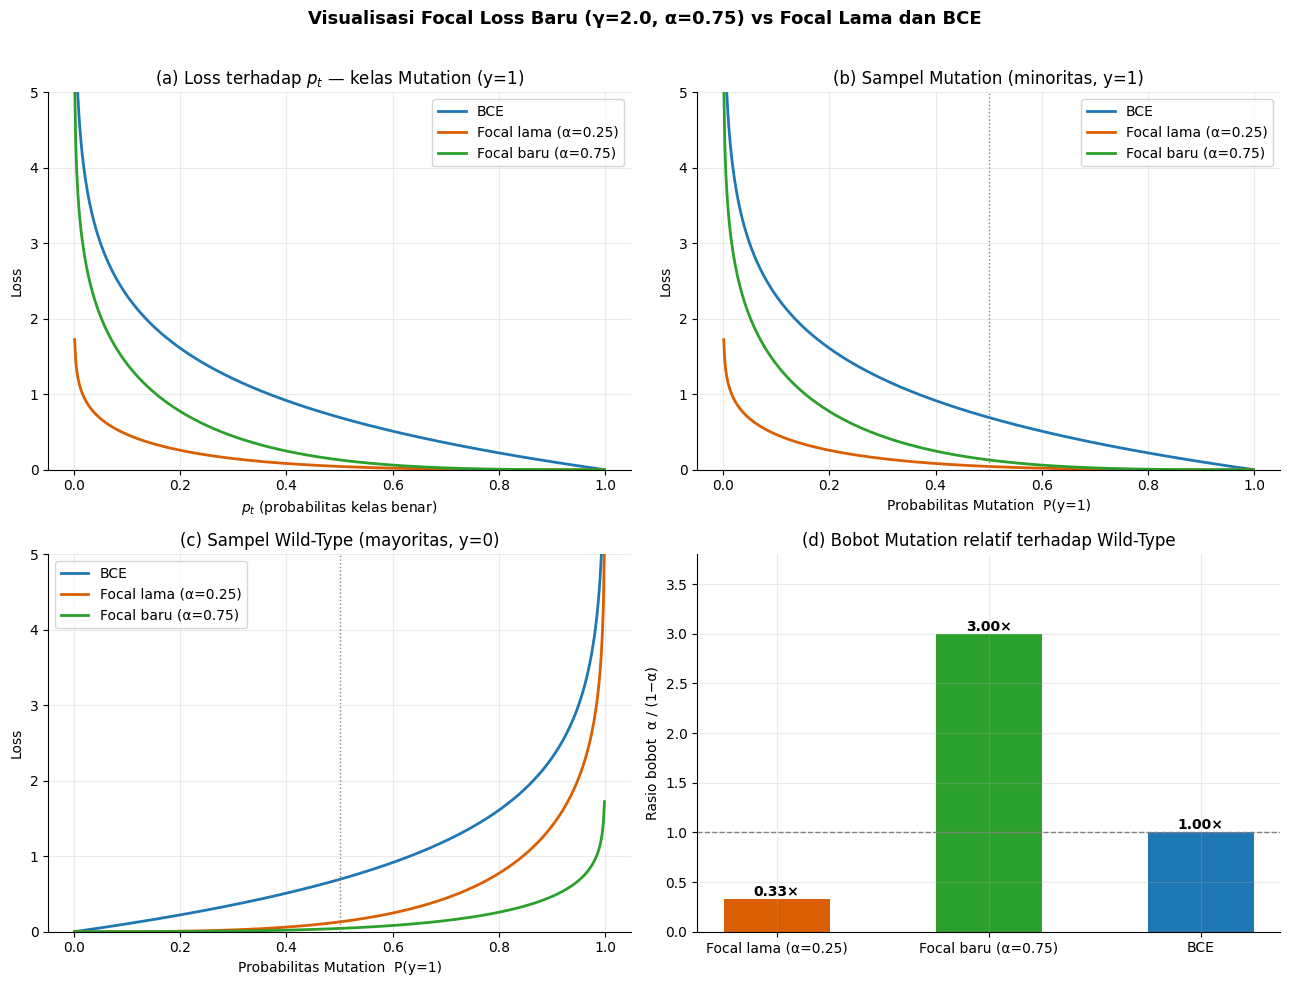

In [ ]:
# ================================================================
# VISUALISASI FOCAL LOSS BARU (alpha=0.75, gamma=2) vs BCE & FOCAL LAMA (alpha=0.25)
# FL = -alpha_t * (1 - p_t)^gamma * log(p_t)
# alpha_t = alpha untuk Mutation (y=1), 1-alpha untuk Wild-Type (y=0)
# Mandiri: tanpa Drive/GPU, rumus identik dengan class FocalLoss di notebook
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

GAMMA = 2.0
ALPHA_OLD, ALPHA_NEW = 0.25, 0.75
DPI = 200

def bce(p, y):
    pt = p if y == 1 else 1 - p
    return -np.log(np.clip(pt, 1e-12, 1))

def focal(p, y, alpha, gamma=GAMMA):
    pt = p if y == 1 else 1 - p
    a_t = alpha if y == 1 else 1 - alpha
    return -a_t * (1 - pt) ** gamma * np.log(np.clip(pt, 1e-12, 1))

p = np.linspace(0.001, 0.999, 500)   # probabilitas prediksi Mutation
C = {"bce": "#1f77b4", "old": "#d95f02", "new": "#2ca02c"}

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

# (a) Loss vs p_t  : pengaruh gamma & alpha pada kelas Mutation
pt = np.linspace(0.001, 0.999, 500)
a = ax[0, 0]
a.plot(pt, -np.log(pt), color=C["bce"], lw=2, label="BCE")
a.plot(pt, -ALPHA_OLD * (1 - pt) ** GAMMA * np.log(pt), color=C["old"], lw=2,
       label=f"Focal lama (α={ALPHA_OLD})")
a.plot(pt, -ALPHA_NEW * (1 - pt) ** GAMMA * np.log(pt), color=C["new"], lw=2,
       label=f"Focal baru (α={ALPHA_NEW})")
a.set_xlabel("$p_t$ (probabilitas kelas benar)"); a.set_ylabel("Loss")
a.set_title("(a) Loss terhadap $p_t$ — kelas Mutation (y=1)")
a.set_ylim(0, 5); a.legend()

# (b) Loss kelas Mutation vs probabilitas Mutation
a = ax[0, 1]
a.plot(p, [bce(x, 1) for x in p], color=C["bce"], lw=2, label="BCE")
a.plot(p, [focal(x, 1, ALPHA_OLD) for x in p], color=C["old"], lw=2, label=f"Focal lama (α={ALPHA_OLD})")
a.plot(p, [focal(x, 1, ALPHA_NEW) for x in p], color=C["new"], lw=2, label=f"Focal baru (α={ALPHA_NEW})")
a.axvline(0.5, color="gray", ls=":", lw=1)
a.set_xlabel("Probabilitas Mutation  P(y=1)"); a.set_ylabel("Loss")
a.set_title("(b) Sampel Mutation (minoritas, y=1)")
a.set_ylim(0, 5); a.legend()

# (c) Loss kelas Wild-Type vs probabilitas Mutation
a = ax[1, 0]
a.plot(p, [bce(x, 0) for x in p], color=C["bce"], lw=2, label="BCE")
a.plot(p, [focal(x, 0, ALPHA_OLD) for x in p], color=C["old"], lw=2, label=f"Focal lama (α={ALPHA_OLD})")
a.plot(p, [focal(x, 0, ALPHA_NEW) for x in p], color=C["new"], lw=2, label=f"Focal baru (α={ALPHA_NEW})")
a.axvline(0.5, color="gray", ls=":", lw=1)
a.set_xlabel("Probabilitas Mutation  P(y=1)"); a.set_ylabel("Loss")
a.set_title("(c) Sampel Wild-Type (mayoritas, y=0)")
a.set_ylim(0, 5); a.legend()

# (d) Rasio bobot Mutation : Wild-Type pada tingkat kesalahan (p_t) yang sama
a = ax[1, 1]
for alpha, key, lab in [(ALPHA_OLD, "old", f"Focal lama (α={ALPHA_OLD})"),
                        (ALPHA_NEW, "new", f"Focal baru (α={ALPHA_NEW})")]:
    ratio = alpha / (1 - alpha)
    a.bar(lab, ratio, color=C[key], width=0.5)
    a.text(lab, ratio, f"{ratio:.2f}×", ha="center", va="bottom", fontweight="bold")
a.bar("BCE", 1.0, color=C["bce"], width=0.5)
a.text("BCE", 1.0, "1.00×", ha="center", va="bottom", fontweight="bold")
a.axhline(1, color="gray", ls="--", lw=1)
a.set_ylabel("Rasio bobot  α / (1−α)")
a.set_title("(d) Bobot Mutation relatif terhadap Wild-Type")
a.set_ylim(0, 3.8)

fig.suptitle(f"Visualisasi Focal Loss Baru (γ={GAMMA}, α={ALPHA_NEW}) vs Focal Lama dan BCE",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("visualisasi_focal_loss_baru.png", dpi=DPI, bbox_inches="tight")
plt.show()

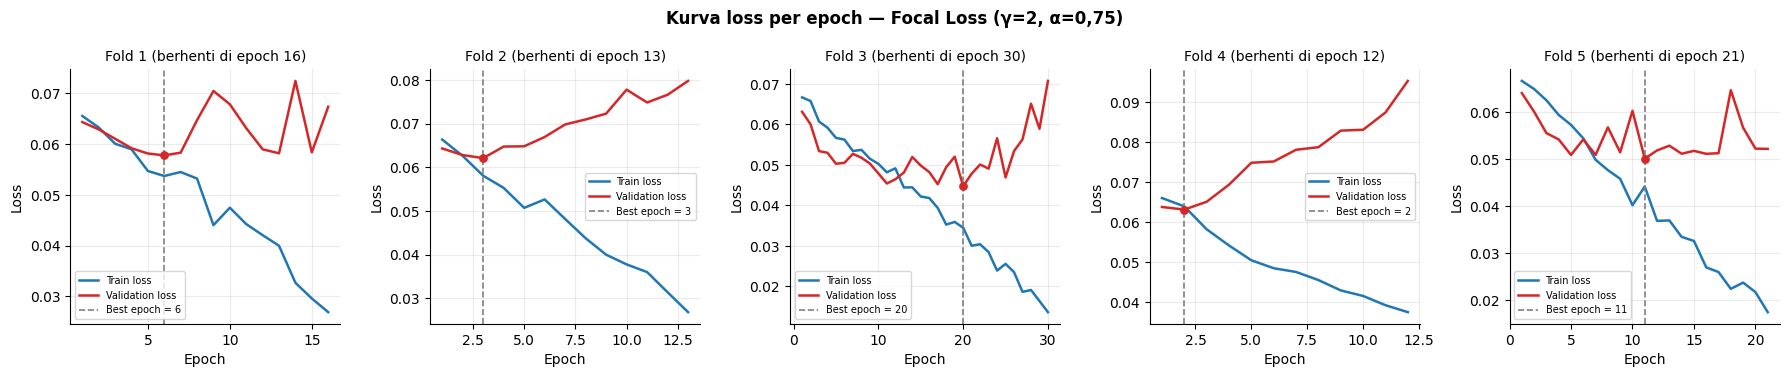

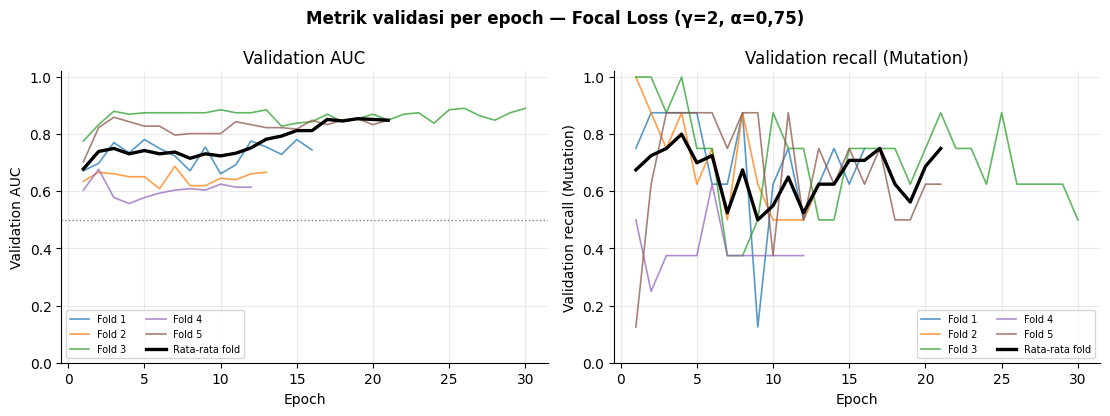


RINGKASAN EPOCH — Focal Loss (γ=2, α=0,75)
 fold  epoch_total  best_epoch  train_loss@best  val_loss@best  train_loss@akhir  val_loss@akhir
    1           16           6           0.0537         0.0577            0.0269          0.0673
    2           13           3           0.0581         0.0621            0.0268          0.0798
    3           30          20           0.0344         0.0447            0.0136          0.0707
    4           12           2           0.0639         0.0631            0.0374          0.0953
    5           21          11           0.0441         0.0501            0.0174          0.0522

Tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Gambar_Kurva_Epoch


In [ ]:
# ================================================================
# KURVA PER EPOCH — FOCAL LOSS BARU (gamma=2, alpha=0.75), 5-Fold CV
# (a) Train vs validation loss per fold (garis putus = best epoch)
# (b) Validation AUC & recall per epoch (semua fold + rata-rata)
# Sumber: fold_k/training_history.csv di Drive (tanpa GPU, tanpa training ulang)
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
RUN_DIR = f"{BASE_DIR}/Skenario Uji/ABMIL_FOCAL_a075_50ep"
OUT_ROOT = f"{BASE_DIR}/Skenario Uji/Gambar_Kurva_Epoch"
N_FOLDS, DPI = 5, 200
os.makedirs(OUT_ROOT, exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
FOLD_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b"]

fm = pd.read_csv(os.path.join(RUN_DIR, "fold_metrics.csv")).set_index("fold")
H = {}
for k in range(1, N_FOLDS + 1):
    p = os.path.join(RUN_DIR, f"fold_{k}", "training_history.csv")
    if os.path.isfile(p):
        H[k] = pd.read_csv(p)
    else:
        print(f"Fold {k}: training_history.csv tidak ditemukan -> dilewati")
if not H:
    raise FileNotFoundError(f"Tidak ada training_history.csv di {RUN_DIR}")

def best_epoch(k, h):
    return int(fm.loc[k, "best_epoch"]) if k in fm.index else int(h.loc[h["val_loss"].idxmin(), "epoch"])

# ---------- (a) Train vs validation loss per fold ----------
fig, axes = plt.subplots(1, len(H), figsize=(3.6 * len(H), 3.8))
axes = np.atleast_1d(axes)
for ax, (k, h) in zip(axes, H.items()):
    be = best_epoch(k, h)
    ax.plot(h["epoch"], h["train_loss"], color="#1f77b4", lw=1.8, label="Train loss")
    ax.plot(h["epoch"], h["val_loss"], color="#d62728", lw=1.8, label="Validation loss")
    ax.axvline(be, color="gray", ls="--", lw=1.2, label=f"Best epoch = {be}")
    ax.scatter([be], [h.loc[h["epoch"] == be, "val_loss"].iloc[0]], color="#d62728", zorder=5, s=28)
    ax.set_title(f"Fold {k} (berhenti di epoch {int(h['epoch'].max())})", fontsize=10)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend(fontsize=7)
fig.suptitle("Kurva loss per epoch — Focal Loss (γ=2, α=0,75)", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(OUT_ROOT, "loss_per_epoch_focal_a075.png"), dpi=DPI, bbox_inches="tight")
plt.show()

# ---------- (b) Validation AUC & recall per epoch ----------
LABEL = {"val_auc": "Validation AUC", "val_recall": "Validation recall (Mutation)"}
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
for ax, c in zip(axes, LABEL):
    for k, h in H.items():
        ax.plot(h["epoch"], h[c], color=FOLD_COLORS[(k - 1) % 5], lw=1.2, alpha=0.75, label=f"Fold {k}")
    mx = max(len(h) for h in H.values())
    M = np.full((len(H), mx), np.nan)
    for i, h in enumerate(H.values()):
        M[i, :len(h)] = h[c].values
    n_ok = np.sum(~np.isnan(M), axis=0)
    mean = np.where(n_ok >= 2, np.nanmean(M, axis=0), np.nan)   # rata-rata hanya jika >=2 fold masih berjalan
    ax.plot(np.arange(1, mx + 1), mean, color="black", lw=2.4, label="Rata-rata fold")
    if c == "val_auc":
        ax.axhline(0.5, color="gray", ls=":", lw=1)
    ax.set_xlabel("Epoch"); ax.set_ylabel(LABEL[c]); ax.set_ylim(0, 1.02)
    ax.set_title(LABEL[c]); ax.legend(fontsize=7, ncol=2)
fig.suptitle("Metrik validasi per epoch — Focal Loss (γ=2, α=0,75)", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(OUT_ROOT, "metrik_val_per_epoch_focal_a075.png"), dpi=DPI, bbox_inches="tight")
plt.show()

# ---------- Ringkasan angka ----------
rows = []
for k, h in H.items():
    be = best_epoch(k, h); r = h[h["epoch"] == be].iloc[0]
    rows.append({"fold": k, "epoch_total": int(h["epoch"].max()), "best_epoch": be,
                 "train_loss@best": r["train_loss"], "val_loss@best": r["val_loss"],
                 "train_loss@akhir": h["train_loss"].iloc[-1], "val_loss@akhir": h["val_loss"].iloc[-1]})
summ = pd.DataFrame(rows)
summ.to_csv(os.path.join(OUT_ROOT, "ringkasan_epoch_focal_a075.csv"), index=False)
print("\nRINGKASAN EPOCH — Focal Loss (γ=2, α=0,75)")
print(summ.round(4).to_string(index=False))
print("\nTersimpan di:", OUT_ROOT)

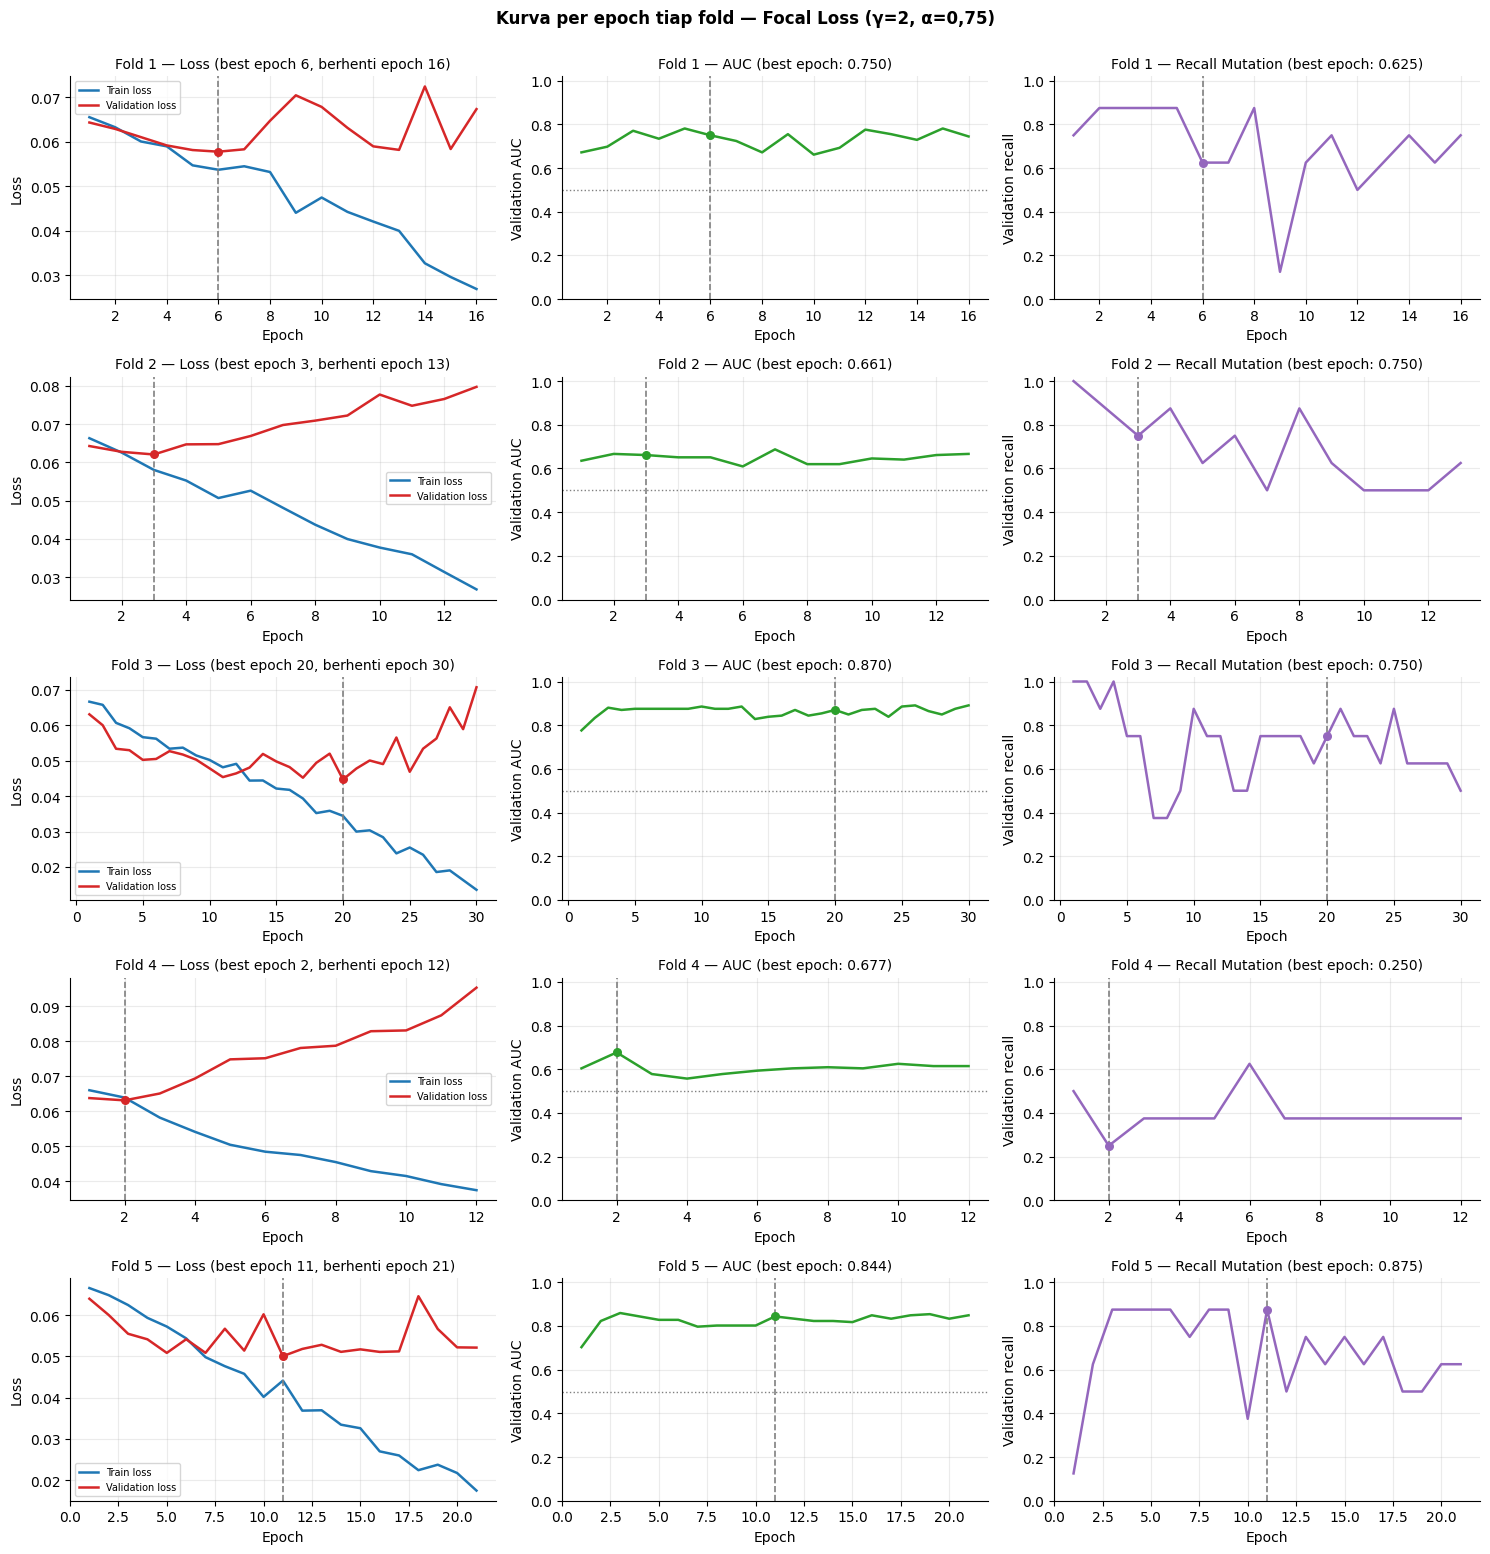

RINGKASAN PER FOLD — Focal Loss (γ=2, α=0,75)
 fold  epoch_total  best_epoch  train_loss@best  val_loss@best  val_auc@best  val_recall@best  train_loss@akhir  val_loss@akhir
    1           16           6           0.0537         0.0577        0.7500            0.625            0.0269          0.0673
    2           13           3           0.0581         0.0621        0.6615            0.750            0.0268          0.0798
    3           30          20           0.0344         0.0447        0.8698            0.750            0.0136          0.0707
    4           12           2           0.0639         0.0631        0.6771            0.250            0.0374          0.0953
    5           21          11           0.0441         0.0501        0.8438            0.875            0.0174          0.0522

Tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Gambar_Kurva_Epoch


In [ ]:
# ================================================================
# KURVA PER EPOCH, DIPISAH PER FOLD — FOCAL LOSS BARU (gamma=2, alpha=0.75)
# Tiap fold = 1 baris gambar: (1) train vs validation loss, (2) validation AUC,
# (3) validation recall Mutation. Garis putus = best epoch (val loss terendah).
# Output: 1 gambar gabungan 5 fold + 1 gambar terpisah untuk tiap fold.
# Sumber: fold_k/training_history.csv di Drive (tanpa GPU, tanpa training ulang)
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
RUN_DIR = f"{BASE_DIR}/Skenario Uji/ABMIL_FOCAL_a075_50ep"
OUT_ROOT = f"{BASE_DIR}/Skenario Uji/Gambar_Kurva_Epoch"
N_FOLDS, DPI = 5, 200
os.makedirs(OUT_ROOT, exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

fm = pd.read_csv(os.path.join(RUN_DIR, "fold_metrics.csv")).set_index("fold")
H = {}
for k in range(1, N_FOLDS + 1):
    p = os.path.join(RUN_DIR, f"fold_{k}", "training_history.csv")
    if os.path.isfile(p):
        H[k] = pd.read_csv(p)
    else:
        print(f"Fold {k}: training_history.csv tidak ditemukan -> dilewati")
if not H:
    raise FileNotFoundError(f"Tidak ada training_history.csv di {RUN_DIR}")

def best_epoch(k, h):
    return int(fm.loc[k, "best_epoch"]) if k in fm.index else int(h.loc[h["val_loss"].idxmin(), "epoch"])

def draw_fold(axs, k, h):
    be = best_epoch(k, h)
    r = h[h["epoch"] == be].iloc[0]
    # (1) loss
    ax = axs[0]
    ax.plot(h["epoch"], h["train_loss"], color="#1f77b4", lw=1.8, label="Train loss")
    ax.plot(h["epoch"], h["val_loss"], color="#d62728", lw=1.8, label="Validation loss")
    ax.scatter([be], [r["val_loss"]], color="#d62728", zorder=5, s=30)
    ax.set_ylabel("Loss"); ax.set_title(f"Fold {k} — Loss (best epoch {be}, berhenti epoch {int(h['epoch'].max())})", fontsize=10)
    # (2) AUC
    ax = axs[1]
    ax.plot(h["epoch"], h["val_auc"], color="#2ca02c", lw=1.8)
    ax.scatter([be], [r["val_auc"]], color="#2ca02c", zorder=5, s=30)
    ax.axhline(0.5, color="gray", ls=":", lw=1)
    ax.set_ylim(0, 1.02); ax.set_ylabel("Validation AUC")
    ax.set_title(f"Fold {k} — AUC (best epoch: {r['val_auc']:.3f})", fontsize=10)
    # (3) recall
    ax = axs[2]
    ax.plot(h["epoch"], h["val_recall"], color="#9467bd", lw=1.8)
    ax.scatter([be], [r["val_recall"]], color="#9467bd", zorder=5, s=30)
    ax.set_ylim(0, 1.02); ax.set_ylabel("Validation recall")
    ax.set_title(f"Fold {k} — Recall Mutation (best epoch: {r['val_recall']:.3f})", fontsize=10)
    for ax in axs:
        ax.axvline(be, color="gray", ls="--", lw=1.2)
        ax.set_xlabel("Epoch")
    axs[0].legend(fontsize=7)

# ---------- gambar gabungan (1 baris per fold) ----------
fig, axes = plt.subplots(len(H), 3, figsize=(15, 3.1 * len(H)), squeeze=False)
for row, (k, h) in zip(axes, H.items()):
    draw_fold(row, k, h)
fig.suptitle("Kurva per epoch tiap fold — Focal Loss (γ=2, α=0,75)", fontweight="bold", y=1.0)
fig.tight_layout()
fig.savefig(os.path.join(OUT_ROOT, "per_epoch_semua_fold_focal_a075.png"), dpi=DPI, bbox_inches="tight")
plt.show()

# ---------- gambar terpisah per fold ----------
for k, h in H.items():
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
    draw_fold(axs, k, h)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_ROOT, f"per_epoch_fold{k}_focal_a075.png"), dpi=DPI, bbox_inches="tight")
    plt.close(fig)

# ---------- ringkasan angka per fold ----------
rows = []
for k, h in H.items():
    be = best_epoch(k, h); r = h[h["epoch"] == be].iloc[0]
    rows.append({"fold": k, "epoch_total": int(h["epoch"].max()), "best_epoch": be,
                 "train_loss@best": r["train_loss"], "val_loss@best": r["val_loss"],
                 "val_auc@best": r["val_auc"], "val_recall@best": r["val_recall"],
                 "train_loss@akhir": h["train_loss"].iloc[-1], "val_loss@akhir": h["val_loss"].iloc[-1]})
summ = pd.DataFrame(rows)
summ.to_csv(os.path.join(OUT_ROOT, "ringkasan_epoch_per_fold_focal_a075.csv"), index=False)
print("RINGKASAN PER FOLD — Focal Loss (γ=2, α=0,75)")
print(summ.round(4).to_string(index=False))
print("\nTersimpan di:", OUT_ROOT)

VISUALISASI FOCAL LOSS BARU
Gamma     : 2.0
Alpha     : 0.75
Threshold : 0.5
Pasien    : 160
Mutation  : 40
Wild-Type : 120


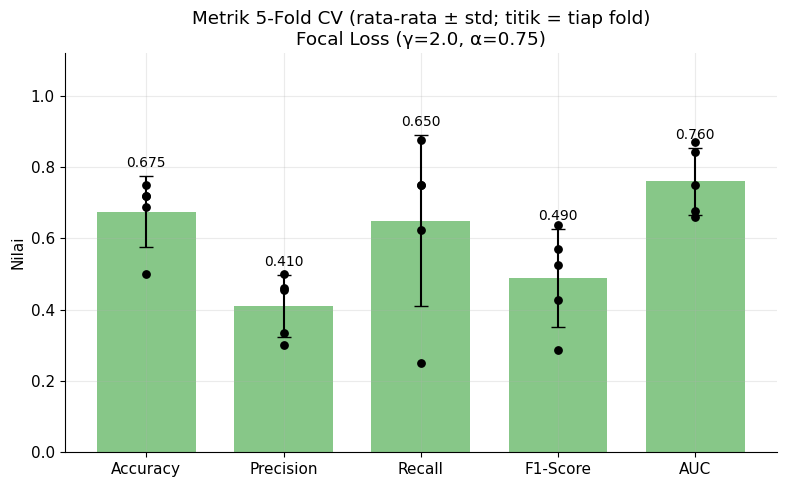

Tersimpan: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Visualisasi_FOCAL_a075/FOCAL_a075_1_metrik_5fold.png


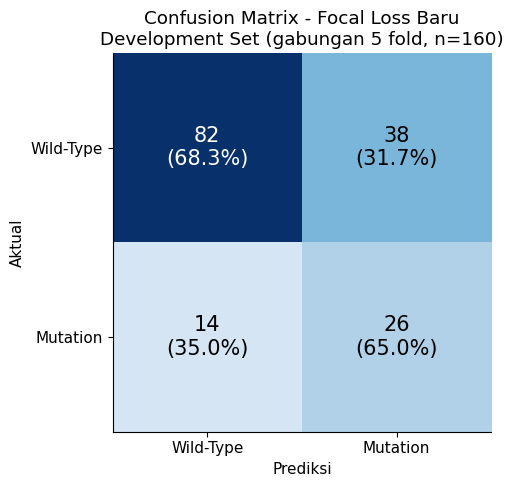

Tersimpan: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Visualisasi_FOCAL_a075/FOCAL_a075_2_confusion_matrix.png

Confusion Matrix:
[[82 38]
 [14 26]]


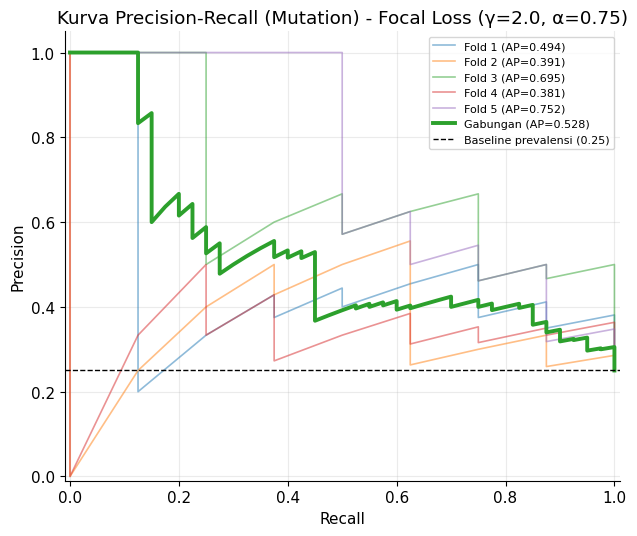

Tersimpan: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Visualisasi_FOCAL_a075/FOCAL_a075_3_precision_recall.png


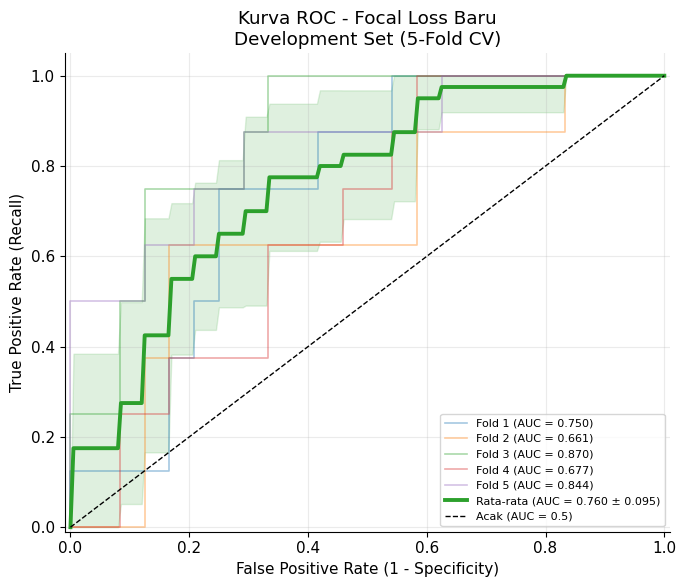

Tersimpan: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Visualisasi_FOCAL_a075/FOCAL_a075_4_roc_auc.png

RINGKASAN METRIK FOCAL LOSS BARU
Accuracy    : 0.675 ± 0.100
Precision   : 0.410 ± 0.088
Recall      : 0.650 ± 0.240
F1-Score    : 0.490 ± 0.137
AUC         : 0.760 ± 0.095

Pooled AUC : 0.749
Average Precision (AP): 0.528

Seluruh visualisasi berhasil dibuat.
Lokasi penyimpanan: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Visualisasi_FOCAL_a075


In [ ]:

# ================================================================
# VISUALISASI FOCAL LOSS BARU (GAMMA=2, ALPHA=0.75)
# Development Set - Stratified 5-Fold Cross-Validation
#
# 1. Metrik 5-Fold CV (Mean +/- Std)
# 2. Confusion Matrix (gabungan 5 fold / OOF)
# 3. Precision-Recall Curve (Mutation)
# 4. ROC Curve (5-Fold CV)
#
# Tidak membutuhkan GPU dan tidak melakukan training ulang.
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# ================================================================
# 1. KONFIGURASI
# ================================================================

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"

# Folder hasil Focal Loss baru (alpha=0.75)
FOCAL_DIR = f"{SCEN_ROOT}/ABMIL_FOCAL_a075_50ep"

# Folder penyimpanan visualisasi
OUT_DIR = f"{SCEN_ROOT}/Visualisasi_FOCAL_a075"

os.makedirs(OUT_DIR, exist_ok=True)

ALPHA = 0.75
GAMMA = 2.0
THRESHOLD = 0.5

CLASS_NAMES = ["Wild-Type", "Mutation"]

METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc"
]

METRIC_LABELS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC"
]

COLOR = "#2ca02c"
DPI = 200

plt.rcParams.update({
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ================================================================
# 2. MEMUAT HASIL 5-FOLD CV
# ================================================================

METRIC_PATH = os.path.join(
    FOCAL_DIR, "fold_metrics.csv"
)

PRED_PATH = os.path.join(
    FOCAL_DIR, "all_validation_predictions.csv"
)

if not os.path.isfile(METRIC_PATH):
    raise FileNotFoundError(
        f"fold_metrics.csv tidak ditemukan: {METRIC_PATH}"
    )

if not os.path.isfile(PRED_PATH):
    raise FileNotFoundError(
        f"all_validation_predictions.csv tidak ditemukan: {PRED_PATH}"
    )

fm = pd.read_csv(METRIC_PATH)
pred = pd.read_csv(PRED_PATH)

# Validasi kolom
required_metrics = ["fold"] + METRICS
required_predictions = [
    "patient_id", "label", "prob_mutation", "fold"
]

assert all(c in fm.columns for c in required_metrics), \
    "Kolom fold_metrics.csv tidak lengkap."

assert all(c in pred.columns for c in required_predictions), \
    "Kolom all_validation_predictions.csv tidak lengkap."

fm = fm.sort_values("fold").reset_index(drop=True)
pred = pred.sort_values(["fold", "patient_id"]).reset_index(drop=True)

assert sorted(fm["fold"].tolist()) == [1, 2, 3, 4, 5], \
    "Data harus memiliki 5 fold lengkap."

assert set(pred["label"].unique()).issubset({0, 1}), \
    "Label harus 0=Wild-Type dan 1=Mutation."

assert not pred["patient_id"].duplicated().any(), \
    "Terdapat patient_id duplikat pada prediksi OOF."

assert len(pred) == 160, \
    f"Jumlah pasien OOF seharusnya 160, ditemukan {len(pred)}."

assert set(pred["fold"].unique()) == {1, 2, 3, 4, 5}, \
    "Prediksi harus mencakup seluruh fold."

y = pred["label"].values.astype(int)
prob = pred["prob_mutation"].values.astype(float)
y_pred = (prob >= THRESHOLD).astype(int)

print("=" * 65)
print("VISUALISASI FOCAL LOSS BARU")
print(f"Gamma     : {GAMMA}")
print(f"Alpha     : {ALPHA}")
print(f"Threshold : {THRESHOLD}")
print(f"Pasien    : {len(pred)}")
print(f"Mutation  : {(y == 1).sum()}")
print(f"Wild-Type : {(y == 0).sum()}")
print("=" * 65)

# ================================================================
# FUNGSI SIMPAN GAMBAR
# ================================================================

def save_plot(fig, filename):
    path = os.path.join(OUT_DIR, filename)
    fig.savefig(
        path,
        dpi=DPI,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
    print("Tersimpan:", path)


# ================================================================
# 3. VISUALISASI METRIK 5-FOLD CV
# ================================================================

fig, ax = plt.subplots(figsize=(8, 5))

for i, metric in enumerate(METRICS):

    values = fm[metric].values.astype(float)

    mean = np.mean(values)
    std = np.std(values, ddof=1)

    # Bar rata-rata dan standar deviasi
    ax.bar(
        i,
        mean,
        yerr=std,
        capsize=5,
        color="#72bd73",
        alpha=0.85,
        width=0.72
    )

    # Titik setiap fold
    ax.scatter(
        np.full(len(values), i),
        values,
        color="black",
        s=28,
        zorder=3
    )

    # Label nilai rata-rata
    ax.text(
        i,
        min(mean + std + 0.025, 1.08),
        f"{mean:.3f}",
        ha="center",
        fontsize=10
    )

ax.set_xticks(range(len(METRICS)))
ax.set_xticklabels(METRIC_LABELS)

ax.set_ylim(0, 1.12)
ax.set_ylabel("Nilai")

ax.set_title(
    f"Metrik 5-Fold CV (rata-rata ± std; titik = tiap fold)\n"
    f"Focal Loss (γ={GAMMA}, α={ALPHA})"
)

fig.tight_layout()

save_plot(
    fig,
    "FOCAL_a075_1_metrik_5fold.png"
)


# ================================================================
# 4. VISUALISASI CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y,
    y_pred,
    labels=[0, 1]
)

row_sum = cm.sum(axis=1, keepdims=True)

pct = np.divide(
    cm,
    row_sum,
    out=np.zeros_like(cm, dtype=float),
    where=row_sum != 0
) * 100

fig, ax = plt.subplots(figsize=(6, 5))

ax.imshow(
    cm,
    cmap="Blues",
    vmin=0,
    vmax=max(cm.max(), 1)
)

for i in range(2):
    for j in range(2):

        ax.text(
            j,
            i,
            f"{cm[i, j]}\n({pct[i, j]:.1f}%)",
            ha="center",
            va="center",
            fontsize=15,
            color=(
                "white"
                if cm[i, j] > cm.max() / 2
                else "black"
            )
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(CLASS_NAMES)
ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")

ax.set_title(
    "Confusion Matrix - Focal Loss Baru\n"
    f"Development Set (gabungan 5 fold, n={len(y)})"
)

ax.grid(False)

fig.tight_layout()

save_plot(
    fig,
    "FOCAL_a075_2_confusion_matrix.png"
)

print("\nConfusion Matrix:")
print(cm)


# ================================================================
# 5. VISUALISASI PRECISION-RECALL CURVE
# ================================================================

fig, ax = plt.subplots(figsize=(6.5, 5.5))

# Kurva setiap fold
for fold, group in pred.groupby("fold"):

    fpr_pr, recall_pr, _ = precision_recall_curve(
        group["label"],
        group["prob_mutation"]
    )

    ap_fold = average_precision_score(
        group["label"],
        group["prob_mutation"]
    )

    ax.plot(
        recall_pr,
        fpr_pr,
        linewidth=1.2,
        alpha=0.5,
        label=f"Fold {fold} (AP={ap_fold:.3f})"
    )

# Kurva gabungan OOF
precision_all, recall_all, _ = precision_recall_curve(
    y,
    prob
)

ap_all = average_precision_score(y, prob)

ax.plot(
    recall_all,
    precision_all,
    color="#2ca02c",
    linewidth=2.8,
    label=f"Gabungan (AP={ap_all:.3f})"
)

# Baseline prevalensi kelas Mutation
baseline = np.mean(y)

ax.axhline(
    baseline,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Baseline prevalensi ({baseline:.2f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.05)

ax.set_title(
    "Kurva Precision-Recall (Mutation) - "
    f"Focal Loss (γ={GAMMA}, α={ALPHA})"
)

ax.legend(
    loc="upper right",
    fontsize=8
)

fig.tight_layout()

save_plot(
    fig,
    "FOCAL_a075_3_precision_recall.png"
)


# ================================================================
# 6. VISUALISASI ROC CURVE 5-FOLD CV
# ================================================================

GRID = np.linspace(0, 1, 201)

fold_tprs = []
fold_aucs = []

fig, ax = plt.subplots(figsize=(7, 6))

for fold, group in pred.groupby("fold"):

    fold_y = group["label"].values.astype(int)
    fold_prob = group["prob_mutation"].values.astype(float)

    fpr, tpr, _ = roc_curve(
        fold_y,
        fold_prob
    )

    auc_value = roc_auc_score(
        fold_y,
        fold_prob
    )

    fold_aucs.append(auc_value)

    # Interpolasi ROC
    interp_tpr = np.interp(
        GRID,
        fpr,
        tpr
    )

    interp_tpr[0] = 0.0

    fold_tprs.append(interp_tpr)

    # Kurva setiap fold
    ax.plot(
        fpr,
        tpr,
        linewidth=1.2,
        alpha=0.4,
        label=f"Fold {fold} (AUC = {auc_value:.3f})"
    )

# Rata-rata ROC
fold_tprs = np.array(fold_tprs)
fold_aucs = np.array(fold_aucs)

mean_tpr = fold_tprs.mean(axis=0)
mean_tpr[-1] = 1.0

std_tpr = fold_tprs.std(
    axis=0,
    ddof=1
)

mean_auc = fold_aucs.mean()
std_auc = fold_aucs.std(ddof=1)

ax.plot(
    GRID,
    mean_tpr,
    color="#2ca02c",
    linewidth=2.8,
    label=(
        f"Rata-rata (AUC = "
        f"{mean_auc:.3f} ± {std_auc:.3f})"
    )
)

# Area standar deviasi
ax.fill_between(
    GRID,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color="#2ca02c",
    alpha=0.15
)

# Garis baseline acak
ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1,
    label="Acak (AUC = 0.5)"
)

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.05)

ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")

ax.set_title(
    "Kurva ROC - Focal Loss Baru\n"
    "Development Set (5-Fold CV)"
)

ax.legend(
    loc="lower right",
    fontsize=8
)

fig.tight_layout()

save_plot(
    fig,
    "FOCAL_a075_4_roc_auc.png"
)


# ================================================================
# 7. RINGKASAN HASIL
# ================================================================

print("\n" + "=" * 65)
print("RINGKASAN METRIK FOCAL LOSS BARU")
print("=" * 65)

for metric, label in zip(METRICS, METRIC_LABELS):

    mean = fm[metric].mean()
    std = fm[metric].std(ddof=1)

    print(
        f"{label:<12}: {mean:.3f} ± {std:.3f}"
    )

print(f"\nPooled AUC : {roc_auc_score(y, prob):.3f}")
print(f"Average Precision (AP): {ap_all:.3f}")

print("\nSeluruh visualisasi berhasil dibuat.")
print("Lokasi penyimpanan:", OUT_DIR)


BCE                      <- ABMIL_BCE_50ep_20261025_213711 | 5 fold | 160 pasien OOF
CWCE                     <- ABMIL_CWCE_50ep | 5 fold | 160 pasien OOF
Focal Loss (α = 0,25)    <- ABMIL_FOCAL_50ep | 5 fold | 160 pasien OOF
Focal Loss (α = 0,75)    <- ABMIL_FOCAL_a075_50ep | 5 fold | 160 pasien OOF

TABEL 6 — Metrik validasi tiap fold, Focal Loss (α = 0,75)
       Fold Best epoch      Accuracy     Precision        Recall      F1-Score           AUC
          1          6         0,719         0,455         0,625         0,526         0,750
          2          3         0,500         0,300         0,750         0,429         0,661
          3         20         0,719         0,462         0,750         0,571         0,870
          4          2         0,688         0,333         0,250         0,286         0,677
          5         11         0,750         0,500         0,875         0,636         0,844
Rerata ± SD        8,4 0,675 ± 0,100 0,410 ± 0,088 0,650 ± 0,240 0,490 ± 0,137 0

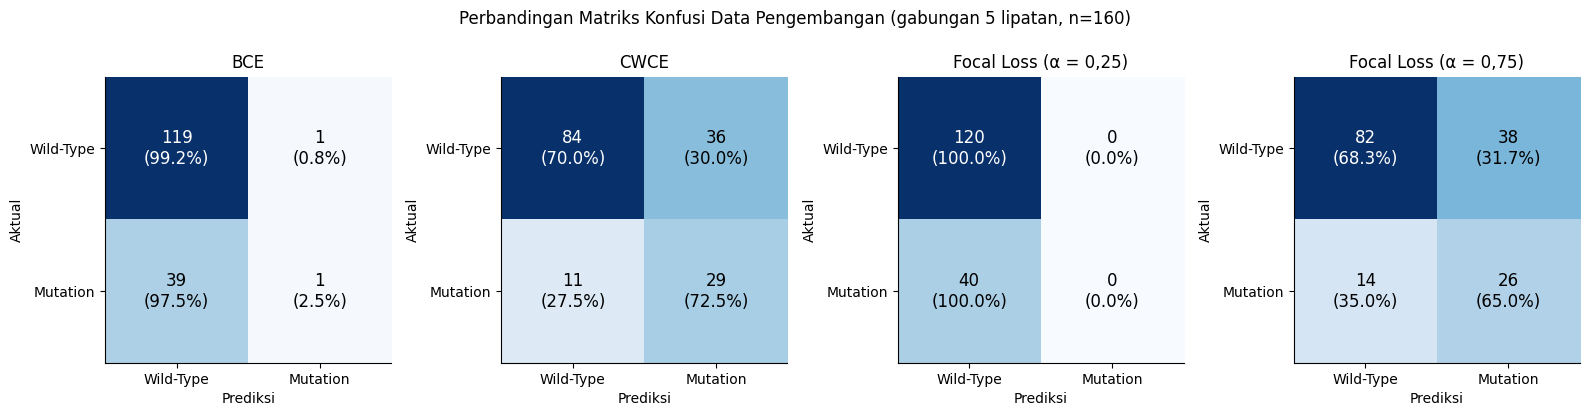

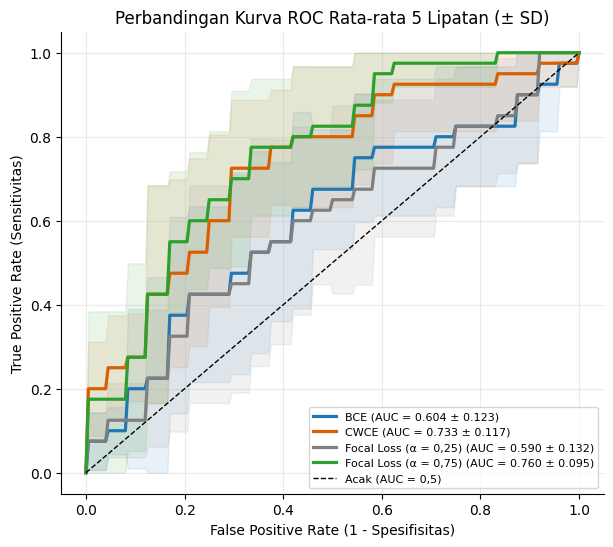

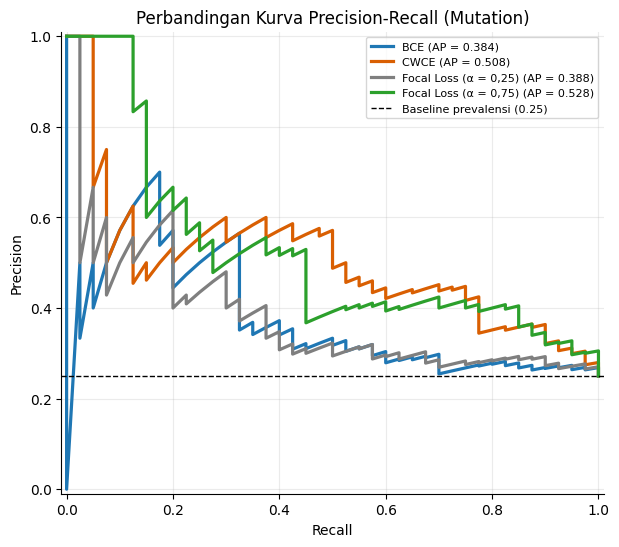

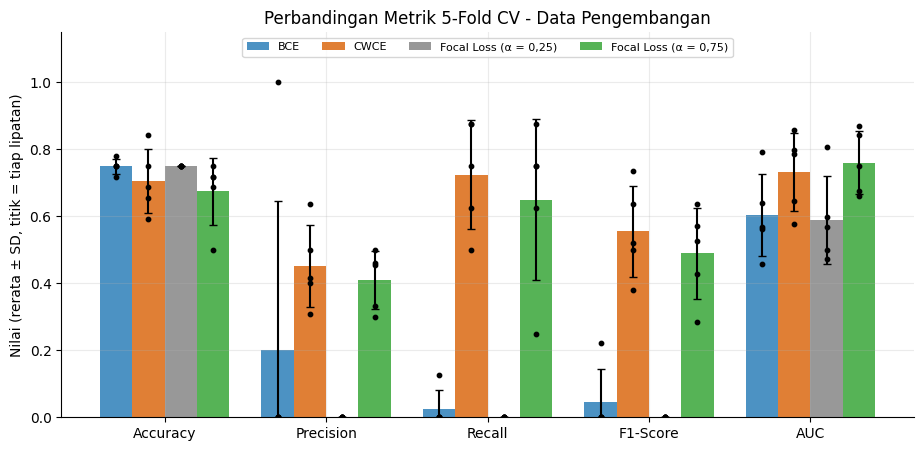

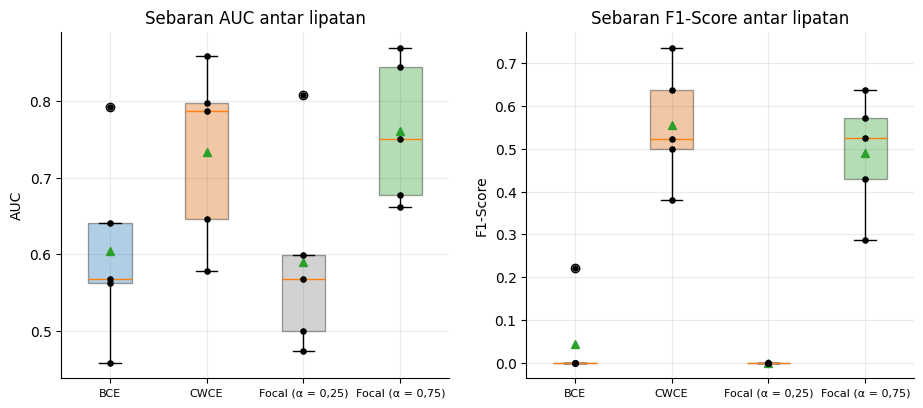


Semua gambar dan tabel tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Gambar_Perbandingan_4Skenario


In [ ]:
# ================================================================
# CELL LANJUTAN — (A) TABEL METRIK PER FOLD FOCAL α=0,75 (Accuracy, Precision, F1)
#                 (B) GAMBAR PERBANDINGAN 4 SKENARIO (Gambar 22-26 di laporan)
# Tanpa GPU dan tanpa training ulang: hanya membaca hasil CV yang sudah ada di Drive.
# Accuracy, Precision, dan F1 per fold SUDAH dihitung oleh kode CV Anda dan tersimpan
# di fold_metrics.csv; cell ini hanya menampilkannya per fold.
# ================================================================
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"
OUT_ROOT = f"{SCEN_ROOT}/Gambar_Perbandingan_4Skenario"
os.makedirs(OUT_ROOT, exist_ok=True)

# Folder hasil CV tiap skenario (isi manual bila nama folder Anda berbeda)
RUN_DIRS = {
    "BCE":      sorted(Path(SCEN_ROOT).glob("ABMIL_BCE_50ep*"))[-1:],
    "CWCE":     [Path(SCEN_ROOT) / "ABMIL_CWCE_50ep"],
    "FOCAL025": [Path(SCEN_ROOT) / "ABMIL_FOCAL_50ep"],
    "FOCAL075": [Path(SCEN_ROOT) / "ABMIL_FOCAL_a075_50ep"],
}
LABEL = {"BCE": "BCE", "CWCE": "CWCE", "FOCAL025": "Focal Loss (α = 0,25)", "FOCAL075": "Focal Loss (α = 0,75)"}
COLOR = {"BCE": "#1f77b4", "CWCE": "#d95f02", "FOCAL025": "#7f7f7f", "FOCAL075": "#2ca02c"}
METRICS = ["accuracy", "precision", "recall", "f1", "auc"]
MLAB = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1-Score", "auc": "AUC"}
CLASS_NAMES = ["Wild-Type", "Mutation"]
THRESHOLD, DPI = 0.5, 200
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

def c(x, nd=3):
    """Format angka berkoma desimal (gaya laporan)."""
    return "tidak terdefinisi" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{nd}f}".replace(".", ",")

DATA = {}
for k, cands in RUN_DIRS.items():
    d = next((p for p in cands if (p / "fold_metrics.csv").exists()), None)
    if d is None:
        raise FileNotFoundError(f"fold_metrics.csv skenario {LABEL[k]} tidak ditemukan di {cands}. "
                                "Pastikan cell Perbaikan Review (α=0,5 dan 0,75) sudah selesai.")
    fm = pd.read_csv(d / "fold_metrics.csv").sort_values("fold").reset_index(drop=True)
    pr = pd.read_csv(d / "all_validation_predictions.csv")
    assert not pr["patient_id"].duplicated().any(), f"{k}: patient_id duplikat"
    DATA[k] = {"dir": d, "fm": fm, "pred": pr}
    print(f"{LABEL[k]:24s} <- {d.name} | {len(fm)} fold | {len(pr)} pasien OOF")

# ------------------ (A) TABEL PER FOLD (untuk Tabel 6 laporan) ------------------
print("\n" + "=" * 70)
print("TABEL 6 — Metrik validasi tiap fold, Focal Loss (α = 0,75)")
print("=" * 70)
fm = DATA["FOCAL075"]["fm"]
tab = pd.DataFrame({"Fold": fm["fold"], "Best epoch": fm["best_epoch"]})
for m in METRICS:
    tab[MLAB[m]] = fm[m].map(c)
mean = {"Fold": "Rerata ± SD", "Best epoch": c(fm["best_epoch"].mean(), 1)}
for m in METRICS:
    v = fm[m].astype(float)
    mean[MLAB[m]] = f"{c(v.mean())} ± {c(v.std(ddof=1))}"
tab = pd.concat([tab, pd.DataFrame([mean])], ignore_index=True)
print(tab.to_string(index=False))
tab.to_csv(os.path.join(OUT_ROOT, "tabel6_focal_a075_per_fold.csv"), index=False)
# kolom tambahan bila ada (balanced accuracy, MCC, spesifisitas)
extra = [x for x in ["specificity", "balanced_accuracy", "mcc"] if x in fm.columns]
if extra:
    print("\nKolom tambahan per fold:"); print(fm[["fold"] + extra].round(3).to_string(index=False))

print("\nRingkasan 4 skenario (rerata ± SD, 5 fold) — untuk Tabel 7:")
rows = []
for k in DATA:
    f = DATA[k]["fm"]; r = {"Skenario": LABEL[k]}
    for m in METRICS:
        v = f[m].astype(float); r[MLAB[m]] = f"{c(v.mean())} ± {c(v.std(ddof=1))}"
    rows.append(r)
summ = pd.DataFrame(rows); print(summ.to_string(index=False))
summ.to_csv(os.path.join(OUT_ROOT, "tabel7_ringkasan_4skenario.csv"), index=False)

print("\nConfusion matrix gabungan OOF + AUC/AP gabungan — untuk Tabel 8:")
rows = []
for k in DATA:
    p = DATA[k]["pred"]; y = p["label"].astype(int).values; s = p["prob_mutation"].values
    tn, fp, fn, tp = confusion_matrix(y, (s >= THRESHOLD).astype(int), labels=[0, 1]).ravel()
    rows.append({"Skenario": LABEL[k], "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "AUC gabungan": c(roc_auc_score(y, s)), "AP gabungan": c(average_precision_score(y, s))})
print(pd.DataFrame(rows).to_string(index=False))

def savefig(fig, name):
    fig.savefig(os.path.join(OUT_ROOT, name), dpi=DPI, bbox_inches="tight"); plt.show(); plt.close(fig)

# ------------------ (B) GAMBAR PERBANDINGAN ------------------
KEYS = list(DATA)
GRID = np.linspace(0, 1, 201)

# Gambar 22 — confusion matrix 4 skenario
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, k in zip(axs, KEYS):
    p = DATA[k]["pred"]; cm = confusion_matrix(p["label"].astype(int), (p["prob_mutation"] >= THRESHOLD).astype(int), labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max()); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.1f}%)", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(LABEL[k])
fig.suptitle("Perbandingan Matriks Konfusi Data Pengembangan (gabungan 5 lipatan, n=160)")
fig.tight_layout(); savefig(fig, "G22_perbandingan_matriks_konfusi.png")

# Gambar 23 — ROC rata-rata ± SD
fig, ax = plt.subplots(figsize=(7, 6))
for k in KEYS:
    p = DATA[k]["pred"]; tprs, aucs = [], []
    for f, g in p.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["label"], g["prob_mutation"]); t = np.interp(GRID, fpr, tpr); t[0] = 0; tprs.append(t)
        aucs.append(roc_auc_score(g["label"], g["prob_mutation"]))
    tprs = np.array(tprs); m = tprs.mean(0); m[-1] = 1; sd = tprs.std(0, ddof=1)
    ax.plot(GRID, m, lw=2.3, color=COLOR[k], label=f"{LABEL[k]} (AUC = {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f})")
    ax.fill_between(GRID, np.maximum(m - sd, 0), np.minimum(m + sd, 1), color=COLOR[k], alpha=.10)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Acak (AUC = 0,5)")
ax.set_xlabel("False Positive Rate (1 - Spesifisitas)"); ax.set_ylabel("True Positive Rate (Sensitivitas)")
ax.set_title("Perbandingan Kurva ROC Rata-rata 5 Lipatan (± SD)"); ax.legend(loc="lower right", fontsize=8)
savefig(fig, "G23_perbandingan_roc.png")

# Gambar 24 — Precision-Recall gabungan
fig, ax = plt.subplots(figsize=(7, 6))
prev = None
for k in KEYS:
    p = DATA[k]["pred"]; y = p["label"].astype(int).values; s = p["prob_mutation"].values; prev = y.mean()
    pr_, rc_, _ = precision_recall_curve(y, s)
    ax.plot(rc_, pr_, lw=2.3, color=COLOR[k], label=f"{LABEL[k]} (AP = {average_precision_score(y, s):.3f})")
ax.axhline(prev, color="k", ls="--", lw=1, label=f"Baseline prevalensi ({prev:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(-.01, 1.01); ax.set_ylim(-.01, 1.01)
ax.set_title("Perbandingan Kurva Precision-Recall (Mutation)"); ax.legend(loc="upper right", fontsize=8)
savefig(fig, "G24_perbandingan_precision_recall.png")

# Gambar 25 — metrik 5-fold (rerata ± SD, titik = tiap fold)
fig, ax = plt.subplots(figsize=(11, 5)); w = .2
for i, k in enumerate(KEYS):
    f = DATA[k]["fm"]
    for j, m in enumerate(METRICS):
        v = f[m].astype(float).values; x = j + (i - 1.5) * w
        ax.bar(x, v.mean(), w, yerr=v.std(ddof=1), capsize=3, color=COLOR[k], alpha=.8, label=LABEL[k] if j == 0 else None)
        ax.scatter(np.full(len(v), x), v, color="k", s=10, zorder=3)
ax.set_xticks(range(len(METRICS))); ax.set_xticklabels([MLAB[m] for m in METRICS])
ax.set_ylabel("Nilai (rerata ± SD, titik = tiap lipatan)"); ax.set_ylim(0, 1.15)
ax.set_title("Perbandingan Metrik 5-Fold CV - Data Pengembangan"); ax.legend(ncol=4, loc="upper center", fontsize=8)
savefig(fig, "G25_perbandingan_metrik.png")

# Gambar 26 — boxplot AUC dan F1 antarfold
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, m, tt in zip(axs, ["auc", "f1"], ["Sebaran AUC antar lipatan", "Sebaran F1-Score antar lipatan"]):
    data = [DATA[k]["fm"][m].astype(float).values for k in KEYS]
    bp = ax.boxplot(data, showmeans=True, patch_artist=True)
    ax.set_xticks(range(1, len(KEYS) + 1)); ax.set_xticklabels([LABEL[k].replace("Focal Loss ", "Focal ") for k in KEYS])
    for patch, k in zip(bp["boxes"], KEYS): patch.set_facecolor(COLOR[k]); patch.set_alpha(.35)
    for i, v in enumerate(data, 1): ax.scatter(np.full(len(v), i), v, color="k", s=14, zorder=3)
    ax.set_ylabel(MLAB[m]); ax.set_title(tt); ax.tick_params(axis="x", labelsize=8)
savefig(fig, "G26_sebaran_auc_f1.png")

print("\nSemua gambar dan tabel tersimpan di:", OUT_ROOT)

# Model Selection



In [ ]:
# ================================================================
# MODEL SELECTION & RETRAIN MODEL FINAL (Development Set)
# 1) Bandingkan CE (BCE) / CWCE / Focal Loss berdasarkan RATA-RATA
#    performa 5-Fold CV  -> pilih skenario terbaik
# 2) Retrain model final pada SELURUH Development Set (160 pasien)
# Held-out Test Set TIDAK disentuh di tahap ini.
# Resume: jalankan ulang cell yang sama jika runtime terputus.
# ================================================================

import os, json, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
SPLIT_CSV = (
    f"{BASE_DIR}/Skenario Uji/cv5_splits/"
    "cv5_patient_fold_assignments.csv"
)
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"

# Hasil 5-Fold CV tiap skenario. Folder dicari otomatis (yang terbaru yang
# punya fold_metrics.csv). Isi manual jika ingin menunjuk folder tertentu,
# contoh: {"BCE": f"{SCEN_ROOT}/ABMIL_BCE_50ep_20261020_101500"}
SCENARIO_GLOB = {
    "BCE":   "ABMIL_BCE_50ep*",
    "CWCE":  "ABMIL_CWCE_50ep*",
    "FOCAL": "ABMIL_FOCAL_50ep*",
}
MANUAL_DIRS = {}

# Kriteria pemilihan skenario terbaik (rata-rata 5 fold).
# Urutan prioritas: metrik utama, lalu tie-break berurutan.
SELECTION_METRIC = "auc"
TIEBREAK_METRICS = ["f1", "recall"]
# Selisih rata-rata <= toleransi dianggap seri -> pakai tie-break
TIE_TOLERANCE = 0.0

# Hyperparameter (sama dengan skenario 1-3)
FEAT_DIM = 2048
ATT_DIM = 256
LR = 1e-4
MAX_EPOCHS = 50
THRESHOLD = 0.5
SEED = 42
NUM_CLASSES = 2
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.25

# Jumlah epoch retrain (tanpa validation set -> tidak ada early stopping):
# dipakai rata-rata best_epoch 5 fold dari skenario terpilih.
# Isi angka (mis. 20) untuk menimpa secara manual.
RETRAIN_EPOCHS_OVERRIDE = None

CACHE_DIR = "/content/abmil_resnet50_cache_fp16"
OUT_ROOT = f"{SCEN_ROOT}/Model_Selection_Final"

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_ROOT, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("MODEL SELECTION & RETRAIN FINAL")
print("DEVICE:", DEVICE)
print("OUTPUT:", OUT_ROOT)
print("=" * 60)

assert os.path.isdir(FEATURE_DIR), f"Folder tidak ditemukan: {FEATURE_DIR}"
assert os.path.isfile(SPLIT_CSV), f"CSV tidak ditemukan: {SPLIT_CSV}"

def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

# -------------------- 2. PEMILIHAN SKENARIO TERBAIK --------------

METRICS = ["accuracy", "precision", "recall", "f1", "auc"]

def find_result_dir(name):
    if name in MANUAL_DIRS:
        return MANUAL_DIRS[name]
    cands = [
        p for p in Path(SCEN_ROOT).glob(SCENARIO_GLOB[name])
        if (p / "fold_metrics.csv").exists()
    ]
    if not cands:
        raise FileNotFoundError(
            f"fold_metrics.csv skenario {name} tidak ditemukan "
            f"({SCEN_ROOT}/{SCENARIO_GLOB[name]})"
        )
    return str(max(cands, key=lambda p: (p / "fold_metrics.csv").stat().st_mtime))

cv_results = {}
rows = []

for name in SCENARIO_GLOB:
    d = find_result_dir(name)
    fm = pd.read_csv(os.path.join(d, "fold_metrics.csv"))
    if sorted(fm["fold"].tolist()) != [1, 2, 3, 4, 5]:
        raise ValueError(f"{name}: fold tidak lengkap: {fm['fold'].tolist()}")
    cv_results[name] = {"dir": d, "fold_metrics": fm}

    row = {"scenario": name, "source": os.path.basename(d)}
    for m in METRICS:
        row[f"{m}_mean"] = fm[m].mean()
        row[f"{m}_std"] = fm[m].std(ddof=1)
    row["best_epoch_mean"] = fm["best_epoch"].mean()
    rows.append(row)

summary_df = pd.DataFrame(rows)

# Urutkan: metrik utama, lalu tie-break. Selisih <= TIE_TOLERANCE dianggap seri.
def rank_scenarios(df):
    order = [SELECTION_METRIC] + TIEBREAK_METRICS
    remaining = list(df["scenario"])
    ranked = []
    while remaining:
        sub = df[df["scenario"].isin(remaining)]
        best = None
        for _, r in sub.iterrows():
            if best is None:
                best = r
                continue
            for m in order:
                diff = r[f"{m}_mean"] - best[f"{m}_mean"]
                if abs(diff) > TIE_TOLERANCE:
                    if diff > 0:
                        best = r
                    break
        ranked.append(best["scenario"])
        remaining.remove(best["scenario"])
    return ranked

ranking = rank_scenarios(summary_df)
summary_df["rank"] = summary_df["scenario"].map(
    {s: i + 1 for i, s in enumerate(ranking)}
)
summary_df = summary_df.sort_values("rank").reset_index(drop=True)
SELECTED = ranking[0]

summary_df.to_csv(os.path.join(OUT_ROOT, "model_selection_summary.csv"), index=False)

print("\nPerbandingan rata-rata 5-Fold CV (mean ± std):")
show = pd.DataFrame({"rank": summary_df["rank"], "scenario": summary_df["scenario"]})
for m in METRICS:
    show[m] = [
        f"{a:.4f} ± {b:.4f}"
        for a, b in zip(summary_df[f"{m}_mean"], summary_df[f"{m}_std"])
    ]
print(show.to_string(index=False))

per_fold = pd.concat(
    [v["fold_metrics"].assign(scenario=k) for k, v in cv_results.items()],
    ignore_index=True
)
per_fold.to_csv(os.path.join(OUT_ROOT, "all_scenarios_fold_metrics.csv"), index=False)

print(
    f"\nKriteria: {SELECTION_METRIC.upper()} rata-rata "
    f"(tie-break: {', '.join(TIEBREAK_METRICS)})"
)
print(f"SKENARIO TERPILIH: {SELECTED}")

mean_best_epoch = float(cv_results[SELECTED]["fold_metrics"]["best_epoch"].mean())
if RETRAIN_EPOCHS_OVERRIDE is not None:
    RETRAIN_EPOCHS = int(RETRAIN_EPOCHS_OVERRIDE)
else:
    RETRAIN_EPOCHS = int(np.clip(round(mean_best_epoch), 1, MAX_EPOCHS))
print(f"Rata-rata best epoch CV = {mean_best_epoch:.1f} -> epoch retrain = {RETRAIN_EPOCHS}")

selection_info = {
    "selected_scenario": SELECTED,
    "selection_metric": SELECTION_METRIC,
    "tiebreak_metrics": TIEBREAK_METRICS,
    "ranking": ranking,
    "retrain_epochs": RETRAIN_EPOCHS,
    "mean_best_epoch_cv": mean_best_epoch,
    "source_dirs": {k: v["dir"] for k, v in cv_results.items()},
}
with open(os.path.join(OUT_ROOT, "selected_scenario.json"), "w") as f:
    json.dump(selection_info, f, indent=2)

# Jika run sebelumnya sudah memilih skenario lain, hentikan agar tidak tercampur.
final_dir = os.path.join(OUT_ROOT, f"final_{SELECTED}")
other_final = [
    p for p in Path(OUT_ROOT).glob("final_*") if p.name != f"final_{SELECTED}"
]
if other_final:
    print(
        "Peringatan: ada folder retrain skenario lain:",
        [p.name for p in other_final]
    )
os.makedirs(final_dir, exist_ok=True)

# -------------------- 2. BACA DATA SPLIT -------------------------

df = pd.read_csv(SPLIT_CSV)

required = {"patient_id", "label", "fold"}
if not required.issubset(df.columns):
    raise ValueError(f"Kolom CSV harus mencakup: {required}")

df = df[["patient_id", "label", "fold"]].copy()
df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)
df["fold"] = pd.to_numeric(df["fold"], errors="raise").astype(int)

if df["patient_id"].duplicated().any():
    raise ValueError("Ada patient_id duplikat dalam CSV.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError("Label harus 0=Wild-Type, 1=Mutation.")

if set(df["fold"].unique()) != {1, 2, 3, 4, 5}:
    raise ValueError(f"Distribusi fold tidak sesuai: {sorted(df['fold'].unique())}")

print("\nJumlah pasien development:", len(df))
print("Distribusi label:")
print(df["label"].value_counts().sort_index())
print("\nDistribusi fold:")
print(pd.crosstab(df["fold"], df["label"]))

# -------------------- 3. CARI FITUR DEVELOPMENT -----------------

npz_files = sorted(str(p) for p in Path(FEATURE_DIR).rglob("*.npz"))

if not npz_files:
    raise FileNotFoundError(f"Tidak ada file NPZ di {FEATURE_DIR}")

def patient_id_from_filename(path):
    # TCGA-44-5645-01Z-00-DX1.UUID.npz -> TCGA-44-5645
    return "-".join(Path(path).name.split("-")[:3])

files_by_pid = {}
for fp in npz_files:
    pid = patient_id_from_filename(fp)
    files_by_pid.setdefault(pid, []).append(fp)

duplicates = {p: v for p, v in files_by_pid.items() if len(v) != 1}
if duplicates:
    raise ValueError(
        "Ditemukan pasien dengan lebih dari satu file fitur. "
        "Pastikan pemetaan slide-pasien terlebih dahulu. "
        f"Contoh: {list(duplicates.items())[:5]}"
    )

patient_ids = set(df["patient_id"])
missing = sorted(patient_ids - set(files_by_pid))
extra = sorted(set(files_by_pid) - patient_ids)

if missing:
    raise ValueError(f"Pasien CV tanpa fitur: {missing[:10]}")

if extra:
    print("Peringatan: file tambahan di folder train:", extra[:10])

feature_paths = {p: files_by_pid[p][0] for p in patient_ids}

print("\nFile NPZ ditemukan:", len(npz_files))
print("Pasien CV cocok:", len(feature_paths))

if len(feature_paths) != len(df):
    raise ValueError("Jumlah file fitur tidak sama dengan jumlah pasien CV.")

# -------------------- 4. BUAT CACHE SATU KALI --------------------

# Cache disimpan sebagai float16 di disk lokal.
# Metadata sumber diperiksa agar cache yang sudah usang dibuat ulang.
cache_paths = {}
start_cache = time.time()

print("\nMemeriksa cache fitur lokal...")

for i, (pid, source_path) in enumerate(feature_paths.items(), start=1):
    src = Path(source_path)
    cache_path = Path(CACHE_DIR) / f"{pid}.pt"
    meta_path = Path(CACHE_DIR) / f"{pid}.json"

    source_meta = {
        "path": str(src.resolve()),
        "size": src.stat().st_size,
        "mtime": src.stat().st_mtime,
    }

    valid_cache = False
    if cache_path.exists() and meta_path.exists():
        try:
            with open(meta_path, "r") as f:
                valid_cache = json.load(f) == source_meta
        except Exception:
            valid_cache = False

    if not valid_cache:
        with np.load(source_path, allow_pickle=False) as z:
            if "features" not in z.files:
                raise KeyError(f"Array features tidak ditemukan: {source_path}")

            arr = z["features"]
            if arr.ndim != 2 or arr.shape[1] != FEAT_DIM:
                raise ValueError(
                    f"Dimensi fitur tidak sesuai: {source_path}: {arr.shape}"
                )
            if not np.isfinite(arr).all():
                raise ValueError(f"Fitur mengandung NaN/Inf: {source_path}")

            feat = torch.from_numpy(arr.copy()).to(torch.float16).contiguous()

        torch.save(feat, cache_path)
        with open(meta_path, "w") as f:
            json.dump(source_meta, f)

    cache_paths[pid] = str(cache_path)

    if i % 20 == 0 or i == len(feature_paths):
        print(f"Cache: {i}/{len(feature_paths)} pasien")

print(f"Cache siap dalam {(time.time() - start_cache) / 60:.1f} menit.")

# -------------------- 5. OPTIMASI PEMUATAN FITUR -----------------

# Muat semua cache ke RAM hanya jika ukuran totalnya cukup kecil.
# Jika tidak, gunakan file cache lokal dengan mmap.
try:
    import psutil
    available_ram = psutil.virtual_memory().available
except Exception:
    available_ram = 0

total_cache_bytes = sum(os.path.getsize(p) for p in cache_paths.values())
ram_budget = min(6 * 1024**3, int(available_ram * 0.35)) if available_ram else 0

FEATURE_RAM = {}

if total_cache_bytes > 0 and total_cache_bytes <= ram_budget:
    print(
        f"Cache dimuat ke RAM ({total_cache_bytes / 1024**3:.2f} GB) "
        "karena kapasitas memori mencukupi."
    )
    for pid, path in cache_paths.items():
        try:
            FEATURE_RAM[pid] = torch.load(
                path, map_location="cpu", weights_only=True
            )
        except TypeError:
            FEATURE_RAM[pid] = torch.load(path, map_location="cpu")
else:
    print(
        "Cache tetap di disk lokal untuk menghindari penggunaan RAM berlebihan."
    )

def load_bag(pid):
    if pid in FEATURE_RAM:
        feat = FEATURE_RAM[pid]
    else:
        # mmap menghindari pemuatan seluruh cache ke RAM.
        try:
            feat = torch.load(
                cache_paths[pid],
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
        except TypeError:
            feat = torch.load(cache_paths[pid], map_location="cpu")

    if feat.ndim != 2 or feat.shape[1] != FEAT_DIM:
        raise ValueError(f"Cache tidak valid: {pid}, {tuple(feat.shape)}")

    # Seluruh patch dipakai; tidak melakukan sampling.
    return feat.to(device=DEVICE, dtype=torch.float32)

# -------------------- 6. MODEL, LOSS, METRIK ---------------------

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, x):
        scores = self.attention(x)
        weights = torch.softmax(scores, dim=0)
        bag_embedding = torch.sum(weights * x, dim=0)
        return self.classifier(bag_embedding).view(1)

class ClassWeightedBCE(nn.Module):
    """
    Class-Weighted Cross-Entropy (biner, 1 logit + sigmoid):
        L = - w_y * [ y*log(p) + (1-y)*log(1-p) ]
    w_0 = bobot Wild-Type, w_1 = bobot Mutation (inverse class frequency).
    """
    def __init__(self, w_wildtype, w_mutation):
        super().__init__()
        self.register_buffer(
            "class_w",
            torch.tensor([w_wildtype, w_mutation], dtype=torch.float32)
        )
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        per_sample = self.bce(logits, y)                 # BCE tiap sampel
        w = self.class_w[y.long()]                       # bobot sesuai kelas
        return (w * per_sample).mean()

def compute_class_weights(labels, num_classes=2):
    """w_c = N / (K * N_c)  (Persamaan 2.14 pada proposal)."""
    labels = np.asarray(labels, dtype=int)
    n_total = len(labels)
    counts = np.bincount(labels, minlength=num_classes)
    if (counts == 0).any():
        raise ValueError(f"Ada kelas tanpa sampel pada data training: {counts}")
    weights = n_total / (num_classes * counts)
    return weights, counts

class FocalLoss(nn.Module):
    """
    Focal Loss biner (1 logit + sigmoid), Persamaan 2.15:
        FL = - alpha_t * (1 - p_t)^gamma * log(p_t)
    p_t     = p        jika y = 1 (Mutation), 1 - p jika y = 0 (Wild-Type)
    alpha_t = alpha    jika y = 1,            1 - alpha jika y = 0
    """
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        bce = self.bce(logits, y)                  # = -log(p_t), stabil numerik
        p_t = torch.exp(-bce)
        alpha_t = y * self.alpha + (1.0 - y) * (1.0 - self.alpha)
        return (alpha_t * (1.0 - p_t) ** self.gamma * bce).mean()

def calculate_metrics(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    preds = (probs >= THRESHOLD).astype(int)

    result = {
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "auc": (
            roc_auc_score(y_true, probs)
            if len(np.unique(y_true)) == 2 else np.nan
        )
    }

    tn, fp, fn, tp = confusion_matrix(
        y_true, preds, labels=[0, 1]
    ).ravel()

    result.update({
        "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp)
    })
    return result

# -------------------- 7. RETRAIN MODEL FINAL ---------------------

# Seluruh Development Set (160 pasien), tanpa validation set.
train_df = df.reset_index(drop=True)
print("\n" + "=" * 60)
print(f"RETRAIN FINAL — ABMIL + {SELECTED} | {len(train_df)} pasien | {RETRAIN_EPOCHS} epoch")
print("=" * 60)

n_wt = int((train_df["label"] == 0).sum())
n_mut = int((train_df["label"] == 1).sum())
print(f"Wild-Type={n_wt}, Mutation={n_mut}")

class_weights = None
if SELECTED == "BCE":
    criterion = nn.BCEWithLogitsLoss()
elif SELECTED == "CWCE":
    class_weights, _ = compute_class_weights(train_df["label"].values, NUM_CLASSES)
    print(f"w_WT={class_weights[0]:.4f}, w_MUT={class_weights[1]:.4f}")
    criterion = ClassWeightedBCE(float(class_weights[0]), float(class_weights[1]))
elif SELECTED == "FOCAL":
    criterion = FocalLoss(FOCAL_GAMMA, FOCAL_ALPHA)
else:
    raise ValueError(f"Skenario tidak dikenal: {SELECTED}")
criterion = criterion.to(DEVICE)

model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

final_path = os.path.join(final_dir, "final_model.pt")
ckpt_path = os.path.join(final_dir, "last_checkpoint.pt")
hist_path = os.path.join(final_dir, "training_history.csv")

history = []
start_epoch = 1

if os.path.exists(final_path):
    print("final_model.pt sudah ada -> retrain dilewati.")
    start_epoch = RETRAIN_EPOCHS + 1
elif os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    if ckpt.get("scenario") != SELECTED or ckpt.get("total_epochs") != RETRAIN_EPOCHS:
        raise ValueError(
            "Checkpoint lama tidak cocok dengan skenario/epoch saat ini. "
            "Hapus folder final_* di Drive jika ingin mengulang."
        )
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    history = ckpt["history"]
    start_epoch = ckpt["epoch"] + 1
    print(f"Melanjutkan retrain dari epoch {start_epoch}.")

for epoch in range(start_epoch, RETRAIN_EPOCHS + 1):
    t0 = time.time()
    model.train()
    losses, probs_ep, labels_ep = [], [], []

    shuffled = train_df.sample(frac=1, random_state=SEED + epoch)

    for row in shuffled.itertuples(index=False):
        x = load_bag(str(row.patient_id))
        y = torch.tensor([float(row.label)], device=DEVICE, dtype=torch.float32)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        probs_ep.append(torch.sigmoid(logits).item())
        labels_ep.append(int(row.label))
        del x, y, logits, loss

    train_loss = float(np.mean(losses))
    tm = calculate_metrics(labels_ep, probs_ep)   # metrik training (hanya info)
    history.append({
        "epoch": epoch, "train_loss": train_loss,
        **{f"train_{k}": float(v) for k, v in tm.items()}
    })

    print(
        f"Retrain {SELECTED} | Epoch {epoch}/{RETRAIN_EPOCHS} | "
        f"Train loss={train_loss:.4f} | {time.time()-t0:.1f}s"
    )

    atomic_torch_save({
        "scenario": SELECTED,
        "total_epochs": RETRAIN_EPOCHS,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history
    }, ckpt_path)

if not os.path.exists(final_path):
    pd.DataFrame(history).to_csv(hist_path, index=False)
    atomic_torch_save({
        "scenario": SELECTED,
        "model_state_dict": model.state_dict(),
        "epochs_trained": RETRAIN_EPOCHS,
        "n_train_patients": int(len(train_df)),
        "feat_dim": FEAT_DIM,
        "att_dim": ATT_DIM,
        "lr": LR,
        "threshold": THRESHOLD,
        "seed": SEED,
        "class_weights": (
            None if class_weights is None else
            {"wild_type": float(class_weights[0]), "mutation": float(class_weights[1])}
        ),
        "focal_gamma": FOCAL_GAMMA if SELECTED == "FOCAL" else None,
        "focal_alpha": FOCAL_ALPHA if SELECTED == "FOCAL" else None,
    }, final_path)

print("\n" + "=" * 60)
print("MODEL SELECTION & RETRAIN SELESAI")
print("=" * 60)
print("Skenario terpilih :", SELECTED)
print("Model final       :", final_path)
print("Ringkasan seleksi :", os.path.join(OUT_ROOT, "model_selection_summary.csv"))
print("Lanjut ke tahap evaluasi pada Held-out Test Set.")

MODEL SELECTION & RETRAIN FINAL
DEVICE: cuda
OUTPUT: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Model_Selection_Final

Perbandingan rata-rata 5-Fold CV (mean ± std):
 rank scenario        accuracy       precision          recall              f1             auc
    1     CWCE 0.7063 ± 0.0953 0.4521 ± 0.1236 0.7250 ± 0.1630 0.5552 ± 0.1361 0.7333 ± 0.1167
    2      BCE 0.7500 ± 0.0221 0.2000 ± 0.4472 0.0250 ± 0.0559 0.0444 ± 0.0994 0.6042 ± 0.1233
    3    FOCAL 0.7500 ± 0.0000 0.0000 ± 0.0000 0.0000 ± 0.0000 0.0000 ± 0.0000 0.5896 ± 0.1317

Kriteria: AUC rata-rata (tie-break: f1, recall)
SKENARIO TERPILIH: CWCE
Rata-rata best epoch CV = 8.2 -> epoch retrain = 8

Jumlah pasien development: 160
Distribusi label:
label
0    120
1     40
Name: count, dtype: int64

Distribusi fold:
label   0  1
fold        
1      24  8
2      24  8
3      24  8
4      24  8
5      24  8

File NPZ ditemukan: 160
Pasien CV cocok: 160

Memeriksa cache fitur lokal...
Cache: 20/160 pasien
Cache: 40/160 p

BCE: ABMIL_BCE_50ep_20261025_213711 | 160 pasien out-of-fold
CWCE: ABMIL_CWCE_50ep | 160 pasien out-of-fold
FOCAL: ABMIL_FOCAL_50ep | 160 pasien out-of-fold


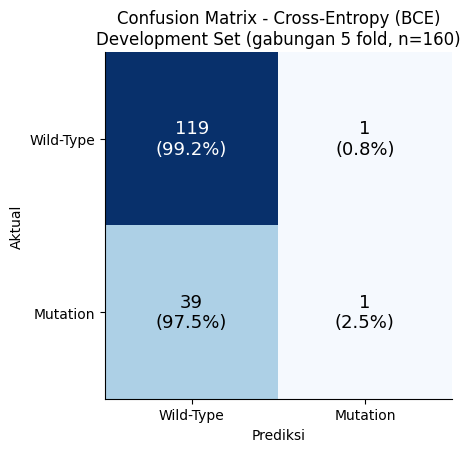

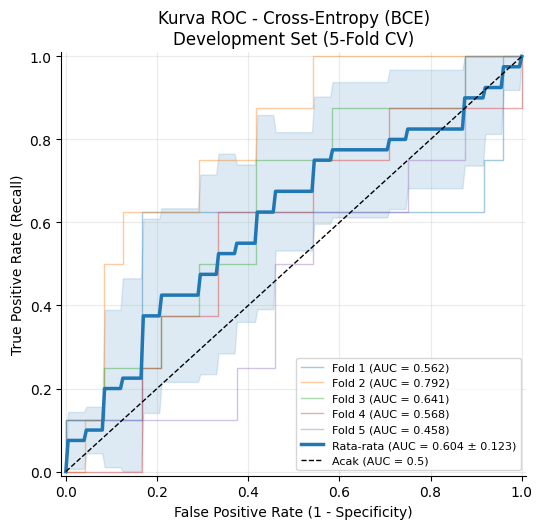

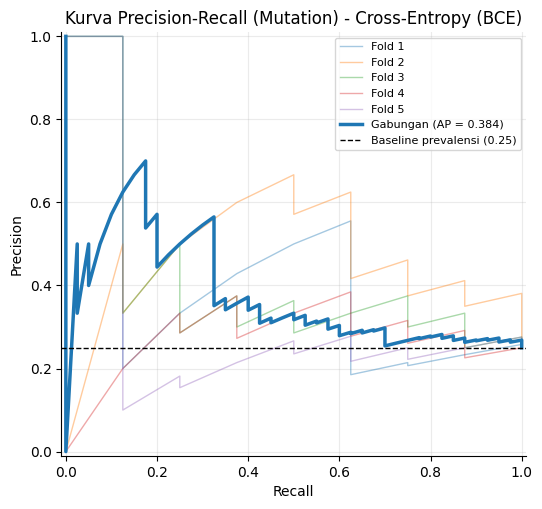

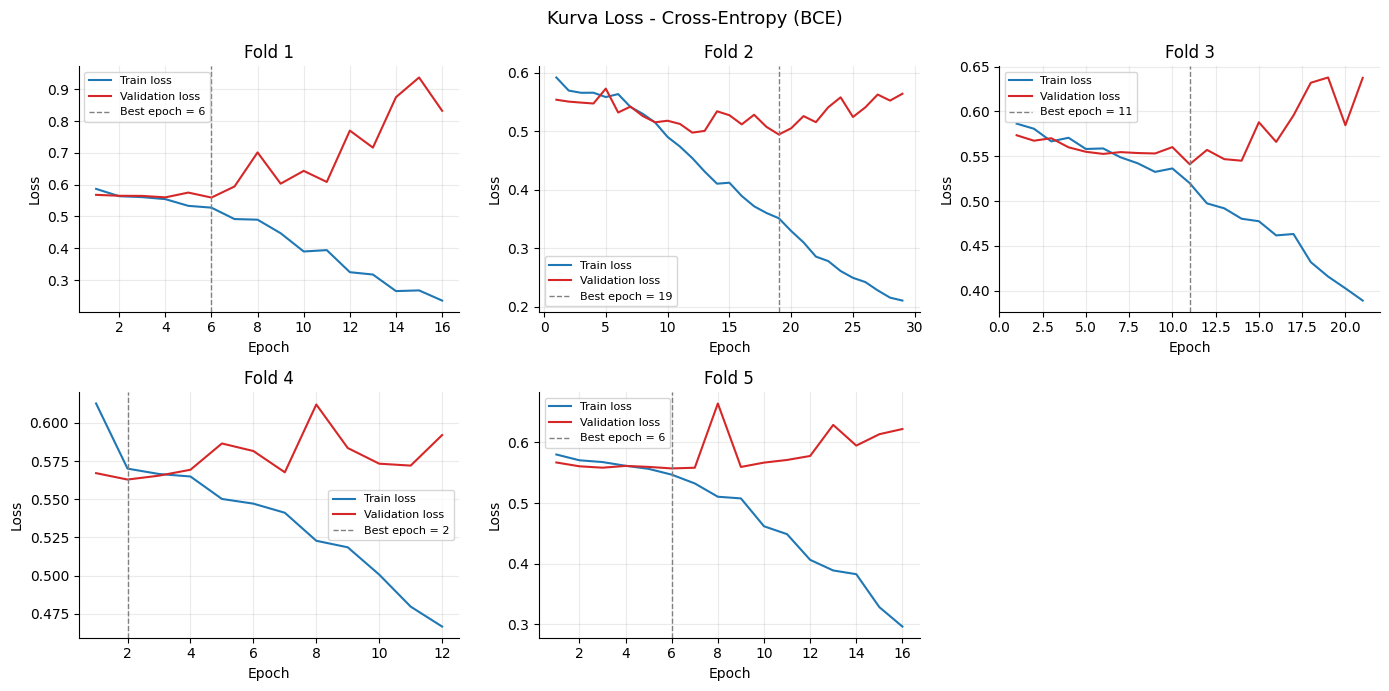

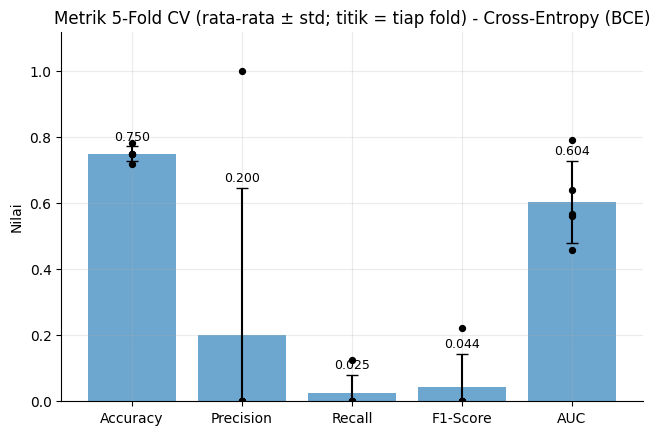

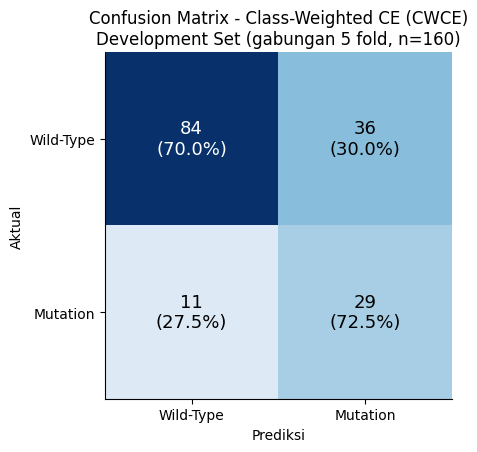

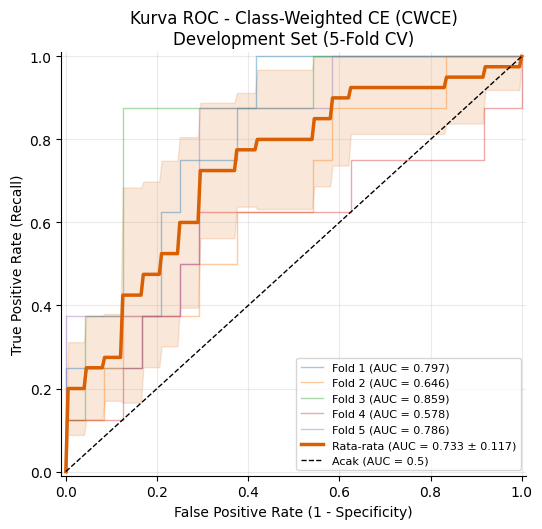

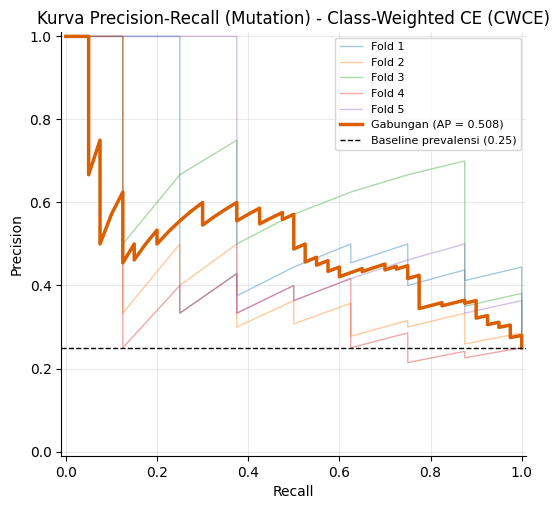

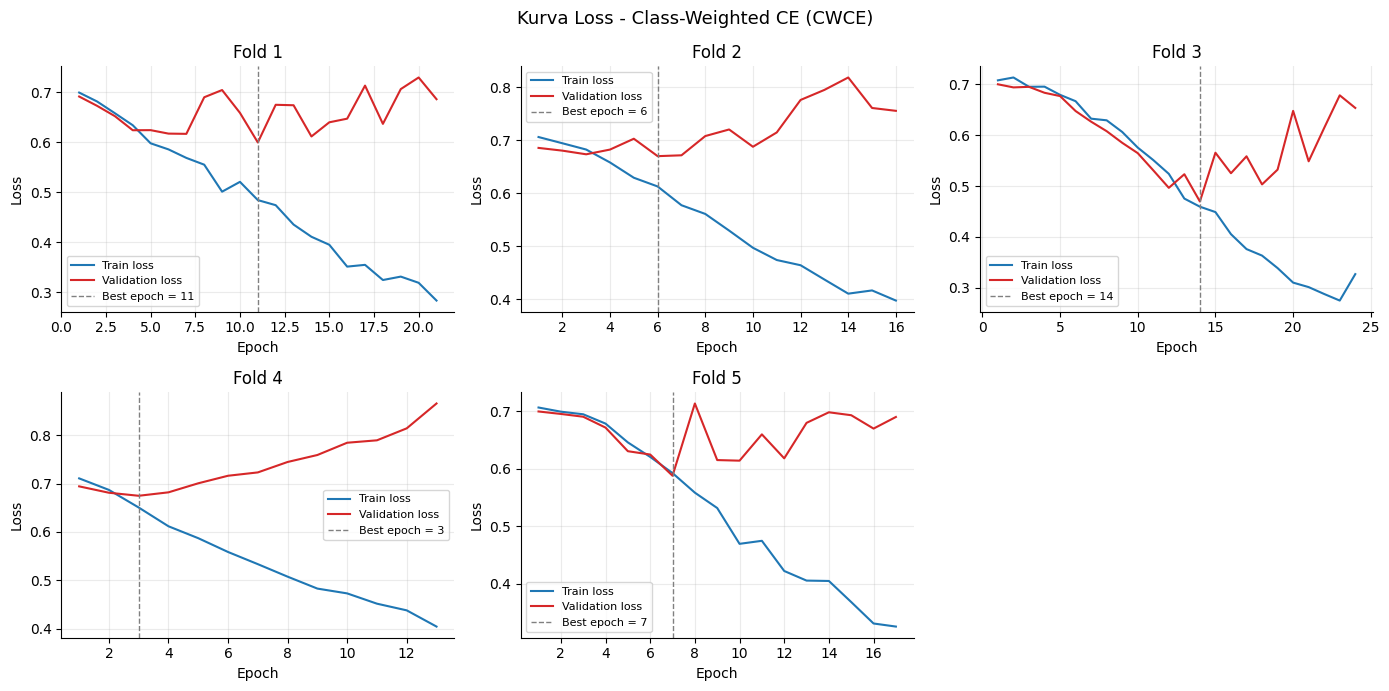

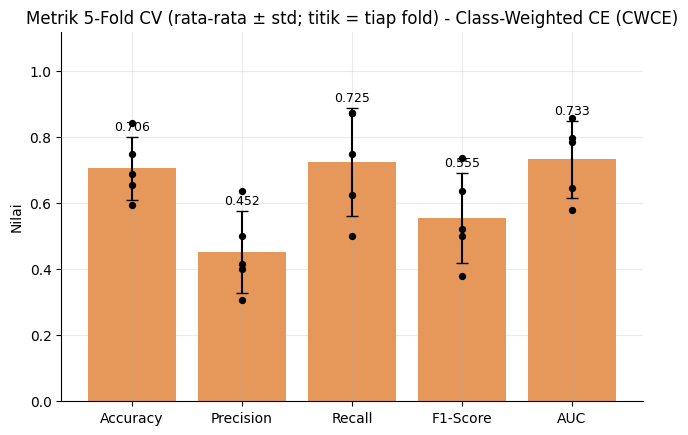

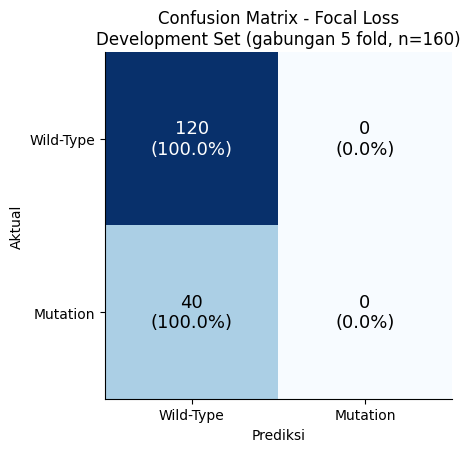

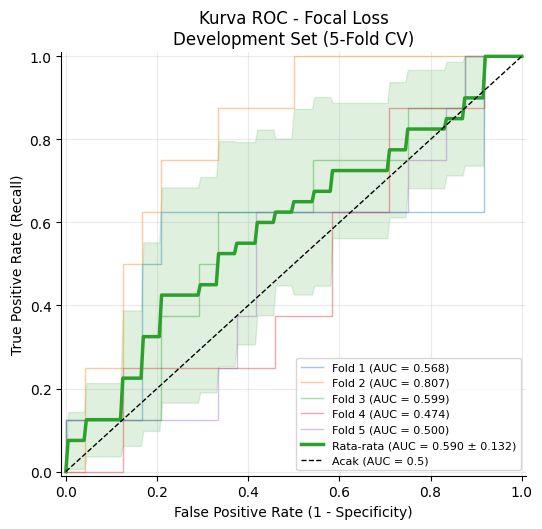

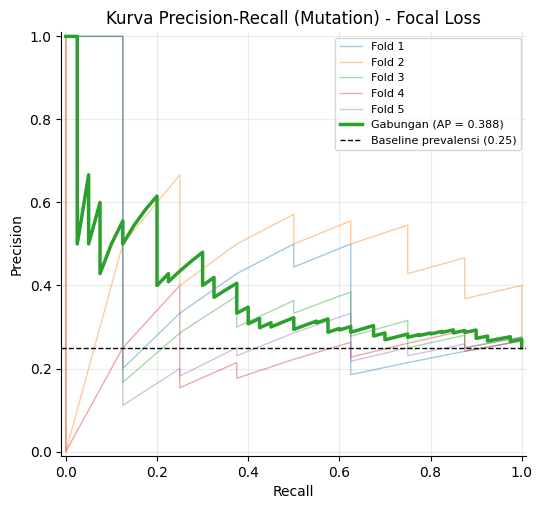

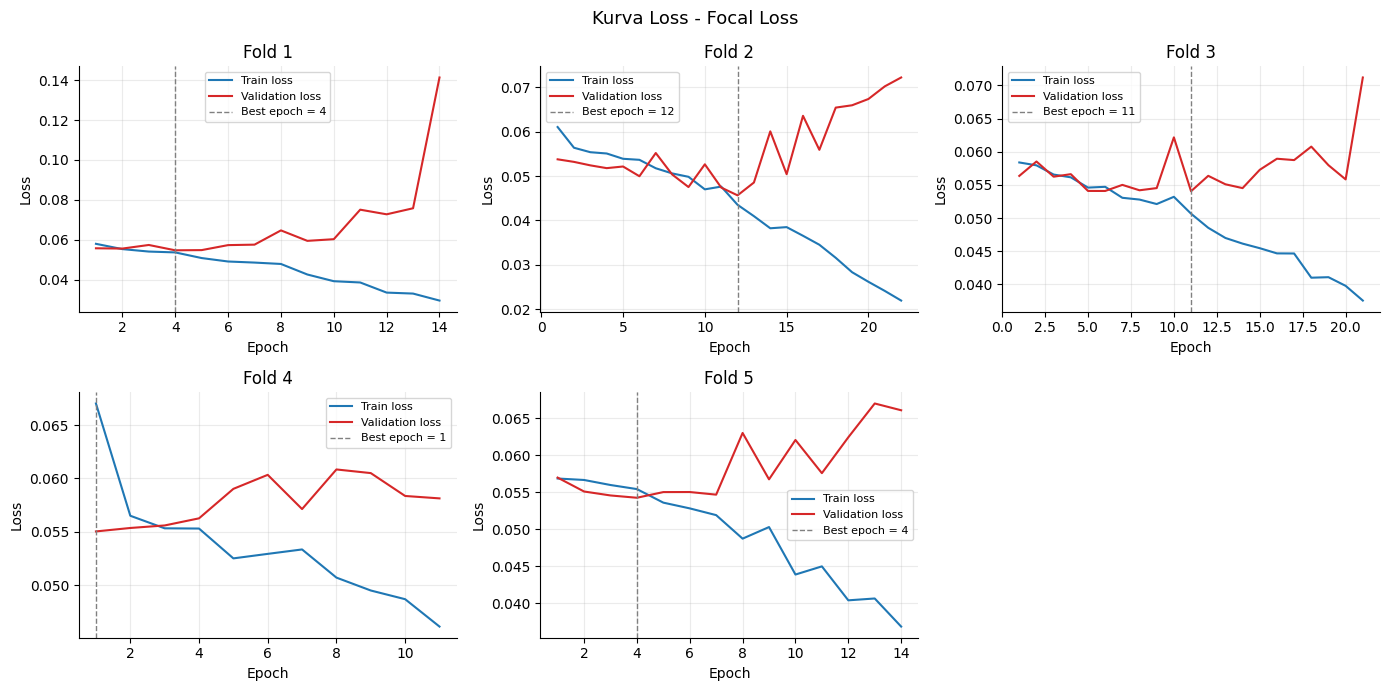

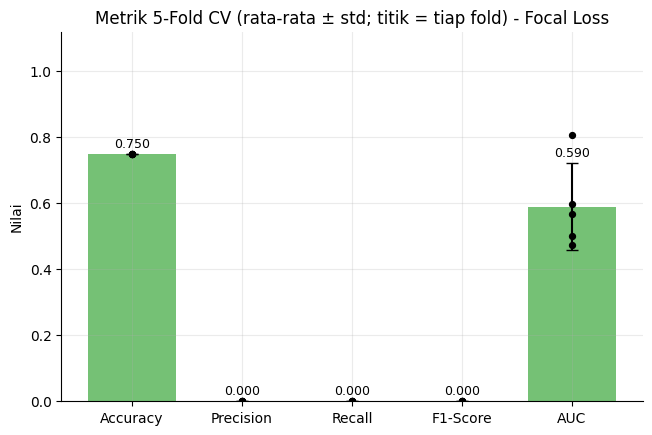

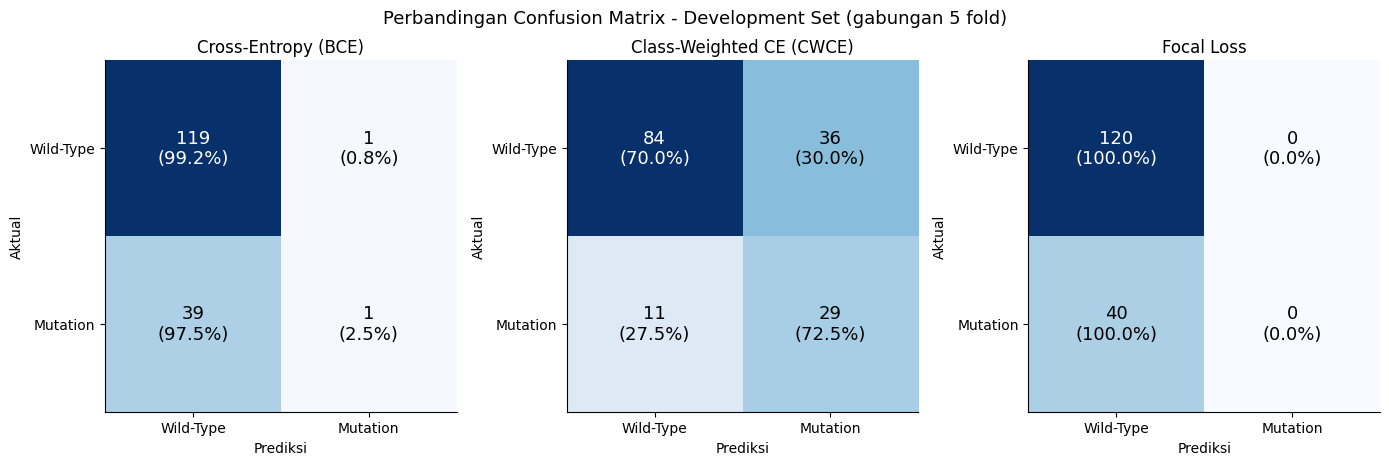

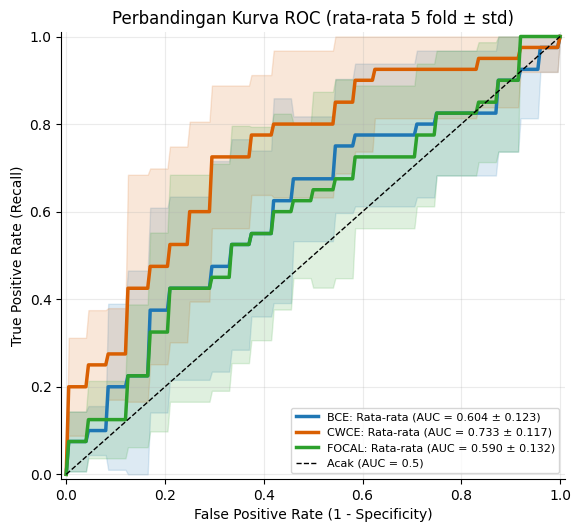

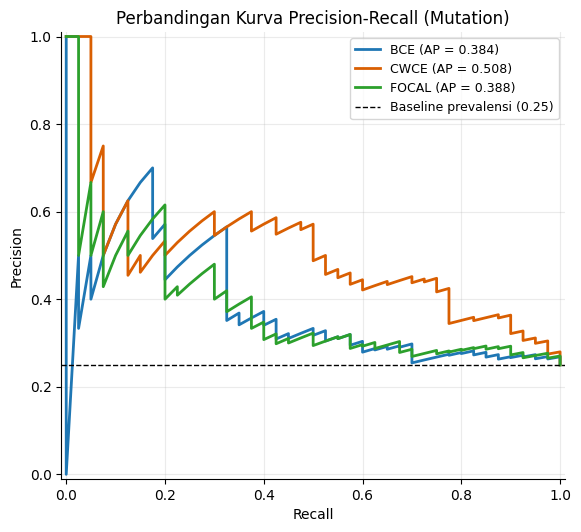

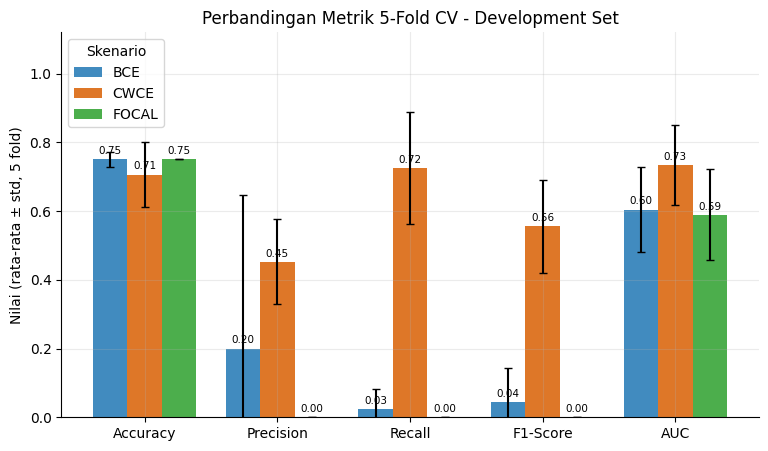

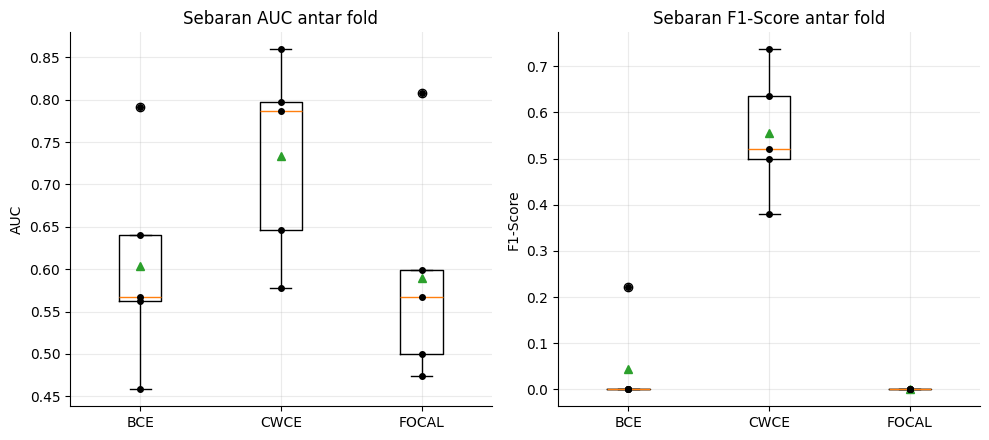


Ringkasan 5-Fold CV (mean ± std):
scenario        Accuracy       Precision          Recall        F1-Score             AUC
     BCE 0.7500 ± 0.0221 0.2000 ± 0.4472 0.0250 ± 0.0559 0.0444 ± 0.0994 0.6042 ± 0.1233
    CWCE 0.7063 ± 0.0953 0.4521 ± 0.1236 0.7250 ± 0.1630 0.5552 ± 0.1361 0.7333 ± 0.1167
   FOCAL 0.7500 ± 0.0000 0.0000 ± 0.0000 0.0000 ± 0.0000 0.0000 ± 0.0000 0.5896 ± 0.1317

Confusion matrix gabungan (out-of-fold):
scenario  pooled_tn  pooled_fp  pooled_fn  pooled_tp
     BCE        119          1         39          1
    CWCE         84         36         11         29
   FOCAL        120          0         40          0

Semua gambar tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Gambar_Development_Set


In [ ]:
# ================================================================
# GAMBAR HASIL DEVELOPMENT SET (5-Fold CV) UNTUK SETIAP SKENARIO
# Sumber: hasil CV di Drive (tidak perlu GPU, tidak ada training ulang)
#  - all_validation_predictions.csv : prediksi out-of-fold (160 pasien)
#  - fold_metrics.csv               : metrik per fold
#  - fold_*/training_history.csv    : kurva loss per epoch
# Gambar per skenario: Confusion Matrix, ROC-AUC, Precision-Recall,
#   Kurva Loss, Metrik per Fold. Gambar perbandingan: 3 skenario.
# ================================================================

import os, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"
MODEL_ROOT = f"{SCEN_ROOT}/Model_Selection_Final"
OUT_ROOT = f"{SCEN_ROOT}/Gambar_Development_Set"

SCENARIOS = ["BCE", "CWCE", "FOCAL"]
SCENARIO_GLOB = {
    "BCE": "ABMIL_BCE_50ep*",
    "CWCE": "ABMIL_CWCE_50ep*",
    "FOCAL": "ABMIL_FOCAL_50ep*",
}
MANUAL_DIRS = {}      # contoh: {"BCE": f"{SCEN_ROOT}/ABMIL_BCE_50ep_2026..."}

THRESHOLD = 0.5
DPI = 200
CLASS_NAMES = ["Wild-Type", "Mutation"]
TITLE = {"BCE": "Cross-Entropy (BCE)", "CWCE": "Class-Weighted CE (CWCE)",
         "FOCAL": "Focal Loss"}
COLOR = {"BCE": "#1f77b4", "CWCE": "#d95f02", "FOCAL": "#2ca02c"}
METRICS = ["accuracy", "precision", "recall", "f1", "auc"]
METRIC_LABEL = {"accuracy": "Accuracy", "precision": "Precision",
                "recall": "Recall", "f1": "F1-Score", "auc": "AUC"}

os.makedirs(OUT_ROOT, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# -------------------- 2. MUAT HASIL CV ---------------------------

def find_dir(name):
    if name in MANUAL_DIRS:
        return MANUAL_DIRS[name]
    sel = os.path.join(MODEL_ROOT, "selected_scenario.json")
    if os.path.isfile(sel):
        with open(sel) as f:
            d = json.load(f).get("source_dirs", {}).get(name)
        if d and os.path.isfile(os.path.join(d, "fold_metrics.csv")):
            return d
    cands = [p for p in Path(SCEN_ROOT).glob(SCENARIO_GLOB[name])
             if (p / "fold_metrics.csv").exists()]
    if not cands:
        raise FileNotFoundError(f"Hasil CV skenario {name} tidak ditemukan.")
    return str(max(cands, key=lambda p: (p / "fold_metrics.csv").stat().st_mtime))

DATA = {}
for s in SCENARIOS:
    d = find_dir(s)
    fm = pd.read_csv(os.path.join(d, "fold_metrics.csv"))
    pr = pd.read_csv(os.path.join(d, "all_validation_predictions.csv"))
    hist = []
    for k in range(1, 6):
        hp = os.path.join(d, f"fold_{k}", "training_history.csv")
        if os.path.isfile(hp):
            hist.append(pd.read_csv(hp))
    hist = pd.concat(hist, ignore_index=True) if hist else None
    if pr["patient_id"].duplicated().any():
        raise ValueError(f"{s}: patient_id duplikat pada prediksi out-of-fold.")
    DATA[s] = {"dir": d, "fm": fm.sort_values("fold"), "pred": pr, "hist": hist}
    print(f"{s}: {os.path.basename(d)} | {len(pr)} pasien out-of-fold")

def savefig(fig, name):
    path = os.path.join(OUT_ROOT, name)
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# -------------------- 3. FUNGSI PLOT -----------------------------

def draw_cm(ax, y, pred, title):
    cm = confusion_matrix(y, pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.1f}%)", ha="center",
                    va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    ax.set_title(title); ax.grid(False)
    return cm

GRID = np.linspace(0, 1, 201)

def fold_rocs(pred):
    tprs, aucs, curves = [], [], []
    for f, g in pred.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["label"], g["prob_mutation"])
        t = np.interp(GRID, fpr, tpr); t[0] = 0.0
        tprs.append(t); aucs.append(roc_auc_score(g["label"], g["prob_mutation"]))
        curves.append((f, fpr, tpr))
    return np.array(tprs), np.array(aucs), curves

def draw_mean_roc(ax, pred, color, label_prefix="", show_folds=True):
    tprs, aucs, curves = fold_rocs(pred)
    if show_folds:
        for f, fpr, tpr in curves:
            ax.plot(fpr, tpr, lw=1, alpha=0.4,
                    label=f"Fold {f} (AUC = {aucs[f - 1]:.3f})")
    m = tprs.mean(axis=0); m[-1] = 1.0
    sd = tprs.std(axis=0, ddof=1)
    ax.plot(GRID, m, color=color, lw=2.5,
            label=f"{label_prefix}Rata-rata (AUC = {aucs.mean():.3f} ± {aucs.std(ddof=1):.3f})")
    ax.fill_between(GRID, np.maximum(m - sd, 0), np.minimum(m + sd, 1),
                    color=color, alpha=0.15)

def style_roc(ax, title):
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Acak (AUC = 0.5)")
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
    ax.set_xlabel("False Positive Rate (1 - Specificity)")
    ax.set_ylabel("True Positive Rate (Recall)")
    ax.set_title(title); ax.legend(loc="lower right", fontsize=8)

# -------------------- 4. GAMBAR PER SKENARIO ---------------------

summary_rows = []

for s in SCENARIOS:
    pred, fm, hist = DATA[s]["pred"], DATA[s]["fm"], DATA[s]["hist"]
    y = pred["label"].values.astype(int)
    p = pred["prob_mutation"].values
    yhat = (p >= THRESHOLD).astype(int)
    name = TITLE[s]

    # (a) Confusion matrix gabungan 5 fold (out-of-fold)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    cm = draw_cm(ax, y, yhat, f"Confusion Matrix - {name}\nDevelopment Set (gabungan 5 fold, n={len(y)})")
    savefig(fig, f"{s}_1_confusion_matrix.png")

    # (b) ROC per fold + rata-rata
    fig, ax = plt.subplots(figsize=(6, 5.5))
    draw_mean_roc(ax, pred, COLOR[s])
    style_roc(ax, f"Kurva ROC - {name}\nDevelopment Set (5-Fold CV)")
    savefig(fig, f"{s}_2_roc_auc.png")

    # (c) Precision-Recall (fokus kelas minoritas Mutation)
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for f, g in pred.groupby("fold"):
        pr_, rc_, _ = precision_recall_curve(g["label"], g["prob_mutation"])
        ax.plot(rc_, pr_, lw=1, alpha=0.4, label=f"Fold {f}")
    pr_, rc_, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    ax.plot(rc_, pr_, color=COLOR[s], lw=2.5, label=f"Gabungan (AP = {ap:.3f})")
    ax.axhline(y.mean(), color="k", ls="--", lw=1,
               label=f"Baseline prevalensi ({y.mean():.2f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
    ax.set_title(f"Kurva Precision-Recall (Mutation) - {name}")
    ax.legend(loc="upper right", fontsize=8)
    savefig(fig, f"{s}_3_precision_recall.png")

    # (d) Kurva loss training vs validasi per fold
    if hist is not None:
        fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=False)
        axes = axes.ravel()
        for k in range(1, 6):
            ax = axes[k - 1]
            h = hist[hist["fold"] == k]
            ax.plot(h["epoch"], h["train_loss"], label="Train loss", color="#1f77b4")
            ax.plot(h["epoch"], h["val_loss"], label="Validation loss", color="#d62728")
            be = int(fm.loc[fm["fold"] == k, "best_epoch"].iloc[0])
            ax.axvline(be, color="gray", ls="--", lw=1, label=f"Best epoch = {be}")
            ax.set_title(f"Fold {k}"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
            ax.legend(fontsize=8)
        axes[5].axis("off")
        fig.suptitle(f"Kurva Loss - {name}", fontsize=13)
        fig.tight_layout()
        savefig(fig, f"{s}_4_kurva_loss.png")

    # (e) Metrik per fold (batang = rata-rata ± std, titik = tiap fold)
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for i, m in enumerate(METRICS):
        v = fm[m].values
        ax.bar(i, v.mean(), yerr=v.std(ddof=1), capsize=4, color=COLOR[s], alpha=0.65)
        ax.scatter(np.full(len(v), i), v, color="k", s=18, zorder=3)
        ax.text(i, min(v.mean() + v.std(ddof=1), 1.0) + 0.02, f"{v.mean():.3f}",
                ha="center", fontsize=9)
    ax.set_xticks(range(len(METRICS)))
    ax.set_xticklabels([METRIC_LABEL[m] for m in METRICS])
    ax.set_ylim(0, 1.12); ax.set_ylabel("Nilai")
    ax.set_title(f"Metrik 5-Fold CV (rata-rata ± std; titik = tiap fold) - {name}")
    savefig(fig, f"{s}_5_metrik_per_fold.png")

    tn, fp, fn, tp = cm.ravel()
    row = {"scenario": s, "n_patients": len(y), "pooled_tn": int(tn),
           "pooled_fp": int(fp), "pooled_fn": int(fn), "pooled_tp": int(tp),
           "pooled_auc": roc_auc_score(y, p), "pooled_ap": ap}
    for m in METRICS:
        row[f"{m}_mean"] = fm[m].mean(); row[f"{m}_std"] = fm[m].std(ddof=1)
    summary_rows.append(row)

# -------------------- 5. GAMBAR PERBANDINGAN ---------------------

# (f) Confusion matrix 3 skenario berdampingan
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, s in zip(axes, SCENARIOS):
    pr = DATA[s]["pred"]
    draw_cm(ax, pr["label"].values.astype(int),
            (pr["prob_mutation"].values >= THRESHOLD).astype(int), TITLE[s])
fig.suptitle("Perbandingan Confusion Matrix - Development Set (gabungan 5 fold)", fontsize=13)
fig.tight_layout()
savefig(fig, "PERBANDINGAN_1_confusion_matrix.png")

# (g) ROC rata-rata 3 skenario
fig, ax = plt.subplots(figsize=(6.5, 5.8))
for s in SCENARIOS:
    draw_mean_roc(ax, DATA[s]["pred"], COLOR[s], label_prefix=f"{s}: ", show_folds=False)
style_roc(ax, "Perbandingan Kurva ROC (rata-rata 5 fold ± std)")
savefig(fig, "PERBANDINGAN_2_roc_auc.png")

# (h) Precision-Recall gabungan 3 skenario
fig, ax = plt.subplots(figsize=(6.5, 5.8))
for s in SCENARIOS:
    pr = DATA[s]["pred"]
    pr_, rc_, _ = precision_recall_curve(pr["label"], pr["prob_mutation"])
    ap = average_precision_score(pr["label"], pr["prob_mutation"])
    ax.plot(rc_, pr_, color=COLOR[s], lw=2, label=f"{s} (AP = {ap:.3f})")
prev = DATA[SCENARIOS[0]]["pred"]["label"].mean()
ax.axhline(prev, color="k", ls="--", lw=1, label=f"Baseline prevalensi ({prev:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01)
ax.set_title("Perbandingan Kurva Precision-Recall (Mutation)")
ax.legend(loc="upper right", fontsize=9)
savefig(fig, "PERBANDINGAN_3_precision_recall.png")

# (i) Batang metrik rata-rata ± std, 3 skenario
fig, ax = plt.subplots(figsize=(9, 5))
w = 0.26
for j, s in enumerate(SCENARIOS):
    fm = DATA[s]["fm"]
    mean = [fm[m].mean() for m in METRICS]
    std = [fm[m].std(ddof=1) for m in METRICS]
    xs = np.arange(len(METRICS)) + (j - 1) * w
    ax.bar(xs, mean, w, yerr=std, capsize=3, color=COLOR[s], alpha=0.85, label=s)
    for x, v in zip(xs, mean):
        ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(range(len(METRICS)))
ax.set_xticklabels([METRIC_LABEL[m] for m in METRICS])
ax.set_ylim(0, 1.12); ax.set_ylabel("Nilai (rata-rata ± std, 5 fold)")
ax.set_title("Perbandingan Metrik 5-Fold CV - Development Set")
ax.legend(title="Skenario")
savefig(fig, "PERBANDINGAN_4_metrik.png")

# (j) Boxplot AUC dan F1 per fold, 3 skenario
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, m in zip(axes, ["auc", "f1"]):
    vals = [DATA[s]["fm"][m].values for s in SCENARIOS]
    ax.boxplot(vals, tick_labels=SCENARIOS, showmeans=True)
    for i, v in enumerate(vals, start=1):
        ax.scatter(np.full(len(v), i), v, color="k", s=16, zorder=3)
    ax.set_title(f"Sebaran {METRIC_LABEL[m]} antar fold"); ax.set_ylabel(METRIC_LABEL[m])
fig.tight_layout()
savefig(fig, "PERBANDINGAN_5_boxplot_auc_f1.png")

# -------------------- 6. TABEL RINGKASAN -------------------------

summary = pd.DataFrame(summary_rows)
summary.to_csv(os.path.join(OUT_ROOT, "ringkasan_development_set.csv"), index=False)

show = pd.DataFrame({"scenario": summary["scenario"]})
for m in METRICS:
    show[METRIC_LABEL[m]] = [f"{a:.4f} ± {b:.4f}"
                             for a, b in zip(summary[f"{m}_mean"], summary[f"{m}_std"])]
print("\nRingkasan 5-Fold CV (mean ± std):")
print(show.to_string(index=False))
print("\nConfusion matrix gabungan (out-of-fold):")
print(summary[["scenario", "pooled_tn", "pooled_fp", "pooled_fn", "pooled_tp"]].to_string(index=False))
print("\nSemua gambar tersimpan di:", OUT_ROOT)

# Evaluasi


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


EVALUASI HELD-OUT TEST SET
DEVICE: cuda
OUTPUT: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Evaluasi_Held_out_Test
Skenario terpilih (model final): CWCE
Fitur test ditemukan: 40 pasien


/tmp/ipykernel_1984/3137757446.py:152: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(path)


CSV label test: /content/drive/MyDrive/TCGA-LUAD-WSI/Features_ResNet50/feature_summary (97).csv
Distribusi label test (0=Wild-Type, 1=Mutation): {0: 30, 1: 10}

Membuat/memeriksa cache fitur test...
Membuat/memeriksa cache fitur development...

Retrain pembanding: BCE | 160 pasien | 9 epoch
Retrain BCE | Epoch 1/9 | Train loss=0.5947 | 177.0s
Retrain BCE | Epoch 2/9 | Train loss=0.5658 | 174.3s
Retrain BCE | Epoch 3/9 | Train loss=0.5692 | 176.6s
Retrain BCE | Epoch 4/9 | Train loss=0.5614 | 174.5s
Retrain BCE | Epoch 5/9 | Train loss=0.5423 | 172.9s
Retrain BCE | Epoch 6/9 | Train loss=0.5366 | 171.8s
Retrain BCE | Epoch 7/9 | Train loss=0.5282 | 170.5s
Retrain BCE | Epoch 8/9 | Train loss=0.4884 | 170.1s
Retrain BCE | Epoch 9/9 | Train loss=0.4773 | 170.3s
Prediksi test BCE selesai.
Prediksi test CWCE selesai.

Retrain pembanding: FOCAL | 160 pasien | 6 epoch
Retrain FOCAL | Epoch 1/6 | Train loss=0.0608 | 169.6s
Retrain FOCAL | Epoch 2/6 | Train loss=0.0556 | 169.6s
Retrain FOCAL | 

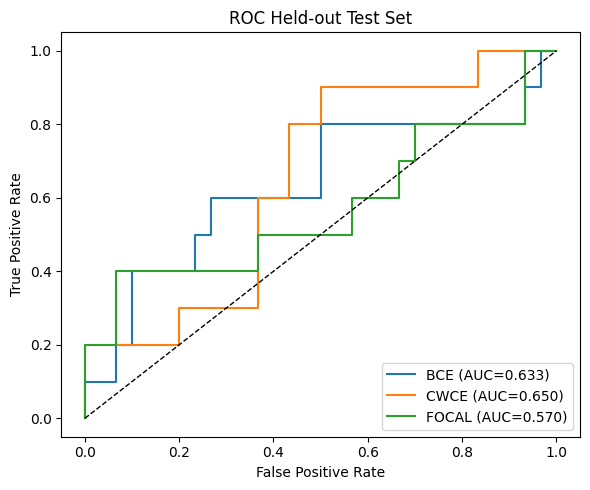

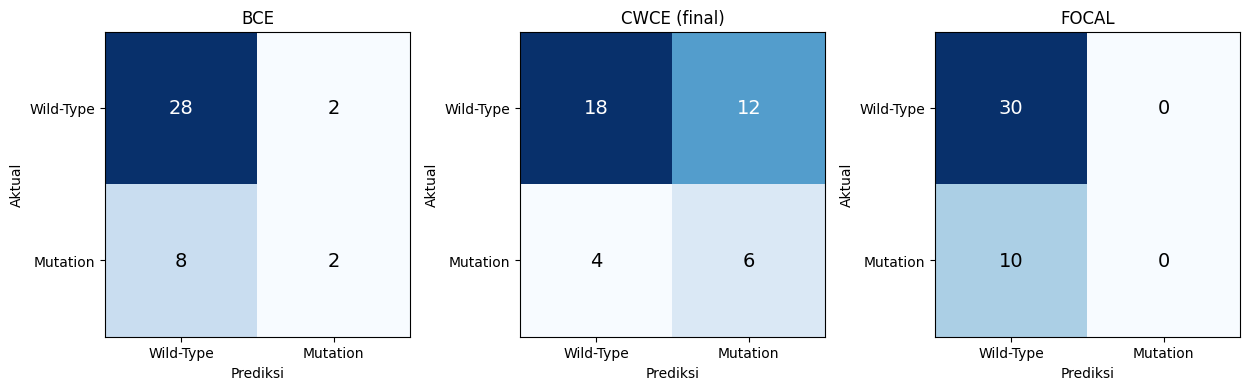


EVALUASI SELESAI. Hasil tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Evaluasi_Held_out_Test


In [ ]:
# ================================================================
# EVALUASI PADA HELD-OUT TEST SET (40 pasien: 10 Mutation : 30 Wild-Type)
# - Model final (skenario terpilih) dievaluasi: Confusion Matrix, Accuracy,
#   Precision, Recall, Specificity, F1, AUC + Bootstrap 95% CI
# - Uji statistik antarskenario: McNemar (koreksi kontinuitas) & DeLong
# - Skenario lain yang belum punya model final di-retrain pada 160 pasien
#   (epoch = rata-rata best_epoch CV skenario tsb) HANYA untuk pembanding.
# Test set hanya dipakai untuk evaluasi, bukan untuk memilih/menyetel model.
# Resume: jalankan ulang cell yang sama jika runtime terputus.
# ================================================================

import os, json, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm, binomtest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"
DEV_FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
TEST_FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/test"      # <- sesuaikan jika beda
DEV_SPLIT_CSV = f"{SCEN_ROOT}/cv5_splits/cv5_patient_fold_assignments.csv"

# CSV label test (1=Mutation, 0=Wild-Type). None -> dicari otomatis di CSV
# mana pun yang memuat label semua pasien test (id diambil dari nama file fitur).
TEST_CSV = None

MODEL_ROOT = f"{SCEN_ROOT}/Model_Selection_Final"   # dari cell model selection
OUT_ROOT = f"{SCEN_ROOT}/Evaluasi_Held_out_Test"

SCENARIOS = ["BCE", "CWCE", "FOCAL"]   # BCE = Cross-Entropy baseline

FEAT_DIM = 2048
ATT_DIM = 256
LR = 1e-4
MAX_EPOCHS = 50
THRESHOLD = 0.5
SEED = 42
NUM_CLASSES = 2
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.25
N_BOOTSTRAP = 1000      # sesuai proposal
ALPHA_SIG = 0.05

CACHE_DIR = "/content/abmil_resnet50_cache_fp16"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_ROOT, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("EVALUASI HELD-OUT TEST SET")
print("DEVICE:", DEVICE)
print("OUTPUT:", OUT_ROOT)
print("=" * 60)

sel_path = os.path.join(MODEL_ROOT, "selected_scenario.json")
if not os.path.isfile(sel_path):
    raise FileNotFoundError(
        f"{sel_path} tidak ada. Jalankan dulu cell Model Selection & Retrain."
    )
with open(sel_path, "r") as f:
    SEL = json.load(f)
SELECTED = SEL["selected_scenario"]
print("Skenario terpilih (model final):", SELECTED)

def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

# -------------------- 2. DATA: DEVELOPMENT & TEST ----------------

def patient_id_from_filename(path):
    return "-".join(Path(path).name.split("-")[:3])

def map_features(feature_dir, label="data"):
    assert os.path.isdir(feature_dir), f"Folder tidak ditemukan: {feature_dir}"
    files = sorted(str(p) for p in Path(feature_dir).rglob("*.npz"))
    if not files:
        raise FileNotFoundError(f"Tidak ada NPZ di {feature_dir}")
    out = {}
    for fp in files:
        out.setdefault(patient_id_from_filename(fp), []).append(fp)
    dup = {p: v for p, v in out.items() if len(v) != 1}
    if dup:
        raise ValueError(f"Pasien dengan >1 file fitur ({label}): {list(dup)[:5]}")
    return {p: v[0] for p, v in out.items()}

def read_label_csv(path):
    d = pd.read_csv(path)
    if not {"patient_id", "label"}.issubset(d.columns):
        raise ValueError(f"{path} harus punya kolom patient_id dan label")
    d = d[[c for c in ["patient_id", "label", "fold"] if c in d.columns]].copy()
    d["patient_id"] = d["patient_id"].astype(str).str.strip()
    d["label"] = pd.to_numeric(d["label"], errors="raise").astype(int)
    if d["patient_id"].duplicated().any():
        raise ValueError(f"patient_id duplikat di {path}")
    if not set(d["label"].unique()).issubset({0, 1}):
        raise ValueError("Label harus 0=Wild-Type, 1=Mutation")
    return d

dev_df = read_label_csv(DEV_SPLIT_CSV)
dev_ids = set(dev_df["patient_id"])

# Pasien test ditentukan dari NAMA FILE fitur test (bukan dari CSV),
# lalu labelnya dicari di CSV mana pun yang memuat pasien-pasien tersebut.
if not os.path.isdir(TEST_FEATURE_DIR):
    parent = os.path.dirname(TEST_FEATURE_DIR)
    isi = os.listdir(parent) if os.path.isdir(parent) else "(folder induk tidak ada)"
    raise FileNotFoundError(
        f"TEST_FEATURE_DIR tidak ditemukan: {TEST_FEATURE_DIR}\nIsi folder induk: {isi}"
    )

test_feat = map_features(TEST_FEATURE_DIR, "test")
test_ids = set(test_feat)
print("Fitur test ditemukan:", len(test_ids), "pasien")
if len(test_ids) != 40:
    print(f"PERINGATAN: jumlah pasien test {len(test_ids)} (diharapkan 40).")
if test_ids & dev_ids:
    raise ValueError("KEBOCORAN DATA: ada pasien test yang juga ada di Development Set.")

ID_COLS = ["patient_id", "case_id", "patient", "submitter_id", "bcr_patient_barcode"]
LABEL_COLS = ["label", "egfr_label", "egfr_status", "status", "mutation", "y"]

def norm_pid(s):
    return "-".join(str(s).strip().split("-")[:3])

def to_binary(v):
    t = str(v).strip().lower()
    if t in ("1", "1.0", "mutation", "mutant", "mut", "positive", "pos", "mutated"):
        return 1
    if t in ("0", "0.0", "wild-type", "wildtype", "wild_type", "wt", "negative", "neg"):
        return 0
    return np.nan

def scan_label_csv(path):
    d = pd.read_csv(path)
    low = {c.lower(): c for c in d.columns}
    idc = next((low[c] for c in ID_COLS if c in low), None)
    lbc = next((low[c] for c in LABEL_COLS if c in low), None)
    if idc is None or lbc is None:
        return None
    out = pd.DataFrame({
        "patient_id": d[idc].map(norm_pid),
        "label": d[lbc].map(to_binary)
    }).dropna().drop_duplicates("patient_id")
    out["label"] = out["label"].astype(int)
    return out

def find_test_labels():
    if TEST_CSV:
        r = scan_label_csv(TEST_CSV)
        if r is None:
            raise ValueError(f"{TEST_CSV}: kolom id/label tidak dikenali")
        return TEST_CSV, r
    paths = set(Path(SCEN_ROOT).rglob("*.csv"))
    paths |= set(Path(BASE_DIR).glob("*.csv")) | set(Path(BASE_DIR).glob("*/*.csv"))
    best, report = None, []
    for p in sorted(paths):
        try:
            r = scan_label_csv(p)
        except Exception:
            continue
        if r is None:
            continue
        cov = len(test_ids & set(r["patient_id"]))
        report.append((cov, len(r), str(p)))
        if cov == len(test_ids) and (best is None or len(r) < len(best[1])):
            best = (str(p), r)
    if best is None:
        print("CSV yang punya kolom id+label (cakupan pasien test / baris / path):")
        for cov, n, p in sorted(report, reverse=True)[:15]:
            print(f"  {cov}/{len(test_ids)} | {n} baris | {p}")
        raise FileNotFoundError(
            "Tidak ada CSV yang memuat label SEMUA pasien test. "
            "Isi TEST_CSV dengan path file label test Anda."
        )
    return best

TEST_CSV_PATH, lab = find_test_labels()
print("CSV label test:", TEST_CSV_PATH)

test_df = (lab[lab["patient_id"].isin(test_ids)]
           .set_index("patient_id").loc[sorted(test_ids)].reset_index())
dist = test_df["label"].value_counts().sort_index().to_dict()
print("Distribusi label test (0=Wild-Type, 1=Mutation):", dist)
if dist != {0: 30, 1: 10}:
    print("PERINGATAN: distribusi tidak sama dengan 30 Wild-Type : 10 Mutation. "
          "Periksa file label yang dipakai.")

test_feat = {p: test_feat[p] for p in test_df["patient_id"]}

# -------------------- 3. CACHE FITUR (fp16, lokal) ---------------

cache_paths = {}
FEATURE_RAM = {}

def build_cache(feature_paths):
    for pid, source_path in feature_paths.items():
        src = Path(source_path)
        cache_path = Path(CACHE_DIR) / f"{pid}.pt"
        meta_path = Path(CACHE_DIR) / f"{pid}.json"
        meta = {"path": str(src.resolve()), "size": src.stat().st_size,
                "mtime": src.stat().st_mtime}
        ok = False
        if cache_path.exists() and meta_path.exists():
            try:
                with open(meta_path) as f:
                    ok = json.load(f) == meta
            except Exception:
                ok = False
        if not ok:
            with np.load(source_path, allow_pickle=False) as z:
                if "features" not in z.files:
                    raise KeyError(f"Array features tidak ada: {source_path}")
                arr = z["features"]
                if arr.ndim != 2 or arr.shape[1] != FEAT_DIM:
                    raise ValueError(f"Dimensi fitur salah: {source_path}: {arr.shape}")
                if not np.isfinite(arr).all():
                    raise ValueError(f"NaN/Inf pada fitur: {source_path}")
                feat = torch.from_numpy(arr.copy()).to(torch.float16).contiguous()
            torch.save(feat, cache_path)
            with open(meta_path, "w") as f:
                json.dump(meta, f)
        cache_paths[pid] = str(cache_path)

def maybe_load_ram(pids):
    try:
        import psutil
        avail = psutil.virtual_memory().available
    except Exception:
        avail = 0
    total = sum(os.path.getsize(cache_paths[p]) for p in pids)
    budget = min(6 * 1024**3, int(avail * 0.35)) if avail else 0
    if total and total <= budget:
        for p in pids:
            try:
                FEATURE_RAM[p] = torch.load(cache_paths[p], map_location="cpu", weights_only=True)
            except TypeError:
                FEATURE_RAM[p] = torch.load(cache_paths[p], map_location="cpu")

def load_bag(pid):
    if pid in FEATURE_RAM:
        feat = FEATURE_RAM[pid]
    else:
        try:
            feat = torch.load(cache_paths[pid], map_location="cpu",
                              weights_only=True, mmap=True)
        except TypeError:
            feat = torch.load(cache_paths[pid], map_location="cpu")
    if feat.ndim != 2 or feat.shape[1] != FEAT_DIM:
        raise ValueError(f"Cache tidak valid: {pid}, {tuple(feat.shape)}")
    return feat.to(device=DEVICE, dtype=torch.float32)   # seluruh patch dipakai

print("\nMembuat/memeriksa cache fitur test...")
build_cache(test_feat)
maybe_load_ram(list(test_feat))

# -------------------- 4. MODEL, LOSS, METRIK ---------------------

class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(feat_dim, att_dim),
            nn.Tanh(),
            nn.Linear(att_dim, 1)
        )
        self.classifier = nn.Linear(feat_dim, 1)

    def forward(self, x):
        scores = self.attention(x)
        weights = torch.softmax(scores, dim=0)
        bag_embedding = torch.sum(weights * x, dim=0)
        return self.classifier(bag_embedding).view(1)

class ClassWeightedBCE(nn.Module):
    """
    Class-Weighted Cross-Entropy (biner, 1 logit + sigmoid):
        L = - w_y * [ y*log(p) + (1-y)*log(1-p) ]
    w_0 = bobot Wild-Type, w_1 = bobot Mutation (inverse class frequency).
    """
    def __init__(self, w_wildtype, w_mutation):
        super().__init__()
        self.register_buffer(
            "class_w",
            torch.tensor([w_wildtype, w_mutation], dtype=torch.float32)
        )
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        per_sample = self.bce(logits, y)                 # BCE tiap sampel
        w = self.class_w[y.long()]                       # bobot sesuai kelas
        return (w * per_sample).mean()

def compute_class_weights(labels, num_classes=2):
    """w_c = N / (K * N_c)  (Persamaan 2.14 pada proposal)."""
    labels = np.asarray(labels, dtype=int)
    n_total = len(labels)
    counts = np.bincount(labels, minlength=num_classes)
    if (counts == 0).any():
        raise ValueError(f"Ada kelas tanpa sampel pada data training: {counts}")
    weights = n_total / (num_classes * counts)
    return weights, counts

class FocalLoss(nn.Module):
    """
    Focal Loss biner (1 logit + sigmoid), Persamaan 2.15:
        FL = - alpha_t * (1 - p_t)^gamma * log(p_t)
    p_t     = p        jika y = 1 (Mutation), 1 - p jika y = 0 (Wild-Type)
    alpha_t = alpha    jika y = 1,            1 - alpha jika y = 0
    """
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, y):
        bce = self.bce(logits, y)                  # = -log(p_t), stabil numerik
        p_t = torch.exp(-bce)
        alpha_t = y * self.alpha + (1.0 - y) * (1.0 - self.alpha)
        return (alpha_t * (1.0 - p_t) ** self.gamma * bce).mean()

def calculate_metrics(y_true, probs):
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=float)
    preds = (probs >= THRESHOLD).astype(int)

    result = {
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "auc": (
            roc_auc_score(y_true, probs)
            if len(np.unique(y_true)) == 2 else np.nan
        )
    }

    tn, fp, fn, tp = confusion_matrix(
        y_true, preds, labels=[0, 1]
    ).ravel()

    result.update({
        "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp)
    })
    return result


def make_criterion(name, labels):
    if name == "BCE":
        return nn.BCEWithLogitsLoss(), None
    if name == "CWCE":
        w, _ = compute_class_weights(labels, NUM_CLASSES)
        return ClassWeightedBCE(float(w[0]), float(w[1])), w
    if name == "FOCAL":
        return FocalLoss(FOCAL_GAMMA, FOCAL_ALPHA), None
    raise ValueError(name)

def final_epochs(name):
    # rata-rata best_epoch 5-fold CV skenario tsb (sama aturan dgn retrain final)
    if name == SELECTED:
        return int(SEL["retrain_epochs"])
    fm = pd.read_csv(os.path.join(SEL["source_dirs"][name], "fold_metrics.csv"))
    return int(np.clip(round(fm["best_epoch"].mean()), 1, MAX_EPOCHS))

dev_ready = False
def ensure_dev_features():
    global dev_ready
    if dev_ready:
        return
    dev_feat = map_features(DEV_FEATURE_DIR, "development")
    miss = sorted(dev_ids - set(dev_feat))
    if miss:
        raise ValueError(f"Pasien development tanpa fitur: {miss[:10]}")
    dev_feat = {p: dev_feat[p] for p in dev_df["patient_id"]}
    print("Membuat/memeriksa cache fitur development...")
    build_cache(dev_feat)
    maybe_load_ram(list(dev_feat))
    dev_ready = True

def retrain_scenario(name):
    """Retrain pada seluruh Development Set (160 pasien), dengan resume."""
    ensure_dev_features()
    epochs = final_epochs(name)
    fdir = os.path.join(MODEL_ROOT, f"final_{name}")
    os.makedirs(fdir, exist_ok=True)
    final_path = os.path.join(fdir, "final_model.pt")
    ckpt_path = os.path.join(fdir, "last_checkpoint.pt")
    if os.path.exists(final_path):
        return final_path

    print(f"\nRetrain pembanding: {name} | {len(dev_df)} pasien | {epochs} epoch")
    torch.manual_seed(SEED)
    criterion, cw = make_criterion(name, dev_df["label"].values)
    criterion = criterion.to(DEVICE)
    model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history, start = [], 1

    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        if ck.get("scenario") != name or ck.get("total_epochs") != epochs:
            raise ValueError(f"Checkpoint {name} tidak cocok; hapus {fdir}")
        model.load_state_dict(ck["model_state_dict"])
        optimizer.load_state_dict(ck["optimizer_state_dict"])
        history, start = ck["history"], ck["epoch"] + 1
        print(f"Melanjutkan dari epoch {start}")

    for epoch in range(start, epochs + 1):
        t0 = time.time()
        model.train()
        losses = []
        for row in dev_df.sample(frac=1, random_state=SEED + epoch).itertuples(index=False):
            x = load_bag(str(row.patient_id))
            y = torch.tensor([float(row.label)], device=DEVICE, dtype=torch.float32)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            del x, y, logits, loss
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses))})
        print(f"Retrain {name} | Epoch {epoch}/{epochs} | "
              f"Train loss={history[-1]['train_loss']:.4f} | {time.time()-t0:.1f}s")
        atomic_torch_save({
            "scenario": name, "total_epochs": epochs, "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history}, ckpt_path)

    pd.DataFrame(history).to_csv(os.path.join(fdir, "training_history.csv"), index=False)
    atomic_torch_save({
        "scenario": name, "model_state_dict": model.state_dict(),
        "epochs_trained": epochs, "n_train_patients": int(len(dev_df)),
        "feat_dim": FEAT_DIM, "att_dim": ATT_DIM, "lr": LR,
        "threshold": THRESHOLD, "seed": SEED,
        "class_weights": None if cw is None else
            {"wild_type": float(cw[0]), "mutation": float(cw[1])},
        "focal_gamma": FOCAL_GAMMA if name == "FOCAL" else None,
        "focal_alpha": FOCAL_ALPHA if name == "FOCAL" else None,
    }, final_path)
    del model, optimizer, criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return final_path

# -------------------- 5. PREDIKSI PADA TEST SET ------------------

def predict_test(model_path):
    try:
        ck = torch.load(model_path, map_location=DEVICE, weights_only=False)
    except TypeError:
        ck = torch.load(model_path, map_location=DEVICE)
    model = ABMIL(ck.get("feat_dim", FEAT_DIM), ck.get("att_dim", ATT_DIM)).to(DEVICE)
    model.load_state_dict(ck["model_state_dict"])
    model.eval()
    probs = []
    with torch.no_grad():
        for pid in test_df["patient_id"]:
            probs.append(torch.sigmoid(model(load_bag(pid))).item())
    del model
    return np.array(probs)

y_test = test_df["label"].values.astype(int)
probs, preds = {}, {}

for name in SCENARIOS:
    mp = os.path.join(MODEL_ROOT, f"final_{name}", "final_model.pt")
    if not os.path.exists(mp):
        mp = retrain_scenario(name)
    probs[name] = predict_test(mp)
    preds[name] = (probs[name] >= THRESHOLD).astype(int)
    pd.DataFrame({
        "patient_id": test_df["patient_id"], "label": y_test,
        "prob_mutation": probs[name], "prediction": preds[name]
    }).to_csv(os.path.join(OUT_ROOT, f"test_predictions_{name}.csv"), index=False)
    print(f"Prediksi test {name} selesai.")

# -------------------- 6. METRIK + BOOTSTRAP 95% CI ---------------

METRIC_NAMES = ["accuracy", "precision", "recall", "specificity", "f1", "auc"]

def metrics_full(y, p):
    pr = (p >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y, pr),
        "precision": precision_score(y, pr, zero_division=0),
        "recall": recall_score(y, pr, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(y, pr, zero_division=0),
        "auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def bootstrap_ci(y, p, n_boot=N_BOOTSTRAP, seed=SEED):
    # Resampling dengan pengembalian pada level pasien; persentil 2,5 & 97,5.
    rng = np.random.default_rng(seed)
    n = len(y)
    out = {m: [] for m in METRIC_NAMES}
    done = 0
    while done < n_boot:
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < 2:     # AUC tidak terdefinisi -> ulangi
            continue
        m = metrics_full(y[idx], p[idx])
        for k in METRIC_NAMES:
            out[k].append(m[k])
        done += 1
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5)))
            for k, v in out.items()}

rows = []
for name in SCENARIOS:
    m = metrics_full(y_test, probs[name])
    ci = bootstrap_ci(y_test, probs[name])
    row = {"scenario": name, "is_final_model": name == SELECTED}
    for k in METRIC_NAMES:
        row[k] = m[k]
        row[f"{k}_ci_low"], row[f"{k}_ci_high"] = ci[k]
    for k in ["tn", "fp", "fn", "tp"]:
        row[k] = m[k]
    rows.append(row)

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(os.path.join(OUT_ROOT, "test_metrics_bootstrap_ci.csv"), index=False)

print("\n" + "=" * 60)
print(f"HASIL HELD-OUT TEST SET (threshold={THRESHOLD}, Bootstrap {N_BOOTSTRAP}x, CI 95%)")
print("=" * 60)
for r in rows:
    tag = "  <== MODEL FINAL" if r["is_final_model"] else ""
    print(f"\n[{r['scenario']}]{tag}")
    print(f"  Confusion Matrix: TN={r['tn']} FP={r['fp']} FN={r['fn']} TP={r['tp']}")
    for k in METRIC_NAMES:
        print(f"  {k:<12}: {r[k]:.4f}  (95% CI {r[k+'_ci_low']:.4f} - {r[k+'_ci_high']:.4f})")

# -------------------- 7. UJI STATISTIK ---------------------------

def mcnemar_test(y, pred_a, pred_b):
    a_ok = pred_a == y
    b_ok = pred_b == y
    n_sf = int((a_ok & ~b_ok).sum())    # A benar, B salah
    n_fs = int((~a_ok & b_ok).sum())    # A salah, B benar
    disc = n_sf + n_fs
    if disc == 0:
        return n_sf, n_fs, 0.0, 1.0, 1.0
    z = (abs(n_sf - n_fs) - 1) / np.sqrt(disc)     # Persamaan 2.22
    z = max(z, 0.0)
    p = 2 * norm.sf(z)
    p_exact = binomtest(min(n_sf, n_fs), disc, 0.5).pvalue
    return n_sf, n_fs, float(z), float(p), float(p_exact)

def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x)
    T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1)
        i = j
    T2 = np.empty(N); T2[J] = T + 1
    return T2

def delong_test(y, p_a, p_b):
    order = np.argsort(-y, kind="stable")          # positif dulu
    yy = y[order]
    m = int(yy.sum()); n = len(yy) - m
    P = np.vstack([p_a[order], p_b[order]])
    k = 2
    tx = np.empty([k, m]); ty = np.empty([k, n]); tz = np.empty([k, m + n])
    for r in range(k):
        tx[r] = _midrank(P[r, :m]); ty[r] = _midrank(P[r, m:]); tz[r] = _midrank(P[r])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    if var <= 1e-12:
        return float(aucs[0]), float(aucs[1]), 0.0, 1.0
    z = (aucs[0] - aucs[1]) / np.sqrt(var)         # Persamaan 2.23
    return float(aucs[0]), float(aucs[1]), float(z), float(2 * norm.sf(abs(z)))

pairs = [("BCE", "CWCE"), ("BCE", "FOCAL"), ("CWCE", "FOCAL")]
stat_rows = []
for a, b in pairs:
    n_sf, n_fs, z_m, p_m, p_ex = mcnemar_test(y_test, preds[a], preds[b])
    auc_a, auc_b, z_d, p_d = delong_test(y_test, probs[a], probs[b])
    stat_rows.append({
        "model_A": a, "model_B": b,
        "mcnemar_Nsf(A benar,B salah)": n_sf, "mcnemar_Nfs(A salah,B benar)": n_fs,
        "mcnemar_Z": z_m, "mcnemar_p": p_m, "mcnemar_p_exact": p_ex,
        "mcnemar_signifikan": p_m < ALPHA_SIG,
        "auc_A": auc_a, "auc_B": auc_b, "delong_Z": z_d, "delong_p": p_d,
        "delong_signifikan": p_d < ALPHA_SIG,
    })

stat_df = pd.DataFrame(stat_rows)
stat_df.to_csv(os.path.join(OUT_ROOT, "statistical_tests.csv"), index=False)

print("\n" + "=" * 60)
print(f"UJI STATISTIK (alpha={ALPHA_SIG}, dua arah)")
print("=" * 60)
for r in stat_rows:
    print(f"\n{r['model_A']} vs {r['model_B']}")
    print(f"  McNemar : Nsf={r['mcnemar_Nsf(A benar,B salah)']}, "
          f"Nfs={r['mcnemar_Nfs(A salah,B benar)']}, Z={r['mcnemar_Z']:.4f}, "
          f"p={r['mcnemar_p']:.4f} (exact p={r['mcnemar_p_exact']:.4f}) -> "
          f"{'SIGNIFIKAN' if r['mcnemar_signifikan'] else 'tidak signifikan'}")
    print(f"  DeLong  : AUC {r['model_A']}={r['auc_A']:.4f}, {r['model_B']}={r['auc_B']:.4f}, "
          f"Z={r['delong_Z']:.4f}, p={r['delong_p']:.4f} -> "
          f"{'SIGNIFIKAN' if r['delong_signifikan'] else 'tidak signifikan'}")

# -------------------- 8. GAMBAR ----------------------------------

fig, ax = plt.subplots(figsize=(6, 5))
for name in SCENARIOS:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc_v = metrics_df.loc[metrics_df["scenario"] == name, "auc"].iloc[0]
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_v:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Held-out Test Set"); ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(OUT_ROOT, "roc_curves_test.png"), dpi=200)
plt.show()

fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(4.2 * len(SCENARIOS), 4))
for ax, name in zip(np.atleast_1d(axes), SCENARIOS):
    cm = confusion_matrix(y_test, preds[name], labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Wild-Type", "Mutation"]); ax.set_yticklabels(["Wild-Type", "Mutation"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    ax.set_title(name + (" (final)" if name == SELECTED else ""))
fig.tight_layout()
fig.savefig(os.path.join(OUT_ROOT, "confusion_matrices_test.png"), dpi=200)
plt.show()

print("\n" + "=" * 60)
print("EVALUASI SELESAI. Hasil tersimpan di:", OUT_ROOT)
print("=" * 60)

Test Set: 40 pasien (Mutation=10, Wild-Type=30)

PEMILIHAN SKENARIO — rata-rata ± std 5-Fold CV (Development Set)
FOCAL  Accuracy=0.675±0.100 | Precision=0.410±0.088 | Recall=0.650±0.240 | F1=0.490±0.137 | AUC=0.760±0.095 | best_epoch=8.4
CWCE   Accuracy=0.706±0.095 | Precision=0.452±0.124 | Recall=0.725±0.163 | F1=0.555±0.136 | AUC=0.733±0.117 | best_epoch=8.2
BCE    Accuracy=0.750±0.022 | Precision=0.200±0.447 | Recall=0.025±0.056 | F1=0.044±0.099 | AUC=0.604±0.123 | best_epoch=8.8

>>> SKENARIO TERBAIK (kriteria AUC, tie-break ['f1', 'recall']): FOCAL

HELD-OUT TEST SET — ambang fixed_0.5  (sesuai proposal)

BCE (thr=0.500)
  TN=28 FP=2 FN=8 TP=2
  Accuracy    : 0.750  [95% CI 0.600 – 0.875]
  Precision   : 0.500  [95% CI 0.000 – 1.000]
  Recall      : 0.200  [95% CI 0.000 – 0.500]
  Specificity : 0.933  [95% CI 0.828 – 1.000]
  F1          : 0.286  [95% CI 0.000 – 0.588]
  Auc         : 0.633  [95% CI 0.384 – 0.857]

CWCE (thr=0.500)
  TN=18 FP=12 FN=4 TP=6
  Accuracy    : 0.600  [

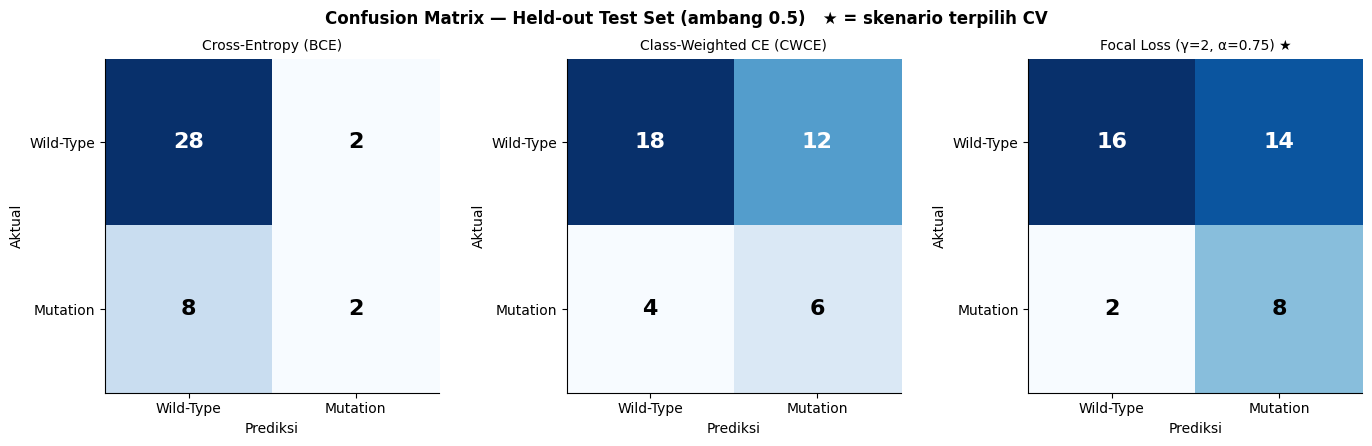

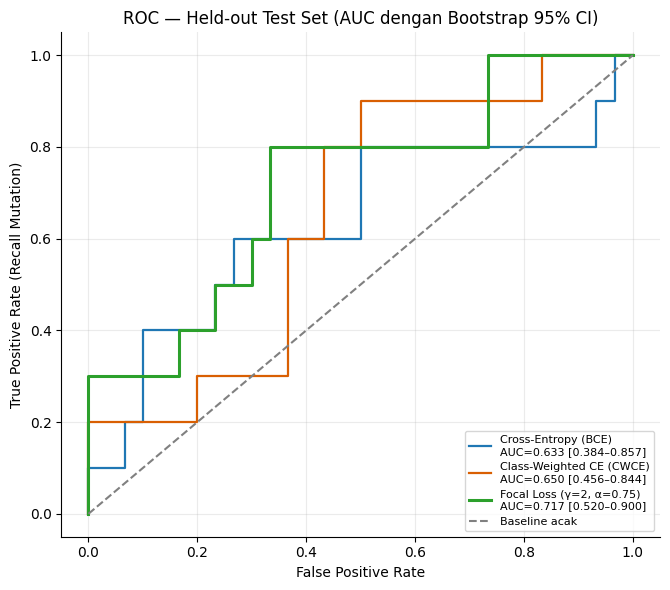

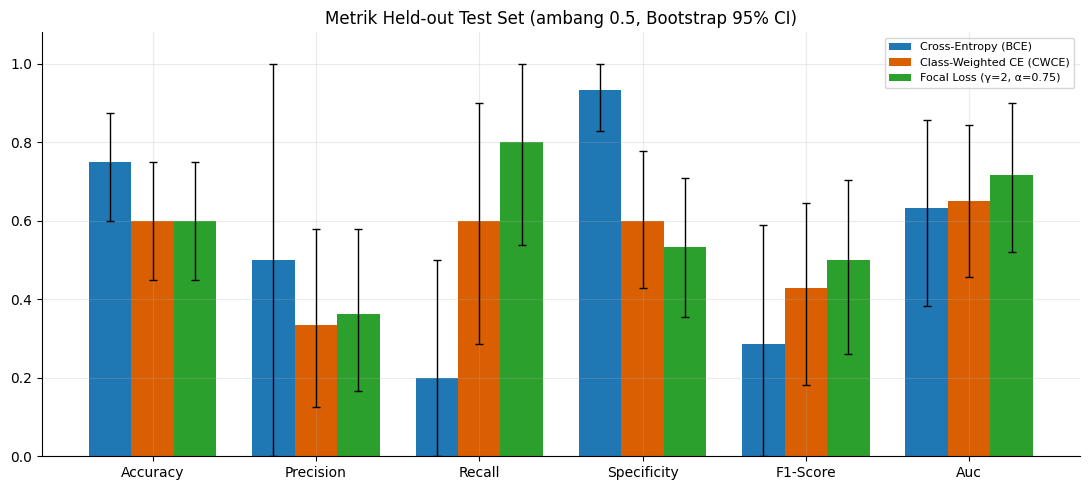

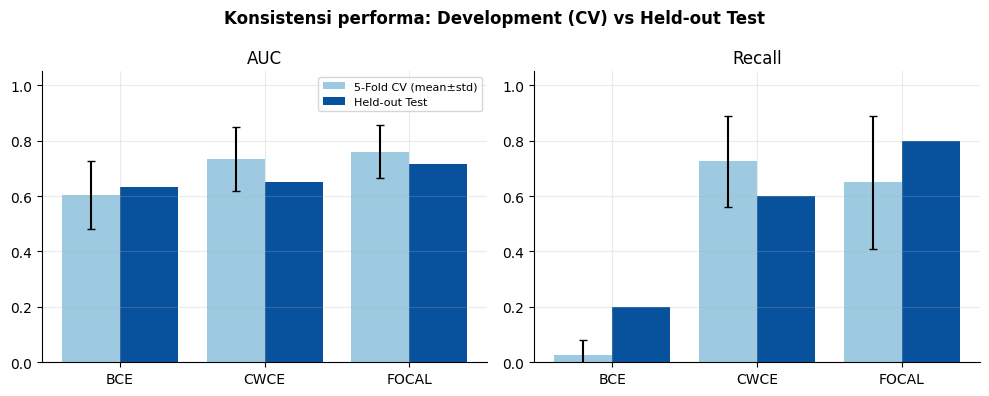


Semua hasil (CSV & gambar) tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Evaluasi_Final_Focal_Baru


In [ ]:
# ================================================================
# TAHAP LANJUTAN SESUAI PROPOSAL (BAB III) DENGAN FOCAL LOSS BARU (gamma=2, alpha=0.75)
#   1) Pemilihan skenario terbaik: BCE vs CWCE vs FOCAL baru (rata-rata 5-Fold CV, Development Set)
#   2) Evaluasi Held-out Test Set (40 pasien) memakai model final yang sudah di-retrain pada 160 pasien:
#      Confusion Matrix, Accuracy, Precision, Recall, Specificity, F1, AUC + Bootstrap 95% CI
#   3) Uji statistik antarskenario: McNemar (koreksi kontinuitas + exact) & DeLong
#   4) Gambar: Confusion Matrix, ROC, perbandingan metrik
# Tidak ada training ulang & tidak butuh GPU: hanya membaca CSV prediksi yang sudah ada di Drive
# (hasil cell "Revisi Focal Loss" dan cell "Evaluasi Held-out Test").
# Ambang: 0.5 (sesuai proposal) dan Youden dari OOF Development (sebagai analisis tambahan).
# ================================================================

import os, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, binomtest, chi2
from sklearn.metrics import roc_auc_score, roc_curve

# -------------------- 1. KONFIGURASI -----------------------------

BASE_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"
MODEL_ROOT = f"{SCEN_ROOT}/Model_Selection_Final"
TEST_EVAL_DIR = f"{SCEN_ROOT}/Evaluasi_Held_out_Test"
REVIEW_DIR = f"{SCEN_ROOT}/Perbaikan_Review"
OUT_ROOT = f"{SCEN_ROOT}/Evaluasi_Final_Focal_Baru"

FOCAL_ALPHA_NEW = 0.75
FOCAL_TAG = f"a{int(round(FOCAL_ALPHA_NEW * 100)):03d}"          # -> a075
FOCAL_CV_DIR = f"{SCEN_ROOT}/ABMIL_FOCAL_{FOCAL_TAG}_50ep"
FOCAL_TEST_CSV = f"{REVIEW_DIR}/test_predictions_FOCAL_{FOCAL_TAG}.csv"

NAMES = ["BCE", "CWCE", "FOCAL"]
LABEL = {"BCE": "Cross-Entropy (BCE)", "CWCE": "Class-Weighted CE (CWCE)",
         "FOCAL": f"Focal Loss (γ=2, α={FOCAL_ALPHA_NEW})"}
COLOR = {"BCE": "#1f77b4", "CWCE": "#d95f02", "FOCAL": "#2ca02c"}
CLASS_NAMES = ["Wild-Type", "Mutation"]

SELECTION_METRIC, TIEBREAK = "auc", ["f1", "recall"]   # sama dengan cell model selection
THRESHOLD = 0.5
N_BOOTSTRAP = 1000
ALPHA_SIG = 0.05
SEED = 42
DPI = 200

os.makedirs(OUT_ROOT, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# -------------------- 2. MUAT HASIL CV (OOF) & PREDIKSI TEST -----

with open(f"{MODEL_ROOT}/selected_scenario.json") as f:
    src = json.load(f)["source_dirs"]
cv_dir = {"BCE": src["BCE"], "CWCE": src["CWCE"], "FOCAL": FOCAL_CV_DIR}
test_csv = {"BCE": f"{TEST_EVAL_DIR}/test_predictions_BCE.csv",
            "CWCE": f"{TEST_EVAL_DIR}/test_predictions_CWCE.csv",
            "FOCAL": FOCAL_TEST_CSV}

for n in NAMES:
    for p in (os.path.join(cv_dir[n], "fold_metrics.csv"),
              os.path.join(cv_dir[n], "all_validation_predictions.csv"), test_csv[n]):
        if not os.path.isfile(p):
            raise FileNotFoundError(f"[{n}] file tidak ditemukan: {p}\n"
                                    "Jalankan dulu cell 'Revisi Focal Loss' / 'Evaluasi Held-out Test'.")

FM  = {n: pd.read_csv(os.path.join(cv_dir[n], "fold_metrics.csv")) for n in NAMES}
OOF = {n: pd.read_csv(os.path.join(cv_dir[n], "all_validation_predictions.csv")) for n in NAMES}
TST = {n: pd.read_csv(test_csv[n]).sort_values("patient_id").reset_index(drop=True) for n in NAMES}

y_test = TST["BCE"]["label"].values.astype(int)
for n in NAMES:
    assert (TST[n]["patient_id"].values == TST["BCE"]["patient_id"].values).all(), f"{n}: urutan pasien test beda"
    assert (TST[n]["label"].values.astype(int) == y_test).all(), f"{n}: label test beda"
probs = {n: TST[n]["prob_mutation"].values.astype(float) for n in NAMES}

print("=" * 70)
print(f"Test Set: {len(y_test)} pasien (Mutation={int(y_test.sum())}, Wild-Type={int((y_test==0).sum())})")
print("=" * 70)

# -------------------- 3. PEMILIHAN SKENARIO (5-Fold CV) ----------

METRICS = ["accuracy", "precision", "recall", "f1", "auc"]
sel_rows = []
for n in NAMES:
    r = {"skenario": n}
    for m in METRICS:
        r[f"{m}_mean"], r[f"{m}_std"] = FM[n][m].mean(), FM[n][m].std(ddof=1)
    r["best_epoch_mean"] = FM[n]["best_epoch"].mean()
    sel_rows.append(r)
sel_df = pd.DataFrame(sel_rows)
sel_df = sel_df.sort_values([f"{SELECTION_METRIC}_mean"] + [f"{m}_mean" for m in TIEBREAK],
                            ascending=False).reset_index(drop=True)
SELECTED = sel_df.loc[0, "skenario"]
sel_df.to_csv(os.path.join(OUT_ROOT, "model_selection_cv_focal_baru.csv"), index=False)

print("\nPEMILIHAN SKENARIO — rata-rata ± std 5-Fold CV (Development Set)")
for _, r in sel_df.iterrows():
    print(f"{r['skenario']:<6} " + " | ".join(f"{m.upper() if m=='auc' else m.capitalize()}="
          f"{r[m+'_mean']:.3f}±{r[m+'_std']:.3f}" for m in METRICS) + f" | best_epoch={r['best_epoch_mean']:.1f}")
print(f"\n>>> SKENARIO TERBAIK (kriteria {SELECTION_METRIC.upper()}, tie-break {TIEBREAK}): {SELECTED}")

# -------------------- 4. METRIK, BOOTSTRAP CI, UJI STATISTIK -----

def counts(y, pred):
    y, pred = np.asarray(y, int), np.asarray(pred, int)
    return (int(((y == 0) & (pred == 0)).sum()), int(((y == 0) & (pred == 1)).sum()),
            int(((y == 1) & (pred == 0)).sum()), int(((y == 1) & (pred == 1)).sum()))

def all_metrics(y, p, thr):
    tn, fp, fn, tp = counts(y, (p >= thr).astype(int))
    nan = np.nan
    rec = tp / (tp + fn) if tp + fn else nan
    spec = tn / (tn + fp) if tn + fp else nan
    prec = tp / (tp + fp) if tp + fp else nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else nan
    auc = roc_auc_score(y, p) if len(np.unique(y)) == 2 else nan
    return {"accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec,
            "specificity": spec, "f1": f1, "auc": auc, "tn": tn, "fp": fp, "fn": fn, "tp": tp}

MET = ["accuracy", "precision", "recall", "specificity", "f1", "auc"]

def bootstrap_ci(y, p, thr, n_boot=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed); out = {m: [] for m in MET}; done = 0
    while done < n_boot:
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        m = all_metrics(y[idx], p[idx], thr)
        for k in MET: out[k].append(m[k])
        done += 1
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in out.items()}

def youden_thr(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    j = tpr - fpr; j[~np.isfinite(thr)] = -np.inf
    return float(thr[np.argmax(j)])

def mcnemar(y, pred_a, pred_b):
    ok_a, ok_b = pred_a == y, pred_b == y
    n_sf, n_fs = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    n = n_sf + n_fs
    if n == 0:
        return n_sf, n_fs, 0.0, 1.0, 1.0
    z = (abs(n_sf - n_fs) - 1) / np.sqrt(n)                  # Z dgn koreksi kontinuitas (proposal)
    p_cc = float(chi2.sf(z ** 2, 1))
    p_ex = float(binomtest(min(n_sf, n_fs), n, 0.5).pvalue)
    return n_sf, n_fs, float(z), p_cc, p_ex

def _midrank(x):
    o = np.argsort(x); z = x[o]; N = len(x); t = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and z[j] == z[i]: j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[o] = t
    return out

def delong(y, p_a, p_b):
    o = np.argsort(-y, kind="stable"); yy = y[o]; m = int(yy.sum()); n = len(yy) - m
    P = np.vstack([p_a[o], p_b[o]])
    tx, ty, tz = np.empty([2, m]), np.empty([2, n]), np.empty([2, m + n])
    for r in range(2):
        tx[r], ty[r], tz[r] = _midrank(P[r, :m]), _midrank(P[r, m:]), _midrank(P[r])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01, v10 = (tz[:, :m] - tx) / n, 1.0 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    if var <= 1e-12:
        return float(aucs[0]), float(aucs[1]), 0.0, 1.0
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return float(aucs[0]), float(aucs[1]), float(z), float(2 * norm.sf(abs(z)))

# Ambang: 0.5 (proposal) dan Youden dari OOF Development (tidak disetel pada test)
THR = {"fixed_0.5": {n: THRESHOLD for n in NAMES},
       "youden_OOF": {n: youden_thr(OOF[n]["label"].values.astype(int),
                                    OOF[n]["prob_mutation"].values.astype(float)) for n in NAMES}}

# -------------------- 5. EVALUASI HELD-OUT TEST ------------------

rows = []
for mode, thr_d in THR.items():
    for n in NAMES:
        thr = thr_d[n]
        m = all_metrics(y_test, probs[n], thr)
        ci = bootstrap_ci(y_test, probs[n], thr)
        row = {"mode_ambang": mode, "skenario": n, "threshold": thr,
               "is_selected": n == SELECTED, **m}
        for k in MET:
            row[f"{k}_ci_low"], row[f"{k}_ci_high"] = ci[k]
        rows.append(row)
res_df = pd.DataFrame(rows)
res_df.to_csv(os.path.join(OUT_ROOT, "test_metrics_bootstrap_ci.csv"), index=False)

def f(x):
    return "tidak terdefinisi" if pd.isna(x) else f"{x:.3f}"

for mode in THR:
    print("\n" + "=" * 70)
    print(f"HELD-OUT TEST SET — ambang {mode}" + ("  (sesuai proposal)" if mode == "fixed_0.5" else
          "  (dari OOF Development, analisis tambahan)"))
    print("=" * 70)
    for _, r in res_df[res_df.mode_ambang == mode].iterrows():
        star = "  <== terpilih" if r["is_selected"] else ""
        print(f"\n{r['skenario']} (thr={r['threshold']:.3f}){star}")
        print(f"  TN={r['tn']} FP={r['fp']} FN={r['fn']} TP={r['tp']}")
        for k in MET:
            print(f"  {k.capitalize():<12}: {f(r[k])}  [95% CI {f(r[k+'_ci_low'])} – {f(r[k+'_ci_high'])}]")

# -------------------- 6. UJI STATISTIK ---------------------------

pairs = [("BCE", "CWCE"), ("BCE", "FOCAL"), ("CWCE", "FOCAL")]
st_rows = []
for mode, thr_d in THR.items():
    for a, b in pairs:
        pa = (probs[a] >= thr_d[a]).astype(int); pb = (probs[b] >= thr_d[b]).astype(int)
        n_sf, n_fs, z_m, p_m, p_ex = mcnemar(y_test, pa, pb)
        auc_a, auc_b, z_d, p_d = delong(y_test, probs[a], probs[b])
        st_rows.append({"mode_ambang": mode, "model_A": a, "model_B": b,
                        "Nsf(A benar,B salah)": n_sf, "Nfs(A salah,B benar)": n_fs,
                        "mcnemar_Z": z_m, "mcnemar_p": p_m, "mcnemar_p_exact": p_ex,
                        "mcnemar_signifikan": p_m < ALPHA_SIG,
                        "auc_A": auc_a, "auc_B": auc_b, "delong_Z": z_d, "delong_p": p_d,
                        "delong_signifikan": p_d < ALPHA_SIG})
st_df = pd.DataFrame(st_rows)
st_df.to_csv(os.path.join(OUT_ROOT, "statistical_tests.csv"), index=False)

print("\n" + "=" * 70)
print(f"UJI STATISTIK (alpha={ALPHA_SIG}, dua arah) — McNemar pada seluruh 40 pasien, DeLong pada AUC")
print("=" * 70)
for _, r in st_df.iterrows():
    print(f"[{r['mode_ambang']:<10}] {r['model_A']} vs {r['model_B']}: "
          f"McNemar Nsf={r['Nsf(A benar,B salah)']}, Nfs={r['Nfs(A salah,B benar)']}, "
          f"Z={r['mcnemar_Z']:.3f}, p={r['mcnemar_p']:.4f}{' *' if r['mcnemar_signifikan'] else ''} "
          f"(exact p={r['mcnemar_p_exact']:.4f}) | DeLong AUC {r['auc_A']:.3f} vs {r['auc_B']:.3f}, "
          f"Z={r['delong_Z']:.3f}, p={r['delong_p']:.4f}{' *' if r['delong_signifikan'] else ''}")
print("\n* = signifikan. Dengan hanya 10 kasus Mutation & 40 pasien, daya uji rendah: "
      "tidak signifikan ≠ tidak ada perbedaan (laporkan sebagai keterbatasan).")

# -------------------- 7. GAMBAR ----------------------------------

def savefig(fig, name):
    fig.savefig(os.path.join(OUT_ROOT, name), dpi=DPI, bbox_inches="tight"); plt.show()

# (a) Confusion Matrix, ambang 0.5
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, n in zip(axes, NAMES):
    r = res_df[(res_df.mode_ambang == "fixed_0.5") & (res_df.skenario == n)].iloc[0]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=int)
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16, fontweight="bold",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], CLASS_NAMES); ax.set_yticks([0, 1], CLASS_NAMES)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    ax.set_title(LABEL[n] + (" ★" if n == SELECTED else ""), fontsize=10)
fig.suptitle("Confusion Matrix — Held-out Test Set (ambang 0.5)   ★ = skenario terpilih CV", fontweight="bold")
fig.tight_layout(); savefig(fig, "confusion_matrix_test.png")

# (b) ROC
fig, ax = plt.subplots(figsize=(6.8, 6))
for n in NAMES:
    fpr, tpr, _ = roc_curve(y_test, probs[n])
    r = res_df[(res_df.mode_ambang == "fixed_0.5") & (res_df.skenario == n)].iloc[0]
    ax.plot(fpr, tpr, color=COLOR[n], lw=2.2 if n == "FOCAL" else 1.6,
            label=f"{LABEL[n]}\nAUC={r.auc:.3f} [{r.auc_ci_low:.3f}–{r.auc_ci_high:.3f}]")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Baseline acak")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate (Recall Mutation)")
ax.set_title("ROC — Held-out Test Set (AUC dengan Bootstrap 95% CI)")
ax.legend(fontsize=8, loc="lower right"); fig.tight_layout(); savefig(fig, "roc_test.png")

# (c) Perbandingan metrik + CI
fig, ax = plt.subplots(figsize=(11, 5))
w = 0.26; x = np.arange(len(MET))
for i, n in enumerate(NAMES):
    r = res_df[(res_df.mode_ambang == "fixed_0.5") & (res_df.skenario == n)].iloc[0]
    v = np.array([0 if pd.isna(r[k]) else r[k] for k in MET])
    lo = np.array([0 if pd.isna(r[k]) else r[k] - r[k + "_ci_low"] for k in MET])
    hi = np.array([0 if pd.isna(r[k]) else r[k + "_ci_high"] - r[k] for k in MET])
    ax.bar(x + (i - 1) * w, v, w, color=COLOR[n], label=LABEL[n],
           yerr=[np.clip(lo, 0, None), np.clip(hi, 0, None)], capsize=3, error_kw={"lw": 1})
ax.set_xticks(x, [m.capitalize() if m != "f1" else "F1-Score" for m in MET]); ax.set_ylim(0, 1.08)
ax.set_title("Metrik Held-out Test Set (ambang 0.5, Bootstrap 95% CI)"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "metrik_test_perbandingan.png")

# (d) Perbandingan CV vs Test (AUC & Recall)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, m in zip(axes, ["auc", "recall"]):
    cvm = [FM[n][m].mean() for n in NAMES]; cvs = [FM[n][m].std(ddof=1) for n in NAMES]
    tv = [res_df[(res_df.mode_ambang == "fixed_0.5") & (res_df.skenario == n)].iloc[0][m] for n in NAMES]
    xx = np.arange(3)
    ax.bar(xx - 0.2, cvm, 0.4, yerr=cvs, capsize=3, color="#9ecae1", label="5-Fold CV (mean±std)")
    ax.bar(xx + 0.2, tv, 0.4, color="#08519c", label="Held-out Test")
    ax.set_xticks(xx, NAMES); ax.set_ylim(0, 1.05); ax.set_title(m.upper() if m == "auc" else "Recall")
axes[0].legend(fontsize=8); fig.suptitle("Konsistensi performa: Development (CV) vs Held-out Test", fontweight="bold")
fig.tight_layout(); savefig(fig, "cv_vs_test.png")

print(f"\nSemua hasil (CSV & gambar) tersimpan di: {OUT_ROOT}")

# Revisi 2


In [ ]:
# ===== LANGKAH 1: Holm yang benar (FOCAL = α 0,75) =====
import os, json
import numpy as np, pandas as pd
from scipy.stats import norm, binomtest, chi2

BASE = "/content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji"
with open(f"{BASE}/Model_Selection_Final/selected_scenario.json") as f:
    src = json.load(f)["source_dirs"]
paths = {"BCE":   f"{BASE}/Evaluasi_Held_out_Test/test_predictions_BCE.csv",
         "CWCE":  f"{BASE}/Evaluasi_Held_out_Test/test_predictions_CWCE.csv",
         "FOCAL": f"{BASE}/Perbaikan_Review/test_predictions_FOCAL_a075.csv"}   # <- a075, BUKAN a025

T = {n: pd.read_csv(p).sort_values("patient_id").reset_index(drop=True) for n, p in paths.items()}
y = T["BCE"]["label"].values.astype(int)
for n in T: assert (T[n]["patient_id"].values == T["BCE"]["patient_id"].values).all()
P = {n: T[n]["prob_mutation"].values.astype(float) for n in T}

def holm(p):
    p = np.asarray(p, float); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def mcnemar(y, pa, pb):
    a, b = pa == y, pb == y
    nsf, nfs = int((a & ~b).sum()), int((~a & b).sum()); n = nsf + nfs
    if n == 0: return 1.0, 1.0
    z = max(abs(nsf - nfs) - 1, 0) / np.sqrt(n)
    return float(chi2.sf(z**2, 1)), float(binomtest(min(nsf, nfs), n, 0.5).pvalue)

def _mid(x):
    o = np.argsort(x); z = x[o]; t = np.zeros(len(x)); i = 0
    while i < len(x):
        j = i
        while j < len(x) and z[j] == z[i]: j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(len(x)); out[o] = t; return out

def delong(y, pa, pb):
    o = np.argsort(-y, kind="stable"); m = int(y.sum()); n = len(y) - m
    Q = np.vstack([pa[o], pb[o]])
    tx, ty, tz = np.empty([2, m]), np.empty([2, n]), np.empty([2, m + n])
    for r in range(2):
        tx[r], ty[r], tz[r] = _mid(Q[r, :m]), _mid(Q[r, m:]), _mid(Q[r])
    auc = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    S = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1.0 - (tz[:, m:] - ty) / m) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    return float(2 * norm.sf(abs((auc[0] - auc[1]) / np.sqrt(var)))) if var > 1e-12 else 1.0

rows = []
for a, b in [("BCE", "CWCE"), ("BCE", "FOCAL"), ("CWCE", "FOCAL")]:
    p_cc, p_ex = mcnemar(y, (P[a] >= .5).astype(int), (P[b] >= .5).astype(int))
    rows.append(dict(A=a, B=b, mcnemar_p=p_cc, mcnemar_p_exact=p_ex, delong_p=delong(y, P[a], P[b])))
df = pd.DataFrame(rows)
for c in ["mcnemar_p", "mcnemar_p_exact", "delong_p"]:
    df[c + "_holm"] = holm(df[c])
print(df.round(4).to_string(index=False))

OUT = f"{BASE}/Perbaikan_Review2"; os.makedirs(OUT, exist_ok=True)
df.to_csv(f"{OUT}/langkah1_holm_focal075.csv", index=False)

   A     B  mcnemar_p  mcnemar_p_exact  delong_p  mcnemar_p_holm  mcnemar_p_exact_holm  delong_p_holm
 BCE  CWCE     0.2636           0.2632    0.9123          0.7907                0.7895         1.0000
 BCE FOCAL     0.2864           0.2863    0.5501          0.7907                0.7895         1.0000
CWCE FOCAL     1.0000           1.0000    0.2521          1.0000                1.0000         0.7563


=== 2A. McNemar exact kelas Mutation (Holm per kelompok) ===
data    ambang    A     B  hit_A  hit_B  A_benar_B_salah  A_salah_B_benar  p_exact  p_exact_holm
 OOF fixed_0.5  BCE  CWCE      1     29                0               28   0.0000        0.0000
 OOF fixed_0.5  BCE FOCAL      1     26                0               25   0.0000        0.0000
 OOF fixed_0.5 CWCE FOCAL     29     26                5                2   0.4531        0.4531
 OOF    youden  BCE  CWCE     13     30                3               20   0.0005        0.0010
 OOF    youden  BCE FOCAL     13     34                2               23   0.0000        0.0001
 OOF    youden CWCE FOCAL     30     34                1                5   0.2188        0.2188
TEST fixed_0.5  BCE  CWCE      2      6                1                5   0.2188        0.4375
TEST fixed_0.5  BCE FOCAL      2      8                0                6   0.0312        0.0938
TEST fixed_0.5 CWCE FOCAL      6      8                0          

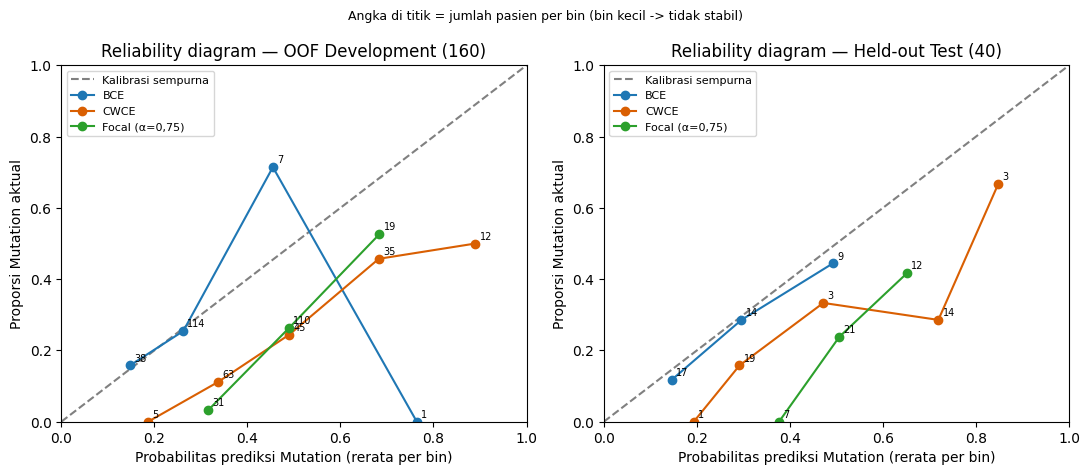

In [ ]:
# ===== LANGKAH 2: McNemar Mutation + Holm, lalu kalibrasi =====
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import brier_score_loss, roc_curve
from sklearn.linear_model import LogisticRegression

BASE = "/content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji"
with open(f"{BASE}/Model_Selection_Final/selected_scenario.json") as f:
    src = json.load(f)["source_dirs"]
cv_dir = {"BCE": src["BCE"], "CWCE": src["CWCE"], "FOCAL": f"{BASE}/ABMIL_FOCAL_a075_50ep"}
tpath = {"BCE":   f"{BASE}/Evaluasi_Held_out_Test/test_predictions_BCE.csv",
         "CWCE":  f"{BASE}/Evaluasi_Held_out_Test/test_predictions_CWCE.csv",
         "FOCAL": f"{BASE}/Perbaikan_Review/test_predictions_FOCAL_a075.csv"}
NAMES = ["BCE", "CWCE", "FOCAL"]
PAIRS = [("BCE", "CWCE"), ("BCE", "FOCAL"), ("CWCE", "FOCAL")]

OOF = {n: pd.read_csv(f"{cv_dir[n]}/all_validation_predictions.csv").sort_values("patient_id").reset_index(drop=True) for n in NAMES}
TST = {n: pd.read_csv(tpath[n]).sort_values("patient_id").reset_index(drop=True) for n in NAMES}
for n in NAMES:
    assert (OOF[n]["patient_id"].values == OOF["BCE"]["patient_id"].values).all()
    assert (TST[n]["patient_id"].values == TST["BCE"]["patient_id"].values).all()
y_oof, y_test = OOF["BCE"]["label"].values.astype(int), TST["BCE"]["label"].values.astype(int)
P_oof  = {n: OOF[n]["prob_mutation"].values.astype(float) for n in NAMES}
P_test = {n: TST[n]["prob_mutation"].values.astype(float) for n in NAMES}

def holm(p):
    p = np.asarray(p, float); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p); j = tpr - fpr; j[~np.isfinite(thr)] = -np.inf
    return float(thr[np.argmax(j)])

THR = {"fixed_0.5": {n: 0.5 for n in NAMES},
       "youden":    {n: youden(y_oof, P_oof[n]) for n in NAMES}}   # Youden dari OOF

# ---- 2A. McNemar exact kelas Mutation + Holm (per kelompok data x ambang) ----
rows = []
for data, y, P in [("OOF", y_oof, P_oof), ("TEST", y_test, P_test)]:
    for mode, thr in THR.items():
        grp = []
        for a, b in PAIRS:
            m = y == 1
            ha, hb = P[a][m] >= thr[a], P[b][m] >= thr[b]
            ao, bo = int((ha & ~hb).sum()), int((~ha & hb).sum()); n = ao + bo
            p = 1.0 if n == 0 else float(binomtest(min(ao, bo), n, 0.5).pvalue)
            grp.append((a, b, int(ha.sum()), int(hb.sum()), ao, bo, p))
        adj = holm([g[6] for g in grp])
        for g, pa in zip(grp, adj):
            rows.append(dict(data=data, ambang=mode, A=g[0], B=g[1], hit_A=g[2], hit_B=g[3],
                             A_benar_B_salah=g[4], A_salah_B_benar=g[5], p_exact=g[6], p_exact_holm=pa))
t2 = pd.DataFrame(rows)
print("=== 2A. McNemar exact kelas Mutation (Holm per kelompok) ===")
print(t2.round(4).to_string(index=False))

# ---- 2B. Kalibrasi: Brier, ECE 5-bin, Platt (fit OOF -> terapkan ke test) ----
def ece(y, p, k=5):
    idx = np.clip(np.digitize(p, np.linspace(0, 1, k + 1)[1:-1]), 0, k - 1); e = 0.0
    for b in range(k):
        m = idx == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

def lg(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)

rows = []
for data, y, P in [("oof", y_oof, P_oof), ("test", y_test, P_test)]:
    for n in NAMES:
        rows.append(dict(data=data, skenario=n, tipe="asli", n=len(y), brier=brier_score_loss(y, P[n]),
                         brier_baseline=y.mean() * (1 - y.mean()), ece_5bin=ece(y, P[n]),
                         rerata_prob=P[n].mean(), prevalensi=y.mean()))
for n in NAMES:
    pc = LogisticRegression(C=1e6).fit(lg(P_oof[n]), y_oof).predict_proba(lg(P_test[n]))[:, 1]
    rows.append(dict(data="test", skenario=n, tipe="Platt(fit OOF)", n=len(y_test),
                     brier=brier_score_loss(y_test, pc), brier_baseline=y_test.mean() * (1 - y_test.mean()),
                     ece_5bin=ece(y_test, pc), rerata_prob=pc.mean(), prevalensi=y_test.mean()))
t3 = pd.DataFrame(rows)
print("\n=== 2B. Kalibrasi (Brier lebih kecil = lebih baik; bandingkan dgn brier_baseline) ===")
print(t3.round(4).to_string(index=False))

# ---- 2C. Reliability diagram ----
col = {"BCE": "#1f77b4", "CWCE": "#d95f02", "FOCAL": "#2ca02c"}
lab = {"BCE": "BCE", "CWCE": "CWCE", "FOCAL": "Focal (α=0,75)"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (title, y, P) in zip(axes, [("OOF Development (160)", y_oof, P_oof), ("Held-out Test (40)", y_test, P_test)]):
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Kalibrasi sempurna")
    for n in NAMES:
        idx = np.clip(np.digitize(P[n], np.linspace(0, 1, 6)[1:-1]), 0, 4); xs, ys, ns = [], [], []
        for b in range(5):
            m = idx == b
            if m.any(): xs.append(P[n][m].mean()); ys.append(y[m].mean()); ns.append(int(m.sum()))
        ax.plot(xs, ys, "o-", color=col[n], label=lab[n])
        for x_, y_, n_ in zip(xs, ys, ns):
            ax.annotate(str(n_), (x_, y_), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"Reliability diagram — {title}"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Probabilitas prediksi Mutation (rerata per bin)"); ax.set_ylabel("Proporsi Mutation aktual"); ax.legend(fontsize=8)
fig.suptitle("Angka di titik = jumlah pasien per bin (bin kecil -> tidak stabil)", fontsize=9)
fig.tight_layout()

OUT = f"{BASE}/Perbaikan_Review2"; os.makedirs(OUT, exist_ok=True)
t2.to_csv(f"{OUT}/langkah2_mcnemar_mutation_holm.csv", index=False)
t3.to_csv(f"{OUT}/langkah2_kalibrasi.csv", index=False)
fig.savefig(f"{OUT}/langkah2_reliability_diagram.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# ================================================================
# LANGKAH 3: TUNING CWCE DI 5-FOLD CV (kesetaraan jatah tuning dengan Focal)
#   - Rasio bobot Mutation : Wild-Type  r ∈ {2, 3, 4}   (r=3 = CWCE yang sudah ada, dipakai ulang)
#   - Hanya Development Set (5-fold CV). DATA UJI TIDAK DISENTUH.
#   - Fold identik dengan skenario lain, hyperparameter identik, resume otomatis
#     (jalankan ulang cell yang sama jika Colab terputus).
# Keluaran: Perbaikan_Review2/cwce_tuning_cv_summary.csv + tabel perbandingan di layar
# ================================================================
import os, json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score

BASE_DIR        = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT       = f"{BASE_DIR}/Skenario Uji"
DEV_FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/train"
SPLIT_CSV       = f"{SCEN_ROOT}/cv5_splits/cv5_patient_fold_assignments.csv"
MODEL_ROOT      = f"{SCEN_ROOT}/Model_Selection_Final"
OUT_ROOT        = f"{SCEN_ROOT}/Perbaikan_Review2"
CACHE_DIR       = "/content/abmil_resnet50_cache_fp16"
RATIOS_NEW      = [2.0, 4.0]          # r=3 sudah ada (CWCE awal)
FEAT_DIM, ATT_DIM, LR = 2048, 256, 1e-4
MAX_EPOCHS, PATIENCE, SEED = 50, 10, 42    # sama dengan skenario sebelumnya
os.makedirs(OUT_ROOT, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# -------------------- DATA & CACHE (Development saja) ------------
dev_df = pd.read_csv(SPLIT_CSV)[["patient_id", "label", "fold"]].copy()
dev_df["patient_id"] = dev_df["patient_id"].astype(str).str.strip()
dev_df["label"] = dev_df["label"].astype(int); dev_df["fold"] = dev_df["fold"].astype(int)

def pid_from_name(p): return "-".join(Path(p).name.split("-")[:3])
files = {}
for fp in sorted(str(p) for p in Path(DEV_FEATURE_DIR).rglob("*.npz")):
    files.setdefault(pid_from_name(fp), []).append(fp)
files = {p: v[0] for p, v in files.items() if p in set(dev_df["patient_id"])}
missing = set(dev_df["patient_id"]) - set(files)
if missing: raise ValueError(f"Pasien tanpa fitur: {sorted(missing)[:10]}")

cache = {}
for pid, src in files.items():
    cp = Path(CACHE_DIR) / f"{pid}.pt"
    if not cp.exists():
        with np.load(src, allow_pickle=False) as z:
            arr = z["features"]
            assert arr.ndim == 2 and arr.shape[1] == FEAT_DIM and np.isfinite(arr).all(), src
            torch.save(torch.from_numpy(arr.copy()).to(torch.float16).contiguous(), cp)
    cache[pid] = str(cp)
print("Cache fitur siap:", len(cache), "pasien")

def load_bag(pid):
    return torch.load(cache[pid], map_location="cpu").to(device=DEVICE, dtype=torch.float32)

# -------------------- MODEL & LOSS (identik dgn skenario lama) ---
class ABMIL(nn.Module):
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(nn.Linear(feat_dim, att_dim), nn.Tanh(), nn.Linear(att_dim, 1))
        self.classifier = nn.Linear(feat_dim, 1)
    def forward(self, x):
        w = torch.softmax(self.attention(x), dim=0)
        return self.classifier(torch.sum(w * x, dim=0)).view(1)

class ClassWeightedBCE(nn.Module):
    def __init__(self, w_wt, w_mut):
        super().__init__()
        self.register_buffer("class_w", torch.tensor([w_wt, w_mut], dtype=torch.float32))
        self.bce = nn.BCEWithLogitsLoss(reduction="none")
    def forward(self, logits, y):
        return (self.bce(logits, y) * self.class_w[y.long()]).mean()

def metrics(y, p, thr=0.5):
    y = np.asarray(y, int); pred = (np.asarray(p) >= thr).astype(int)
    tn = int(((y == 0) & (pred == 0)).sum()); fp = int(((y == 0) & (pred == 1)).sum())
    fn = int(((y == 1) & (pred == 0)).sum()); tp = int(((y == 1) & (pred == 1)).sum())
    nan = float("nan")
    return {"accuracy": (tp + tn) / len(y),
            "precision": tp / (tp + fp) if tp + fp else nan,
            "recall": tp / (tp + fn) if tp + fn else nan,
            "f1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else nan,
            "auc": roc_auc_score(y, p)}

# -------------------- 5-FOLD CV UNTUK SATU RASIO -----------------
def train_cv_cwce(ratio):
    tag = f"r{int(round(ratio * 10)):02d}"
    run_dir = f"{SCEN_ROOT}/ABMIL_CWCE_{tag}_50ep"; os.makedirs(run_dir, exist_ok=True)
    results = []
    for fold in range(1, 6):
        fdir = f"{run_dir}/fold_{fold}"; os.makedirs(fdir, exist_ok=True)
        done, pred_path = f"{fdir}/fold_result.json", f"{fdir}/validation_predictions.csv"
        if os.path.exists(done) and os.path.exists(pred_path):
            results.append(json.load(open(done))); print(f"[r={ratio}] fold {fold} sudah selesai -> dilewati"); continue
        tr = dev_df[dev_df["fold"] != fold].reset_index(drop=True)
        va = dev_df[dev_df["fold"] == fold].reset_index(drop=True)
        n, n0 = len(tr), int((tr["label"] == 0).sum())
        w_wt = n / (2 * n0); w_mut = w_wt * ratio          # r=3 -> 0,667 : 2,0 (sama dgn CWCE awal)
        seed_all(SEED)
        model = ABMIL(FEAT_DIM, ATT_DIM).to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        crit = ClassWeightedBCE(w_wt, w_mut).to(DEVICE)
        best_loss, best_ep, wait, best_probs = float("inf"), 0, 0, None
        for ep in range(1, MAX_EPOCHS + 1):
            t0 = time.time(); model.train(); tl = []
            for row in tr.sample(frac=1, random_state=SEED + ep).itertuples(index=False):
                x = load_bag(str(row.patient_id)); y = torch.tensor([float(row.label)], device=DEVICE)
                opt.zero_grad(set_to_none=True); loss = crit(model(x), y); loss.backward(); opt.step(); tl.append(loss.item())
            model.eval(); vl, vp = [], []
            with torch.no_grad():
                for row in va.itertuples(index=False):
                    lg = model(load_bag(str(row.patient_id)))
                    vl.append(crit(lg, torch.tensor([float(row.label)], device=DEVICE)).item()); vp.append(torch.sigmoid(lg).item())
            val_loss = float(np.mean(vl))
            print(f"[r={ratio}] fold {fold} ep {ep:02d} | train={np.mean(tl):.4f} val={val_loss:.4f} | {time.time()-t0:.1f}s")
            if val_loss < best_loss: best_loss, best_ep, wait, best_probs = val_loss, ep, 0, list(vp)
            else:
                wait += 1
                if wait >= PATIENCE: print(f"[r={ratio}] early stopping ep {ep} (best={best_ep})"); break
        res = {"fold": fold, "ratio": ratio, "best_epoch": best_ep, "best_val_loss": best_loss,
               **metrics(va["label"].values, best_probs)}
        pd.DataFrame({"patient_id": va["patient_id"], "label": va["label"], "prob_mutation": best_probs,
                      "fold": fold, "best_epoch": best_ep}).to_csv(pred_path, index=False)
        json.dump(res, open(done, "w"), default=float)
        results.append(res)
        del model, opt, crit
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    fm = pd.DataFrame(results).sort_values("fold").reset_index(drop=True)
    fm.to_csv(f"{run_dir}/fold_metrics.csv", index=False)
    return fm

runs = {r: train_cv_cwce(r) for r in RATIOS_NEW}

# r=3: pakai hasil CWCE yang sudah ada (tanpa training ulang)
with open(f"{MODEL_ROOT}/selected_scenario.json") as f:
    cwce_dir = json.load(f)["source_dirs"]["CWCE"]
runs[3.0] = pd.read_csv(os.path.join(cwce_dir, "fold_metrics.csv"))

# -------------------- RINGKASAN ----------------------------------
rows = []
for r in sorted(runs):
    fm = runs[r]; row = {"skenario": f"CWCE rasio {r:g}:1", "best_epoch": fm["best_epoch"].mean()}
    for m in ["auc", "recall", "precision", "f1"]:
        row[m] = f"{fm[m].mean():.3f} ± {fm[m].std(ddof=1):.3f}"
    rows.append(row)
for a in ["a050", "a075"]:            # Focal sebagai pembanding (sudah ada)
    p = f"{SCEN_ROOT}/ABMIL_FOCAL_{a}_50ep/fold_metrics.csv"
    if os.path.exists(p):
        fm = pd.read_csv(p); row = {"skenario": f"Focal α={int(a[1:])/100:g}", "best_epoch": fm["best_epoch"].mean()}
        for m in ["auc", "recall", "precision", "f1"]:
            row[m] = f"{fm[m].mean():.3f} ± {fm[m].std(ddof=1):.3f}"
        rows.append(row)
summ = pd.DataFrame(rows)
summ.to_csv(f"{OUT_ROOT}/cwce_tuning_cv_summary.csv", index=False)
print("\n" + "=" * 70 + "\nTUNING CWCE vs FOCAL (5-fold CV, Development Set)\n" + "=" * 70)
print(summ.to_string(index=False))
best = max(runs, key=lambda r: (runs[r]["auc"].mean(), runs[r]["recall"].mean()))
print(f"\nCWCE rasio terbaik menurut AUC CV: {best:g}:1  (dibanding Focal α=0,75: lihat tabel)")
print("CATATAN: data uji TIDAK dievaluasi ulang. Laporkan sebagai analisis sensitivitas CV.")

DEVICE: cuda
Cache fitur siap: 160 pasien
[r=2.0] fold 1 sudah selesai -> dilewati
[r=2.0] fold 2 sudah selesai -> dilewati
[r=2.0] fold 3 sudah selesai -> dilewati
[r=2.0] fold 4 sudah selesai -> dilewati
[r=2.0] fold 5 sudah selesai -> dilewati
[r=4.0] fold 1 sudah selesai -> dilewati
[r=4.0] fold 2 sudah selesai -> dilewati
[r=4.0] fold 3 sudah selesai -> dilewati
[r=4.0] fold 4 sudah selesai -> dilewati
[r=4.0] fold 5 sudah selesai -> dilewati

TUNING CWCE vs FOCAL (5-fold CV, Development Set)
      skenario  best_epoch           auc        recall     precision            f1
CWCE rasio 2:1        11.6 0.749 ± 0.087 0.450 ± 0.288 0.644 ± 0.137 0.469 ± 0.281
CWCE rasio 3:1         8.2 0.733 ± 0.117 0.725 ± 0.163 0.452 ± 0.124 0.555 ± 0.136
CWCE rasio 4:1        12.6 0.790 ± 0.103 0.875 ± 0.088 0.456 ± 0.175 0.580 ± 0.146
   Focal α=0.5         9.2 0.707 ± 0.100 0.300 ± 0.360 0.861 ± 0.127 0.337 ± 0.372
  Focal α=0.75         8.4 0.760 ± 0.095 0.650 ± 0.240 0.410 ± 0.088 0.490 ± 0.137

             TN    FP    FN    TP  recall  spesifisitas  bal_acc    MCC  AUC_gabungan  AP_gabungan
CWCE 2:1  109.0  11.0  22.0  18.0   0.450         0.908    0.679  0.403         0.768        0.596
CWCE 3:1   84.0  36.0  11.0  29.0   0.725         0.700    0.712  0.375         0.758        0.508
CWCE 4:1   67.0  53.0   5.0  35.0   0.875         0.558    0.717  0.377         0.789        0.568


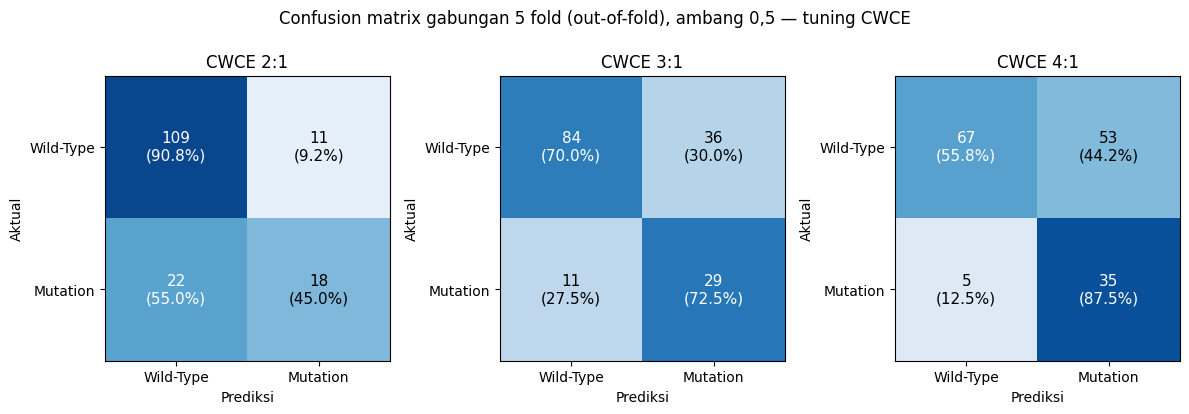

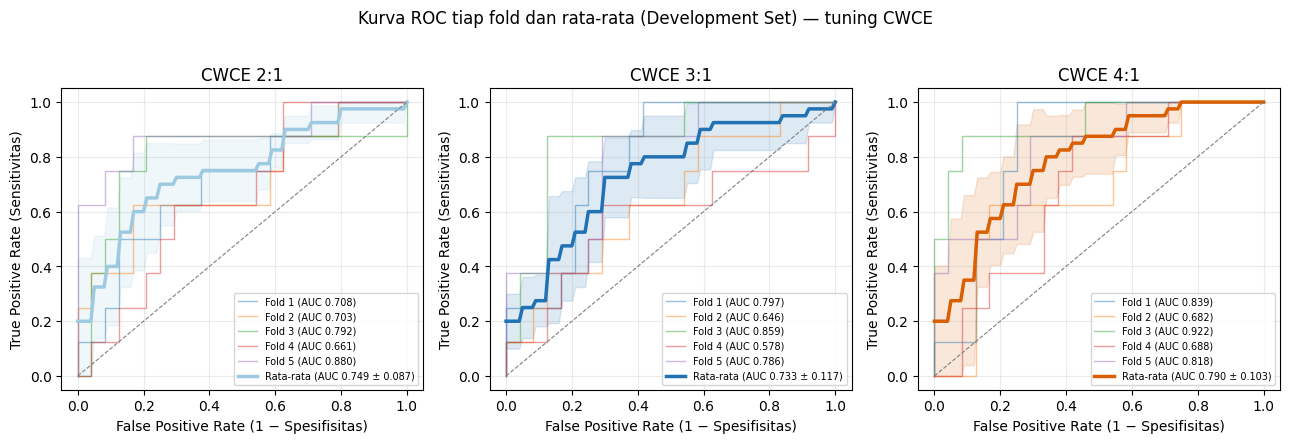

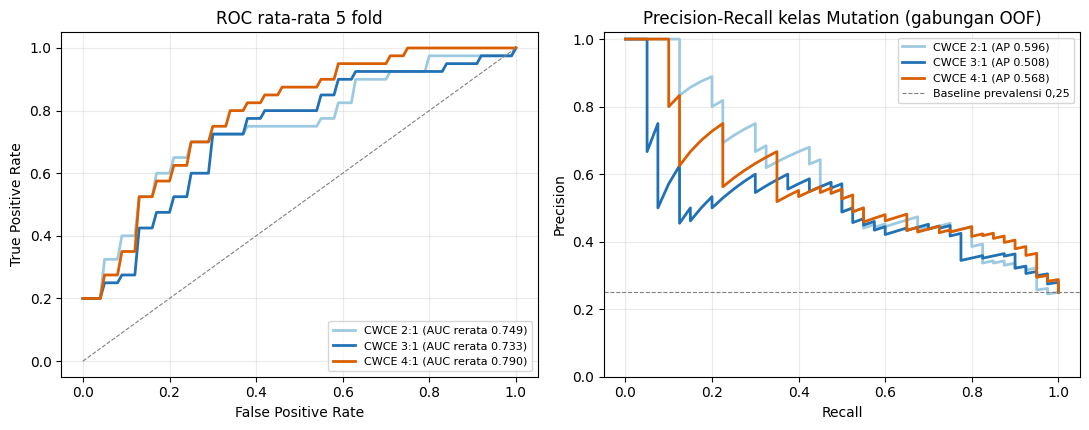

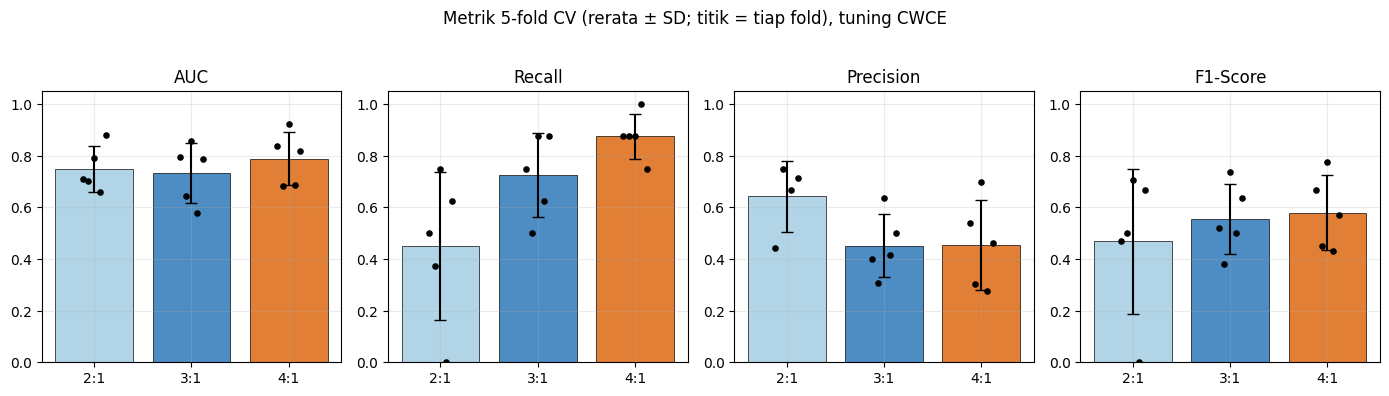

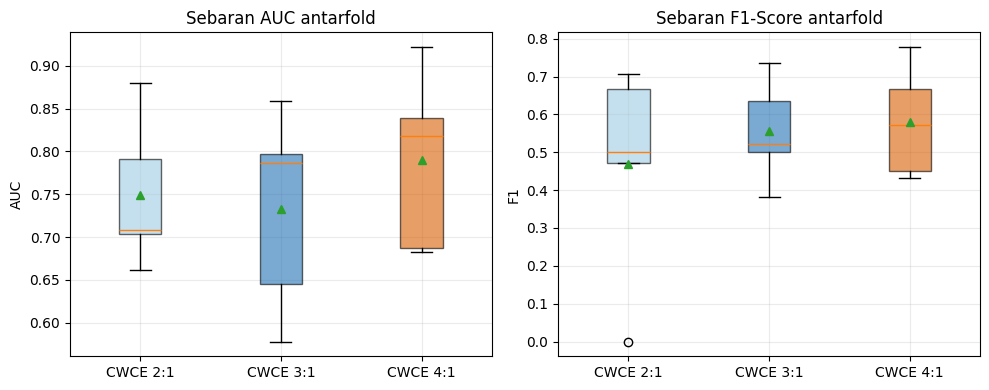


Selesai. Berkas tersimpan di: /content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji/Perbaikan_Review2/Visualisasi_CWCE_Tuning


In [ ]:
# ================================================================
# VISUALISASI CWCE TUNING (rasio 2:1, 3:1, 4:1) — 5-fold CV Development Set
# Hanya membaca prediksi yang sudah tersimpan. Tidak ada pelatihan ulang,
# data uji TIDAK dipakai. Keluaran: PNG + CSV di Perbaikan_Review2/Visualisasi_CWCE_Tuning
# ================================================================
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, matthews_corrcoef, confusion_matrix)

BASE      = "/content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji"
SPLIT_CSV = f"{BASE}/cv5_splits/cv5_patient_fold_assignments.csv"
OUT       = f"{BASE}/Perbaikan_Review2/Visualisasi_CWCE_Tuning"
os.makedirs(OUT, exist_ok=True)

with open(f"{BASE}/Model_Selection_Final/selected_scenario.json") as f:
    cwce31_dir = json.load(f)["source_dirs"]["CWCE"]          # CWCE 3:1 (awal)

CFG = {   # nama: (folder, file_prediksi_gabungan_atau_None)
    "CWCE 2:1": (f"{BASE}/ABMIL_CWCE_r20_50ep", None),
    "CWCE 3:1": (cwce31_dir, "all_validation_predictions.csv"),
    "CWCE 4:1": (f"{BASE}/ABMIL_CWCE_r40_50ep", None),
}
COL = {"CWCE 2:1": "#9ecae1", "CWCE 3:1": "#2171b5", "CWCE 4:1": "#d95f02"}
folds_ref = pd.read_csv(SPLIT_CSV)[["patient_id", "fold"]].astype({"patient_id": str})

def load_oof(folder, combined):
    if combined and os.path.exists(os.path.join(folder, combined)):
        df = pd.read_csv(os.path.join(folder, combined))
    else:
        df = pd.concat([pd.read_csv(f"{folder}/fold_{k}/validation_predictions.csv") for k in range(1, 6)])
    df["patient_id"] = df["patient_id"].astype(str)
    df = df.drop(columns=[c for c in ["fold"] if c in df.columns]).merge(folds_ref, on="patient_id", how="left")
    assert df["fold"].notna().all() and len(df) == 160, f"{folder}: {len(df)} baris / fold hilang"
    return df.sort_values(["fold", "patient_id"]).reset_index(drop=True)

OOF = {n: load_oof(*v) for n, v in CFG.items()}

def cm_stats(y, p, thr=0.5):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    rec = tp / (tp + fn); spe = tn / (tn + fp)
    return dict(TN=tn, FP=fp, FN=fn, TP=tp, recall=rec, spesifisitas=spe, bal_acc=(rec + spe) / 2,
                MCC=matthews_corrcoef(y, pred), AUC_gabungan=roc_auc_score(y, p),
                AP_gabungan=average_precision_score(y, p))

summ = pd.DataFrame({n: cm_stats(d["label"].values, d["prob_mutation"].values) for n, d in OOF.items()}).T
summ.round(3).to_csv(f"{OUT}/cwce_tuning_oof_ringkasan.csv"); print(summ.round(3).to_string())

# ---- per-fold metrik (AUC, F1, recall, precision) untuk sebaran & batang ----
rows = []
for n, d in OOF.items():
    for k, g in d.groupby("fold"):
        y, p = g["label"].values, g["prob_mutation"].values; pr = (p >= 0.5).astype(int)
        tp = ((y == 1) & (pr == 1)).sum(); fp = ((y == 0) & (pr == 1)).sum(); fn = ((y == 1) & (pr == 0)).sum()
        rows.append(dict(skenario=n, fold=k, auc=roc_auc_score(y, p), recall=tp / (tp + fn),
                         precision=tp / (tp + fp) if tp + fp else np.nan, f1=2 * tp / (2 * tp + fp + fn)))
PF = pd.DataFrame(rows); PF.to_csv(f"{OUT}/cwce_tuning_per_fold.csv", index=False)

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25})
fpr_grid = np.linspace(0, 1, 101)

# 1) Confusion matrix gabungan OOF (3 panel)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (n, d) in zip(axs, OOF.items()):
    cm = confusion_matrix(d["label"], (d["prob_mutation"] >= 0.5).astype(int), labels=[0, 1])
    pct = cm / cm.sum(1, keepdims=True) * 100
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.1f}%)", ha="center", va="center",
                    color="white" if pct[i, j] > 55 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["Wild-Type", "Mutation"]); ax.set_yticks([0, 1], ["Wild-Type", "Mutation"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title(n)
fig.suptitle("Confusion matrix gabungan 5 fold (out-of-fold), ambang 0,5 — tuning CWCE", y=1.02)
fig.tight_layout(); fig.savefig(f"{OUT}/1_confusion_matrix_cwce_tuning.png", dpi=200, bbox_inches="tight"); plt.show()

# 2) ROC per fold + rata-rata, per rasio (3 panel)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3)); mean_curves = {}
for ax, (n, d) in zip(axs, OOF.items()):
    tprs, aucs = [], []
    for k, g in d.groupby("fold"):
        f_, t_, _ = roc_curve(g["label"], g["prob_mutation"]); a = roc_auc_score(g["label"], g["prob_mutation"])
        ax.plot(f_, t_, lw=1, alpha=0.45, label=f"Fold {k} (AUC {a:.3f})")
        tprs.append(np.interp(fpr_grid, f_, t_)); aucs.append(a)
    mt, st = np.mean(tprs, 0), np.std(tprs, 0); mean_curves[n] = mt
    ax.plot(fpr_grid, mt, color=COL[n], lw=2.5, label=f"Rata-rata (AUC {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f})")
    ax.fill_between(fpr_grid, np.clip(mt - st, 0, 1), np.clip(mt + st, 0, 1), color=COL[n], alpha=0.15)
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=0.8); ax.set_title(n)
    ax.set_xlabel("False Positive Rate (1 − Spesifisitas)"); ax.set_ylabel("True Positive Rate (Sensitivitas)"); ax.legend(fontsize=7, loc="lower right")
fig.suptitle("Kurva ROC tiap fold dan rata-rata (Development Set) — tuning CWCE", y=1.02)
fig.tight_layout(); fig.savefig(f"{OUT}/2_roc_per_fold_cwce_tuning.png", dpi=200, bbox_inches="tight"); plt.show()

# 3) ROC rata-rata (overlay) + Precision-Recall gabungan (overlay)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for n, d in OOF.items():
    a = np.mean([roc_auc_score(g["label"], g["prob_mutation"]) for _, g in d.groupby("fold")])
    axs[0].plot(fpr_grid, mean_curves[n], color=COL[n], lw=2, label=f"{n} (AUC rerata {a:.3f})")
    pr, rc, _ = precision_recall_curve(d["label"], d["prob_mutation"])
    axs[1].plot(rc, pr, color=COL[n], lw=2, label=f"{n} (AP {average_precision_score(d['label'], d['prob_mutation']):.3f})")
axs[0].plot([0, 1], [0, 1], "--", color="gray", lw=0.8); axs[0].set_title("ROC rata-rata 5 fold")
axs[0].set_xlabel("False Positive Rate"); axs[0].set_ylabel("True Positive Rate"); axs[0].legend(fontsize=8, loc="lower right")
axs[1].axhline(0.25, ls="--", color="gray", lw=0.8, label="Baseline prevalensi 0,25"); axs[1].set_title("Precision-Recall kelas Mutation (gabungan OOF)")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_ylim(0, 1.02); axs[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/3_roc_pr_overlay_cwce_tuning.png", dpi=200, bbox_inches="tight"); plt.show()

# 4) Metrik 5-fold CV (rerata ± SD, titik = tiap fold) + 5) Sebaran AUC dan F1 antarfold
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, m, t in zip(axs, ["auc", "recall", "precision", "f1"], ["AUC", "Recall", "Precision", "F1-Score"]):
    for i, n in enumerate(OOF):
        v = PF.loc[PF.skenario == n, m].dropna().values
        ax.bar(i, v.mean(), yerr=v.std(ddof=1), capsize=4, color=COL[n], alpha=0.8, edgecolor="black", lw=0.6)
        ax.scatter(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, color="black", s=14, zorder=3)
    ax.set_xticks(range(3), [n.replace("CWCE ", "") for n in OOF]); ax.set_ylim(0, 1.05); ax.set_title(t)
fig.suptitle("Metrik 5-fold CV (rerata ± SD; titik = tiap fold), tuning CWCE", y=1.03)
fig.tight_layout(); fig.savefig(f"{OUT}/4_metrik_cv_cwce_tuning.png", dpi=200, bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, m, t in zip(axs, ["auc", "f1"], ["Sebaran AUC antarfold", "Sebaran F1-Score antarfold"]):
    data = [PF.loc[PF.skenario == n, m].dropna().values for n in OOF]
    bp = ax.boxplot(data, patch_artist=True, showmeans=True, tick_labels=list(OOF))
    for patch, n in zip(bp["boxes"], OOF): patch.set_facecolor(COL[n]); patch.set_alpha(0.6)
    ax.set_title(t); ax.set_ylabel(m.upper())
fig.tight_layout(); fig.savefig(f"{OUT}/5_sebaran_auc_f1_cwce_tuning.png", dpi=200, bbox_inches="tight"); plt.show()
print("\nSelesai. Berkas tersimpan di:", OUT)

DEVICE: cuda
Berkas fitur test: 40

SKENARIO: BCE
Selisih maks prob (hitung ulang vs CSV): 0.00004  OK
  grid 359x296 (langkah x=224, y=224); terisi 32%
  gambar jaringan: 33611/33611 patch terbaca


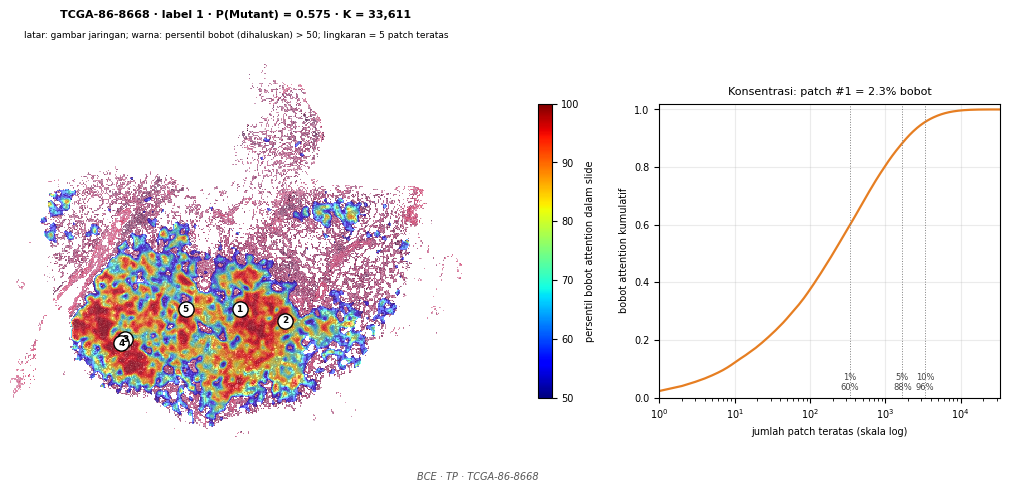

  grid 129x170 (langkah x=224, y=224); terisi 58%
  gambar jaringan: 12804/12804 patch terbaca


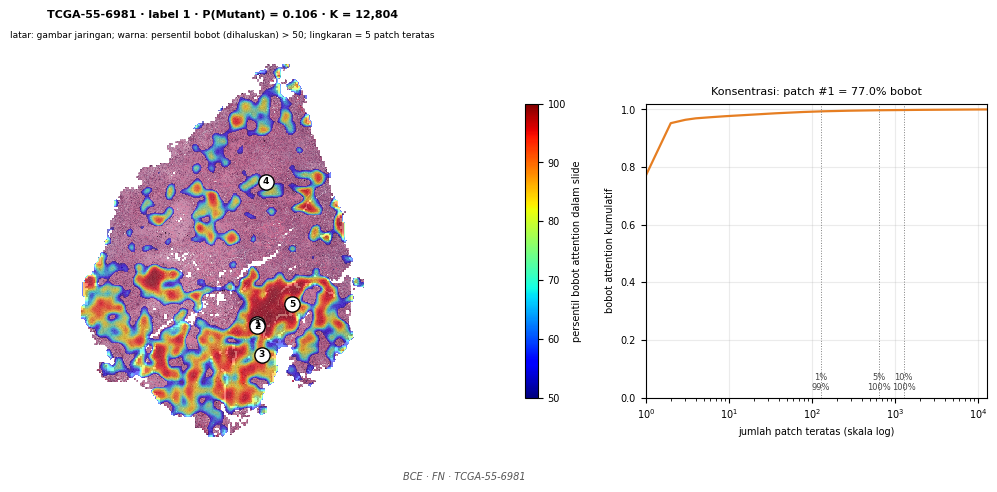

  grid 726x375 (langkah x=224, y=224); terisi 49%
  gambar jaringan: 133847/133847 patch terbaca


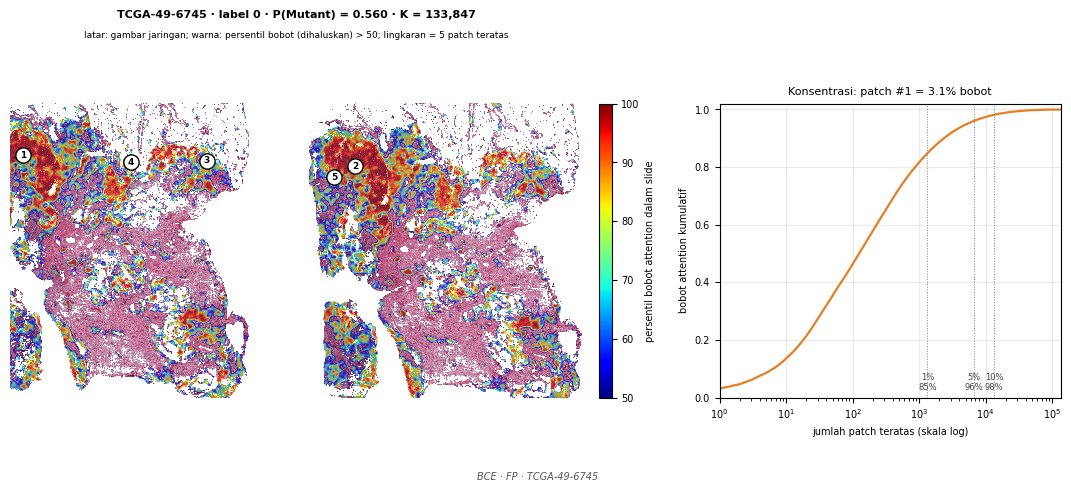


SKENARIO: CWCE
Selisih maks prob (hitung ulang vs CSV): 0.00005  OK
  grid 359x296 (langkah x=224, y=224); terisi 32%


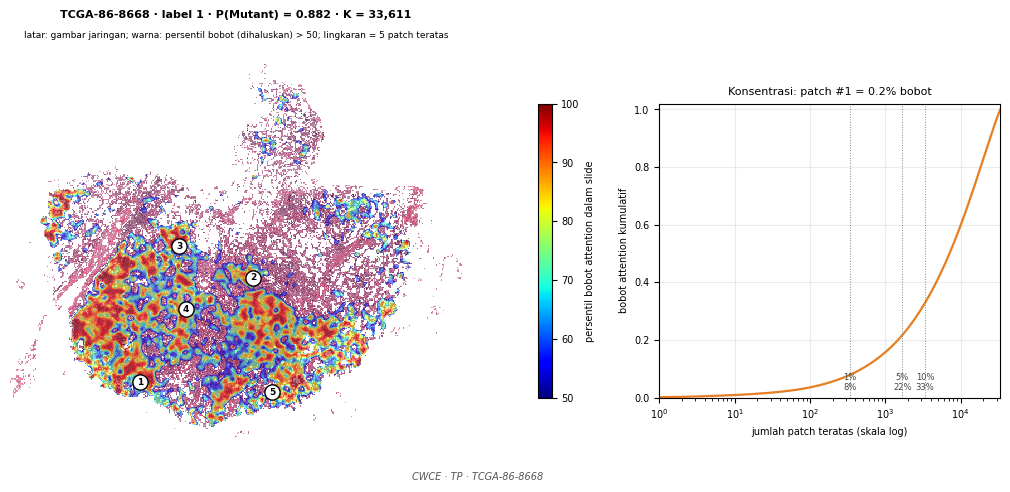

  grid 566x329 (langkah x=224, y=224); terisi 41%
  gambar jaringan: 76423/76423 patch terbaca


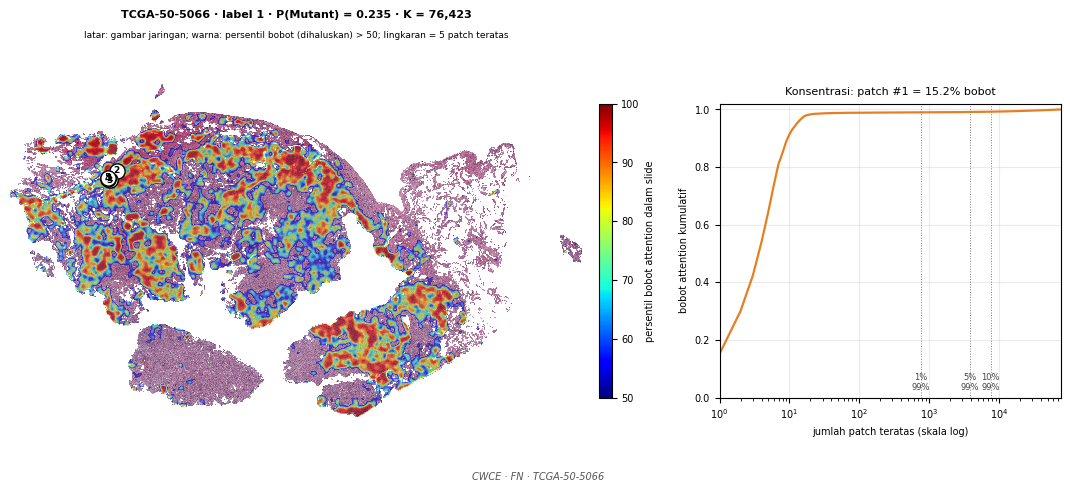

  grid 396x396 (langkah x=224, y=224); terisi 6%
  gambar jaringan: 9549/9549 patch terbaca


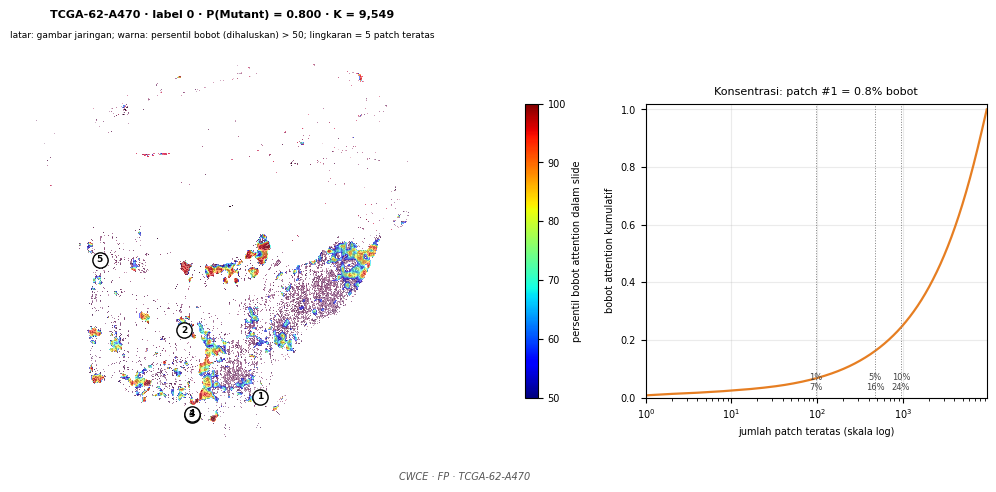


SKENARIO: Focal Loss (α=0,75)
Selisih maks prob (hitung ulang vs CSV): 0.00002  OK
  grid 359x296 (langkah x=224, y=224); terisi 32%


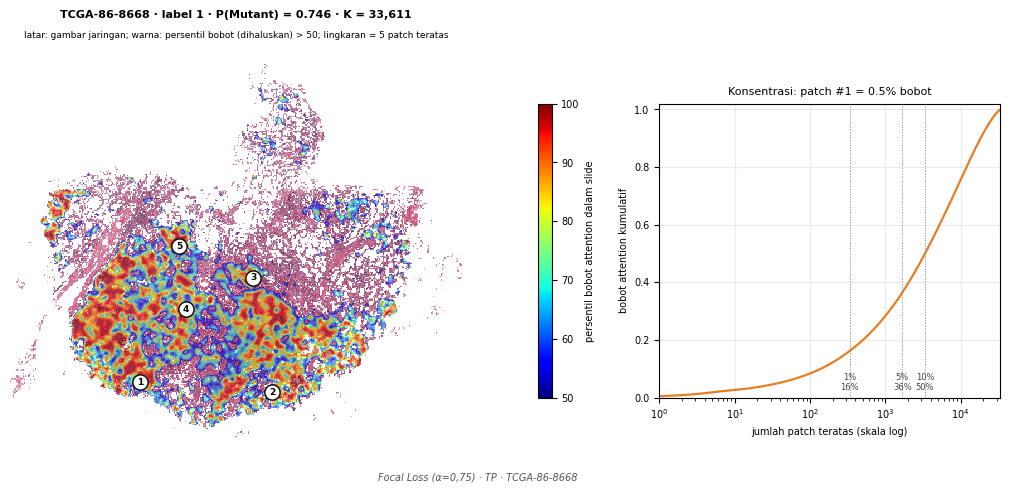

  grid 382x304 (langkah x=224, y=224); terisi 36%
  gambar jaringan: 42165/42165 patch terbaca


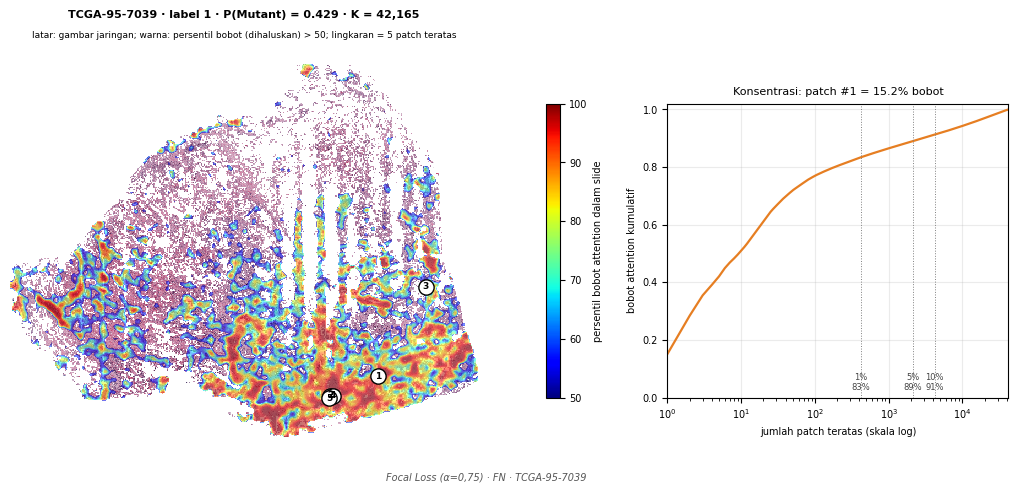

  grid 380x240 (langkah x=224, y=224); terisi 31%
  gambar jaringan: 28587/28587 patch terbaca


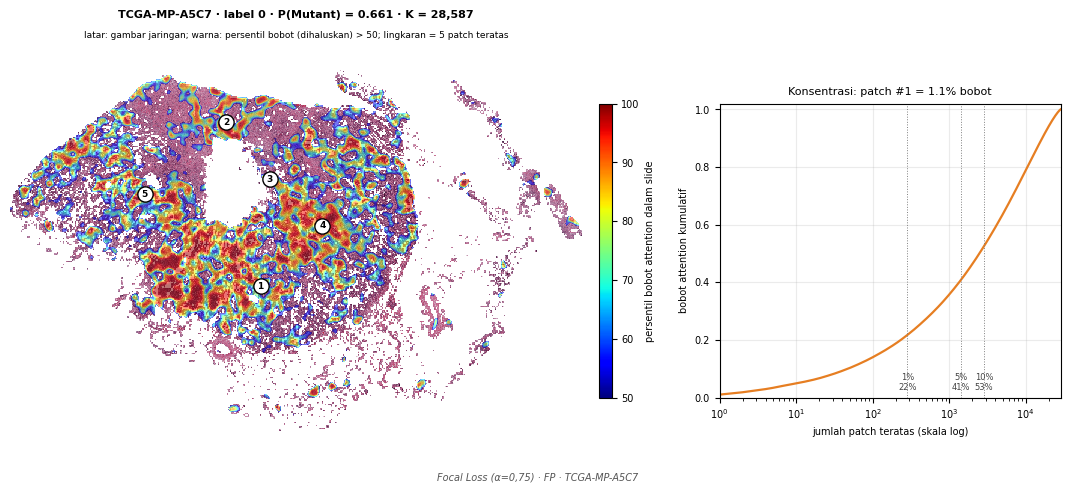


RINGKASAN KONSENTRASI ATTENTION
skenario kasus   patient_id  label  prob_mutation  n_kasus_kategori      K  top1_patch  top1pct  top5pct  top10pct  n_efektif
     BCE    TP TCGA-86-8668      1          0.575                 2  33611       0.023    0.598    0.883     0.956    349.388
     BCE    FN TCGA-55-6981      1          0.106                 8  12804       0.770    0.993    0.997     0.998      1.597
     BCE    FP TCGA-49-6745      0          0.560                 2 133847       0.031    0.848    0.960     0.981    248.747
    CWCE    TP TCGA-86-8668      1          0.882                 6  33611       0.002    0.079    0.217     0.329  14874.453
    CWCE    FN TCGA-50-5066      1          0.235                 4  76423       0.152    0.990    0.991     0.992      9.691
    CWCE    FP TCGA-62-A470      0          0.800                12   9549       0.008    0.067    0.163     0.244   4171.734
   FOCAL    TP TCGA-86-8668      1          0.746                 8  33611       0.00

In [ ]:
# ================================================================
# LANGKAH 4: HEATMAP ATTENTION ABMIL — BCE, CWCE, FOCAL (α=0,75)
#   Per skenario: 1 contoh TP, 1 FN, 1 FP dari HELD-OUT TEST (ambang 0,5).
#   Aturan pemilihan KASUS (otomatis, bukan dipilih-pilih):
#     TP = Mutation dgn P(Mutation) tertinggi di antara yang diprediksi Mutation
#     FN = Mutation dgn P(Mutation) terendah (paling meleset)
#     FP = Wild-Type dgn P(Mutation) tertinggi
#   Tidak ada pelatihan ulang & tidak ada evaluasi ulang; hanya membaca model final
#   yang sudah ada dan menghitung bobot attention. Hasil: PNG per kasus + CSV ringkasan.
# ================================================================
import os, json, glob, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter, zoom

BASE_DIR  = "/content/drive/MyDrive/TCGA-LUAD-WSI"
SCEN_ROOT = f"{BASE_DIR}/Skenario Uji"
TEST_FEATURE_DIR = f"{BASE_DIR}/Features_ResNet50/test"
MODEL_ROOT = f"{SCEN_ROOT}/Model_Selection_Final"
OUT_DIR   = f"{SCEN_ROOT}/Perbaikan_Review2/Heatmap_Attention"
CKPT = {"BCE":   f"{MODEL_ROOT}/final_BCE/final_model.pt",
        "CWCE":  f"{MODEL_ROOT}/final_CWCE/final_model.pt",
        "FOCAL": f"{SCEN_ROOT}/Perbaikan_Review/final_FOCAL_a075.pt"}          # Focal α=0,75
TEST_PRED = {"BCE":   f"{SCEN_ROOT}/Evaluasi_Held_out_Test/test_predictions_BCE.csv",
             "CWCE":  f"{SCEN_ROOT}/Evaluasi_Held_out_Test/test_predictions_CWCE.csv",
             "FOCAL": f"{SCEN_ROOT}/Perbaikan_Review/test_predictions_FOCAL_a075.csv"}
LABEL_NAME = {"BCE": "BCE", "CWCE": "CWCE", "FOCAL": "Focal Loss (α=0,75)"}

# Opsional: gambar jaringan asli sebagai latar. Isi dengan folder zip patch Macenko
# (susunan <split>/<label>/<slide>.zip). None = latar = peta jaringan (tissue detection).
# CATATAN: membaca seluruh patch 1 slide (~1-3 menit per slide, 9 slide); hasil di-cache di /content.
ALPHA_OVL    = 0.55       # transparansi warna heatmap di atas gambar jaringan (peta polos: 0,85)
MACENKO_ROOT = "/content/drive/MyDrive/TCGA-LUAD-WSI/Patches_Macenko"   # None = peta jaringan polos
TILE_PX      = 6          # ukuran piksel per patch pada latar gambar jaringan
SMOOTH       = 1.5        # sigma penghalusan (satuan patch); 0 = tanpa penghalusan
ZOOM         = 4          # resolusi render peta (piksel per patch) bila tanpa gambar jaringan
PCT_MIN      = 50         # hanya patch dgn persentil bobot > 50 yang diwarnai
TOPK_MARK    = 5          # jumlah patch teratas yang diberi nomor
THRESHOLD    = 0.5
CASE_OVERRIDE = {}        # mis. {"CWCE": {"TP": "TCGA-86-8668"}}; kosong = otomatis
SHOW = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(OUT_DIR, exist_ok=True)
print("DEVICE:", DEVICE)

class ABMIL(nn.Module):                       # identik dgn skenario lama
    def __init__(self, feat_dim=2048, att_dim=256):
        super().__init__()
        self.attention = nn.Sequential(nn.Linear(feat_dim, att_dim), nn.Tanh(), nn.Linear(att_dim, 1))
        self.classifier = nn.Linear(feat_dim, 1)
    def forward(self, x, return_att=False):
        w = torch.softmax(self.attention(x), dim=0)
        logit = self.classifier(torch.sum(w * x, dim=0)).view(1)
        return (logit, w.view(-1)) if return_att else logit

def pid_from_name(p): return "-".join(Path(p).name.split("-")[:3])
feat_files = {}
for fp in sorted(str(p) for p in Path(TEST_FEATURE_DIR).rglob("*.npz")):
    feat_files.setdefault(pid_from_name(fp), fp)
print("Berkas fitur test:", len(feat_files))

def load_slide(pid):
    with np.load(feat_files[pid], allow_pickle=False) as z:
        feats = z["features"].astype(np.float32)
        x, y = z["x"].astype(np.int64), z["y"].astype(np.int64)
        names = [str(s) for s in z["patch"]]
        slide = str(z["slide"])
    return feats, x, y, names, slide

def load_model(path):
    ck = torch.load(path, map_location="cpu")
    sd = ck["model_state_dict"] if isinstance(ck, dict) and "model_state_dict" in ck else ck
    m = ABMIL(ck.get("feat_dim", 2048) if isinstance(ck, dict) else 2048,
              ck.get("att_dim", 256) if isinstance(ck, dict) else 256)
    m.load_state_dict(sd); return m.to(DEVICE).eval()

@torch.no_grad()
def infer(model, feats):
    logit, w = model(torch.from_numpy(feats).to(DEVICE), return_att=True)
    return torch.sigmoid(logit).item(), w.float().cpu().numpy()

def grid_index(x, y):
    """Indeks grid. Langkah (stride) patch ditaksir dari jarak antarkoordinat yang paling sering muncul,
    lalu dinaikkan ke kelipatannya (x2..x4) bila >=90% patch tetap berada di kisi tsb. Ini mencegah kolom/baris
    kosong (garis putih) akibat patch tepi yang posisinya bergeser setengah langkah."""
    def idx(v):
        d = np.diff(np.unique(v)); d = d[d > 0]
        if len(d) == 0: return np.zeros(len(v), int), 1
        vals, cnt = np.unique(d, return_counts=True); best = int(vals[np.argmax(cnt)])
        d0, o = best, v - v.min()
        for k in (2, 3, 4):
            dk = d0 * k; res = o % dk; r = np.bincount(res).argmax()
            dist = np.minimum(np.abs(res - r), dk - np.abs(res - r))
            if np.mean(dist <= 0.02 * dk) >= 0.90: best = dk
        return np.rint(o / best).astype(int), best
    (gx, sx), (gy, sy) = idx(x), idx(y)
    print(f"  grid {gx.max()+1}x{gy.max()+1} (langkah x={sx}, y={sy}); terisi {len(set(zip(gx, gy)))/((gx.max()+1)*(gy.max()+1)):.0%}")
    return gx, gy

def tissue_mosaic(slide, names, gx, gy):
    """Latar gambar jaringan dari patch Macenko (opsional)."""
    if not MACENKO_ROOT: return None
    import cv2
    H, W = gy.max() + 1, gx.max() + 1
    cache = f"/content/mosaic_{slide}_{H}x{W}_t{TILE_PX}.npy"      # kunci cache memuat ukuran grid
    if os.path.exists(cache): return np.load(cache)
    zp = glob.glob(f"{MACENKO_ROOT}/**/{slide}.zip", recursive=True)
    if not zp: print("  zip patch tidak ditemukan -> latar peta jaringan"); return None
    img = np.full((H * TILE_PX, W * TILE_PX, 3), 255, np.uint8)
    ok = 0
    with zipfile.ZipFile(zp[0]) as zf:
        mem = {Path(n).name: n for n in zf.namelist()}
        for nm, i, j in zip(names, gx, gy):
            k = mem.get(Path(nm).name)
            if k is None: continue
            a = cv2.imdecode(np.frombuffer(zf.read(k), np.uint8), cv2.IMREAD_REDUCED_COLOR_4)
            if a is None: continue
            t = cv2.resize(a, (TILE_PX, TILE_PX), interpolation=cv2.INTER_AREA)[:, :, ::-1]
            img[j * TILE_PX:(j + 1) * TILE_PX, i * TILE_PX:(i + 1) * TILE_PX] = t; ok += 1
    print(f"  gambar jaringan: {ok}/{len(names)} patch terbaca")
    if ok < 0.5 * len(names): print("  PERINGATAN: nama patch tidak cocok dgn isi zip -> latar jelek"); return None
    np.save(cache, img); return img

def concentration(w):
    s = np.sort(w)[::-1]; c = np.cumsum(s); K = len(w)
    at = lambda f: float(c[max(int(np.ceil(f * K)) - 1, 0)])
    return dict(K=K, top1_patch=float(s[0]), top1pct=at(.01), top5pct=at(.05), top10pct=at(.10),
                n_efektif=float(1.0 / np.sum(w ** 2)))

def plot_case(scn, kind, pid, label, prob, w, x, y, names, slide):
    gx, gy = grid_index(x, y); H, W = gy.max() + 1, gx.max() + 1
    K = len(w); order = np.argsort(-w); rank = np.empty(K, int); rank[order] = np.arange(K)
    pct = 100.0 * (1.0 - rank / max(K - 1, 1))                       # persentil bobot (100 = terbesar)
    cmap = matplotlib.colormaps["jet"]; norm = Normalize(PCT_MIN, 100)
    mosaic = tissue_mosaic(slide, names, gx, gy)
    A = np.zeros((H, W)); Mk = np.zeros((H, W)); A[gy, gx] = pct; Mk[gy, gx] = 1.0
    if SMOOTH > 0:                                     # haluskan bobot di sekitar patch & tutup lubang kecil
        den = gaussian_filter(Mk, SMOOTH); S = gaussian_filter(A * Mk, SMOOTH) / np.maximum(den, 1e-6)
        tissue = den > 0.25
    else:
        S, tissue = A, Mk > 0
    P = np.zeros((H, W)); v = S[tissue]
    P[tissue] = 100.0 * v.argsort().argsort() / max(len(v) - 1, 1)          # persentil ulang di dalam jaringan
    Z = TILE_PX if mosaic is not None else ZOOM
    Pz = zoom(P, Z, order=1); Tz = zoom(tissue.astype(float), Z, order=1) > 0.5
    if mosaic is not None: base = mosaic.astype(float) / 255.0
    else:
        base = np.ones((H * Z, W * Z, 3)); base[Tz] = (0.95, 0.88, 0.91)       # peta jaringan
    comp = base.copy(); hot = Tz & (Pz > PCT_MIN)
    al = ALPHA_OVL if mosaic is not None else 0.85
    comp[hot] = (1 - al) * base[hot] + al * cmap(norm(Pz[hot]))[:, :3]

    fig = plt.figure(figsize=(11, 4.9))
    ax = fig.add_axes([0.02, 0.10, 0.52, 0.76]); cax = fig.add_axes([0.555, 0.18, 0.012, 0.60])
    ax2 = fig.add_axes([0.665, 0.18, 0.31, 0.60])
    ax.imshow(comp, extent=(0, W, H, 0), interpolation="nearest"); ax.set_axis_off()
    for r, idx in enumerate(order[:TOPK_MARK], 1):
        ax.plot(gx[idx] + .5, gy[idx] + .5, "o", ms=11, mfc="white", mec="black", mew=1)
        ax.text(gx[idx] + .5, gy[idx] + .5, str(r), ha="center", va="center", fontsize=6.5, fontweight="bold")
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    cb.set_label("persentil bobot attention dalam slide", fontsize=7); cb.ax.tick_params(labelsize=7)
    fig.text(0.28, 0.955, f"{slide[:12]} · label {label} · P(Mutant) = {prob:.3f} · K = {K:,}".replace(",", ","),
             ha="center", fontsize=8, fontweight="bold")
    fig.text(0.28, 0.915, f"latar: {'gambar jaringan' if mosaic is not None else 'tissue detection'}; "
             f"warna: persentil bobot (dihaluskan) > {PCT_MIN}; lingkaran = {TOPK_MARK} patch teratas", ha="center", fontsize=6.5)
    cs = np.cumsum(w[order]); xs = np.arange(1, K + 1); cc = concentration(w)
    ax2.plot(xs, cs, color="#e67e22", lw=1.6); ax2.set_xscale("log"); ax2.set_ylim(0, 1.02); ax2.set_xlim(1, K)
    ax2.set_xlabel("jumlah patch teratas (skala log)", fontsize=7); ax2.set_ylabel("bobot attention kumulatif", fontsize=7)
    ax2.tick_params(labelsize=7); ax2.grid(alpha=.25)
    for f, key in [(.01, "top1pct"), (.05, "top5pct"), (.10, "top10pct")]:
        n = max(int(np.ceil(f * K)), 1); ax2.axvline(n, color="gray", ls=":", lw=.7)
        ax2.text(n, 0.02, f"{int(f*100)}%\n{cc[key]*100:.0f}%", fontsize=6, ha="center", va="bottom", color="#444")
    ax2.set_title(f"Konsentrasi: patch #1 = {cc['top1_patch']*100:.1f}% bobot", fontsize=8)
    fig.text(0.5, 0.012, f"{LABEL_NAME[scn]} · {kind} · {pid}", ha="center", fontsize=7, style="italic", color="#555")
    out = f"{OUT_DIR}/{scn}_{kind}_{pid}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    if SHOW: plt.show()
    plt.close(fig); return out, cc

rows = []
for scn in ["BCE", "CWCE", "FOCAL"]:
    print("\n" + "=" * 60 + f"\nSKENARIO: {LABEL_NAME[scn]}\n" + "=" * 60)
    model = load_model(CKPT[scn])
    ref = pd.read_csv(TEST_PRED[scn])[["patient_id", "label", "prob_mutation"]]
    ref["patient_id"] = ref["patient_id"].astype(str).str.strip()
    # probabilitas dihitung ulang dari model & dicocokkan dgn CSV prediksi (pemeriksaan konsistensi)
    pr = {}
    for pid in ref["patient_id"]:
        feats, *_ = load_slide(pid); pr[pid], _ = infer(model, feats)
    ref["p_re"] = ref["patient_id"].map(pr)
    dmax = float((ref["p_re"] - ref["prob_mutation"]).abs().max())
    print(f"Selisih maks prob (hitung ulang vs CSV): {dmax:.5f}" + ("  <-- PERIKSA checkpoint!" if dmax > 5e-3 else "  OK"))
    ref["pred"] = (ref["p_re"] >= THRESHOLD).astype(int)
    cand = {"TP": ref[(ref.label == 1) & (ref.pred == 1)].sort_values("p_re", ascending=False),
            "FN": ref[(ref.label == 1) & (ref.pred == 0)].sort_values("p_re", ascending=True),
            "FP": ref[(ref.label == 0) & (ref.pred == 1)].sort_values("p_re", ascending=False)}
    for kind, df in cand.items():
        pid = CASE_OVERRIDE.get(scn, {}).get(kind) or (df.iloc[0]["patient_id"] if len(df) else None)
        if pid is None:
            print(f"  {kind}: tidak ada kasus pada {LABEL_NAME[scn]}"); continue
        r = ref[ref.patient_id == pid].iloc[0]
        feats, x, y, names, slide = load_slide(pid)
        prob, w = infer(model, feats)
        out, cc = plot_case(scn, kind, pid, int(r.label), prob, w, x, y, names, slide)
        rows.append(dict(skenario=scn, kasus=kind, patient_id=pid, label=int(r.label), prob_mutation=prob,
                         n_kasus_kategori=len(df), **cc, file=out))
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

summ = pd.DataFrame(rows)
summ.to_csv(f"{OUT_DIR}/heatmap_kasus_ringkasan.csv", index=False)
print("\n" + "=" * 60 + "\nRINGKASAN KONSENTRASI ATTENTION\n" + "=" * 60)
print(summ.drop(columns=["file"]).round(3).to_string(index=False))
print(f"\nGambar & CSV tersimpan di: {OUT_DIR}")
print("CATATAN: bobot attention menunjukkan patch yang berpengaruh pada keputusan model, "
      "bukan penjelasan biologis; tidak divalidasi oleh ahli patologi.")

In [ ]:
# CEK SEED YANG TERCATAT DI HASIL (read-only, tanpa training)
import os, json, pandas as pd
ROOT = "/content/drive/MyDrive/TCGA-LUAD-WSI/Skenario Uji"

def find_seed(o, path=""):
    if isinstance(o, dict):
        for k, v in o.items():
            if "seed" in str(k).lower() and not isinstance(v, (dict, list)):
                yield f"{path}/{k}", v
            else:
                yield from find_seed(v, f"{path}/{k}")
    elif isinstance(o, list):
        for i, v in enumerate(o): yield from find_seed(v, f"{path}[{i}]")

rows = []
for d, _, fs in os.walk(ROOT):
    if "Cek_Seed" in d: continue
    for f in fs:
        if f.endswith(".json"):
            p = os.path.join(d, f)
            try: j = json.load(open(p))
            except Exception: continue
            for key, v in find_seed(j):
                rows.append({"folder": os.path.relpath(d, ROOT), "berkas": f, "kunci": key, "seed": v})

df = pd.DataFrame(rows)
if df.empty:
    print("Tidak ada berkas JSON yang mencatat seed.")
else:
    df["skenario"] = df["folder"].str.split("/").str[0]
    print(df.groupby(["skenario", "seed"]).size().rename("jumlah_berkas").to_string())
    print("\nSeed yang muncul:", sorted(df["seed"].unique()))

skenario               seed
ABMIL_CWCE_50ep        42      1
ABMIL_FOCAL_50ep       42      1
ABMIL_FOCAL_a050_50ep  42      3
ABMIL_FOCAL_a075_50ep  42      3

Seed yang muncul: [np.int64(42)]
